In [1]:
# ============================================================
# STEP 4 - CLUSTERING FROM DGI NODE EMBEDDINGS
# Original vs synthetic DGI embeddings
# + comparison of post-training vs training-time embeddings
# KMeans / GMM / Spectral + interpretation
# ============================================================

# ============================================================
# CELL 1 - Imports
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns

from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
)
from sklearn.manifold import TSNE
from sklearn.feature_selection import mutual_info_classif
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# ============================================================
# ADDITIONAL EXPERIMENT
# ============================================================
# This Step 4 compares:
#
# - Multiple Encoders: current independent-encoder embeddings
# - One Encoder:
#       (a) post-training re-encoded embeddings
#       (b) embeddings produced directly during training
# - Batch:
#       (a) post-training re-encoded embeddings
#       (b) embeddings produced directly during training
#
# The clustering pipeline is identical for the two variants.
# ============================================================


In [2]:
# ============================================================
# CELL 2 - Load embeddings and feature files
# ============================================================

def load_embeddings(embeddings_path):
    return np.load(embeddings_path)


def load_feature_names(featnames_path):
    featnames_raw = pd.read_csv(
        featnames_path,
        sep=r"\s+",
        header=None,
        engine="python"
    )

    if featnames_raw.shape[1] > 2:
        feature_names = featnames_raw.iloc[:, 1:].astype(str).agg("_".join, axis=1)
    else:
        feature_names = featnames_raw.iloc[:, 1].astype(str)

    return feature_names.tolist()


def load_features_for_synthetic_graphs(features_path, featnames_path=None):
    features_df = pd.read_csv(features_path, index_col=0)

    features_df = features_df.reset_index(drop=True)
    features_df.index = range(1, len(features_df) + 1)

    if featnames_path is not None:
        feature_names = load_feature_names(featnames_path)

        if len(feature_names) == features_df.shape[1]:
            features_df.columns = feature_names
        else:
            print("Warning: number of feature names does not match feature columns.")
            print("Feature columns:", features_df.shape[1])
            print("Feature names:", len(feature_names))

    return features_df


def load_ard_features(ard_path):
    ard_df = pd.read_csv(ard_path, index_col=0)

    ard_df = ard_df.reset_index(drop=True)
    ard_df.index = range(1, len(ard_df) + 1)

    return ard_df

In [3]:
DISPLAY_NAMES = {
    "original_all_features": "Original Graph",
    "original_circles_only": "Original Graph",
    "original_graph_structure_identity_only": "Original Graph",

    "original_TRAINING_all_features": "Original Graph - Training Embeddings",
    "original_TRAINING_circles_only": "Original Graph - Training Embeddings",
    "original_TRAINING_graph_structure_identity_only": "Original Graph - Training Embeddings",

    "method1_independent_mean_all_features": "Multiple Encoders",
    "method1_independent_mean_circles_only": "Multiple Encoders",
    "method1_independent_mean_graph_structure_identity_only": "Multiple Encoders",

    "method2_shared_sequential_mean_all_features": "One Encoder",
    "method2_shared_sequential_mean_circles_only": "One Encoder",
    "method2_shared_sequential_mean_graph_structure_identity_only": "One Encoder",

    "method3_batch_mean_all_features": "Batch",
    "method3_batch_mean_circles_only": "Batch",
    "method3_batch_mean_graph_structure_identity_only": "Batch",

    "method2_shared_sequential_TRAINING_MEAN_all_features": "One Encoder - Training Embeddings",
    "method2_shared_sequential_TRAINING_MEAN_circles_only": "One Encoder - Training Embeddings",
    "method2_shared_sequential_TRAINING_MEAN_graph_structure_identity_only": "One Encoder - Training Embeddings",

    "method3_batch_TRAINING_MEAN_all_features": "Batch - Training Embeddings",
    "method3_batch_TRAINING_MEAN_circles_only": "Batch - Training Embeddings",
    "method3_batch_TRAINING_MEAN_graph_structure_identity_only": "Batch - Training Embeddings",
}

In [4]:
# ============================================================
# CELL 3 - Load membership matrix and add circleOverlap
# ============================================================

def load_membership_for_synthetic_order(membership_path):
    membership = pd.read_csv(membership_path, index_col=0)

    membership = membership.reset_index(drop=True)
    membership.index = range(1, len(membership) + 1)

    return membership


def add_circle_overlap_column(membership_matrix):
    membership_extended = membership_matrix.copy()

    overlap_nodes = membership_extended[
        membership_extended.sum(axis=1) > 1
    ].index

    membership_extended["circleOverlap"] = 0

    for node in overlap_nodes:
        membership_extended.loc[
            node,
            membership_extended.columns != "circleOverlap"
        ] = 0
        membership_extended.loc[node, "circleOverlap"] = 1

    print("Number of overlap nodes:", len(overlap_nodes))

    return membership_extended

In [5]:
# ============================================================
# CELL 4 - Clustering diagnostics from k=2 to k=8
# ============================================================

def compute_clustering_diagnostics(
    embeddings,
    k_min=2,
    k_max=8,
    random_state=123
):
    results = []

    for k in range(k_min, k_max + 1):

        kmeans = KMeans(
            n_clusters=k,
            random_state=random_state,
            n_init=10
        )

        labels_kmeans = kmeans.fit_predict(embeddings)

        results.append({
            "method": "kmeans",
            "k": k,
            "silhouette": silhouette_score(embeddings, labels_kmeans),
            "calinski_harabasz": calinski_harabasz_score(embeddings, labels_kmeans),
            "davies_bouldin": davies_bouldin_score(embeddings, labels_kmeans),
        })

        gmm = GaussianMixture(
            n_components=k,
            covariance_type="diag",
            reg_covar=1e-4,
            n_init=5,
            random_state=random_state
        )

        labels_gmm = gmm.fit_predict(embeddings)

        results.append({
            "method": "gmm",
            "k": k,
            "silhouette": silhouette_score(embeddings, labels_gmm),
            "calinski_harabasz": calinski_harabasz_score(embeddings, labels_gmm),
            "davies_bouldin": davies_bouldin_score(embeddings, labels_gmm),
        })

        spectral = SpectralClustering(
            n_clusters=k,
            affinity="rbf",
            random_state=random_state
        )

        labels_spectral = spectral.fit_predict(embeddings)

        results.append({
            "method": "spectral",
            "k": k,
            "silhouette": silhouette_score(embeddings, labels_spectral),
            "calinski_harabasz": calinski_harabasz_score(embeddings, labels_spectral),
            "davies_bouldin": davies_bouldin_score(embeddings, labels_spectral),
        })

    return pd.DataFrame(results)


def split_diagnostics_by_method(diagnostics_df, output_folder, dataset_name):
    diagnostics_by_method = {}

    for method in diagnostics_df["method"].unique():
        df_method = diagnostics_df[
            diagnostics_df["method"] == method
        ].copy()

        diagnostics_by_method[method] = df_method

        df_method.to_csv(
            os.path.join(
                output_folder,
                f"{dataset_name}_diagnostics_{method}_k2_k8.csv"
            ),
            index=False
        )

        print(f"\n=== {dataset_name} | {method.upper()} diagnostics ===")
        print(df_method)

    return diagnostics_by_method

In [6]:
# ============================================================
# CELL 3 - Load membership matrix and add circleOverlap
# ============================================================

def load_membership_for_synthetic_order(membership_path):
    membership = pd.read_csv(membership_path, index_col=0)

    membership = membership.reset_index(drop=True)
    membership.index = range(1, len(membership) + 1)

    return membership


def add_circle_overlap_column(membership_matrix):
    membership_extended = membership_matrix.copy()

    overlap_nodes = membership_extended[
        membership_extended.sum(axis=1) > 1
    ].index

    membership_extended["circleOverlap"] = 0

    for node in overlap_nodes:
        membership_extended.loc[
            node,
            membership_extended.columns != "circleOverlap"
        ] = 0
        membership_extended.loc[node, "circleOverlap"] = 1

    print("Number of overlap nodes:", len(overlap_nodes))

    return membership_extended

In [7]:
# ============================================================
# CELL 4 - Clustering diagnostics from k=2 to k=8
# ============================================================

def compute_internal_clustering_metrics(embeddings, labels):
    n_samples = len(labels)
    n_clusters_found = len(np.unique(labels))

    if n_clusters_found < 2 or n_clusters_found >= n_samples:
        return {
            "silhouette": np.nan,
            "calinski_harabasz": np.nan,
            "davies_bouldin": np.nan,
            "n_clusters_found": n_clusters_found,
            "valid_internal_metrics": False,
        }

    return {
        "silhouette": silhouette_score(embeddings, labels),
        "calinski_harabasz": calinski_harabasz_score(
            embeddings,
            labels
        ),
        "davies_bouldin": davies_bouldin_score(
            embeddings,
            labels
        ),
        "n_clusters_found": n_clusters_found,
        "valid_internal_metrics": True,
    }


def fit_clustering_method_safely(
    method_name,
    embeddings,
    k,
    random_state
):
    try:
        if method_name == "kmeans":
            model = KMeans(
                n_clusters=k,
                random_state=random_state,
                n_init=10
            )

        elif method_name == "gmm":
            model = GaussianMixture(
                n_components=k,
                covariance_type="diag",
                reg_covar=1e-4,
                n_init=5,
                random_state=random_state
            )

        elif method_name == "spectral":
            model = SpectralClustering(
                n_clusters=k,
                affinity="rbf",
                random_state=random_state
            )

        else:
            raise ValueError(f"Unknown method: {method_name}")

        labels = model.fit_predict(embeddings)

        metrics = compute_internal_clustering_metrics(
            embeddings,
            labels
        )

        metrics["method"] = method_name
        metrics["k"] = k
        metrics["fit_status"] = "ok"

        if not metrics["valid_internal_metrics"]:
            metrics["fit_status"] = (
                "collapsed_or_invalid_number_of_clusters"
            )

        return metrics

    except Exception as error:
        return {
            "method": method_name,
            "k": k,
            "silhouette": np.nan,
            "calinski_harabasz": np.nan,
            "davies_bouldin": np.nan,
            "n_clusters_found": np.nan,
            "valid_internal_metrics": False,
            "fit_status": f"error: {type(error).__name__}",
        }


def compute_clustering_diagnostics(
    embeddings,
    k_min=2,
    k_max=8,
    random_state=123
):
    results = []

    for k in range(k_min, k_max + 1):
        for method_name in ["kmeans", "gmm", "spectral"]:
            results.append(
                fit_clustering_method_safely(
                    method_name=method_name,
                    embeddings=embeddings,
                    k=k,
                    random_state=random_state
                )
            )

    return pd.DataFrame(results)


def split_diagnostics_by_method(diagnostics_df, output_folder, dataset_name):
    diagnostics_by_method = {}

    for method in diagnostics_df["method"].unique():
        df_method = diagnostics_df[
            diagnostics_df["method"] == method
        ].copy()

        diagnostics_by_method[method] = df_method

        df_method.to_csv(
            os.path.join(
                output_folder,
                f"{dataset_name}_diagnostics_{method}_k2_k8.csv"
            ),
            index=False
        )

        print(f"\n=== {dataset_name} | {method.upper()} diagnostics ===")
        print(df_method)

    return diagnostics_by_method

In [8]:
# ============================================================
# CELL 5 - Clustering models
# ============================================================

def evaluate_clustering(embeddings, labels):
    n_clusters_found = len(np.unique(labels))
    n_samples = len(labels)

    if n_clusters_found < 2 or n_clusters_found >= n_samples:
        return {
            "silhouette": np.nan,
            "calinski_harabasz": np.nan,
            "davies_bouldin": np.nan,
            "n_clusters": n_clusters_found,
            "valid_internal_metrics": False,
            "fit_status": "collapsed_or_invalid_number_of_clusters",
        }

    return {
        "silhouette": silhouette_score(embeddings, labels),
        "calinski_harabasz": calinski_harabasz_score(
            embeddings,
            labels
        ),
        "davies_bouldin": davies_bouldin_score(
            embeddings,
            labels
        ),
        "n_clusters": n_clusters_found,
        "valid_internal_metrics": True,
        "fit_status": "ok",
    }


def run_kmeans(embeddings, n_clusters, random_state=123):
    model = KMeans(
        n_clusters=n_clusters,
        random_state=random_state,
        n_init=10
    )

    labels = model.fit_predict(embeddings)
    metrics = evaluate_clustering(embeddings, labels)

    return labels, metrics, model, model.cluster_centers_


def run_gmm(embeddings, n_clusters, random_state=123):
    model = GaussianMixture(
        n_components=n_clusters,
        covariance_type="diag",
        reg_covar=1e-4,
        n_init=5,
        random_state=random_state
    )

    labels = model.fit_predict(embeddings)
    metrics = evaluate_clustering(embeddings, labels)

    return labels, metrics, model


def run_spectral(embeddings, n_clusters, random_state=123):
    model = SpectralClustering(
        n_clusters=n_clusters,
        affinity="rbf",
        random_state=random_state
    )

    labels = model.fit_predict(embeddings)
    metrics = evaluate_clustering(embeddings, labels)

    return labels, metrics, model


def make_failed_clustering_result(error_message):
    return {
        "labels": None,
        "metrics": {
            "silhouette": np.nan,
            "calinski_harabasz": np.nan,
            "davies_bouldin": np.nan,
            "n_clusters": np.nan,
            "valid_internal_metrics": False,
            "fit_status": error_message,
        },
        "model": None,
    }


def compare_clustering_methods(embeddings, n_clusters, random_state=123):
    results = {}

    try:
        labels, metrics, model, centroides = run_kmeans(
            embeddings,
            n_clusters,
            random_state
        )

        results["kmeans"] = {
            "labels": labels,
            "metrics": metrics,
            "model": model,
            "centroides": centroides,
        }

    except Exception as error:
        results["kmeans"] = make_failed_clustering_result(
            f"error: {type(error).__name__}"
        )
        results["kmeans"]["centroides"] = None

    try:
        labels, metrics, model = run_gmm(
            embeddings,
            n_clusters,
            random_state
        )

        results["gmm"] = {
            "labels": labels,
            "metrics": metrics,
            "model": model,
        }

    except Exception as error:
        results["gmm"] = make_failed_clustering_result(
            f"error: {type(error).__name__}"
        )

    try:
        labels, metrics, model = run_spectral(
            embeddings,
            n_clusters,
            random_state
        )

        results["spectral"] = {
            "labels": labels,
            "metrics": metrics,
            "model": model,
        }

    except Exception as error:
        results["spectral"] = make_failed_clustering_result(
            f"error: {type(error).__name__}"
        )

    metrics_df = pd.DataFrame({
        method: result["metrics"]
        for method, result in results.items()
    }).T

    return results, metrics_df

In [9]:
# ============================================================
# CELL 6 - Visualization
# ============================================================

def compute_tsne(embeddings, random_state=123):
    tsne = TSNE(
        n_components=2,
        random_state=random_state,
        init="pca",
        learning_rate="auto"
    )

    emb_2d = tsne.fit_transform(embeddings)

    return emb_2d


def plot_tsne_clusters(emb_2d, labels, title="DGI Embeddings - t-SNE"):
    plt.figure(figsize=(8, 6))
    plt.scatter(emb_2d[:, 0], emb_2d[:, 1], c=labels, cmap="tab10")
    plt.title(title)
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.tight_layout()
    plt.show()


def plot_cluster_sizes(labels):
    cluster_counts = pd.Series(labels).value_counts().sort_index()

    plt.figure(figsize=(8, 5))
    sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")
    plt.xlabel("Cluster ID")
    plt.ylabel("Number of Nodes")
    plt.title("Cluster Sizes")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return cluster_counts


def plot_feature_sparsity(features_df):
    feature_means = features_df.mean(axis=0).sort_values(
        ascending=False
    )

    plt.figure(figsize=(10, 5))
    feature_means.plot(kind="bar")

    plt.title("Feature Prevalence")
    plt.xlabel("Feature")
    plt.ylabel("Mean value")
    plt.tight_layout()
    plt.show()

    return feature_means


In [10]:
# ============================================================
# CELL 7 - Save cluster labels
# ============================================================

def save_cluster_labels(labels, output_path):
    df = pd.DataFrame({
        "node_position": np.arange(1, len(labels) + 1),
        "cluster": labels,
    })

    df.to_csv(output_path, index=False)

    return df

In [11]:
# ============================================================
# CELL 8 - Feature interpretation by cluster
# ============================================================

def compute_cluster_feature_profiles(features_df, labels):
    df = features_df.copy()
    df["cluster"] = labels

    cluster_feature_proportions = df.groupby("cluster").mean()

    return cluster_feature_proportions


def plot_feature_profile_heatmap(cluster_feature_proportions):
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        cluster_feature_proportions.T,
        cmap="Blues",
        annot=True,
        fmt=".2f"
    )

    plt.title("Mean Feature Value Per Cluster")
    plt.xlabel("Cluster")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


def print_features_above_threshold(cluster_feature_proportions, threshold=0.3):
    mask = cluster_feature_proportions > threshold
    features_above_threshold = mask.any(axis=0)

    features_over_threshold = cluster_feature_proportions.loc[:, features_above_threshold]

    sorted_features = features_over_threshold.loc[
        :,
        features_over_threshold.max() > threshold
    ]

    print(f"Features with > {int(threshold * 100)}% prevalence/value in at least one cluster:")
    print(sorted_features)

    return sorted_features


def compute_mutual_information_features(features_df, labels):
    X = features_df.to_numpy()
    y = labels

    mi = mutual_info_classif(
        X,
        y,
        discrete_features=True,
        random_state=123
    )

    mi_scores = pd.Series(mi, index=features_df.columns).sort_values(ascending=False)

    return mi_scores


def plot_top_features_per_cluster(cluster_feature_proportions, threshold=0.4):
    num_clusters = cluster_feature_proportions.shape[0]

    fig, axes = plt.subplots(
        num_clusters,
        1,
        figsize=(12, 5 * num_clusters),
        constrained_layout=True
    )

    if num_clusters == 1:
        axes = [axes]

    for i, cluster_id in enumerate(cluster_feature_proportions.index):
        prevalence = cluster_feature_proportions.loc[cluster_id].sort_values(ascending=False)
        top_prevalence = prevalence[prevalence > threshold]

        axes[i].bar(
            top_prevalence.index,
            top_prevalence.values,
            color="steelblue"
        )

        axes[i].set_title(
            f"Cluster {cluster_id} - Top Features > {threshold}"
        )

        axes[i].set_ylabel("Mean value")
        axes[i].tick_params(axis="x", rotation=45)

    plt.suptitle("Feature Values per Cluster", fontsize=16)
    plt.show()

In [12]:
# ============================================================
# CELL 9 - CLAMP-style cluster prototypes
# ============================================================

def compute_clamp_feature_prototypes(
    features_df,
    labels,
    lower_q=0.10,
    upper_q=0.90,
    top_n=15
):
    df = features_df.copy()
    df["cluster"] = labels

    global_mean = features_df.mean(axis=0)
    global_std = features_df.std(axis=0)

    prototypes = {}

    for cluster_id, group in df.groupby("cluster"):
        X_cluster = group.drop(columns="cluster")

        cluster_mean = X_cluster.mean(axis=0)
        q_low = X_cluster.quantile(lower_q, axis=0)
        q_high = X_cluster.quantile(upper_q, axis=0)

        proto = pd.DataFrame({
            "cluster": cluster_id,
            "feature": features_df.columns,
            "cluster_prevalence": cluster_mean.values,
            "global_prevalence": global_mean.values,
            "prevalence_diff": (cluster_mean - global_mean).values,
            "abs_prevalence_diff": (cluster_mean - global_mean).abs().values,
            "lift": (cluster_mean / global_mean.replace(0, np.nan)).values,
            f"q{int(lower_q * 100)}": q_low.values,
            f"q{int(upper_q * 100)}": q_high.values,
            "global_std": global_std.values,
        })

        proto = proto.sort_values(
            "abs_prevalence_diff",
            ascending=False
        ).head(top_n)

        prototypes[cluster_id] = proto

    prototypes_df = pd.concat(prototypes.values(), axis=0).reset_index(drop=True)

    return prototypes_df


def plot_clamp_feature_prototypes(
    prototypes_df,
    top_n=10,
    value_col="cluster_prevalence"
):
    cluster_ids = sorted(prototypes_df["cluster"].unique())

    for cluster_id in cluster_ids:
        cluster_proto = prototypes_df[
            prototypes_df["cluster"] == cluster_id
        ].head(top_n).copy()

        cluster_proto = cluster_proto.sort_values(value_col, ascending=True)

        plt.figure(figsize=(10, max(4, 0.35 * len(cluster_proto))))

        plt.barh(
            cluster_proto["feature"],
            cluster_proto[value_col],
            alpha=0.8,
            label="Cluster mean"
        )

        plt.scatter(
            cluster_proto["global_prevalence"],
            cluster_proto["feature"],
            marker="x",
            s=70,
            label="Global mean"
        )

        plt.xlabel("Feature mean value")
        plt.ylabel("Feature")
        plt.title(f"CLAMP-style prototype - Cluster {cluster_id}")
        plt.legend()
        plt.tight_layout()
        plt.show()


def plot_clamp_heatmap(prototypes_df, top_n_features=30):
    selected_features = (
        prototypes_df
        .groupby("feature")["abs_prevalence_diff"]
        .max()
        .sort_values(ascending=False)
        .head(top_n_features)
        .index
    )

    heatmap_df = prototypes_df[
        prototypes_df["feature"].isin(selected_features)
    ].pivot_table(
        index="feature",
        columns="cluster",
        values="prevalence_diff",
        aggfunc="mean"
    ).fillna(0)

    plt.figure(figsize=(12, max(6, 0.35 * len(heatmap_df))))
    sns.heatmap(
        heatmap_df,
        cmap="coolwarm",
        center=0,
        annot=True,
        fmt=".2f"
    )

    plt.title("CLAMP-style feature differences by cluster")
    plt.xlabel("Cluster")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

    return heatmap_df

In [13]:
# ============================================================
# CELL 10 - Decision tree explanation of clusters
# ============================================================

def train_decision_tree_cluster_explainer(
    features_df,
    labels,
    max_depth=4,
    min_samples_leaf=10,
    random_state=123
):
    X = features_df.copy()
    y = np.asarray(labels)

    tree = DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        random_state=random_state,
        class_weight="balanced"
    )

    tree.fit(X, y)

    y_pred = tree.predict(X)

    metrics = {
        "tree_fidelity_accuracy": accuracy_score(y, y_pred),
        "tree_fidelity_balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "n_leaves": tree.get_n_leaves(),
        "tree_depth": tree.get_depth(),
    }

    report = classification_report(
        y,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    rules_text = export_text(
        tree,
        feature_names=list(X.columns)
    )

    return tree, metrics, report, rules_text


def plot_decision_tree_cluster_explainer(
    tree,
    features_df,
    title="Decision tree explanation of clusters"
):
    plt.figure(figsize=(24, 12))

    plot_tree(
        tree,
        feature_names=list(features_df.columns),
        class_names=[str(c) for c in tree.classes_],
        filled=True,
        rounded=True,
        fontsize=8
    )

    plt.title(title)
    plt.tight_layout()
    plt.show()


def get_decision_tree_feature_importance(tree, features_df):
    importance = pd.Series(
        tree.feature_importances_,
        index=features_df.columns
    ).sort_values(ascending=False)

    return importance[importance > 0]


def plot_tree_feature_importance(tree_feature_importance, top_n=20):
    top_imp = tree_feature_importance.head(top_n).sort_values()

    plt.figure(figsize=(10, max(4, 0.35 * len(top_imp))))
    plt.barh(top_imp.index, top_imp.values)
    plt.xlabel("Decision tree feature importance")
    plt.ylabel("Feature")
    plt.title("Most important features for explaining clusters")
    plt.tight_layout()
    plt.show()

In [14]:
# ============================================================
# CELL 11 - Compare clusters with circle membership
# ============================================================

def compare_clusters_with_circles(membership_matrix, labels):
    df_cluster_labels = pd.DataFrame(
        {"cluster": labels},
        index=range(1, len(labels) + 1)
    )

    membership_clustered = membership_matrix.join(df_cluster_labels, how="inner")

    circle_counts_per_cluster = membership_clustered.groupby("cluster").sum()

    circle_props_per_cluster = circle_counts_per_cluster.div(
        circle_counts_per_cluster.sum(axis=1),
        axis=0
    )

    return circle_counts_per_cluster, circle_props_per_cluster


def plot_circle_composition(circle_props_per_cluster, title):
    circle_props_per_cluster.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6),
        colormap="tab20"
    )

    plt.title(title)
    plt.xlabel("Cluster")
    plt.ylabel("Proportion of Nodes after overlap grouping")
    plt.legend(title="Circle", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [15]:
# ============================================================
# CELL 12 - Main clustering analysis function
# ============================================================

def run_clustering_analysis(
    embeddings,
    features_df,
    membership_matrix,
    n_clusters,
    output_folder,
    dataset_name,
    final_method="kmeans",
    random_state=123
):

    os.makedirs(output_folder, exist_ok=True)

    print("\n" + "=" * 80)
    print(f"FULL ANALYSIS FOR: {dataset_name}")
    print("=" * 80)

    results, metrics_df = compare_clustering_methods(
        embeddings=embeddings,
        n_clusters=n_clusters,
        random_state=random_state
    )

    print("\n=== Clustering metrics ===")
    print(metrics_df)

    metrics_df.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_metrics_comparison_k{n_clusters}.csv"
        )
    )

    final_result = results[final_method]

    if final_result["labels"] is None:
        raise RuntimeError(
            f"{dataset_name}: {final_method} could not fit. "
            f"Status: {final_result['metrics']['fit_status']}"
        )

    final_labels = final_result["labels"]
    effective_clusters = len(np.unique(final_labels))

    labels_df = save_cluster_labels(
        final_labels,
        os.path.join(
            output_folder,
            f"{dataset_name}_{final_method}_labels_k{n_clusters}.csv"
        )
    )

    cluster_counts = plot_cluster_sizes(final_labels)

    cluster_counts.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_cluster_sizes_k{n_clusters}.csv"
        )
    )

    status_df = pd.DataFrame([{
        "dataset": dataset_name,
        "requested_clusters": n_clusters,
        "effective_clusters": effective_clusters,
        "final_method": final_method,
        "analysis_status": (
            "valid"
            if effective_clusters >= 2
            else "collapsed_single_cluster"
        )
    }])

    status_df.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_analysis_status_k{n_clusters}.csv"
        ),
        index=False
    )

    if effective_clusters < 2:
        print("\n" + "!" * 80)
        print("CLUSTERING COLLAPSED TO ONE EFFECTIVE CLUSTER")
        print(
            "The embeddings do not support a meaningful multi-cluster "
            "interpretation in this configuration."
        )
        print("!" * 80)

        return {
            "status": "collapsed_single_cluster",
            "results": results,
            "metrics_df": metrics_df,
            "labels": final_labels,
            "labels_df": labels_df,
            "cluster_counts": cluster_counts,
            "effective_clusters": effective_clusters,
        }

    if final_method == "kmeans":
        centroides = results["kmeans"]["centroides"]

        centroides_df = pd.DataFrame(
            centroides,
            columns=[
                f"embedding_dim_{i}"
                for i in range(centroides.shape[1])
            ]
        )

        centroides_df.index.name = "cluster"

        print("\n=== KMeans centroids ===")
        print(centroides_df)

        centroides_df.to_csv(
            os.path.join(
                output_folder,
                f"{dataset_name}_kmeans_centroids_k{n_clusters}.csv"
            )
        )

    emb_2d = compute_tsne(
        embeddings,
        random_state=random_state
    )

    display_name = DISPLAY_NAMES.get(dataset_name, dataset_name)

    plot_tsne_clusters(
        emb_2d,
        final_labels,
        title=f"{display_name} - {final_method} - k={n_clusters}"
    )

    plot_feature_sparsity(features_df)

    cluster_feature_profiles = compute_cluster_feature_profiles(
        features_df,
        final_labels
    )

    print("\n=== Cluster feature profiles ===")
    print(cluster_feature_profiles)

    cluster_feature_profiles.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_cluster_feature_profiles_k{n_clusters}.csv"
        )
    )

    plot_feature_profile_heatmap(cluster_feature_profiles)

    sorted_features = print_features_above_threshold(
        cluster_feature_profiles,
        threshold=0.3
    )

    sorted_features.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_features_above_threshold_k{n_clusters}.csv"
        )
    )

    mi_scores = compute_mutual_information_features(
        features_df,
        final_labels
    )

    print("\n=== Top mutual information features ===")
    print(mi_scores.head(20))

    mi_scores.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_mutual_information_scores_k{n_clusters}.csv"
        )
    )

    plot_top_features_per_cluster(
        cluster_feature_profiles,
        threshold=0.4
    )

    clamp_prototypes = compute_clamp_feature_prototypes(
        features_df,
        final_labels,
        lower_q=0.10,
        upper_q=0.90,
        top_n=15
    )

    print("\n=== CLAMP prototypes ===")
    print(clamp_prototypes.head(30))

    clamp_prototypes.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_clamp_prototypes_k{n_clusters}.csv"
        ),
        index=False
    )

    plot_clamp_feature_prototypes(
        clamp_prototypes,
        top_n=10,
        value_col="cluster_prevalence"
    )

    clamp_heatmap = plot_clamp_heatmap(
        clamp_prototypes,
        top_n_features=30
    )

    clamp_heatmap.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_clamp_heatmap_k{n_clusters}.csv"
        )
    )

    tree, tree_metrics, tree_report, tree_rules = (
        train_decision_tree_cluster_explainer(
            features_df,
            final_labels,
            max_depth=4,
            min_samples_leaf=10,
            random_state=random_state
        )
    )

    print("\n=== Decision tree fidelity metrics ===")
    print(pd.DataFrame([tree_metrics]))

    print("\n=== Decision tree rules ===")
    print(tree_rules)

    plot_decision_tree_cluster_explainer(
        tree,
        features_df,
        title=f"{dataset_name} - Decision Tree"
    )

    tree_feature_importance = get_decision_tree_feature_importance(
        tree,
        features_df
    )

    print("\n=== Decision tree feature importance ===")
    print(tree_feature_importance.head(20))

    tree_feature_importance.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_tree_feature_importance_k{n_clusters}.csv"
        )
    )

    plot_tree_feature_importance(
        tree_feature_importance,
        top_n=20
    )

    circle_counts, circle_props = compare_clusters_with_circles(
        membership_matrix,
        final_labels
    )

    print("\n=== Circle proportions by cluster ===")
    print(circle_props)

    circle_counts.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_circle_counts_k{n_clusters}.csv"
        )
    )

    circle_props.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_circle_props_k{n_clusters}.csv"
        )
    )

    display_name = DISPLAY_NAMES.get(dataset_name, dataset_name)

    plot_circle_composition(
    circle_props,
    title=f"{display_name} - Circle Composition by Cluster"
)

    return {
        "status": "valid",
        "results": results,
        "metrics_df": metrics_df,
        "labels": final_labels,
        "labels_df": labels_df,
        "cluster_counts": cluster_counts,
        "effective_clusters": effective_clusters,
        "cluster_feature_profiles": cluster_feature_profiles,
        "sorted_features": sorted_features,
        "mi_scores": mi_scores,
        "clamp_prototypes": clamp_prototypes,
        "clamp_heatmap": clamp_heatmap,
        "tree": tree,
        "tree_metrics": tree_metrics,
        "tree_report": tree_report,
        "tree_rules": tree_rules,
        "tree_feature_importance": tree_feature_importance,
        "circle_counts": circle_counts,
        "circle_props": circle_props,
    }

In [16]:
# ============================================================
# CELL 13 - Paths and global parameters
# ============================================================

dgi_folder = "facebook0_dgi"

features_path = "features_aligned_facebook0.csv"
featnames_path = "0.featnames"

ard_path = "ard_matrix_facebook0.csv"
membership_path = "membership_matrix_facebook0.csv"

# New folder: keeps previous Step 4 results untouched.
output_folder = "facebook0_clustering_training_embeddings_comparison"
os.makedirs(output_folder, exist_ok=True)

K_ALL_FEATURES = 8
K_CIRCLES_AND_STRUCTURE = 8

final_method = "kmeans"
random_state = 123

In [17]:
# ============================================================
# CELL 14 - Load interpretation data
# ============================================================

features_all_df = load_features_for_synthetic_graphs(
    features_path=features_path,
    featnames_path=featnames_path
)

features_circles_df = load_ard_features(
    ard_path=ard_path
)

membership_matrix = load_membership_for_synthetic_order(
    membership_path=membership_path
)

membership_matrix = add_circle_overlap_column(
    membership_matrix
)

print("All features shape:", features_all_df.shape)
print("ARD circles-only features shape:", features_circles_df.shape)
print("Membership matrix shape:", membership_matrix.shape)

print("\nAll features preview:")
display(features_all_df.head())

print("\nARD features preview:")
display(features_circles_df.head())

print("\nMembership preview:")
display(membership_matrix.head())

Number of overlap nodes: 21
All features shape: (333, 224)
ARD circles-only features shape: (333, 7)
Membership matrix shape: (333, 8)

All features preview:


,birthday;anonymized_feature_0,birthday;anonymized_feature_1,birthday;anonymized_feature_2,birthday;anonymized_feature_3,birthday;anonymized_feature_4,birthday;anonymized_feature_5,birthday;anonymized_feature_6,birthday;anonymized_feature_7,education;classes;id;anonymized_feature_8,education;classes;id;anonymized_feature_9,...,work;start_date;anonymized_feature_200,work;start_date;anonymized_feature_201,work;start_date;anonymized_feature_168,work;start_date;anonymized_feature_202,work;start_date;anonymized_feature_169,work;start_date;anonymized_feature_170,work;start_date;anonymized_feature_171,work;start_date;anonymized_feature_203,work;start_date;anonymized_feature_204,work;with;id;anonymized_feature_205
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,1,0,1,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0



ARD features preview:


,circle15,circle16,circle11,circle0,circle6,circle4,circleNA
1,0,0,1,0,8,0,5
2,0,0,1,0,9,0,15
3,53,1,16,1,0,9,2
4,14,0,7,0,0,0,4
5,28,1,8,2,0,2,0



Membership preview:


,circle15,circle16,circle11,circle0,circle6,circle4,circleNA,circleOverlap
1,0,0,0,0,0,0,1,0
2,0,0,0,0,1,0,0,0
3,1,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,0
5,0,0,1,0,0,0,0,0


In [18]:
# ============================================================
# CELL 15 - Dataset registry
# ============================================================

dataset_registry = {
    "original_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_all_features.npy"
        ),
        "features_df": features_all_df,
    },

    "original_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_circles_only.npy"
        ),
        "features_df": features_circles_df,
    },

    "original_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_graph_structure_identity_only.npy"
        ),
        # Identity was DGI input, but original profile features
        # are used only for post-hoc interpretation.
        "features_df": features_all_df,
    },

    "original_TRAINING_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_TRAINING_all_features.npy"
        ),
        "features_df": features_all_df,
    },

    "original_TRAINING_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_TRAINING_circles_only.npy"
        ),
        "features_df": features_circles_df,
    },

    "original_TRAINING_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_original_TRAINING_"
            "graph_structure_identity_only.npy"
        ),
        # Identity was DGI input, but original profile features
        # are used only for post-hoc interpretation.
        "features_df": features_all_df,
    },

    "method1_independent_mean_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method1_independent_mean_all_features.npy"
        ),
        "features_df": features_all_df,
    },

    "method1_independent_mean_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method1_independent_mean_circles_only.npy"
        ),
        "features_df": features_circles_df,
    },

    "method1_independent_mean_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method1_independent_mean_"
            "graph_structure_identity_only.npy"
        ),
        "features_df": features_all_df,
    },

    "method2_shared_sequential_mean_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_mean_all_features.npy"
        ),
        "features_df": features_all_df,
    },

    "method2_shared_sequential_mean_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_mean_circles_only.npy"
        ),
        "features_df": features_circles_df,
    },

    "method2_shared_sequential_mean_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_mean_"
            "graph_structure_identity_only.npy"
        ),
        "features_df": features_all_df,
    },

    "method3_batch_mean_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_mean_all_features.npy"
        ),
        "features_df": features_all_df,
    },

    "method3_batch_mean_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_mean_circles_only.npy"
        ),
        "features_df": features_circles_df,
    },

    "method3_batch_mean_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_mean_"
            "graph_structure_identity_only.npy"
        ),
        "features_df": features_all_df,
    },


    "method2_shared_sequential_TRAINING_MEAN_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_TRAINING_MEAN_all_features.npy"
        ),
        "features_df": features_all_df,
    },

    "method2_shared_sequential_TRAINING_MEAN_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_TRAINING_MEAN_circles_only.npy"
        ),
        "features_df": features_circles_df,
    },

    "method2_shared_sequential_TRAINING_MEAN_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method2_shared_sequential_TRAINING_MEAN_"
            "graph_structure_identity_only.npy"
        ),
        "features_df": features_all_df,
    },

    "method3_batch_TRAINING_MEAN_all_features": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_TRAINING_MEAN_all_features.npy"
        ),
        "features_df": features_all_df,
    },

    "method3_batch_TRAINING_MEAN_circles_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_TRAINING_MEAN_circles_only.npy"
        ),
        "features_df": features_circles_df,
    },

    "method3_batch_TRAINING_MEAN_graph_structure_identity_only": {
        "embedding_path": os.path.join(
            dgi_folder,
            "embeddings_method3_batch_TRAINING_MEAN_"
            "graph_structure_identity_only.npy"
        ),
        "features_df": features_all_df,
    },
}

In [19]:
# ============================================================
# CELL 16 - Helper to load and check one dataset
# ============================================================

def load_dataset_from_registry(dataset_name):
    dataset_info = dataset_registry[dataset_name]

    embedding_path = dataset_info["embedding_path"]
    features_df = dataset_info["features_df"]

    if not os.path.exists(embedding_path):
        raise FileNotFoundError(f"Missing embedding file: {embedding_path}")

    embeddings = load_embeddings(embedding_path)

    assert embeddings.shape[0] == features_df.shape[0], \
        f"{dataset_name}: embeddings/features mismatch"

    assert embeddings.shape[0] == membership_matrix.shape[0], \
        f"{dataset_name}: embeddings/membership mismatch"

    print(f"Dataset loaded: {dataset_name}")
    print("Embeddings shape:", embeddings.shape)
    print("Features shape:", features_df.shape)
    print("Membership shape:", membership_matrix.shape)

    return embeddings, features_df

In [20]:
# ============================================================
# CELL 17 - Helper to run diagnostics for one dataset
# ============================================================

def run_diagnostics_for_dataset(dataset_name, embeddings):
    print(f"\nRunning diagnostics for: {dataset_name}")

    diagnostics_df = compute_clustering_diagnostics(
        embeddings,
        k_min=2,
        k_max=8,
        random_state=123
    )

    diagnostics_df["dataset"] = dataset_name

    diagnostics_df.to_csv(
        os.path.join(
            output_folder,
            f"{dataset_name}_all_diagnostics_k2_k8.csv"
        ),
        index=False
    )

    split_diagnostics_by_method(
        diagnostics_df=diagnostics_df,
        output_folder=output_folder,
        dataset_name=dataset_name
    )

    return diagnostics_df

In [21]:
# ============================================================
# CELL 18 - Helper to run one complete dataset analysis
# ============================================================

def run_final_dataset_analysis(
    dataset_name,
    n_clusters,
    final_method="kmeans",
    random_state=123
):
    embeddings, features_df = load_dataset_from_registry(
        dataset_name
    )

    diagnostics = run_diagnostics_for_dataset(
        dataset_name,
        embeddings
    )

    result = run_clustering_analysis(
        embeddings=embeddings,
        features_df=features_df,
        membership_matrix=membership_matrix,
        n_clusters=n_clusters,
        output_folder=output_folder,
        dataset_name=dataset_name,
        final_method=final_method,
        random_state=random_state
    )

    return diagnostics, result

Dataset loaded: original_all_features
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: original_all_features

=== original_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.279966         146.603502        1.375598                 2   
3     0.215490         110.813857        1.551873                 3   
6     0.202431          94.904426        1.396023                 4   
9     0.186512          85.746682        1.337529                 5   
12    0.169839          81.777635        1.486379                 6   
15    0.184226          75.650092        1.438196                 7   
18    0.183310          68.990595        1.460745                 8   

    valid_internal_metrics  method  k fit_status                dataset  
0                     True  kmeans  2         ok  original_all_features  
3                     True  kmeans  3         ok  original_all_

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


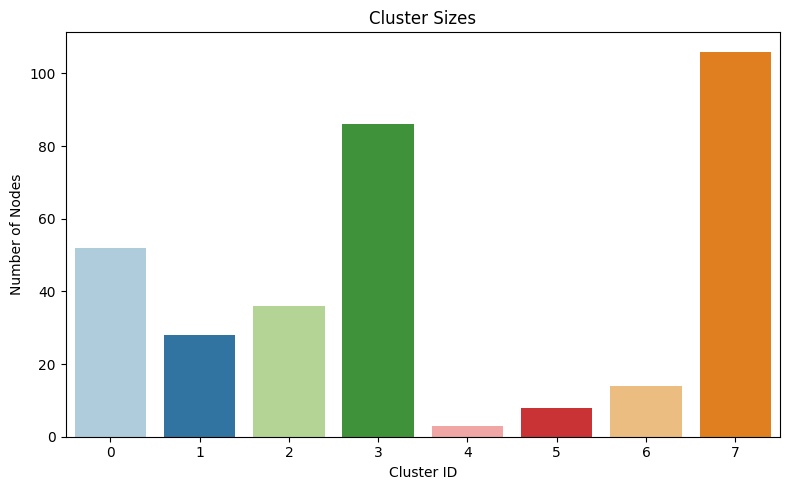


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.033050     1.344466e-02         0.007690         0.620663   
1               0.168644     3.984611e-03         0.012940         1.765362   
2               0.169738     9.065527e-03         0.003210         1.085560   
3               0.107077     4.994717e-03         0.011820         1.295000   
4               0.193624    -4.656613e-10         0.049472         2.235507   
5               0.034881     7.563617e-03         0.050427         1.320323   
6               0.026828     3.391318e-04         0.018453         1.318823   
7               0.076656     8.659040e-03         0.014081         0.964351   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0           1.495186e-02 

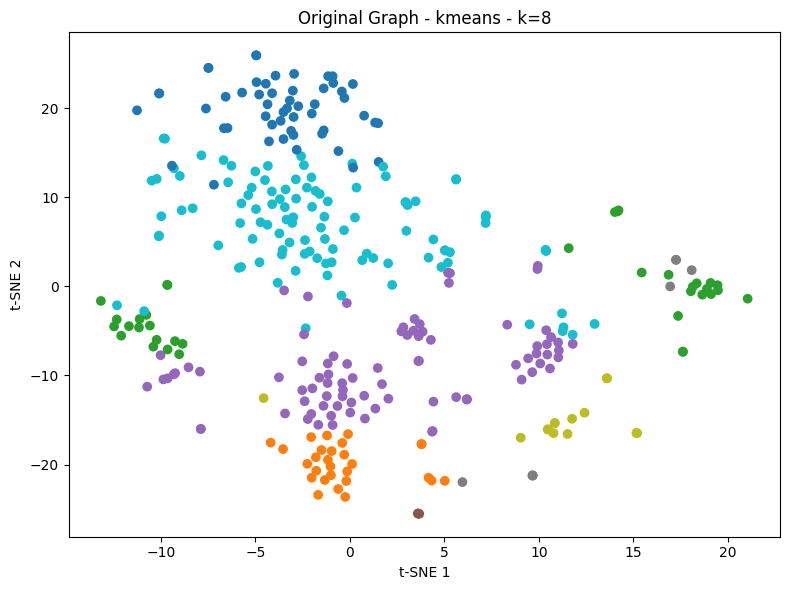

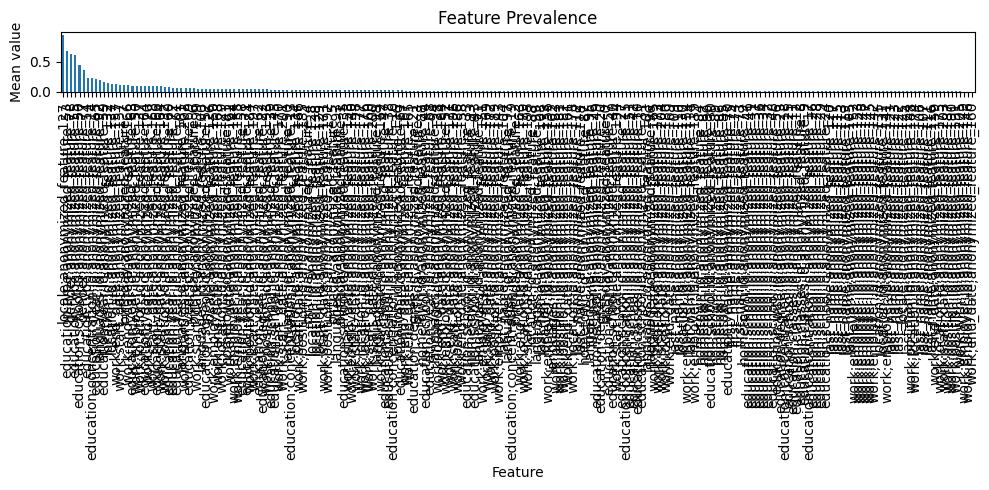


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.019231   
1                             0.000000                       0.107143   
2                             0.000000                       0.000000   
3                             0.023256                       0.011628   
4                             0.000000                       0.000000   
5                             0.125000                       0.000000   
6                             0.000000                       0.142857   
7                             0.009434                       0.009434   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.038462                       0.000000   
1               

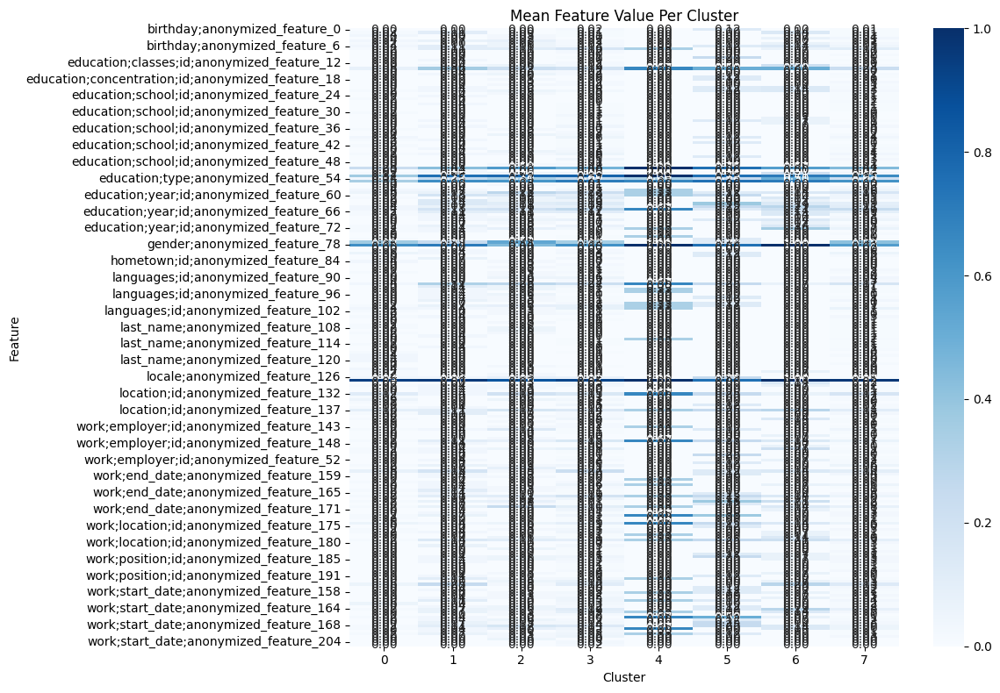

Features with > 30% prevalence/value in at least one cluster:
         birthday;anonymized_feature_7  \
cluster                                  
0                             0.019231   
1                             0.107143   
2                             0.111111   
3                             0.162791   
4                             0.333333   
5                             0.000000   
6                             0.071429   
7                             0.113208   

         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.076923   
1                                                0.357143   
2                                                0.222222   
3                                                0.186047   
4                                                0.666667   
5                                                0.500000   
6                            

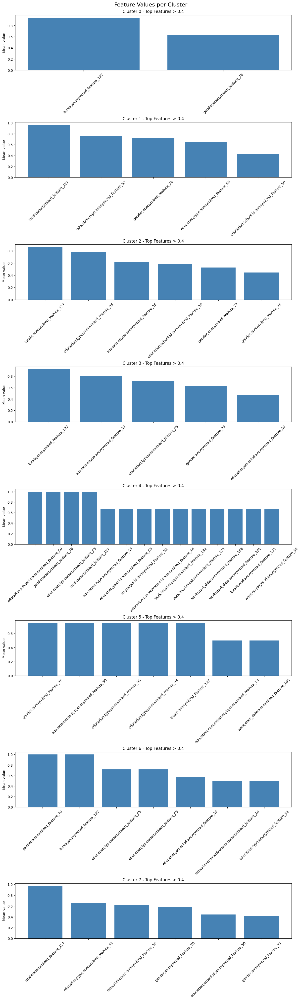


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0              education;type;anonymized_feature_53   
1         0              education;type;anonymized_feature_55   
2         0         education;school;id;anonymized_feature_50   
3         0              education;type;anonymized_feature_54   
4         0           education;year;id;anonymized_feature_65   
5         0                languages;id;anonymized_feature_92   
6         0  education;concentration;id;anonymized_feature_14   
7         0           education;year;id;anonymized_feature_59   
8         0           education;year;id;anonymized_feature_63   
9         0                     birthday;anonymized_feature_7   
10        0              work;end_date;anonymized_feature_166   
11        0            work;employer;id;anonymized_feature_50   
12        0           work;location;id;anonymized_feature_137   
13        0           education;year;id;anonymized_feature_60   

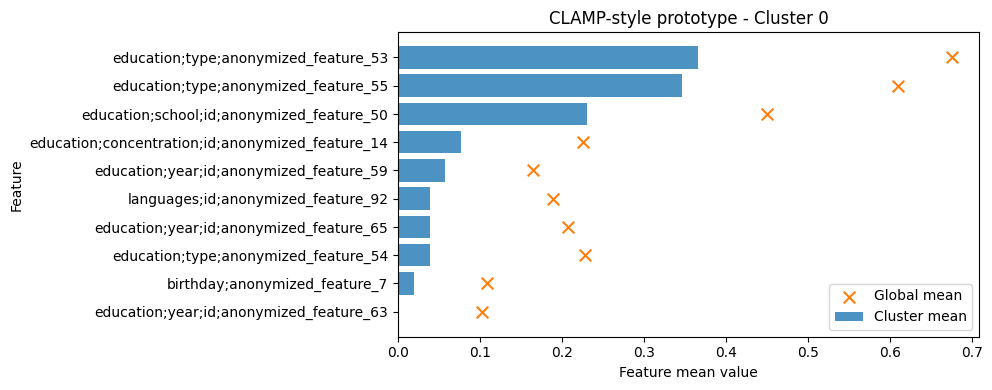

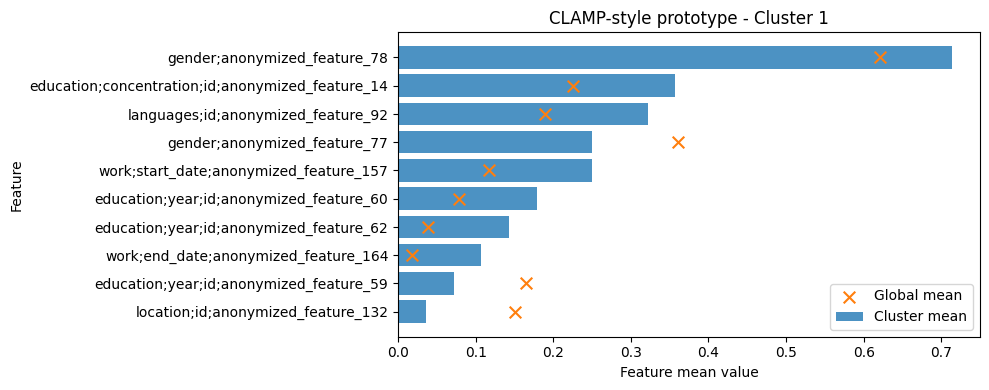

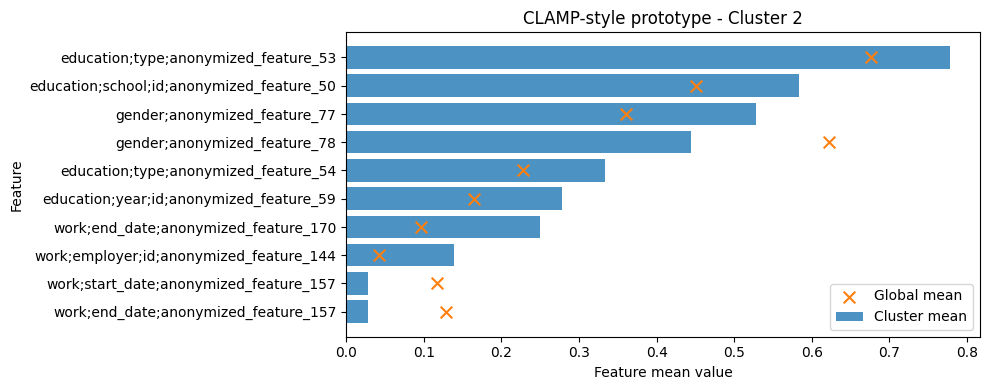

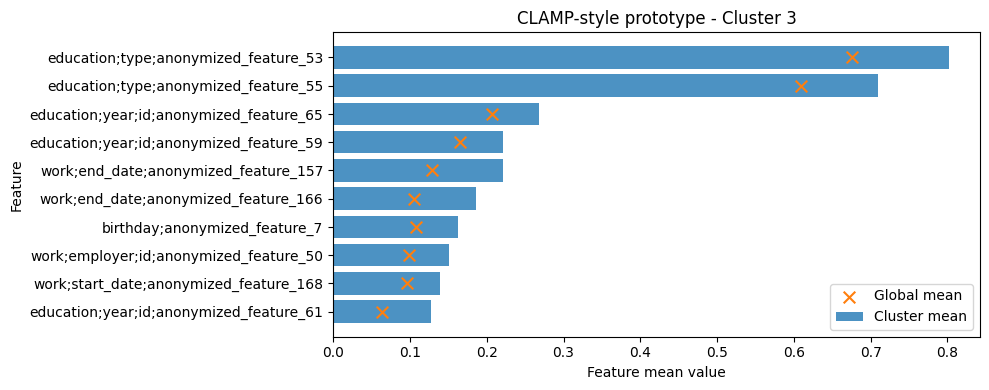

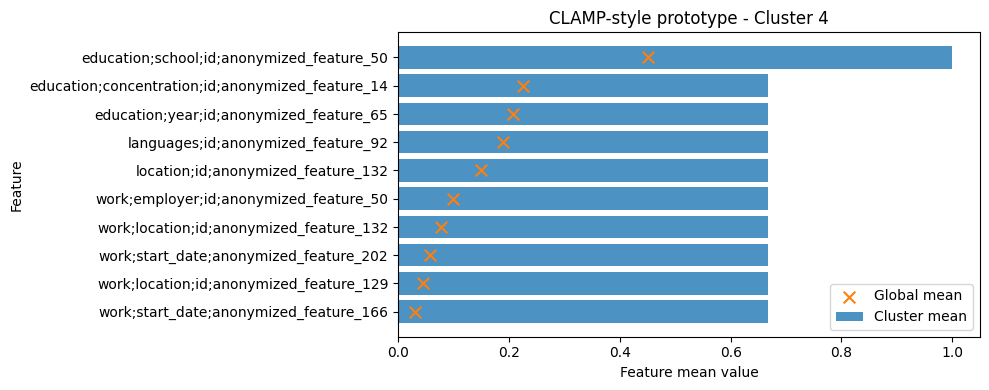

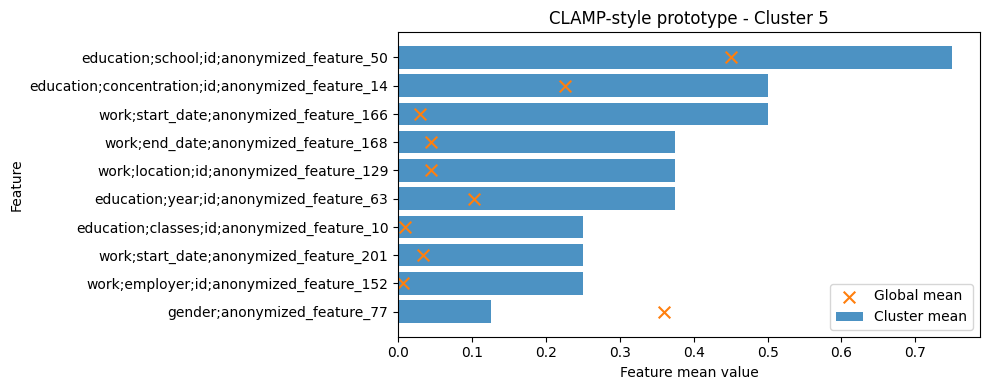

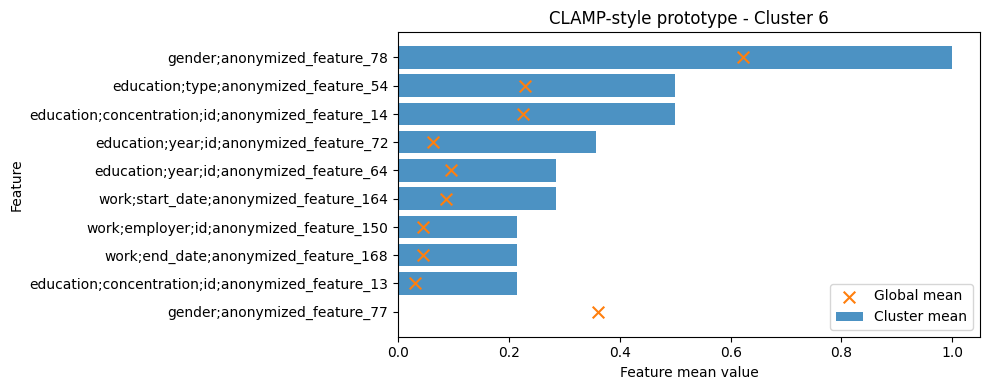

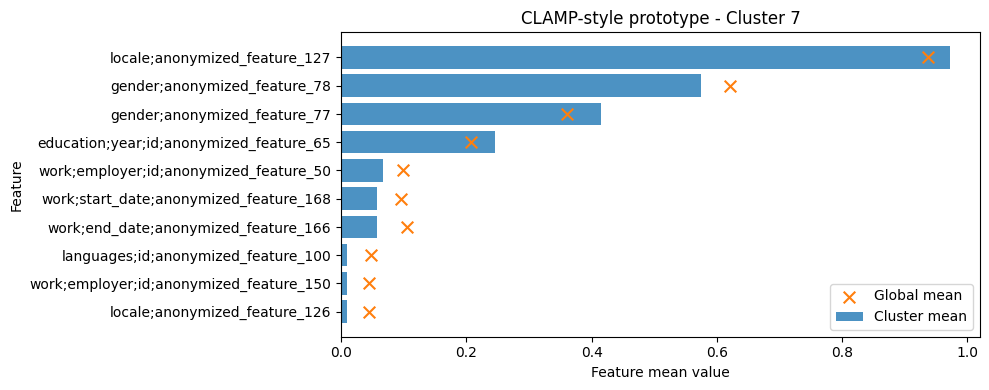

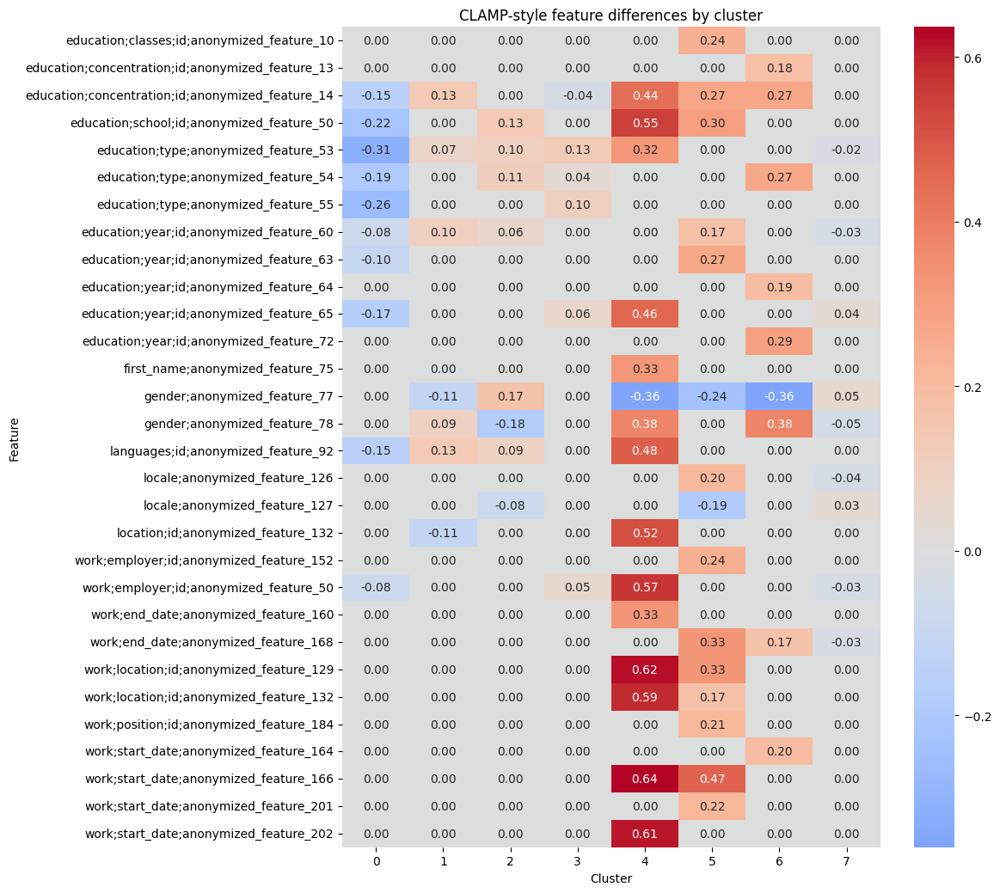


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.318318                         0.363364          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         7           4  

=== Decision tree rules ===
|--- work;start_date;anonymized_feature_166 <= 0.50
|   |--- education;year;id;anonymized_feature_72 <= 0.50
|   |   |--- education;year;id;anonymized_feature_64 <= 0.50
|   |   |   |--- education;type;anonymized_feature_53 <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- education;type;anonymized_feature_53 >  0.50
|   |   |   |   |--- class: 3
|   |   |--- education;year;id;anonymized_feature_64 >  0.50
|   |   |   |--- education;concentration;id;anonymized_feature_14 <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- education;concentration;id;anonymized_feature_14 >  0.50
|   |   |   |   |--- class: 5
|   |--- education;year;id;anonymized_feature_72 >  0.50
|   |   |--- edu

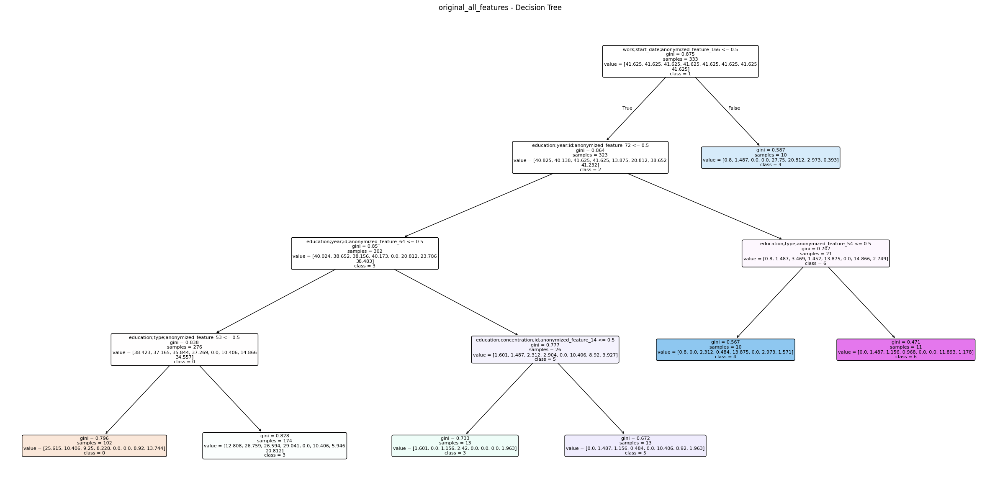


=== Decision tree feature importance ===
work;start_date;anonymized_feature_166              0.394283
education;year;id;anonymized_feature_72             0.199335
education;type;anonymized_feature_54                0.148867
education;year;id;anonymized_feature_64             0.102401
education;type;anonymized_feature_53                0.094241
education;concentration;id;anonymized_feature_14    0.060873
dtype: float64


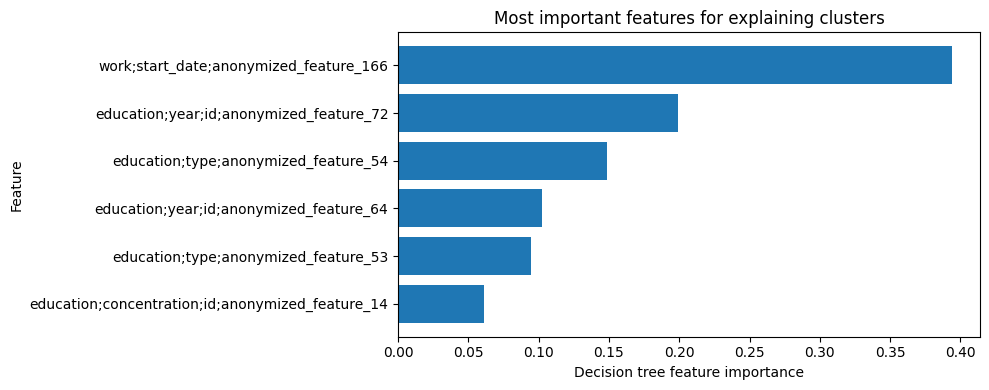


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.307692  0.038462  0.076923  0.076923  0.019231  0.038462  0.365385   
1        0.321429  0.000000  0.107143  0.035714  0.071429  0.035714  0.357143   
2        0.333333  0.055556  0.111111  0.083333  0.055556  0.027778  0.305556   
3        0.313953  0.069767  0.093023  0.046512  0.058140  0.011628  0.372093   
4        0.000000  0.000000  0.666667  0.000000  0.000000  0.000000  0.333333   
5        0.250000  0.000000  0.125000  0.000000  0.125000  0.125000  0.125000   
6        0.642857  0.142857  0.000000  0.000000  0.071429  0.000000  0.142857   
7        0.367925  0.084906  0.037736  0.028302  0.066038  0.037736  0.292453   

         circleOverlap  
cluster                 
0             0.076923  
1             0.071429  
2             0.027778  
3             0.034884  


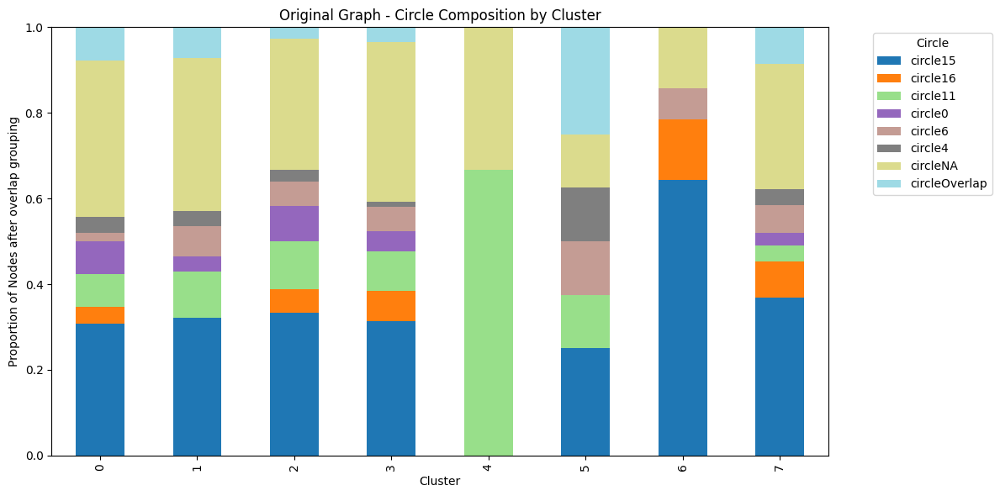

In [22]:
# ============================================================
# CELL 19 - MODEL 0A - Original graph with all features
# ============================================================

diagnostics_original_all, result_original_all = (
    run_final_dataset_analysis(
        dataset_name="original_all_features",
        n_clusters=K_ALL_FEATURES,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: original_circles_only
Embeddings shape: (333, 64)
Features shape: (333, 7)
Membership shape: (333, 8)

Running diagnostics for: original_circles_only

=== original_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.557516         343.716713        0.739718                 2   
3     0.383174         395.860262        0.843051                 3   
6     0.317330         366.266004        0.950147                 4   
9     0.261402         323.437853        1.135988                 5   
12    0.271378         294.141945        1.083314                 6   
15    0.252239         276.066602        1.118443                 7   
18    0.229022         251.444085        1.200290                 8   

    valid_internal_metrics  method  k fit_status                dataset  
0                     True  kmeans  2         ok  original_circles_only  
3                     True  kmeans  3         ok  original_circle

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


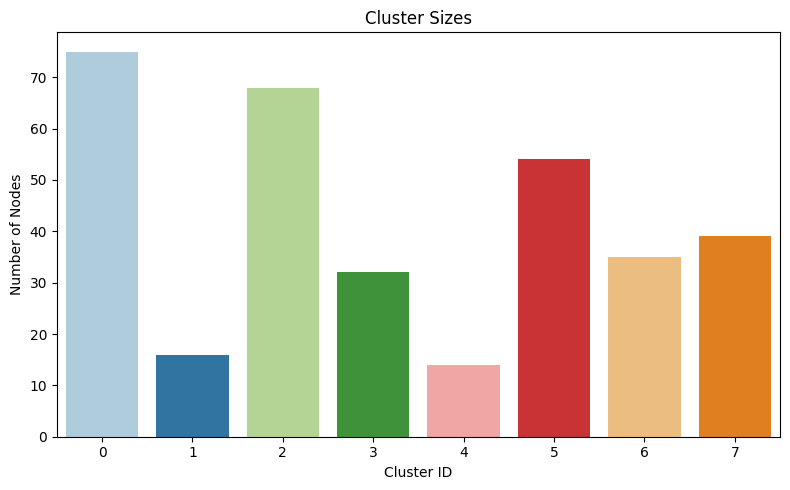


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0                    0.0         0.644426         0.396755         0.621288   
1                    0.0         1.711800         1.509570         1.636483   
2                    0.0         1.111583         0.906739         1.118429   
3                    0.0         0.206409         0.016012         0.416112   
4                    0.0         2.487703         2.301680         3.062692   
5                    0.0         0.472174         0.253982         0.266950   
6                    0.0         0.190462         0.070161         0.099080   
7                    0.0         0.634543         0.590789         0.648927   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               2.089755 

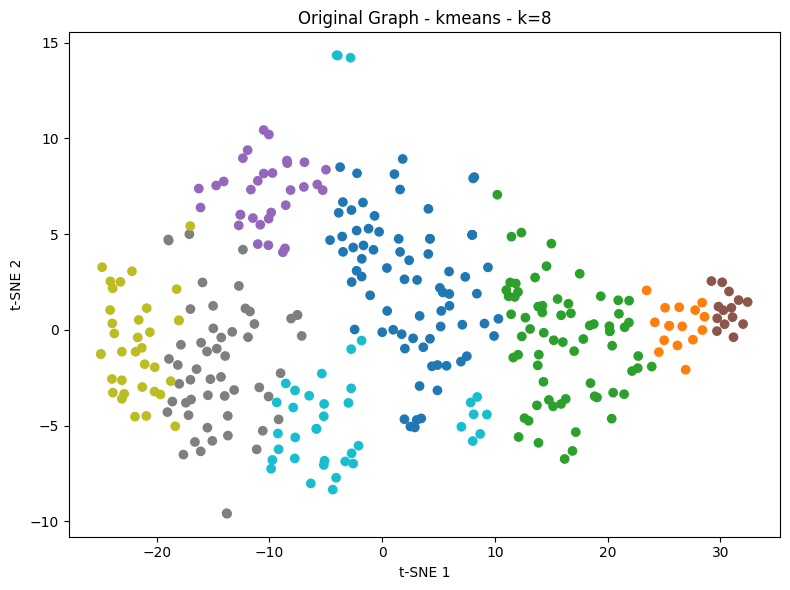

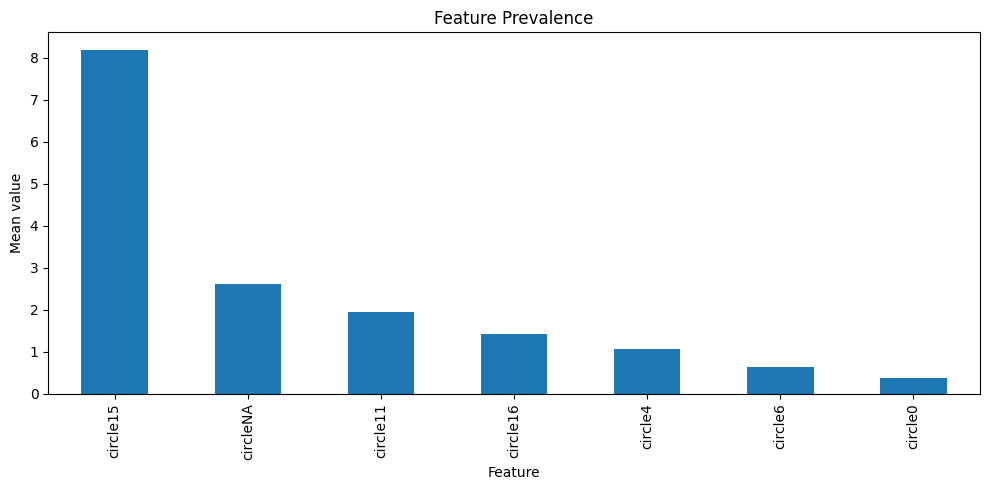


=== Cluster feature profiles ===
          circle15  circle16  circle11   circle0   circle6   circle4  circleNA
cluster                                                                       
0         7.746667  1.693333  1.800000  0.333333  0.626667  0.933333  2.253333
1        12.750000  0.937500  3.062500  0.562500  0.937500  1.687500  3.125000
2         9.058824  0.985294  2.367647  0.338235  0.602941  1.455882  2.470588
3         5.156250  3.718750  1.156250  0.406250  1.062500  0.281250  3.968750
4        25.571429  1.428571  5.357143  0.714286  0.857143  3.285714  3.285714
5         6.148148  1.111111  1.166667  0.222222  0.833333  0.462963  3.240741
6         1.800000  1.200000  0.542857  0.314286  0.400000  0.257143  1.942857
7        10.487179  0.615385  2.769231  0.564103  0.205128  1.794872  1.666667


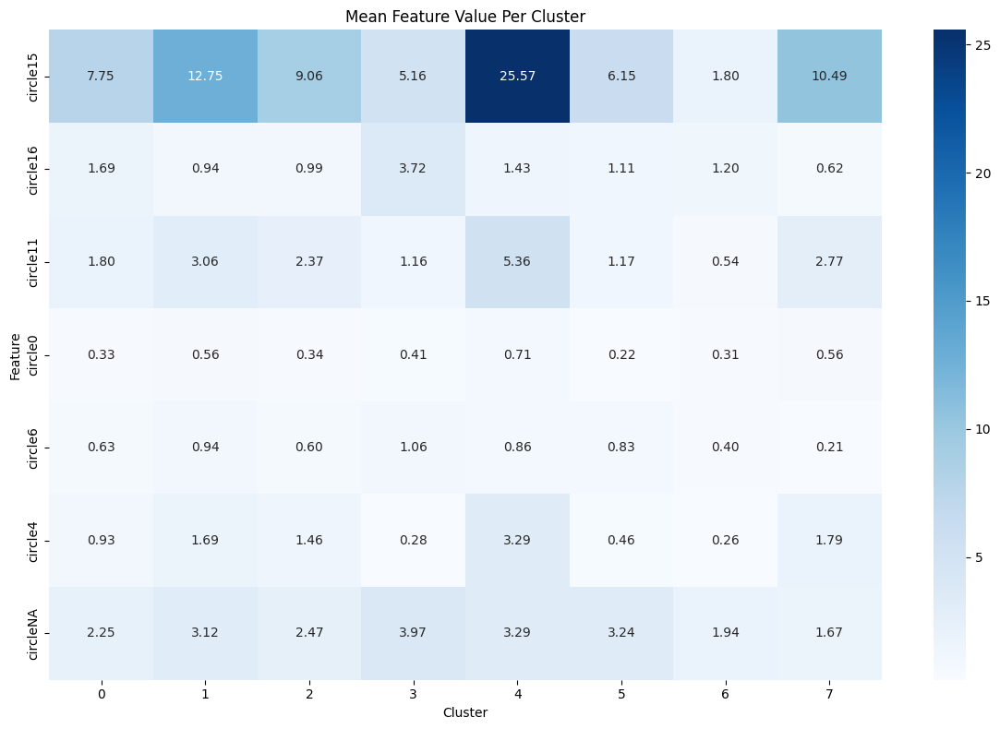

Features with > 30% prevalence/value in at least one cluster:
          circle15  circle16  circle11   circle0   circle6   circle4  circleNA
cluster                                                                       
0         7.746667  1.693333  1.800000  0.333333  0.626667  0.933333  2.253333
1        12.750000  0.937500  3.062500  0.562500  0.937500  1.687500  3.125000
2         9.058824  0.985294  2.367647  0.338235  0.602941  1.455882  2.470588
3         5.156250  3.718750  1.156250  0.406250  1.062500  0.281250  3.968750
4        25.571429  1.428571  5.357143  0.714286  0.857143  3.285714  3.285714
5         6.148148  1.111111  1.166667  0.222222  0.833333  0.462963  3.240741
6         1.800000  1.200000  0.542857  0.314286  0.400000  0.257143  1.942857
7        10.487179  0.615385  2.769231  0.564103  0.205128  1.794872  1.666667

=== Top mutual information features ===
circle15    0.446637
circle16    0.209994
circle11    0.199520
circle4     0.181422
circleNA    0.172381
ci

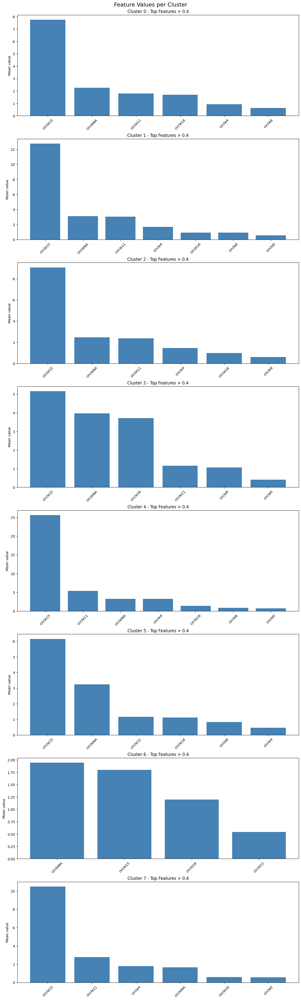


=== CLAMP prototypes ===
    cluster   feature  cluster_prevalence  global_prevalence  prevalence_diff  \
0         0  circle15            7.746667           8.192192        -0.445526   
1         0  circleNA            2.253333           2.606607        -0.353273   
2         0  circle16            1.693333           1.423423         0.269910   
3         0  circle11            1.800000           1.942943        -0.142943   
4         0   circle4            0.933333           1.066066        -0.132733   
5         0   circle0            0.333333           0.375375        -0.042042   
6         0   circle6            0.626667           0.648649        -0.021982   
7         1  circle15           12.750000           8.192192         4.557808   
8         1  circle11            3.062500           1.942943         1.119557   
9         1   circle4            1.687500           1.066066         0.621434   
10        1  circleNA            3.125000           2.606607         0.518393   
11

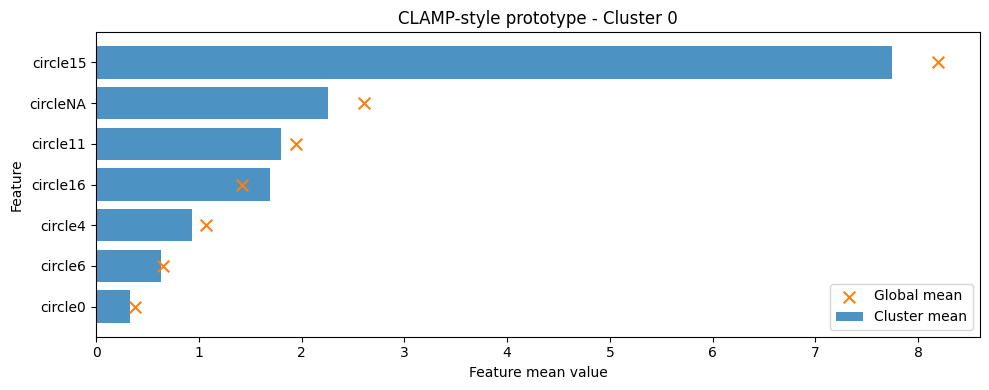

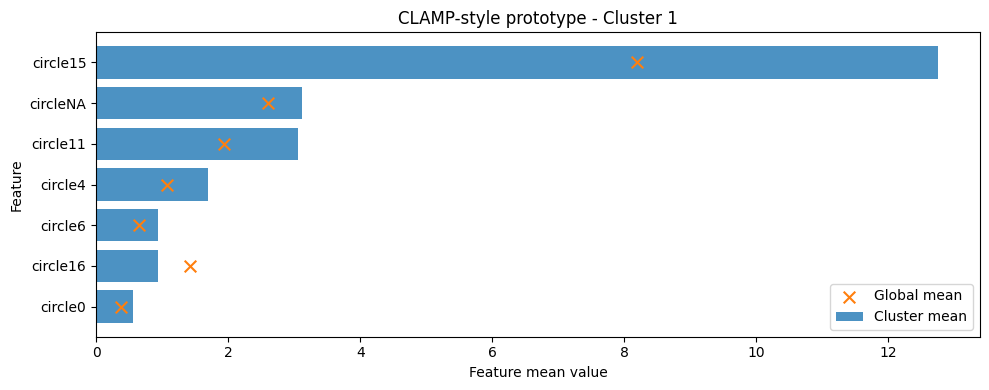

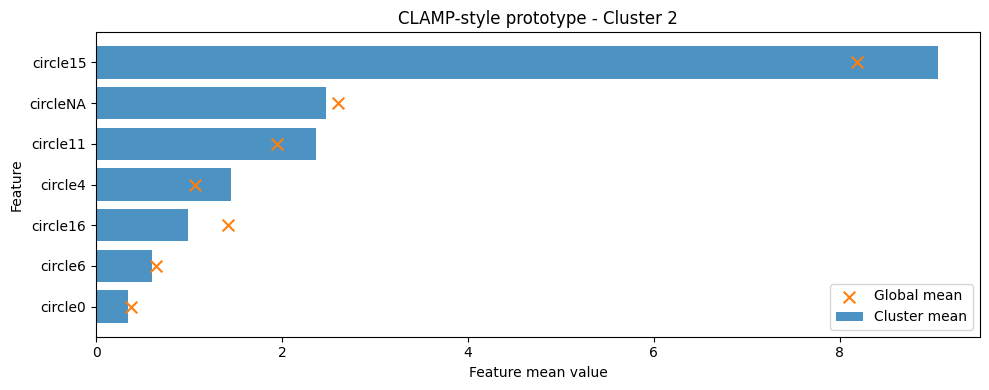

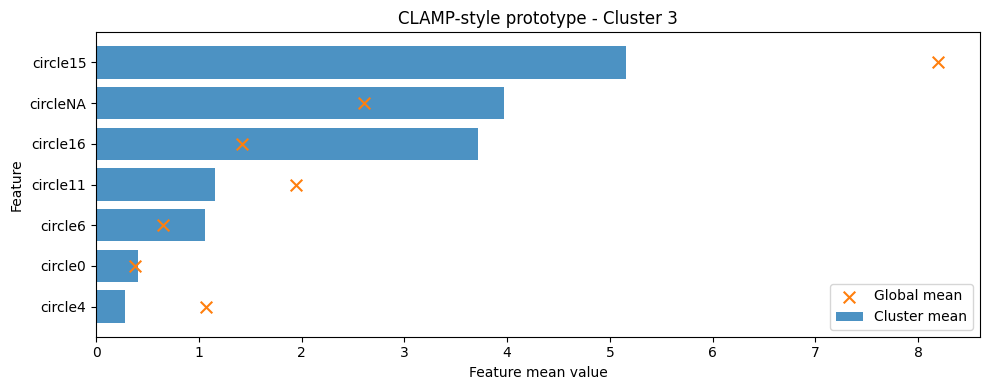

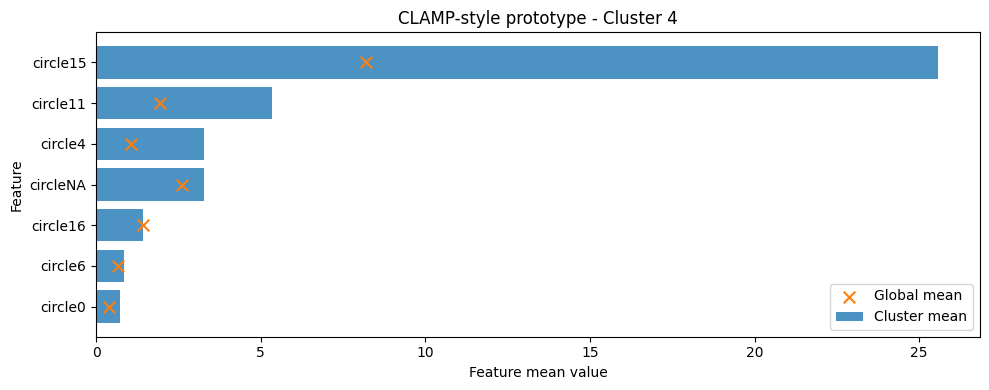

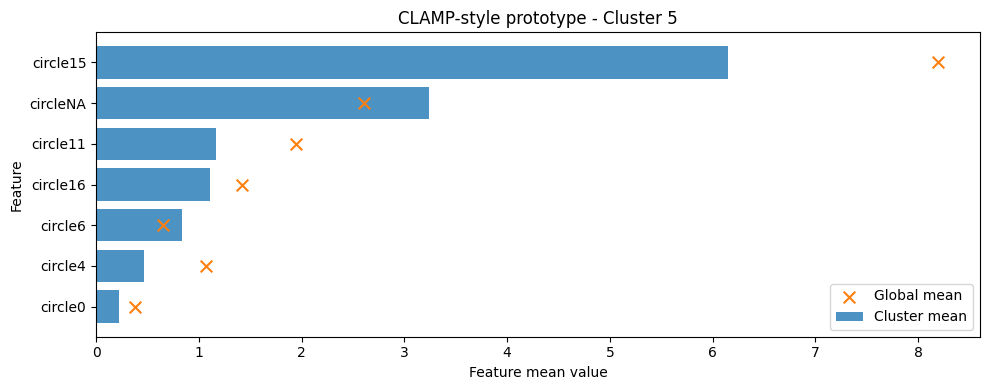

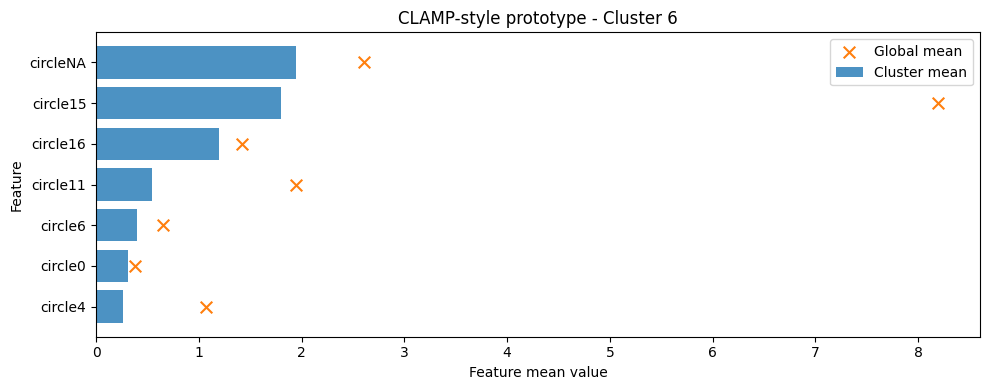

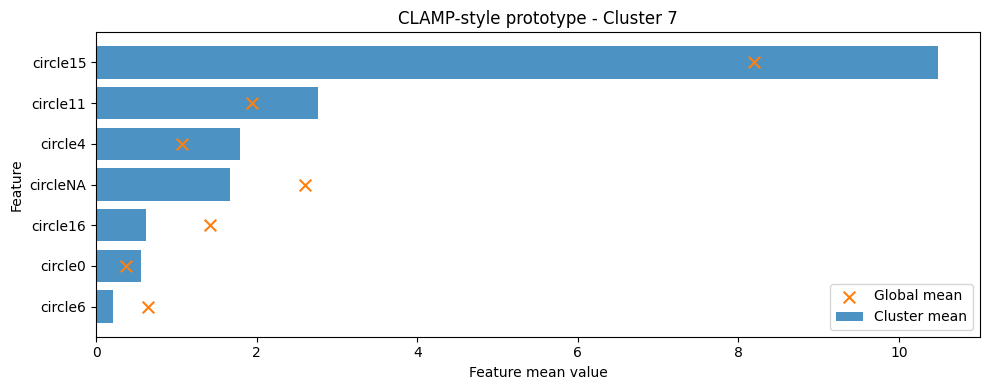

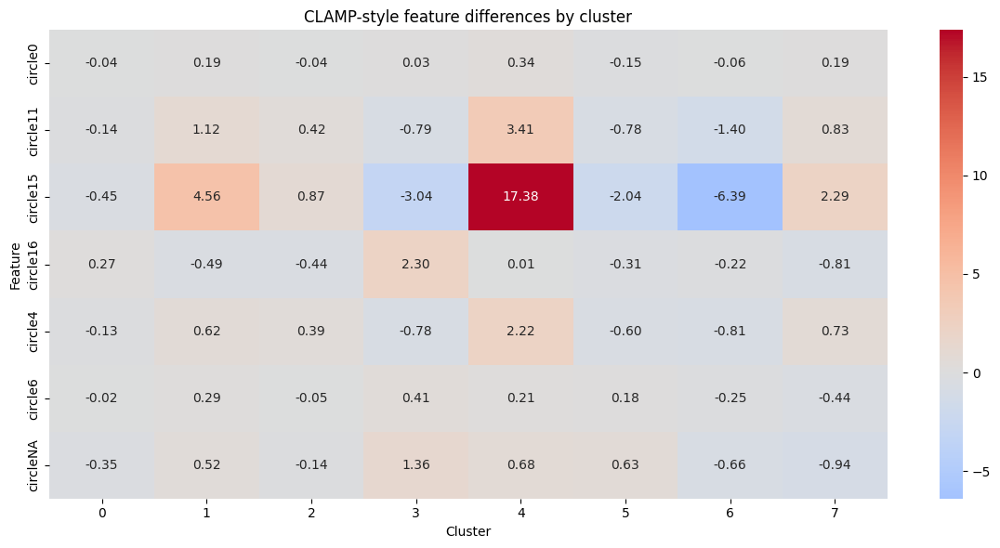


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.255255                         0.337298          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        10           4  

=== Decision tree rules ===
|--- circle15 <= 21.50
|   |--- circle16 <= 4.50
|   |   |--- circle4 <= 0.50
|   |   |   |--- circle15 <= 4.50
|   |   |   |   |--- class: 6
|   |   |   |--- circle15 >  4.50
|   |   |   |   |--- class: 5
|   |   |--- circle4 >  0.50
|   |   |   |--- circle15 <= 13.50
|   |   |   |   |--- class: 7
|   |   |   |--- circle15 >  13.50
|   |   |   |   |--- class: 2
|   |--- circle16 >  4.50
|   |   |--- circle15 <= 2.50
|   |   |   |--- class: 6
|   |   |--- circle15 >  2.50
|   |   |   |--- circle16 <= 7.50
|   |   |   |   |--- class: 3
|   |   |   |--- circle16 >  7.50
|   |   |   |   |--- class: 3
|--- circle15 >  21.50
|   |--- circle4 <= 4.50
|   |   |--- class: 4
|   |--- circle4 >  4

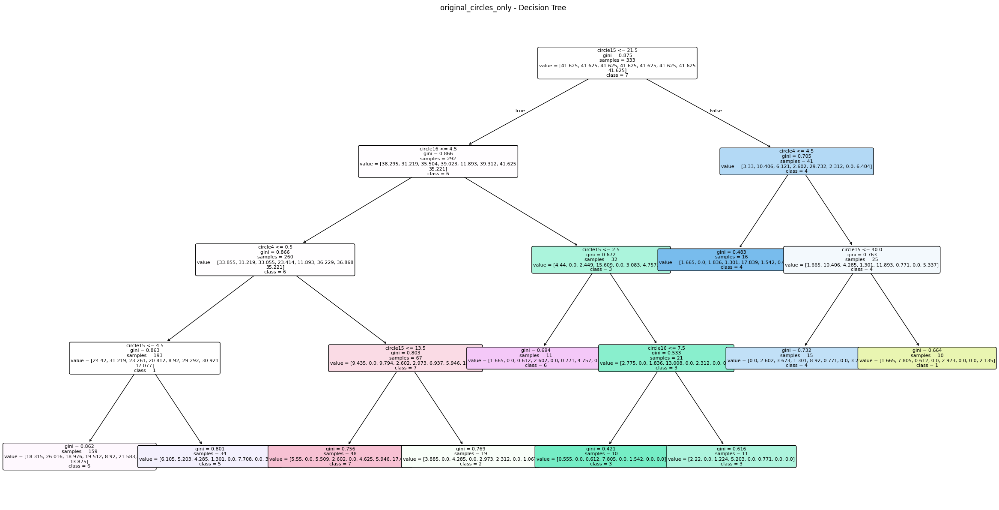


=== Decision tree feature importance ===
circle15    0.608232
circle4     0.214389
circle16    0.177380
dtype: float64


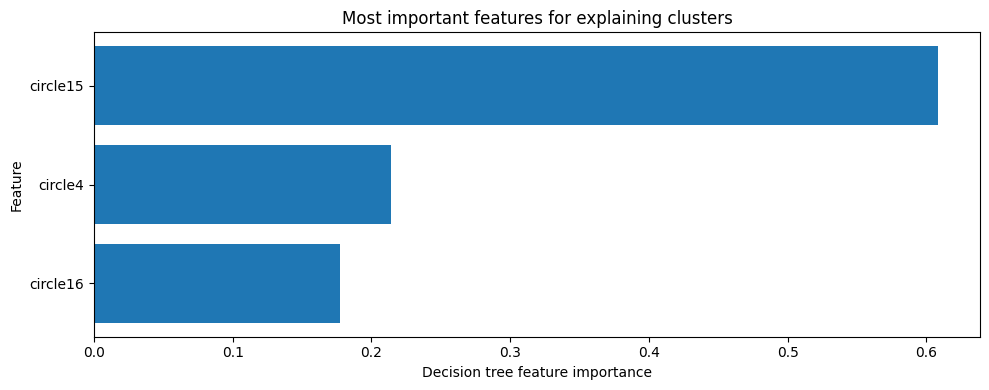


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.333333  0.053333  0.106667  0.053333  0.066667  0.013333  0.320000   
1        0.437500  0.000000  0.000000  0.000000  0.187500  0.000000  0.312500   
2        0.382353  0.058824  0.088235  0.044118  0.058824  0.073529  0.279412   
3        0.187500  0.156250  0.093750  0.000000  0.062500  0.000000  0.343750   
4        0.571429  0.071429  0.071429  0.000000  0.071429  0.000000  0.071429   
5        0.203704  0.055556  0.074074  0.055556  0.055556  0.037037  0.425926   
6        0.314286  0.114286  0.000000  0.114286  0.028571  0.028571  0.371429   
7        0.512821  0.000000  0.102564  0.025641  0.000000  0.025641  0.282051   

         circleOverlap  
cluster                 
0             0.053333  
1             0.062500  
2             0.014706  
3             0.156250  


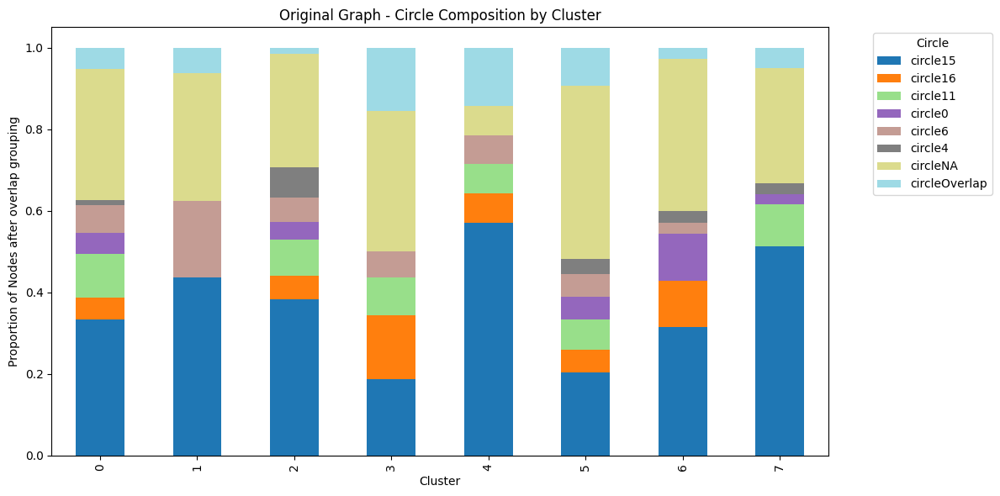

In [23]:
# ============================================================
# CELL 20 - MODEL 0B - Original graph with circles-only ARD
# ============================================================

diagnostics_original_circles, result_original_circles = (
    run_final_dataset_analysis(
        dataset_name="original_circles_only",
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: original_graph_structure_identity_only
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: original_graph_structure_identity_only

=== original_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.257154         111.969251        1.616896                 2   
3     0.266877          83.429385        2.059422                 3   
6     0.276989          69.933900        1.861879                 4   
9     0.189998          61.935434        2.022723                 5   
12    0.166534          56.761814        1.959518                 6   
15    0.187584          53.611927        1.878937                 7   
18    0.185163          50.211763        1.828932                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3         ok   
6   

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


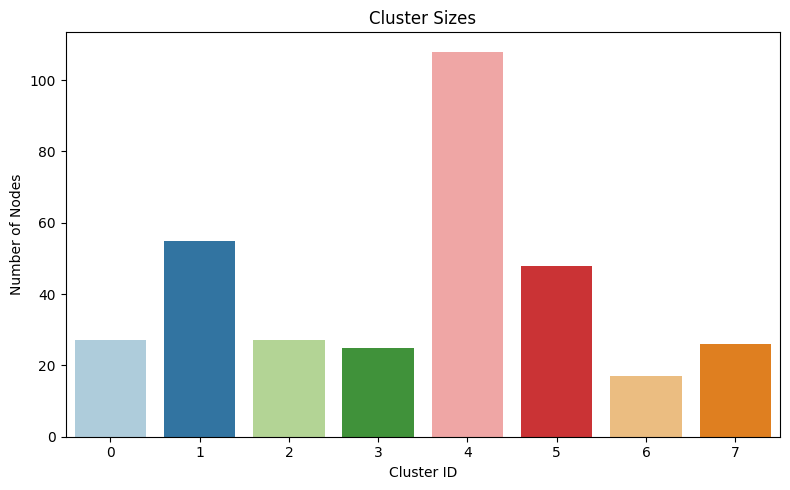


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.000338         0.068437         0.007095     5.898783e-02   
1               0.015709         0.103592         0.008083     1.117587e-08   
2               0.119886         0.005678         0.012330     7.887515e-02   
3               0.002878         0.015326         0.009794     1.315167e-01   
4               0.024964         0.059029         0.005362     7.174715e-03   
5               0.064034         0.001319         0.009129     1.433493e-01   
6               0.004047         0.059530         0.003471    -3.725290e-09   
7               0.043205         0.035887         0.006211     1.777729e-02   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.009388 

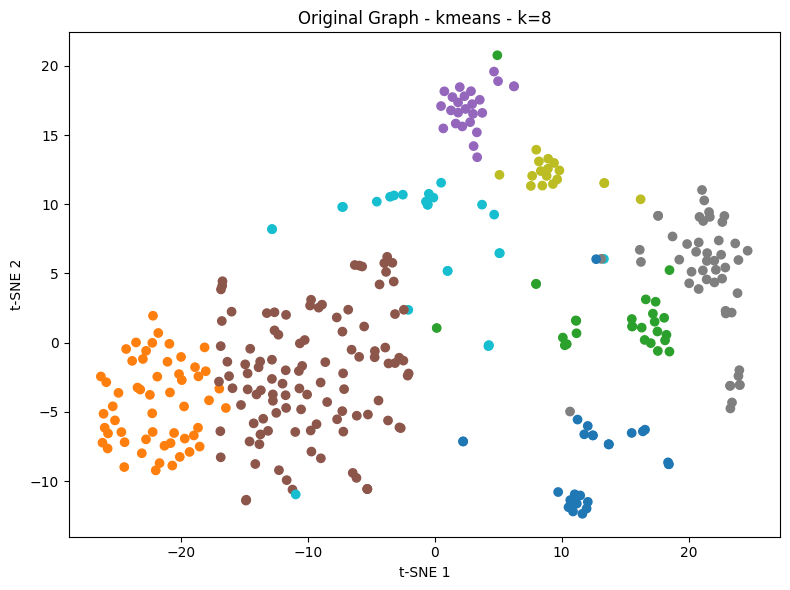

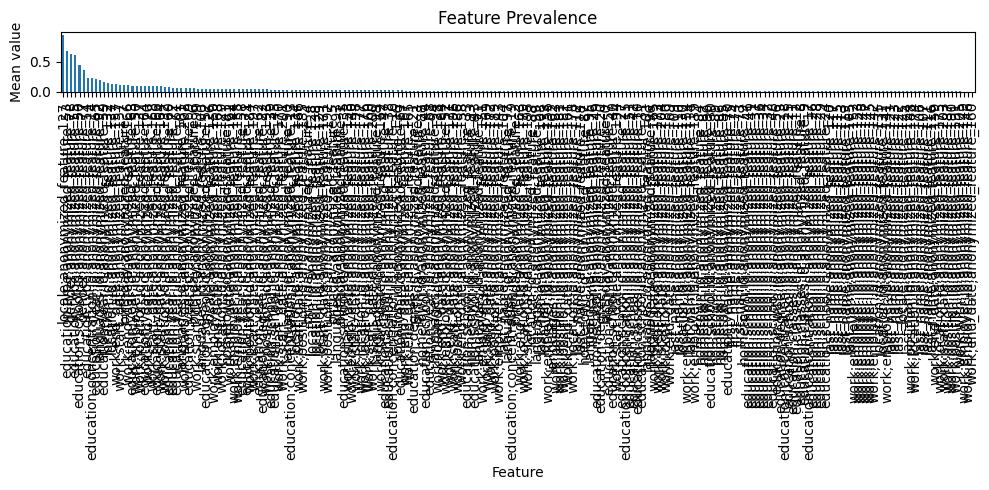


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.037037                       0.000000   
1                             0.036364                       0.054545   
2                             0.000000                       0.037037   
3                             0.040000                       0.080000   
4                             0.000000                       0.000000   
5                             0.000000                       0.020833   
6                             0.000000                       0.000000   
7                             0.000000                       0.038462   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.000000                       0.037037   
1               

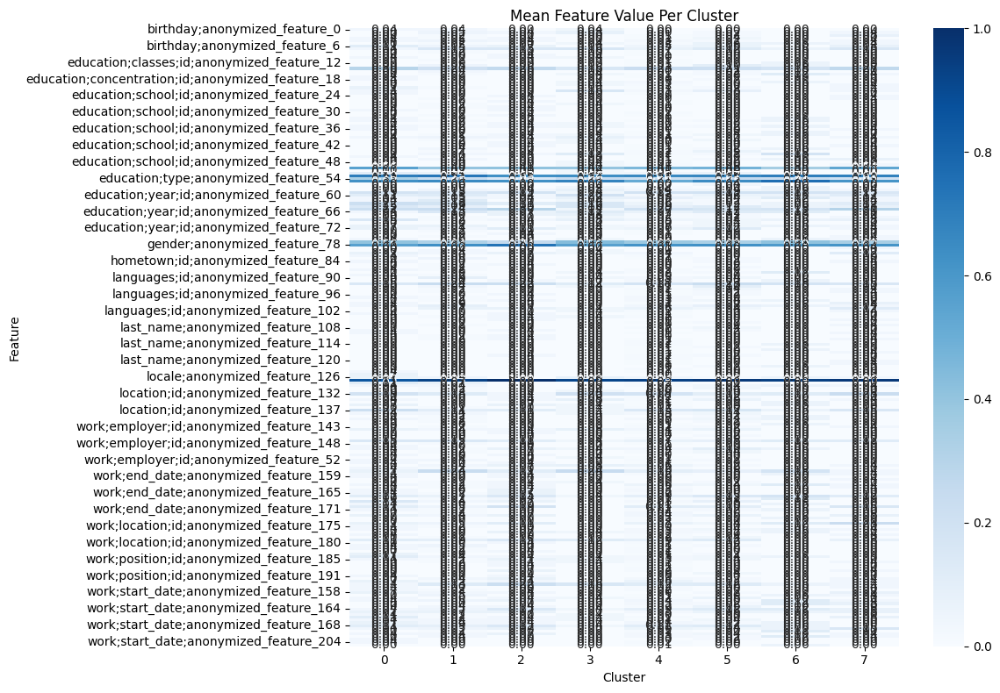

Features with > 30% prevalence/value in at least one cluster:
         education;school;id;anonymized_feature_50  \
cluster                                              
0                                         0.555556   
1                                         0.400000   
2                                         0.407407   
3                                         0.400000   
4                                         0.453704   
5                                         0.479167   
6                                         0.352941   
7                                         0.538462   

         education;type;anonymized_feature_53  \
cluster                                         
0                                    0.703704   
1                                    0.727273   
2                                    0.629630   
3                                    0.640000   
4                                    0.657407   
5                                    0.666667   
6    

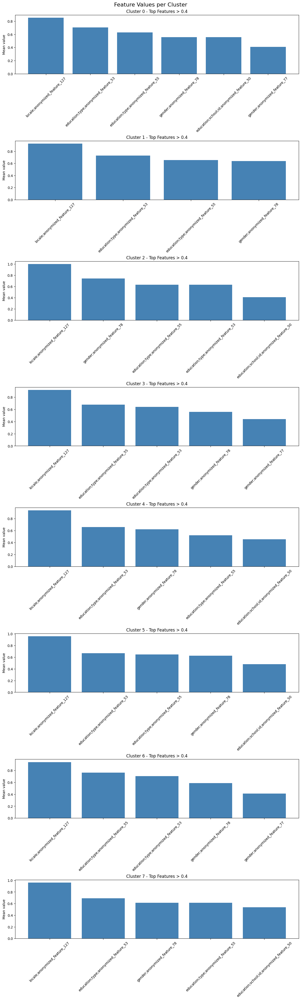


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0           education;year;id;anonymized_feature_63   
1         0         education;school;id;anonymized_feature_50   
2         0              education;type;anonymized_feature_54   
3         0              work;end_date;anonymized_feature_168   
4         0           education;year;id;anonymized_feature_69   
5         0                location;id;anonymized_feature_137   
6         0                     locale;anonymized_feature_127   
7         0                location;id;anonymized_feature_128   
8         0            work;start_date;anonymized_feature_166   
9         0            work;start_date;anonymized_feature_157   
10        0           work;position;id;anonymized_feature_184   
11        0                     birthday;anonymized_feature_7   
12        0  education;concentration;id;anonymized_feature_14   
13        0                     locale;anonymized_feature_125   

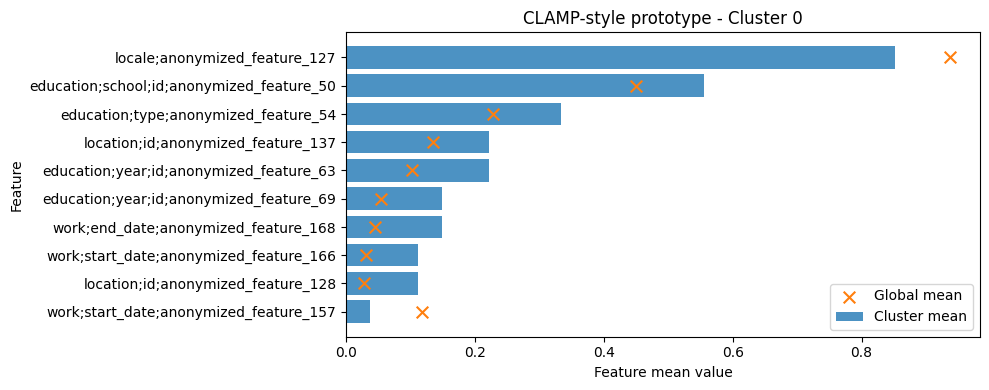

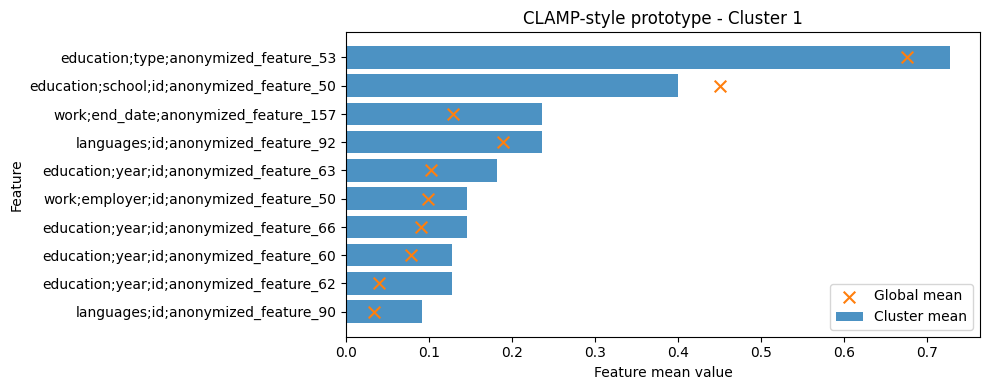

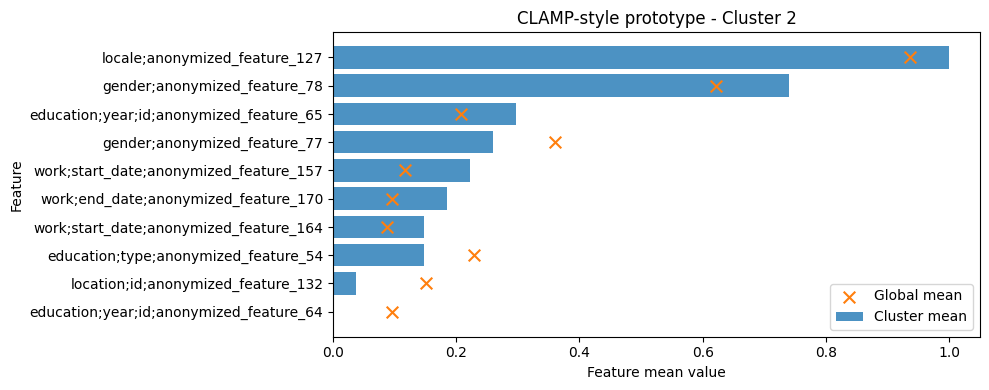

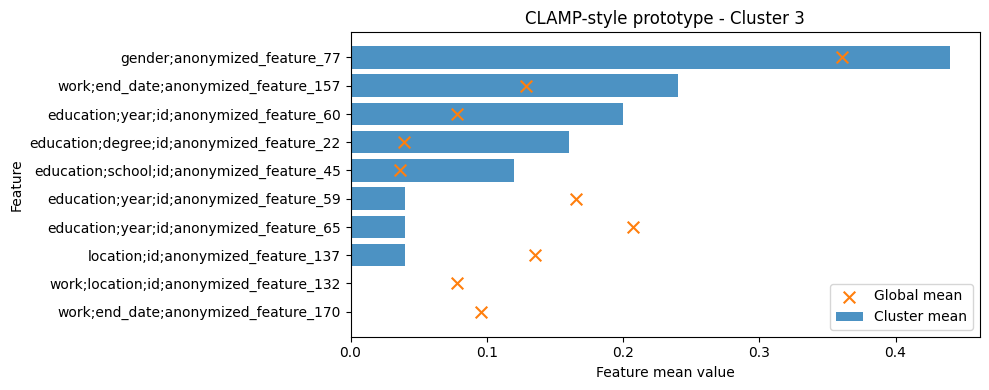

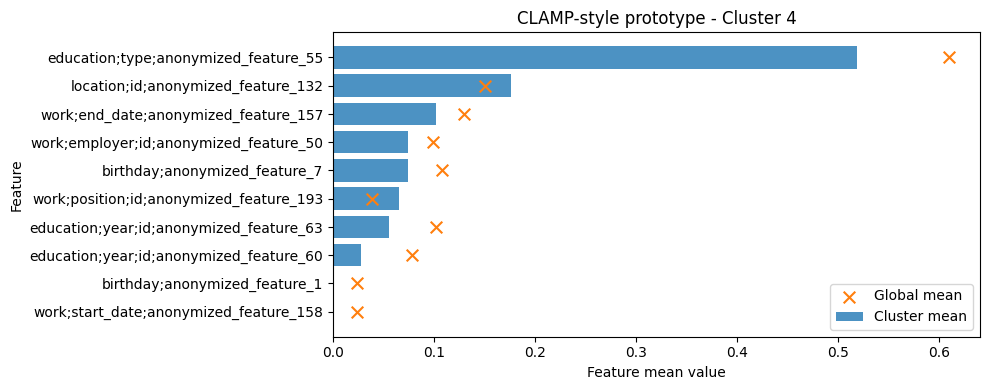

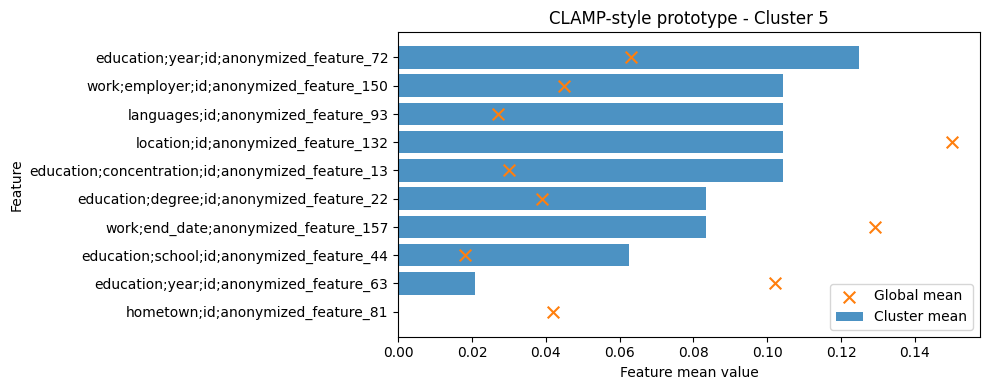

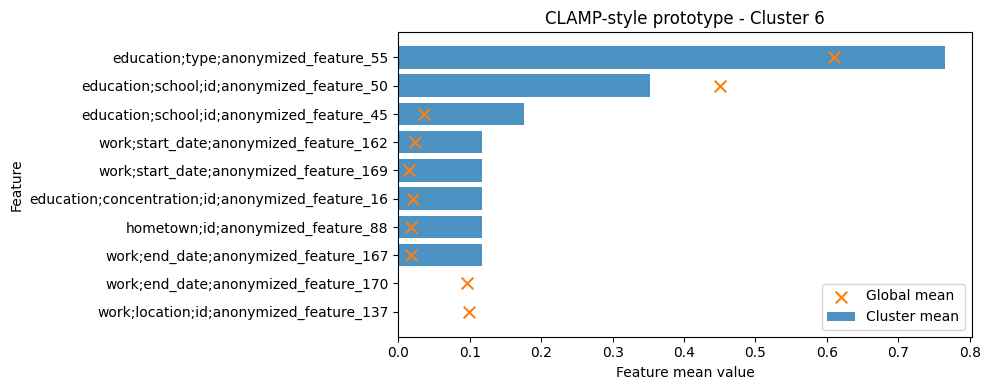

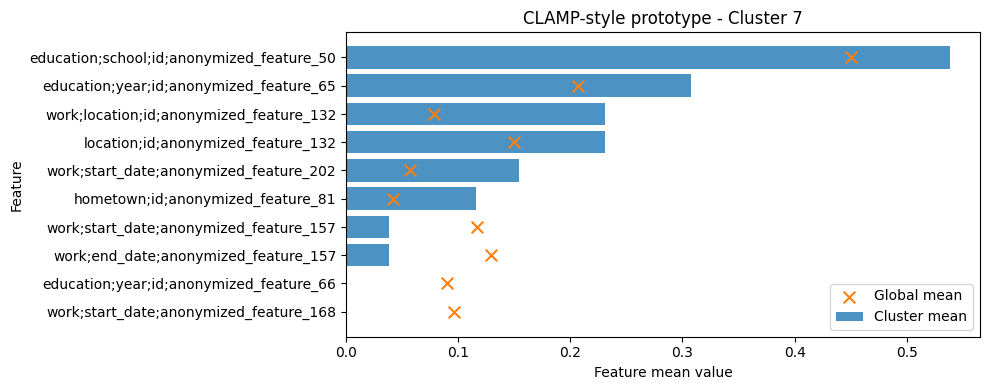

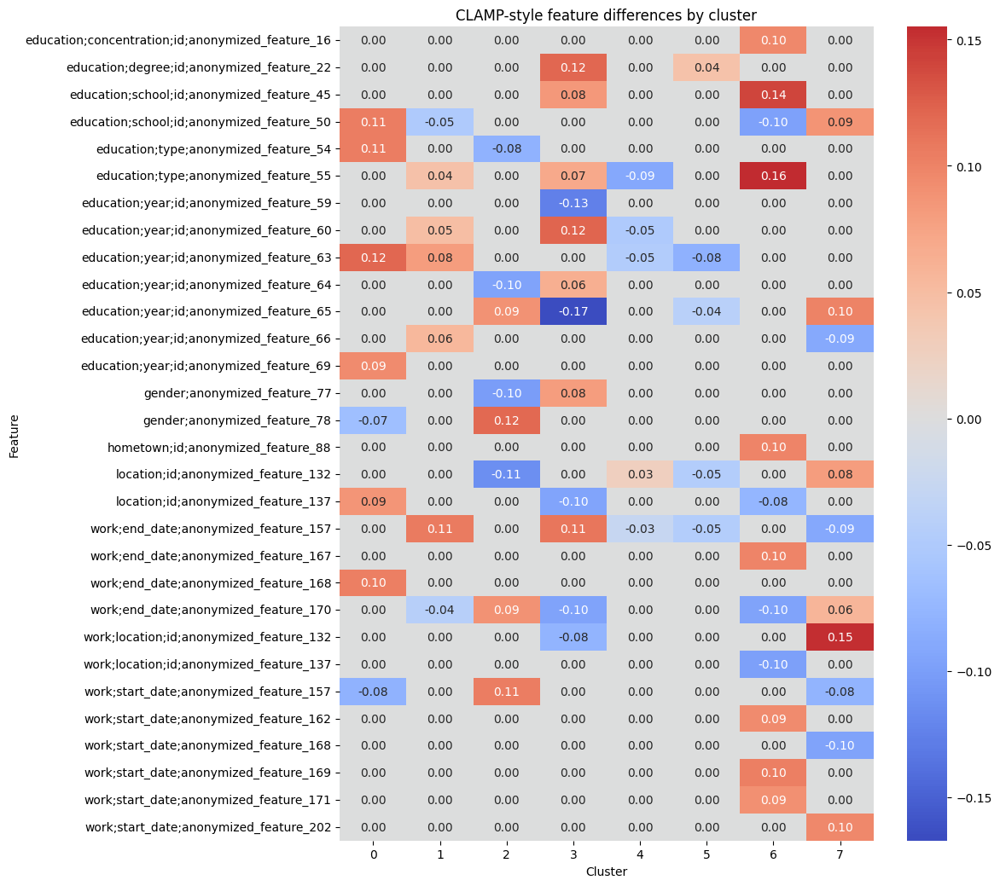


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.198198                         0.200787          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         5           4  

=== Decision tree rules ===
|--- education;school;id;anonymized_feature_45 <= 0.50
|   |--- education;degree;id;anonymized_feature_22 <= 0.50
|   |   |--- work;end_date;anonymized_feature_168 <= 0.50
|   |   |   |--- work;location;id;anonymized_feature_132 <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- work;location;id;anonymized_feature_132 >  0.50
|   |   |   |   |--- class: 7
|   |   |--- work;end_date;anonymized_feature_168 >  0.50
|   |   |   |--- class: 0
|   |--- education;degree;id;anonymized_feature_22 >  0.50
|   |   |--- class: 3
|--- education;school;id;anonymized_feature_45 >  0.50
|   |--- class: 6



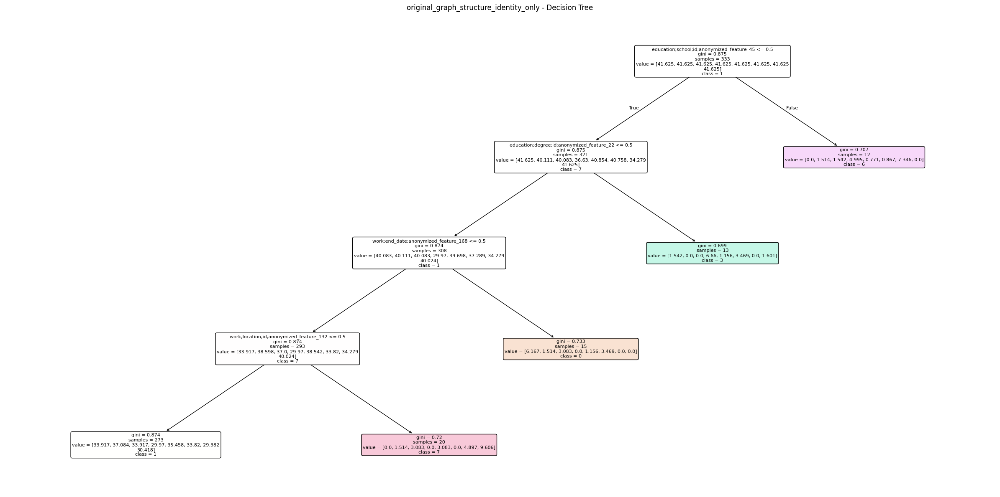


=== Decision tree feature importance ===
work;location;id;anonymized_feature_132      0.299572
education;school;id;anonymized_feature_45    0.268483
education;degree;id;anonymized_feature_22    0.241849
work;end_date;anonymized_feature_168         0.190096
dtype: float64


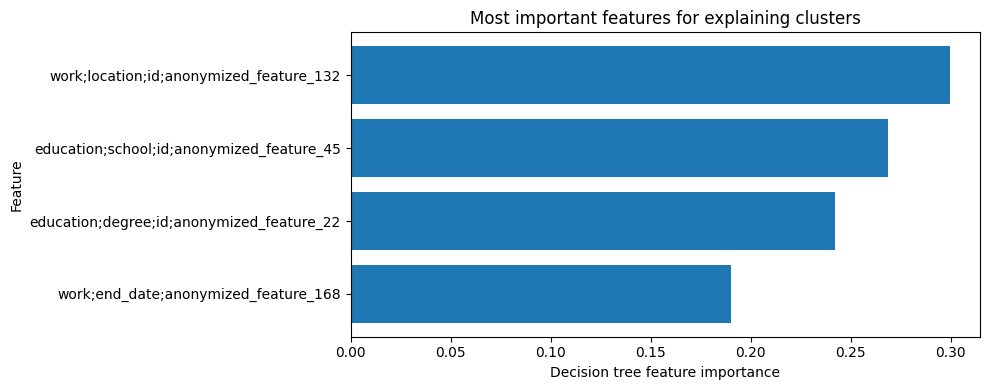


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.333333  0.074074  0.074074  0.037037  0.111111  0.074074  0.259259   
1        0.290909  0.000000  0.072727  0.000000  0.036364  0.036364  0.472727   
2        0.481481  0.000000  0.037037  0.000000  0.111111  0.000000  0.222222   
3        0.160000  0.160000  0.040000  0.080000  0.200000  0.040000  0.280000   
4        0.388889  0.092593  0.055556  0.074074  0.027778  0.037037  0.250000   
5        0.375000  0.062500  0.104167  0.062500  0.020833  0.000000  0.375000   
6        0.294118  0.117647  0.117647  0.058824  0.058824  0.000000  0.352941   
7        0.269231  0.000000  0.192308  0.000000  0.038462  0.038462  0.384615   

         circleOverlap  
cluster                 
0             0.037037  
1             0.090909  
2             0.148148  
3             0.040000  


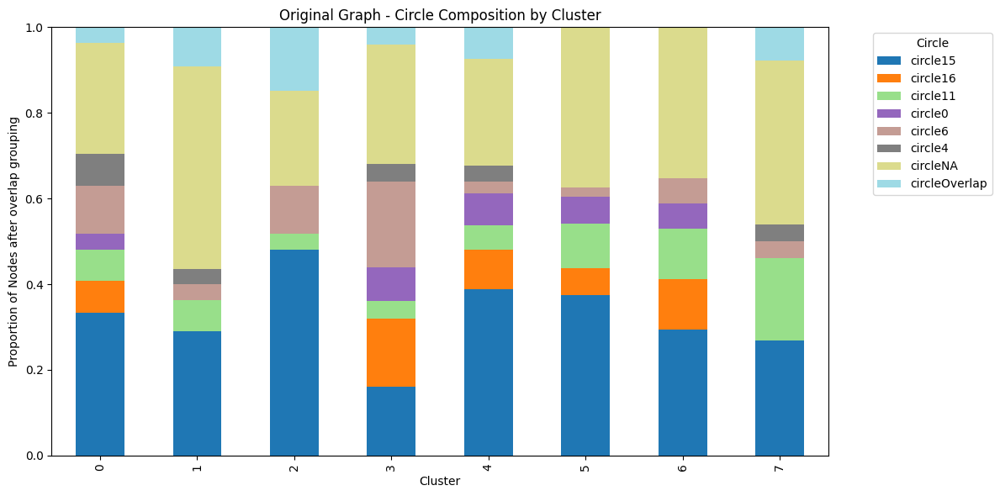

In [24]:
# ============================================================
# CELL 21 - MODEL 0C - Original graph with structure only
# ============================================================

diagnostics_original_structure, result_original_structure = (
    run_final_dataset_analysis(
        dataset_name="original_graph_structure_identity_only",
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: original_TRAINING_all_features
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: original_TRAINING_all_features

=== original_TRAINING_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.277317         143.946736        1.388546                 2   
3     0.214201         108.488166        1.550135                 3   
6     0.199737          93.076691        1.409446                 4   
9     0.185800          84.384757        1.347822                 5   
12    0.171314          80.248680        1.467079                 6   
15    0.182274          74.446640        1.432551                 7   
18    0.187449          69.890113        1.439000                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3         ok   
6                     True  

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


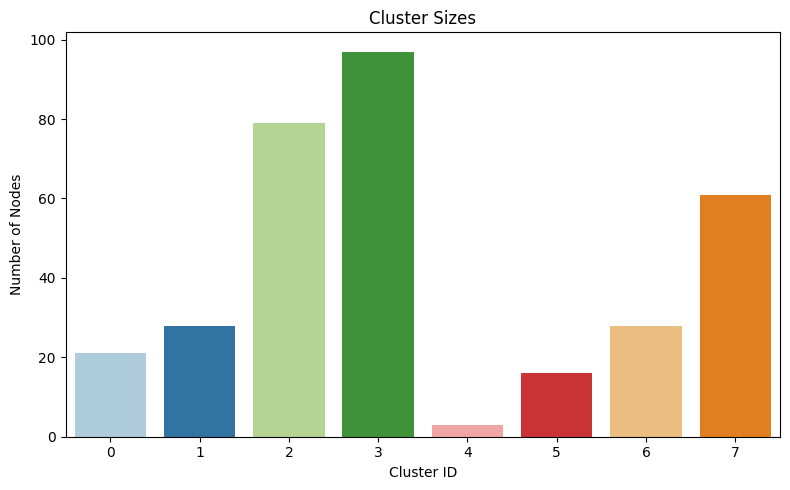


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.069946     1.780216e-02         0.008586         1.028410   
1               0.157488     5.264116e-03         0.013516         1.722185   
2               0.094476     6.127655e-03         0.010530         1.272691   
3               0.070539     1.012367e-02         0.014797         0.954434   
4               0.184034    -9.313226e-10         0.047946         2.182451   
5               0.028768     0.000000e+00         0.035146         1.327119   
6               0.216534     5.867244e-03         0.012206         1.115877   
7               0.034296     1.469341e-02         0.007071         0.639154   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0           6.710684e-03 

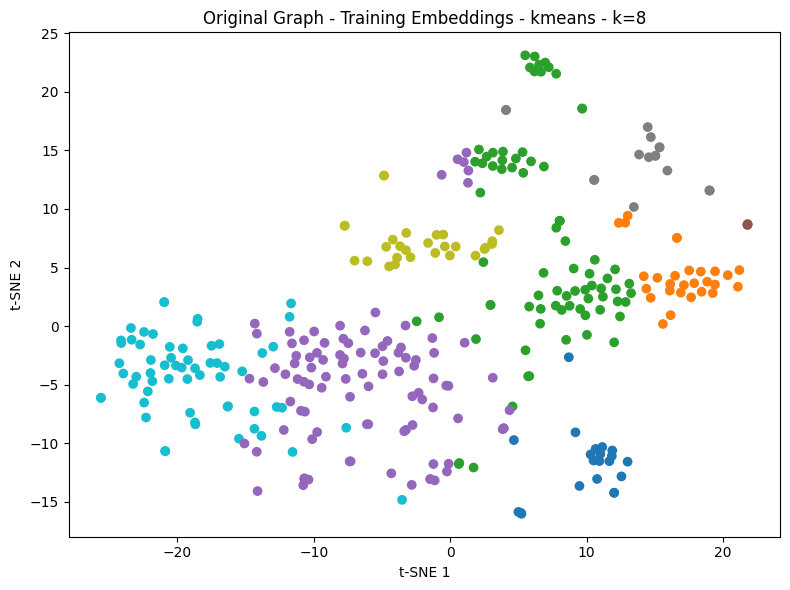

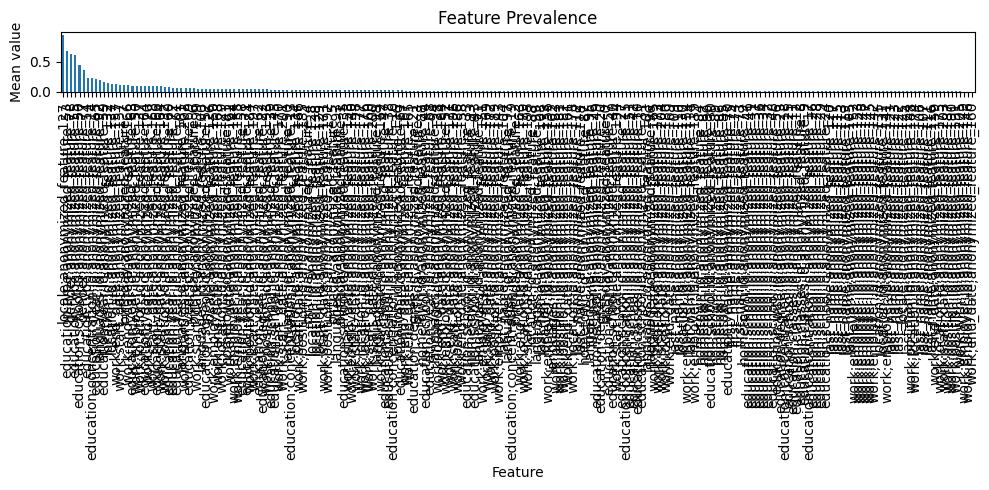


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.047619                       0.000000   
1                             0.000000                       0.107143   
2                             0.025316                       0.012658   
3                             0.010309                       0.010309   
4                             0.000000                       0.000000   
5                             0.000000                       0.125000   
6                             0.000000                       0.000000   
7                             0.000000                       0.016393   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.000000                       0.000000   
1               

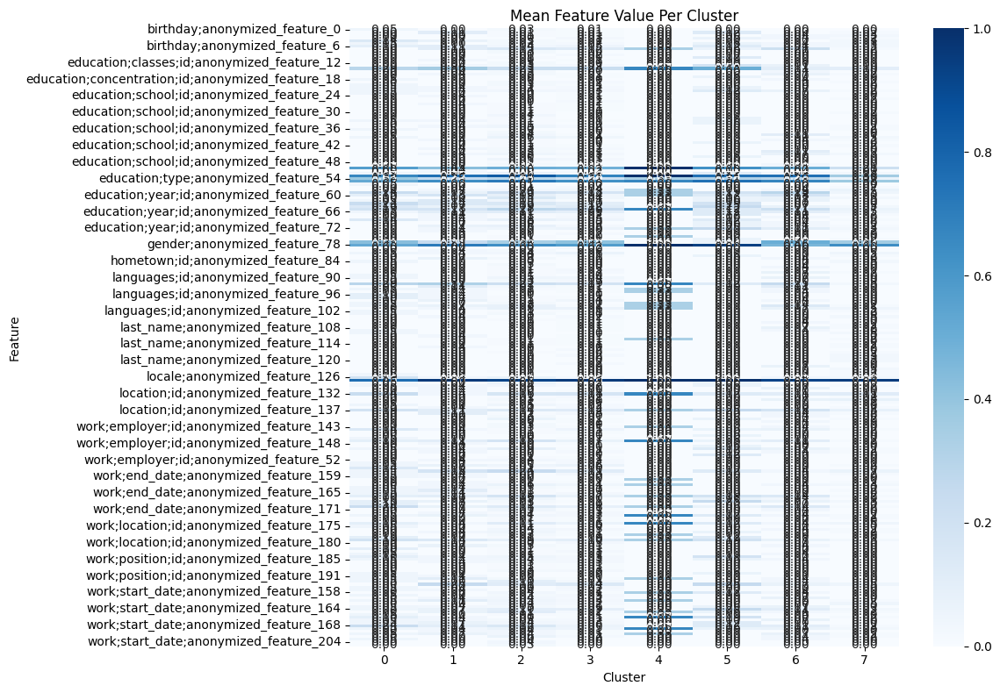

Features with > 30% prevalence/value in at least one cluster:
         birthday;anonymized_feature_7  \
cluster                                  
0                             0.000000   
1                             0.107143   
2                             0.151899   
3                             0.123711   
4                             0.333333   
5                             0.062500   
6                             0.214286   
7                             0.016393   

         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.285714   
1                                                0.357143   
2                                                0.227848   
3                                                0.226804   
4                                                0.666667   
5                                                0.500000   
6                            

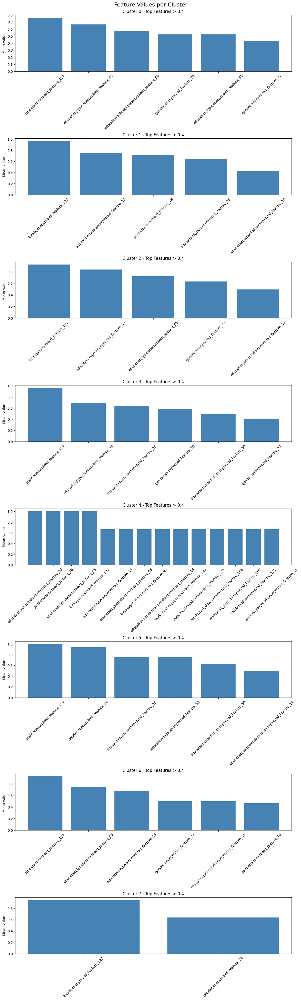


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0                     locale;anonymized_feature_127   
1         0              education;type;anonymized_feature_54   
2         0                     locale;anonymized_feature_126   
3         0            work;start_date;anonymized_feature_168   
4         0              work;end_date;anonymized_feature_170   
5         0           education;year;id;anonymized_feature_63   
6         0           work;employer;id;anonymized_feature_156   
7         0         education;school;id;anonymized_feature_50   
8         0            work;start_date;anonymized_feature_157   
9         0                     birthday;anonymized_feature_4   
10        0                     birthday;anonymized_feature_7   
11        0           work;employer;id;anonymized_feature_144   
12        0                      gender;anonymized_feature_78   
13        0                languages;id;anonymized_feature_92   

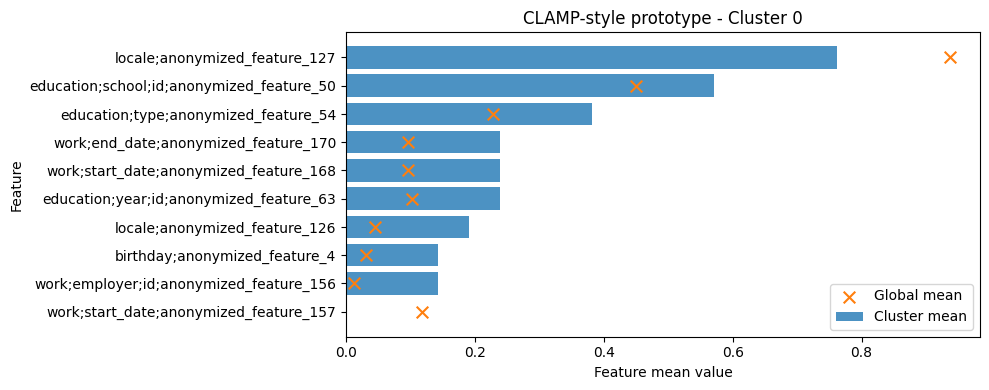

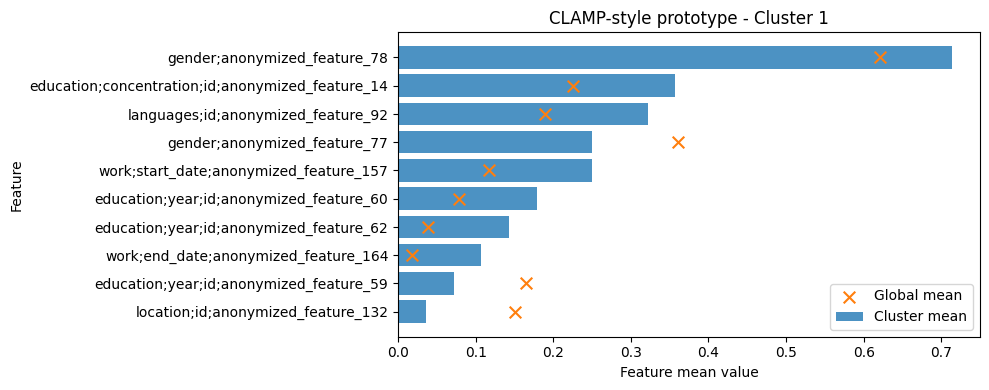

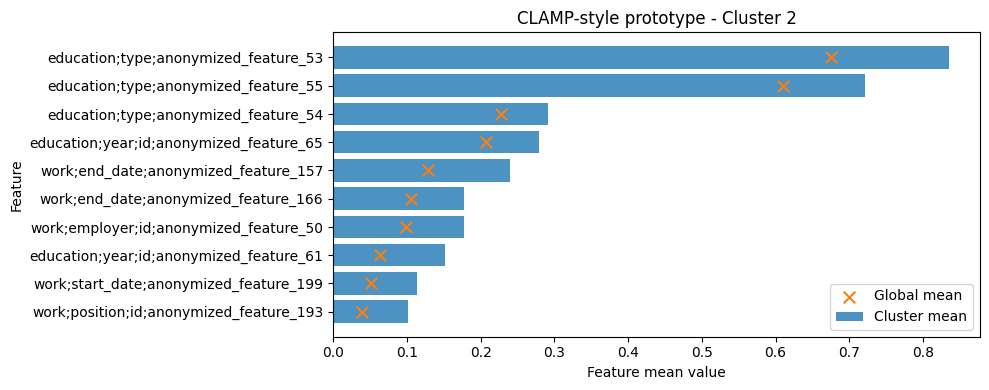

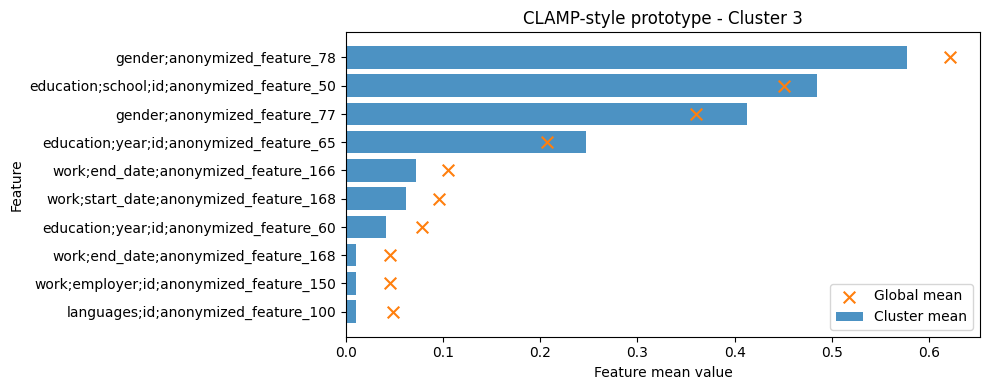

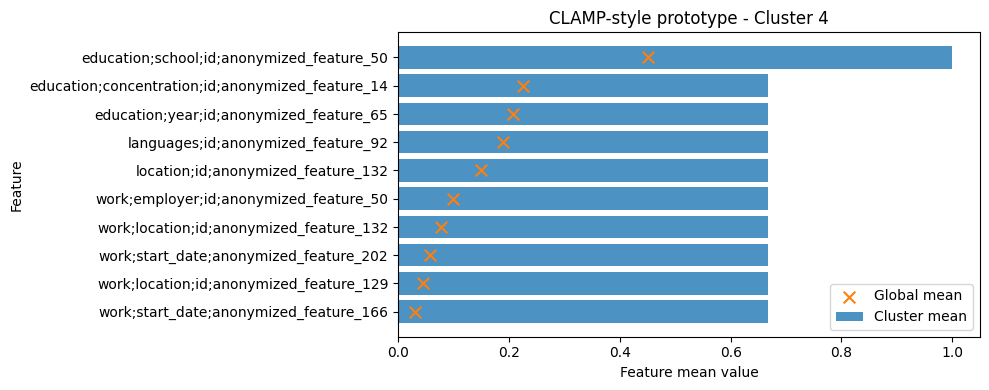

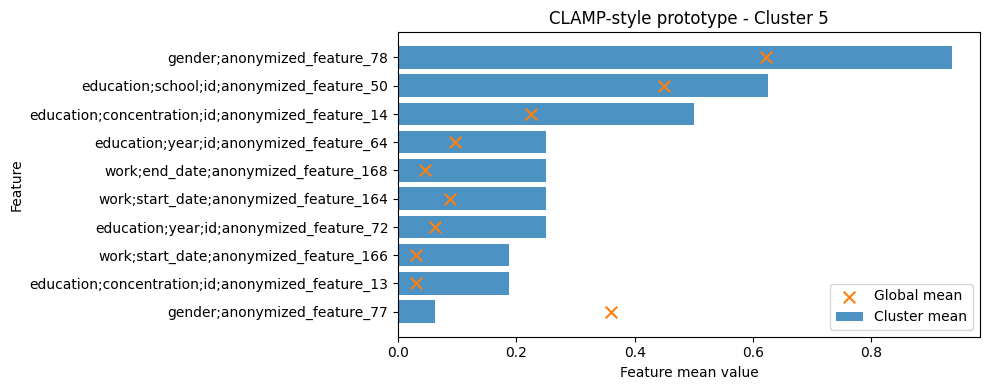

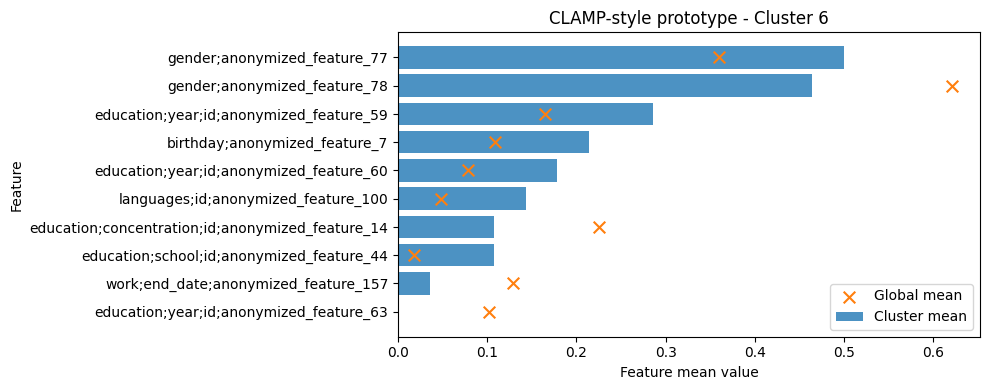

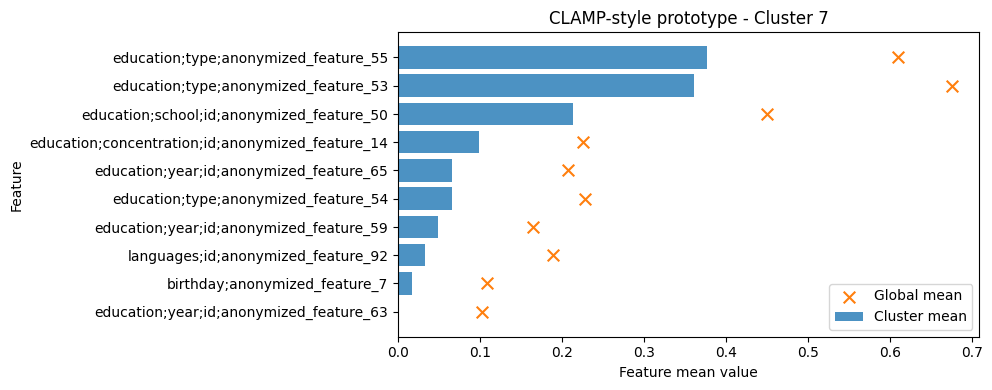

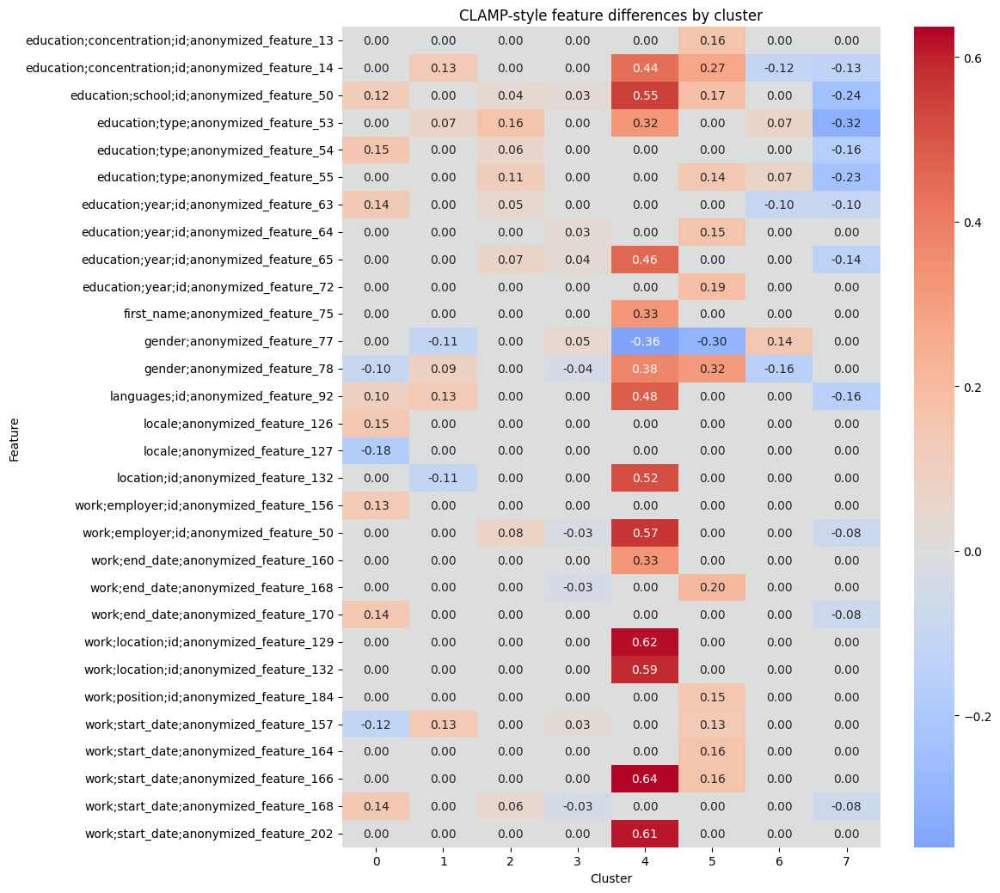


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.207207                         0.302815          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         5           4  

=== Decision tree rules ===
|--- work;start_date;anonymized_feature_166 <= 0.50
|   |--- work;location;id;anonymized_feature_129 <= 0.50
|   |   |--- education;year;id;anonymized_feature_72 <= 0.50
|   |   |   |--- education;year;id;anonymized_feature_63 <= 0.50
|   |   |   |   |--- class: 7
|   |   |   |--- education;year;id;anonymized_feature_63 >  0.50
|   |   |   |   |--- class: 0
|   |   |--- education;year;id;anonymized_feature_72 >  0.50
|   |   |   |--- class: 5
|   |--- work;location;id;anonymized_feature_129 >  0.50
|   |   |--- class: 4
|--- work;start_date;anonymized_feature_166 >  0.50
|   |--- class: 4



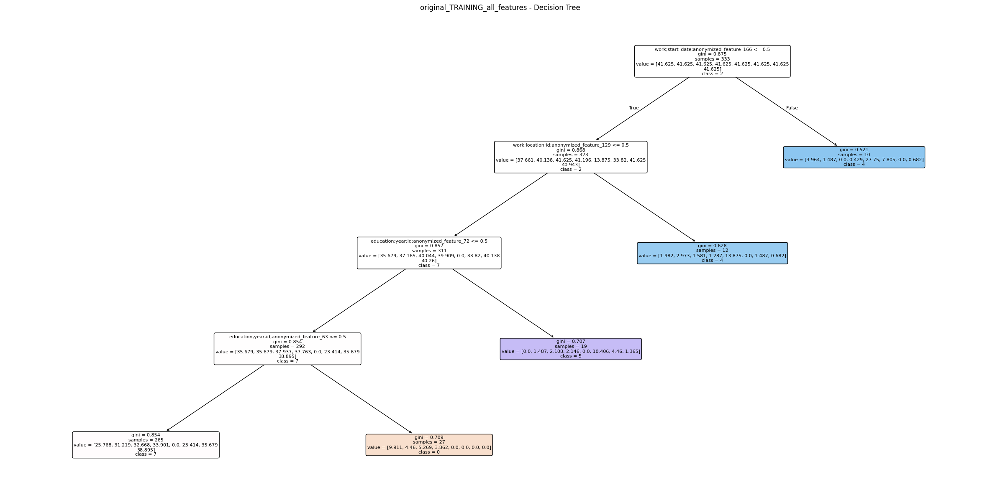


=== Decision tree feature importance ===
work;start_date;anonymized_feature_166     0.514679
work;location;id;anonymized_feature_129    0.261394
education;year;id;anonymized_feature_72    0.115243
education;year;id;anonymized_feature_63    0.108683
dtype: float64


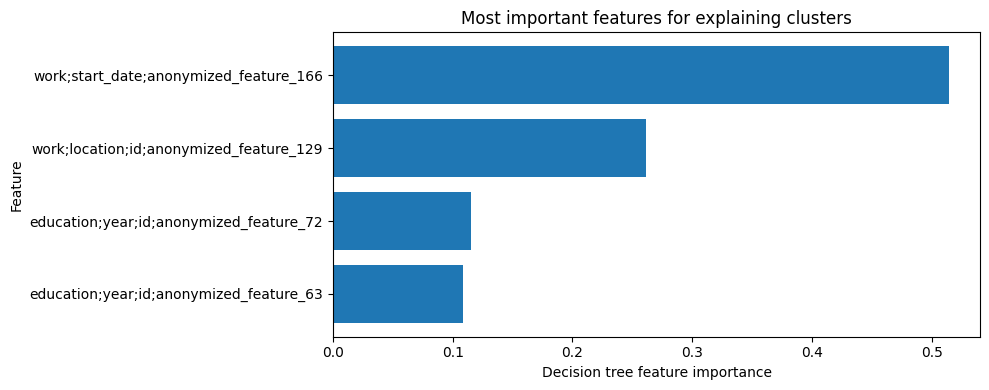


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.285714  0.047619  0.142857  0.095238  0.095238  0.047619  0.285714   
1        0.321429  0.000000  0.107143  0.035714  0.071429  0.035714  0.357143   
2        0.354430  0.075949  0.075949  0.037975  0.063291  0.012658  0.341772   
3        0.371134  0.082474  0.030928  0.041237  0.072165  0.041237  0.268041   
4        0.000000  0.000000  0.666667  0.000000  0.000000  0.000000  0.333333   
5        0.562500  0.062500  0.000000  0.000000  0.062500  0.062500  0.125000   
6        0.250000  0.071429  0.142857  0.035714  0.035714  0.000000  0.428571   
7        0.311475  0.049180  0.081967  0.065574  0.016393  0.032787  0.377049   

         circleOverlap  
cluster                 
0             0.000000  
1             0.071429  
2             0.037975  
3             0.092784  


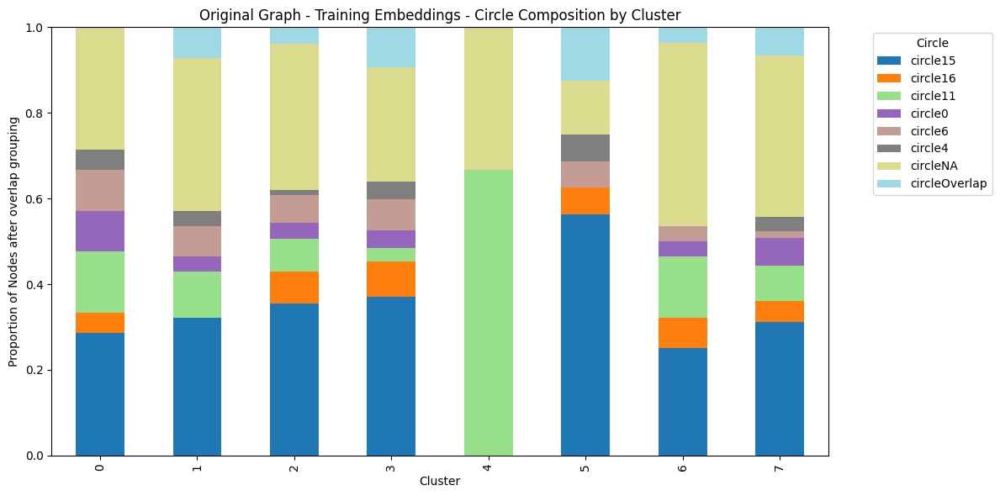

In [25]:
# ============================================================
# TRAINING-TIME MODEL 0A - Original graph with all features
# ============================================================

diagnostics_original_training_all, result_original_training_all = (
    run_final_dataset_analysis(
        dataset_name="original_TRAINING_all_features",
        n_clusters=K_ALL_FEATURES,
        final_method=final_method,
        random_state=random_state
    )
)


Dataset loaded: original_TRAINING_circles_only
Embeddings shape: (333, 64)
Features shape: (333, 7)
Membership shape: (333, 8)

Running diagnostics for: original_TRAINING_circles_only

=== original_TRAINING_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.557595         343.832591        0.739721                 2   
3     0.383071         395.847451        0.843232                 3   
6     0.317253         366.224494        0.950596                 4   
9     0.261419         323.454033        1.136466                 5   
12    0.270912         293.973820        1.083735                 6   
15    0.252210         275.920754        1.118404                 7   
18    0.237205         255.483278        1.234193                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3         ok   
6                     True  km

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


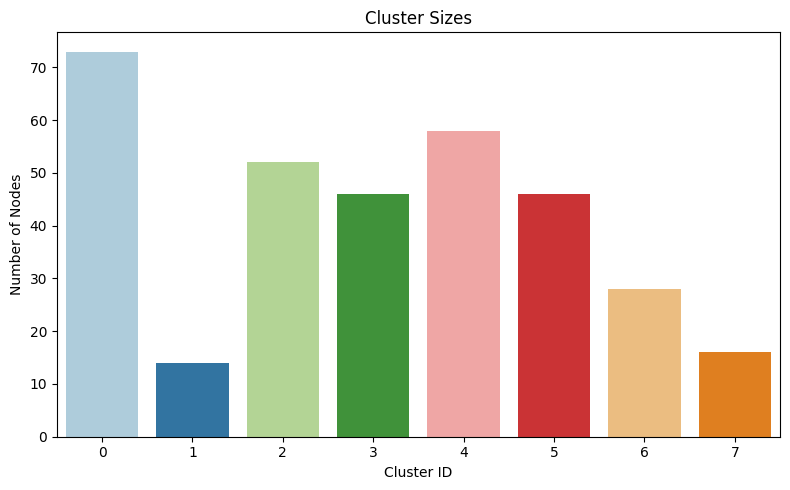


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0                    0.0         0.630075         0.379220         0.609608   
1                    0.0         2.494258         2.326023         3.098358   
2                    0.0         1.005159         0.867721         0.995330   
3                    0.0         0.323833         0.092425         0.296691   
4                    0.0         0.271130         0.134108         0.189782   
5                    0.0         0.573939         0.498706         0.555808   
6                    0.0         1.198303         0.942499         1.328014   
7                    0.0         1.719501         1.529597         1.665471   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               2.053499 

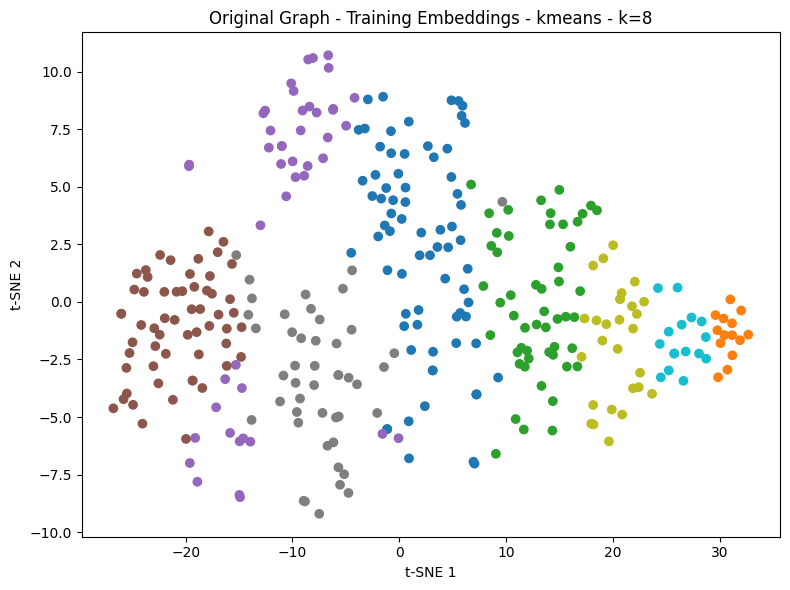

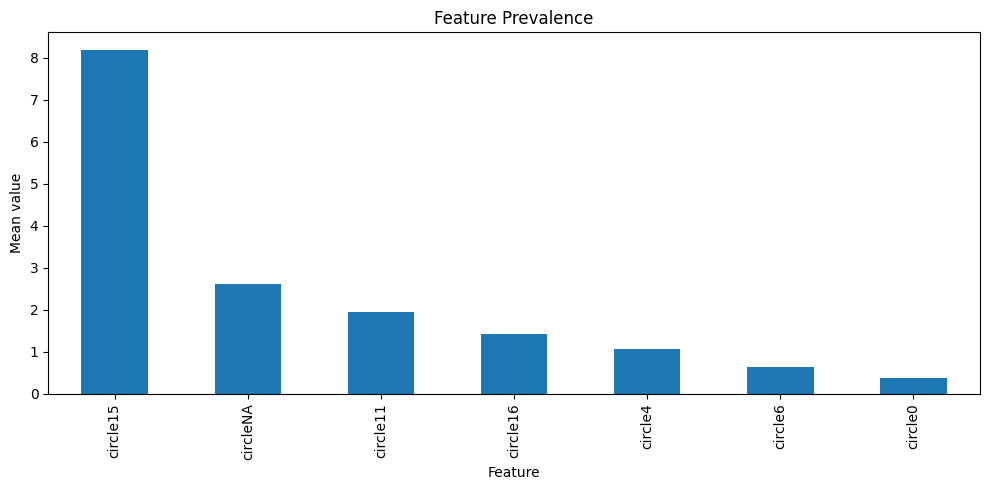


=== Cluster feature profiles ===
          circle15  circle16  circle11   circle0   circle6   circle4  circleNA
cluster                                                                       
0         7.657534  2.041096  1.643836  0.315068  0.630137  0.917808  2.493151
1        25.571429  1.428571  5.357143  0.714286  0.857143  3.285714  3.285714
2         7.903846  0.711538  2.326923  0.288462  0.673077  1.269231  2.326923
3         5.500000  2.413043  1.260870  0.369565  1.413043  0.369565  4.456522
4         3.603448  1.275862  0.879310  0.241379  0.431034  0.379310  1.913793
5         9.978261  0.782609  2.369565  0.586957  0.195652  1.521739  1.804348
6         9.821429  1.142857  2.285714  0.357143  0.321429  1.428571  2.500000
7        12.750000  0.937500  3.062500  0.562500  0.937500  1.687500  3.125000


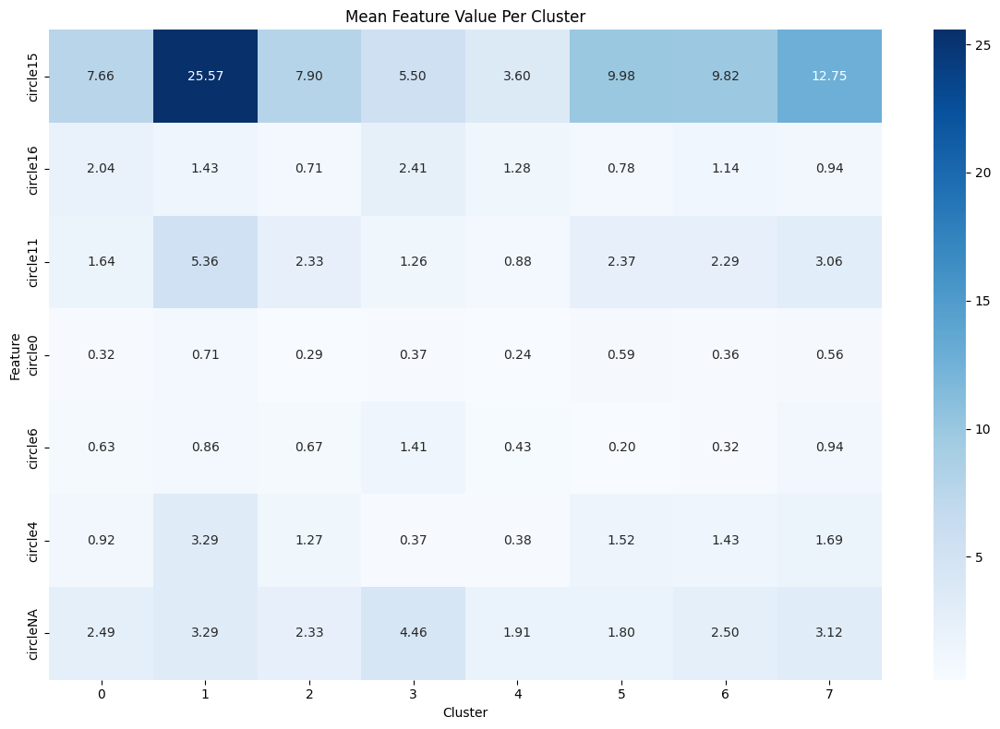

Features with > 30% prevalence/value in at least one cluster:
          circle15  circle16  circle11   circle0   circle6   circle4  circleNA
cluster                                                                       
0         7.657534  2.041096  1.643836  0.315068  0.630137  0.917808  2.493151
1        25.571429  1.428571  5.357143  0.714286  0.857143  3.285714  3.285714
2         7.903846  0.711538  2.326923  0.288462  0.673077  1.269231  2.326923
3         5.500000  2.413043  1.260870  0.369565  1.413043  0.369565  4.456522
4         3.603448  1.275862  0.879310  0.241379  0.431034  0.379310  1.913793
5         9.978261  0.782609  2.369565  0.586957  0.195652  1.521739  1.804348
6         9.821429  1.142857  2.285714  0.357143  0.321429  1.428571  2.500000
7        12.750000  0.937500  3.062500  0.562500  0.937500  1.687500  3.125000

=== Top mutual information features ===
circle15    0.442513
circle16    0.210375
circle11    0.202071
circleNA    0.159586
circle4     0.155173
ci

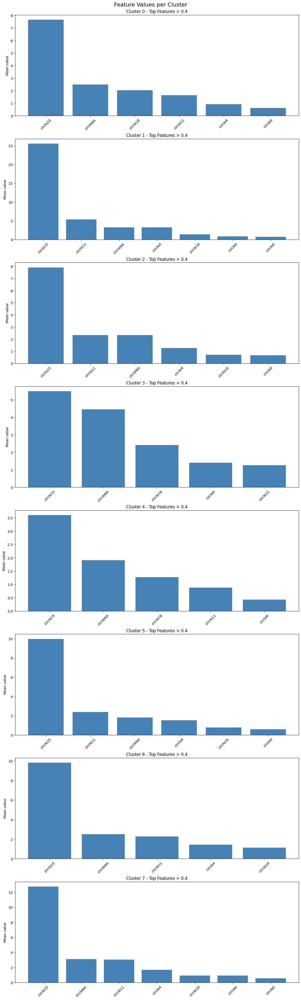


=== CLAMP prototypes ===
    cluster   feature  cluster_prevalence  global_prevalence  prevalence_diff  \
0         0  circle16            2.041096           1.423423         0.617672   
1         0  circle15            7.657534           8.192192        -0.534658   
2         0  circle11            1.643836           1.942943        -0.299107   
3         0   circle4            0.917808           1.066066        -0.148258   
4         0  circleNA            2.493151           2.606607        -0.113456   
5         0   circle0            0.315068           0.375375        -0.060307   
6         0   circle6            0.630137           0.648649        -0.018512   
7         1  circle15           25.571429           8.192192        17.379236   
8         1  circle11            5.357143           1.942943         3.414200   
9         1   circle4            3.285714           1.066066         2.219648   
10        1  circleNA            3.285714           2.606607         0.679108   
11

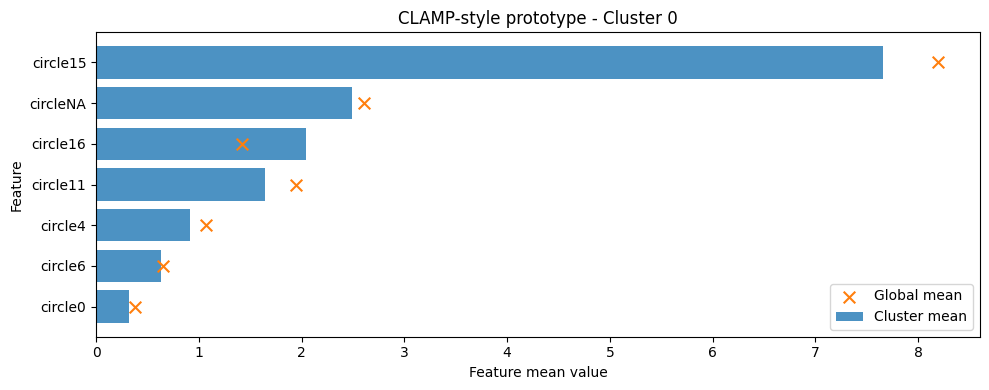

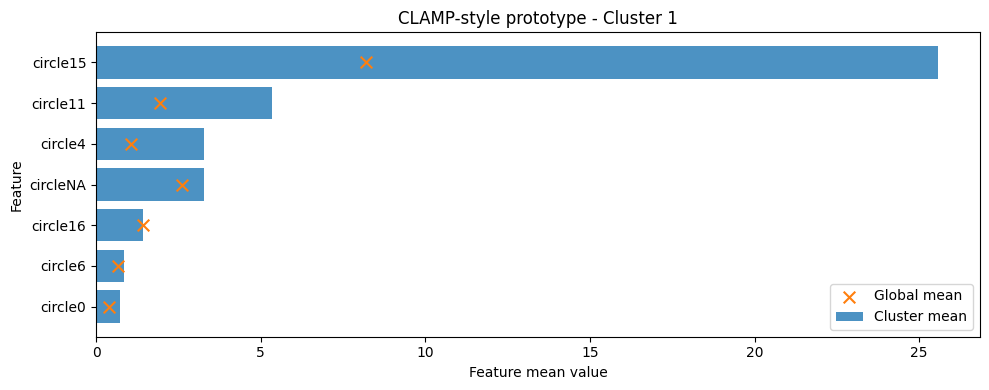

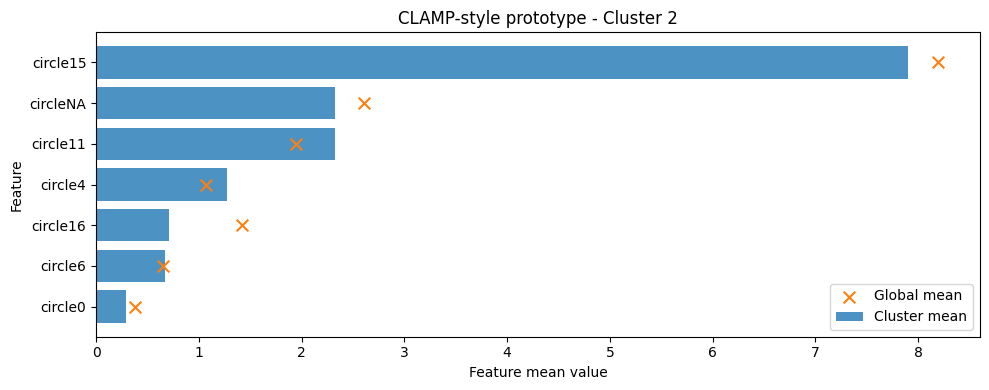

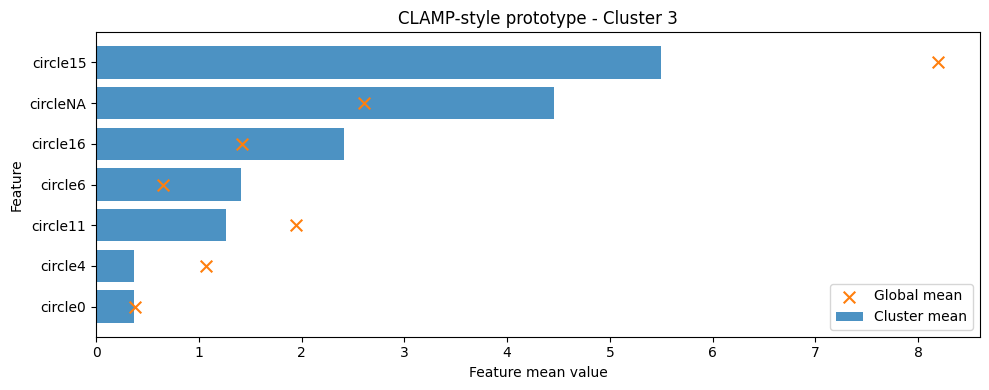

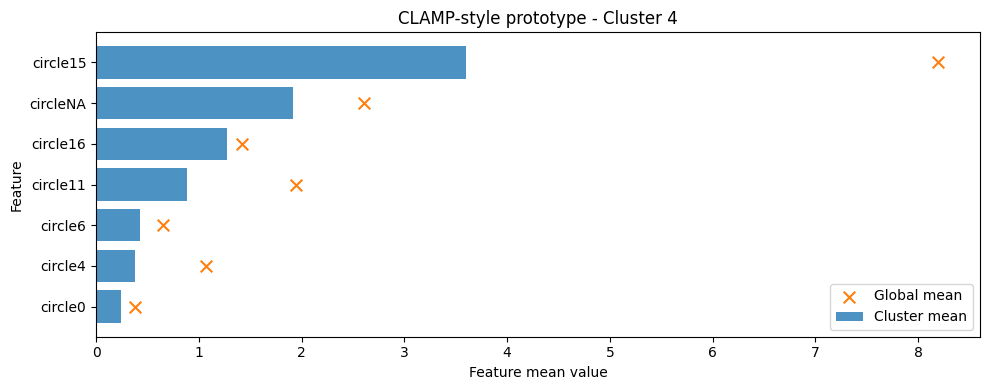

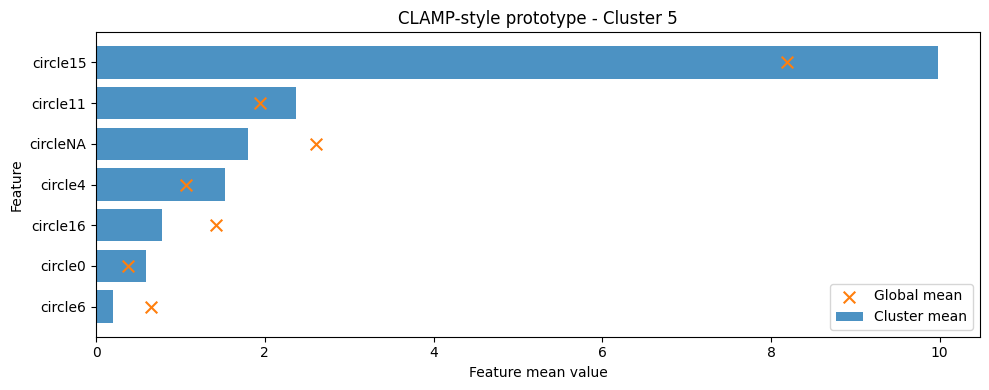

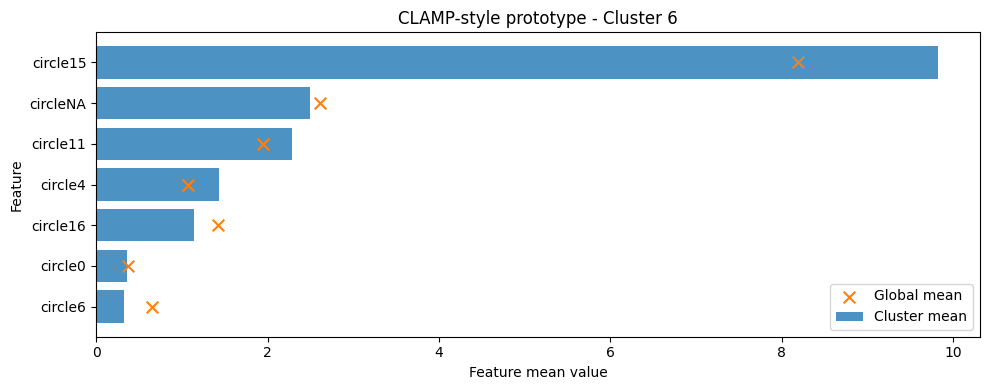

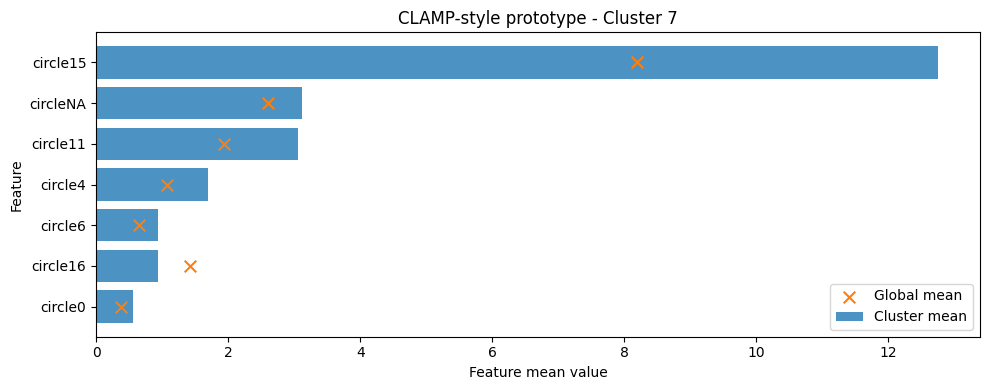

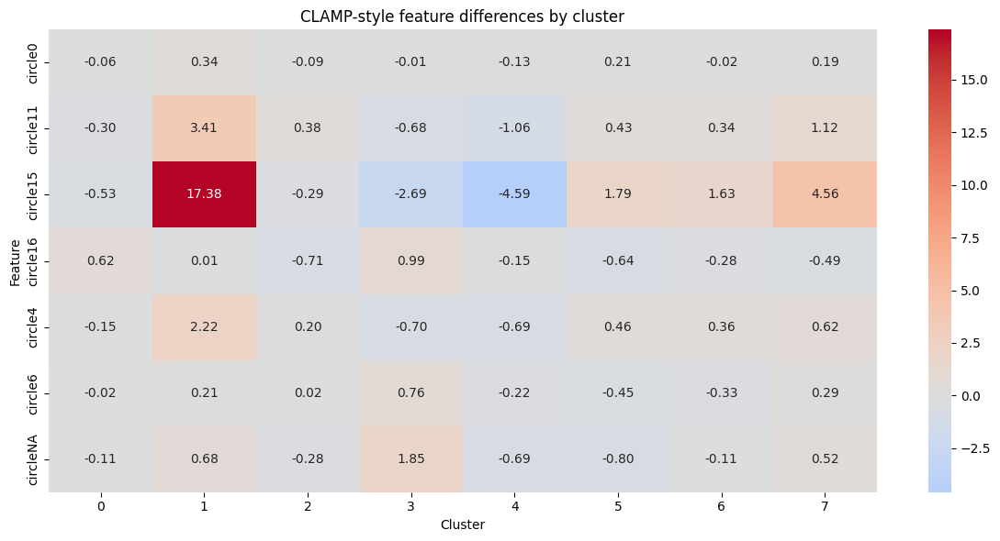


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.183183                         0.295277          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         8           4  

=== Decision tree rules ===
|--- circle15 <= 21.50
|   |--- circleNA <= 9.50
|   |   |--- circle16 <= 4.50
|   |   |   |--- circle4 <= 0.50
|   |   |   |   |--- class: 7
|   |   |   |--- circle4 >  0.50
|   |   |   |   |--- class: 5
|   |   |--- circle16 >  4.50
|   |   |   |--- circle15 <= 2.50
|   |   |   |   |--- class: 4
|   |   |   |--- circle15 >  2.50
|   |   |   |   |--- class: 3
|   |--- circleNA >  9.50
|   |   |--- class: 3
|--- circle15 >  21.50
|   |--- circle4 <= 4.50
|   |   |--- class: 1
|   |--- circle4 >  4.50
|   |   |--- circle15 <= 40.00
|   |   |   |--- class: 1
|   |   |--- circle15 >  40.00
|   |   |   |--- class: 7



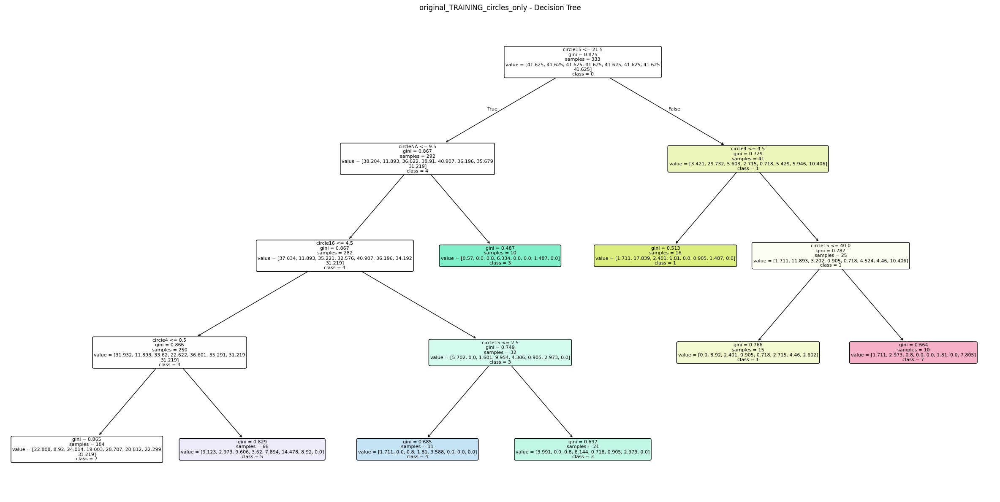


=== Decision tree feature importance ===
circle15    0.551928
circle4     0.211704
circleNA    0.124516
circle16    0.111852
dtype: float64


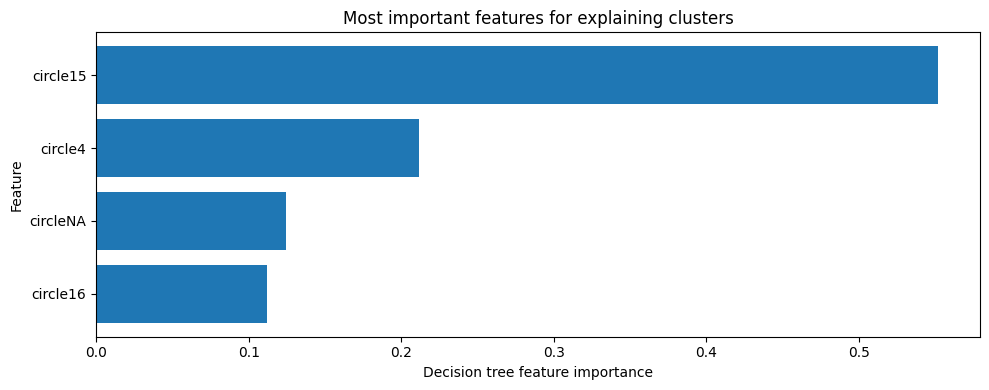


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.315068  0.068493  0.109589  0.041096  0.054795  0.013699  0.328767   
1        0.571429  0.071429  0.071429  0.000000  0.071429  0.000000  0.071429   
2        0.384615  0.038462  0.076923  0.057692  0.076923  0.076923  0.288462   
3        0.217391  0.086957  0.086957  0.000000  0.108696  0.000000  0.369565   
4        0.241379  0.120690  0.051724  0.103448  0.017241  0.051724  0.379310   
5        0.434783  0.000000  0.086957  0.043478  0.000000  0.000000  0.347826   
6        0.428571  0.071429  0.071429  0.035714  0.035714  0.071429  0.250000   
7        0.437500  0.000000  0.000000  0.000000  0.187500  0.000000  0.312500   

         circleOverlap  
cluster                 
0             0.068493  
1             0.142857  
2             0.000000  
3             0.130435  


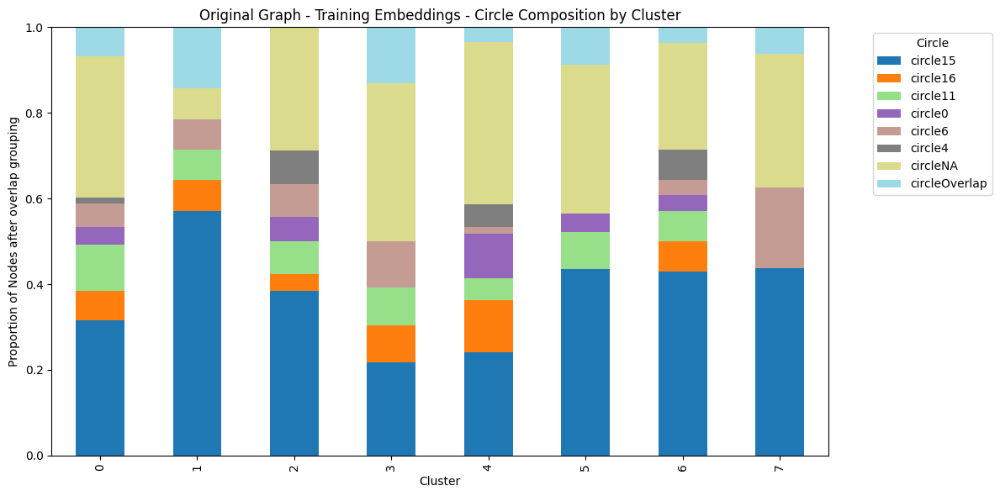

In [26]:
# ============================================================
# TRAINING-TIME MODEL 0B - Original graph with circles-only ARD
# ============================================================

diagnostics_original_training_circles, result_original_training_circles = (
    run_final_dataset_analysis(
        dataset_name="original_TRAINING_circles_only",
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)


Dataset loaded: original_TRAINING_graph_structure_identity_only
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: original_TRAINING_graph_structure_identity_only

=== original_TRAINING_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.256269         110.986174        1.623645                 2   
3     0.267174          83.150343        2.050336                 3   
6     0.276406          69.834639        1.864846                 4   
9     0.285453          61.378369        1.994576                 5   
12    0.190689          56.173704        1.877403                 6   
15    0.171645          52.775721        1.768070                 7   
18    0.183485          50.137889        1.866828                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  k

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


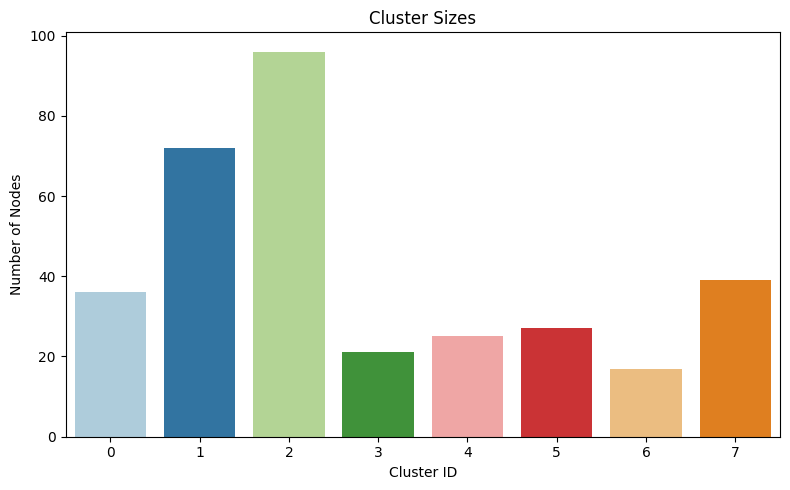


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.057452    -7.450581e-09         0.007341     1.357861e-01   
1               0.014425     9.588863e-02         0.007613    -2.235174e-08   
2               0.030650     5.191705e-02         0.004263     9.048212e-03   
3               0.118086     1.170922e-03         0.008143     9.016149e-02   
4               0.002722     1.497864e-02         0.009448     1.313382e-01   
5               0.044214     4.124150e-02         0.006239     2.932278e-02   
6               0.004035     5.845411e-02         0.002249     0.000000e+00   
7               0.032939     4.572082e-02         0.009949     8.757542e-02   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.006058 

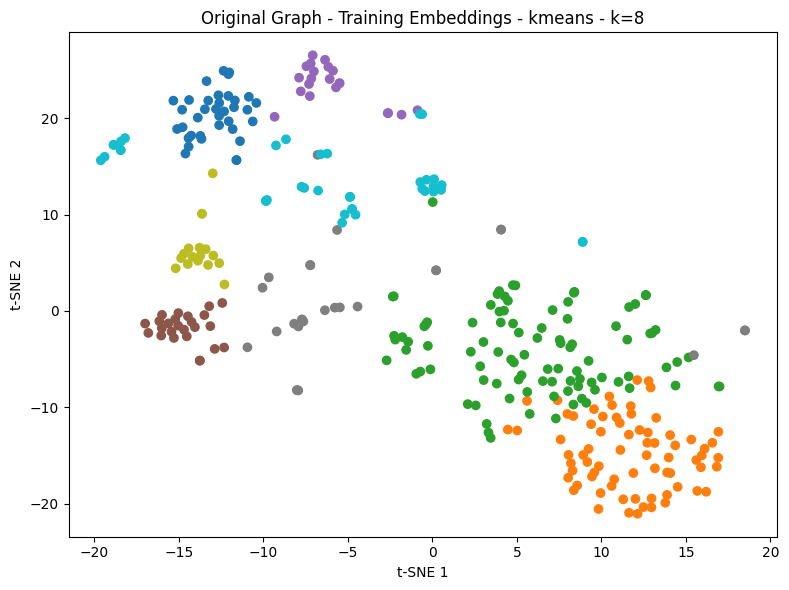

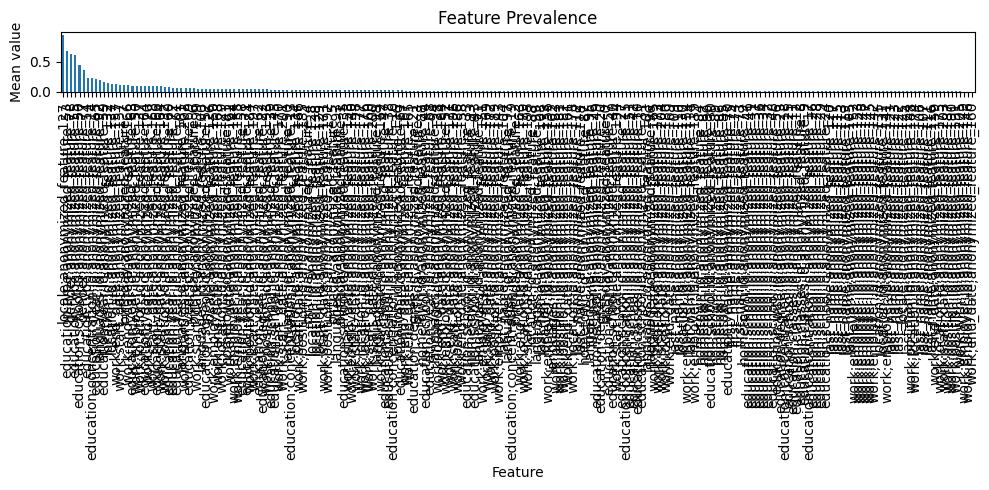


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.000000   
1                             0.027778                       0.041667   
2                             0.000000                       0.000000   
3                             0.000000                       0.047619   
4                             0.040000                       0.080000   
5                             0.000000                       0.037037   
6                             0.000000                       0.000000   
7                             0.025641                       0.025641   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.000000                       0.055556   
1               

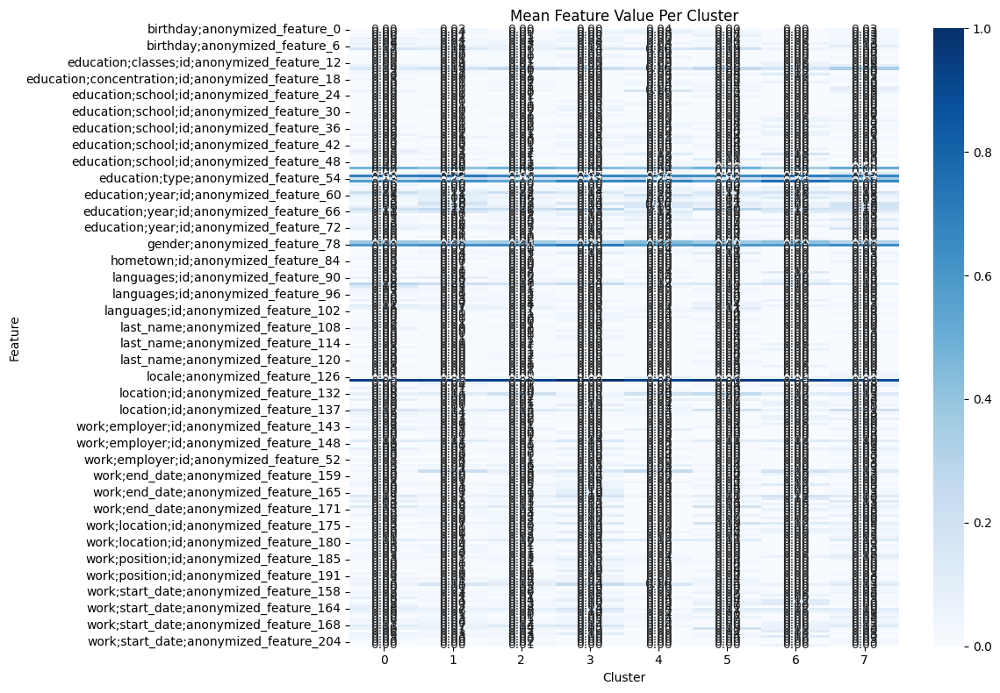

Features with > 30% prevalence/value in at least one cluster:
         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.138889   
1                                                0.180556   
2                                                0.260417   
3                                                0.238095   
4                                                0.160000   
5                                                0.259259   
6                                                0.176471   
7                                                0.333333   

         education;school;id;anonymized_feature_50  \
cluster                                              
0                                         0.472222   
1                                         0.402778   
2                                         0.479167   
3                                         0.428571   
4  

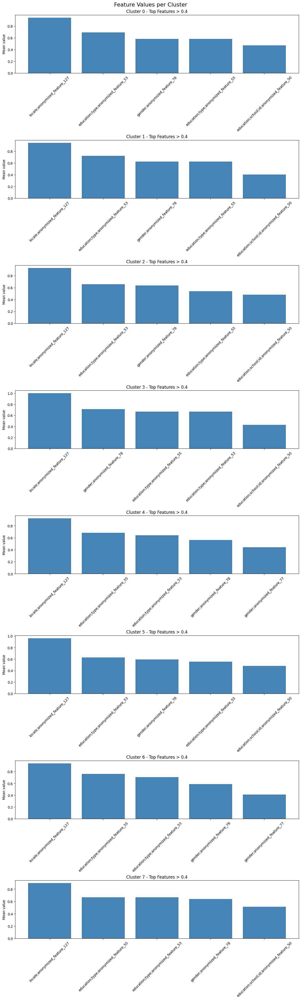


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0                languages;id;anonymized_feature_93   
1         0           education;year;id;anonymized_feature_63   
2         0              work;end_date;anonymized_feature_157   
3         0                languages;id;anonymized_feature_92   
4         0  education;concentration;id;anonymized_feature_14   
5         0                location;id;anonymized_feature_132   
6         0         education;school;id;anonymized_feature_44   
7         0               languages;id;anonymized_feature_100   
8         0            work;start_date;anonymized_feature_157   
9         0            work;start_date;anonymized_feature_198   
10        0            work;start_date;anonymized_feature_160   
11        0                     birthday;anonymized_feature_7   
12        0           education;year;id;anonymized_feature_59   
13        0                location;id;anonymized_feature_134   

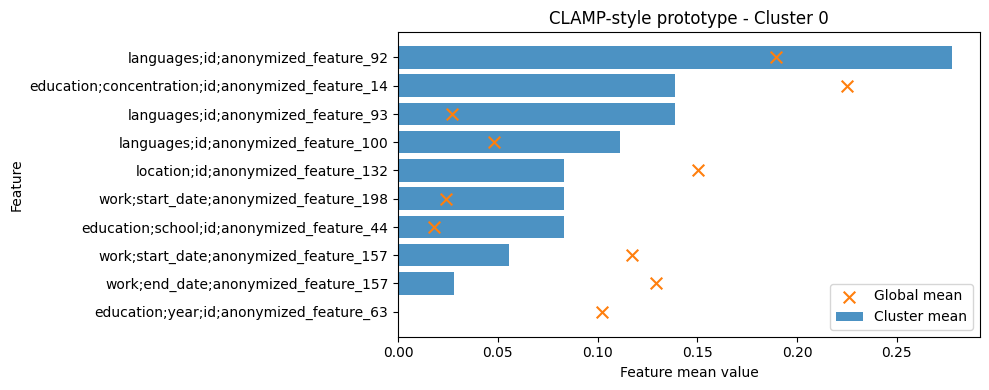

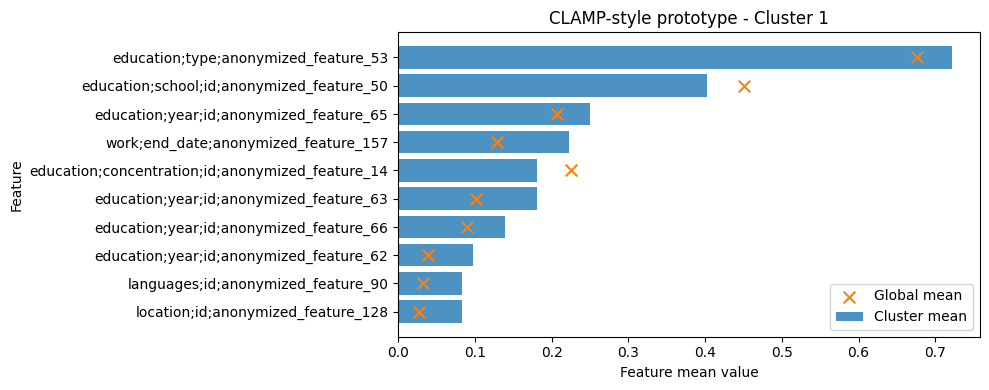

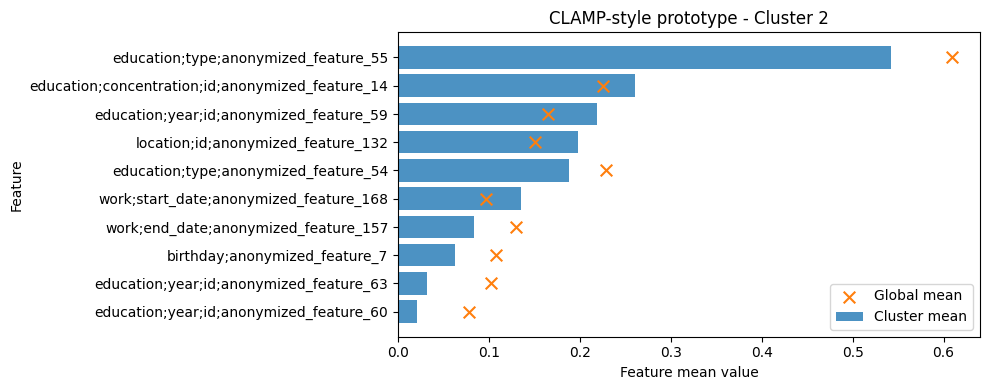

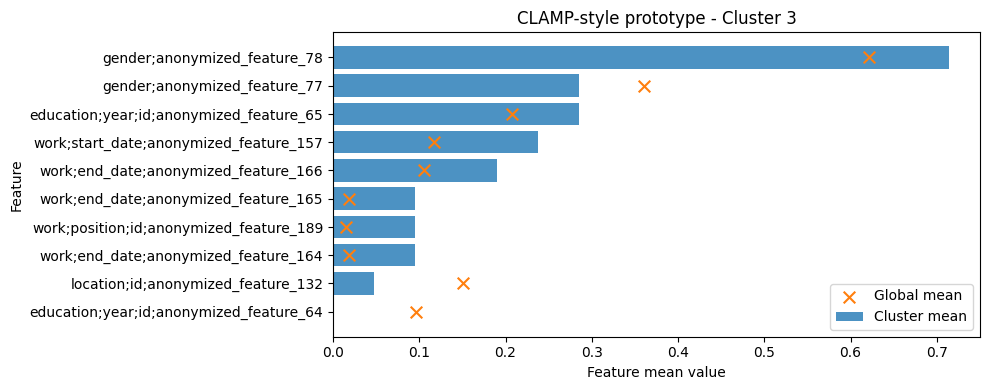

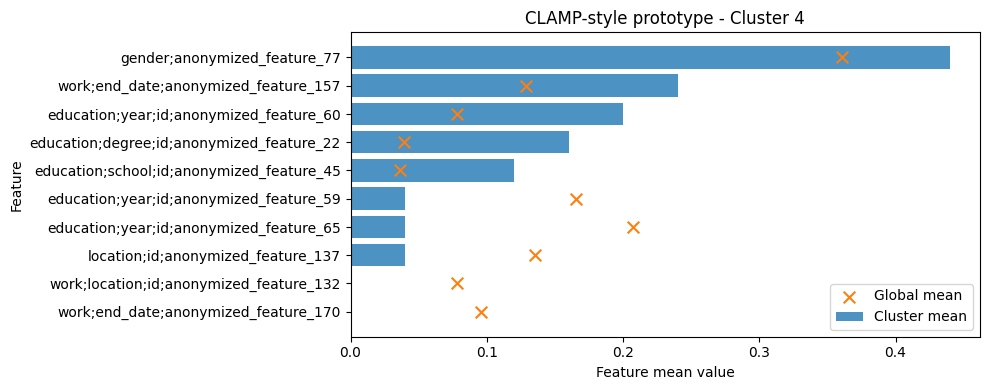

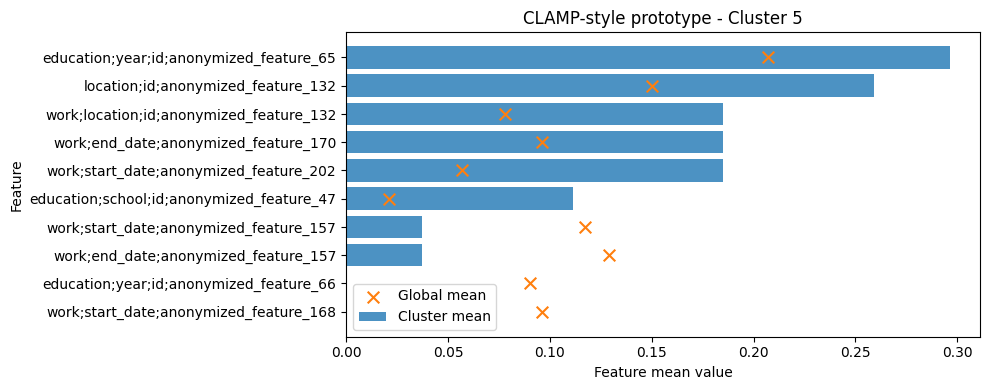

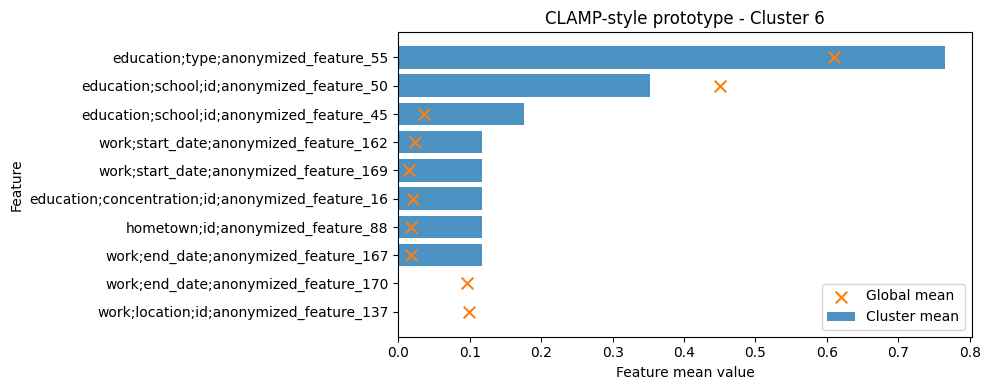

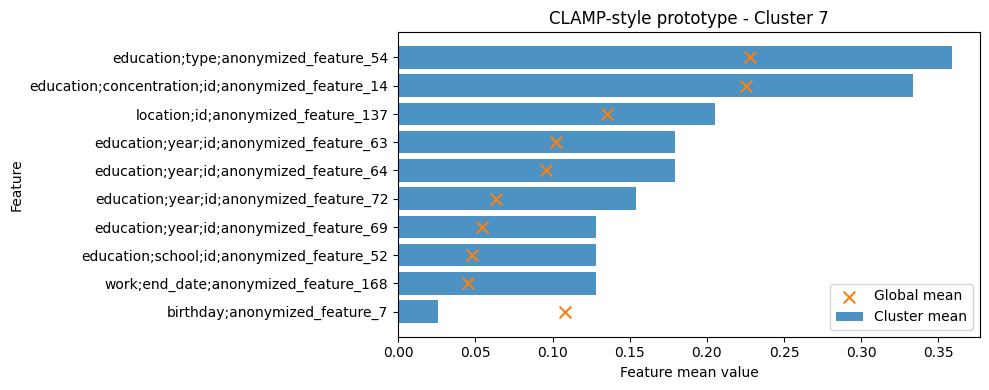

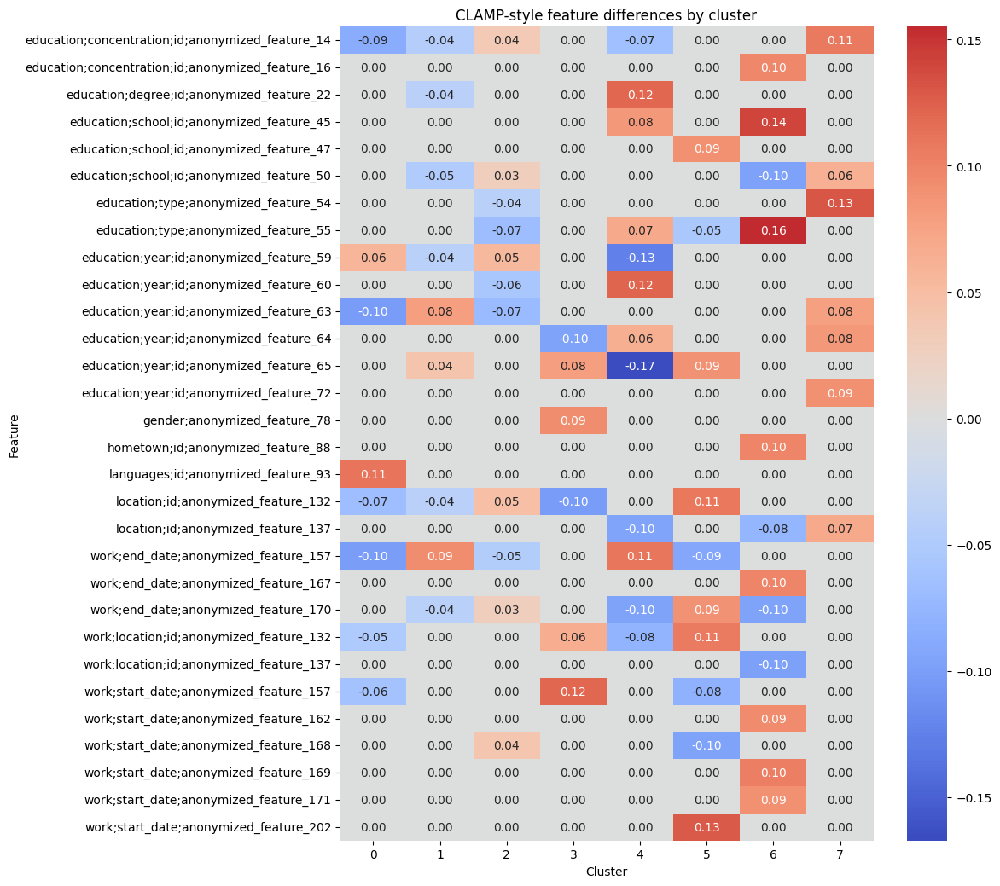


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.105105                         0.191123          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         5           4  

=== Decision tree rules ===
|--- education;school;id;anonymized_feature_45 <= 0.50
|   |--- education;degree;id;anonymized_feature_22 <= 0.50
|   |   |--- education;school;id;anonymized_feature_52 <= 0.50
|   |   |   |--- work;start_date;anonymized_feature_202 <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- work;start_date;anonymized_feature_202 >  0.50
|   |   |   |   |--- class: 5
|   |   |--- education;school;id;anonymized_feature_52 >  0.50
|   |   |   |--- class: 7
|   |--- education;degree;id;anonymized_feature_22 >  0.50
|   |   |--- class: 4
|--- education;school;id;anonymized_feature_45 >  0.50
|   |--- class: 6



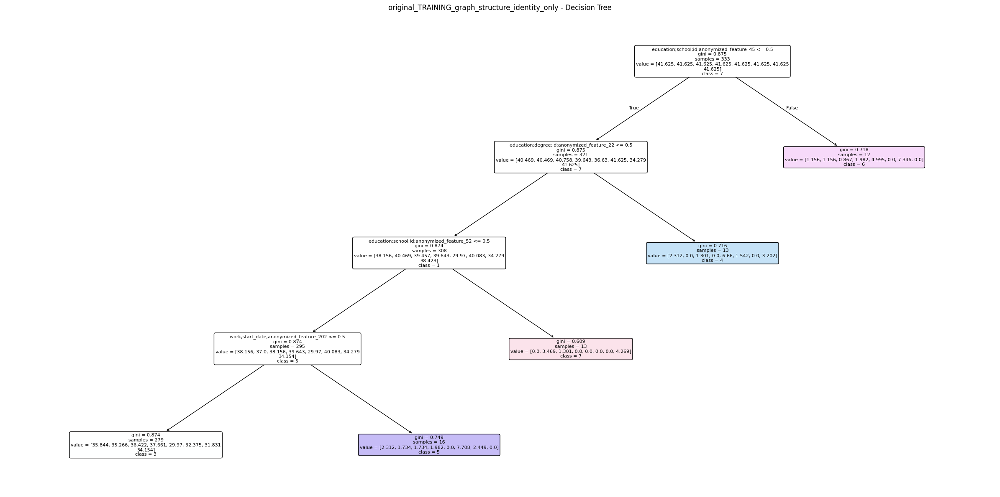


=== Decision tree feature importance ===
education;school;id;anonymized_feature_45    0.290162
education;degree;id;anonymized_feature_22    0.254900
education;school;id;anonymized_feature_52    0.238486
work;start_date;anonymized_feature_202       0.216452
dtype: float64


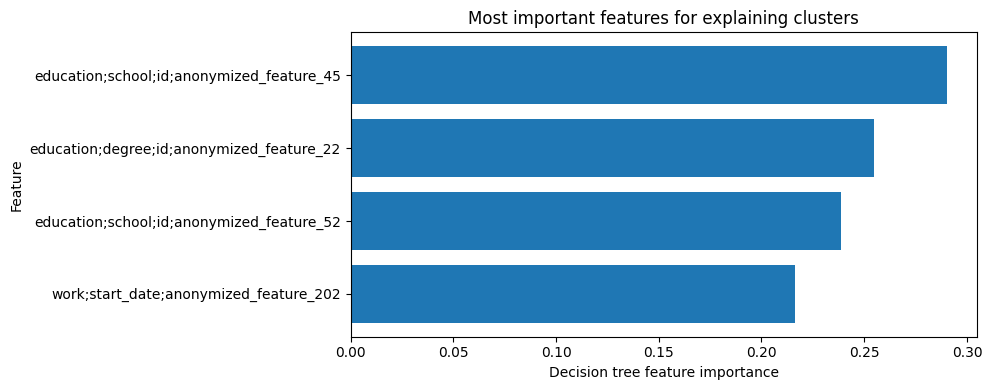


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.305556  0.055556  0.138889  0.055556  0.027778  0.000000  0.416667   
1        0.291667  0.013889  0.055556  0.027778  0.055556  0.041667  0.402778   
2        0.427083  0.093750  0.062500  0.062500  0.010417  0.031250  0.260417   
3        0.476190  0.000000  0.047619  0.000000  0.142857  0.000000  0.190476   
4        0.160000  0.160000  0.040000  0.080000  0.200000  0.040000  0.280000   
5        0.259259  0.000000  0.185185  0.000000  0.037037  0.037037  0.370370   
6        0.294118  0.117647  0.117647  0.058824  0.058824  0.000000  0.352941   
7        0.384615  0.076923  0.051282  0.051282  0.076923  0.051282  0.282051   

         circleOverlap  
cluster                 
0             0.000000  
1             0.111111  
2             0.052083  
3             0.142857  


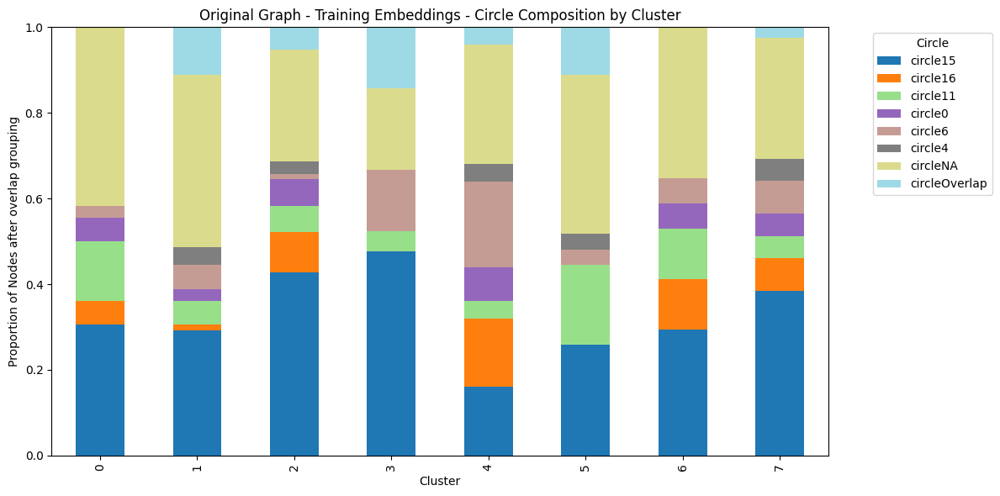

In [27]:
# ============================================================
# TRAINING-TIME MODEL 0C - Original graph with structure only
# ============================================================

diagnostics_original_training_structure, result_original_training_structure = (
    run_final_dataset_analysis(
        dataset_name="original_TRAINING_graph_structure_identity_only",
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)


Dataset loaded: method1_independent_mean_all_features
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method1_independent_mean_all_features

=== method1_independent_mean_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.591513         531.021590        0.612577                 2   
3     0.460812         633.939295        0.662007                 3   
6     0.463713         765.745335        0.652521                 4   
9     0.424780         849.128687        0.711196                 5   
12    0.412743         817.480190        0.742117                 6   
15    0.361969         831.173574        0.804256                 7   
18    0.320837         806.205948        0.928898                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3         ok   
6      

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


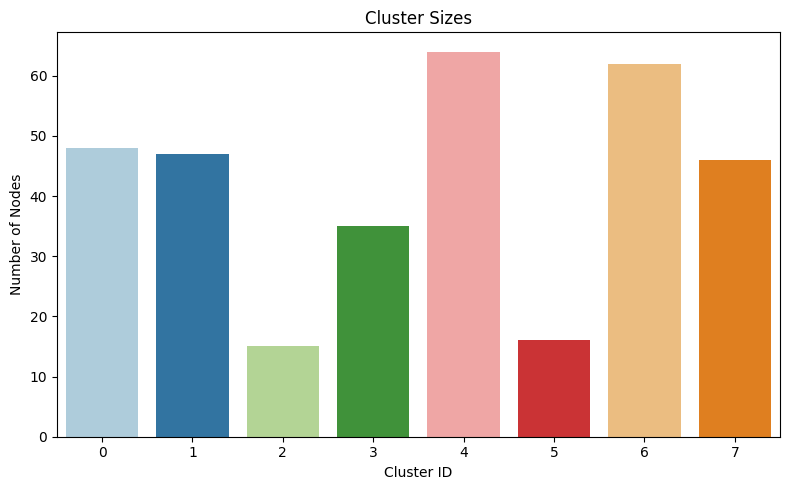


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.061159         0.071207         0.071880         0.076579   
1               0.092817         0.114763         0.112514         0.126031   
2               0.142160         0.174845         0.171974         0.201202   
3               0.107872         0.129424         0.128895         0.144875   
4               0.079600         0.094713         0.095486         0.106274   
5               0.123869         0.151041         0.148027         0.170449   
6               0.085913         0.103563         0.102969         0.114795   
7               0.071781         0.084131         0.085319         0.093754   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.061597 

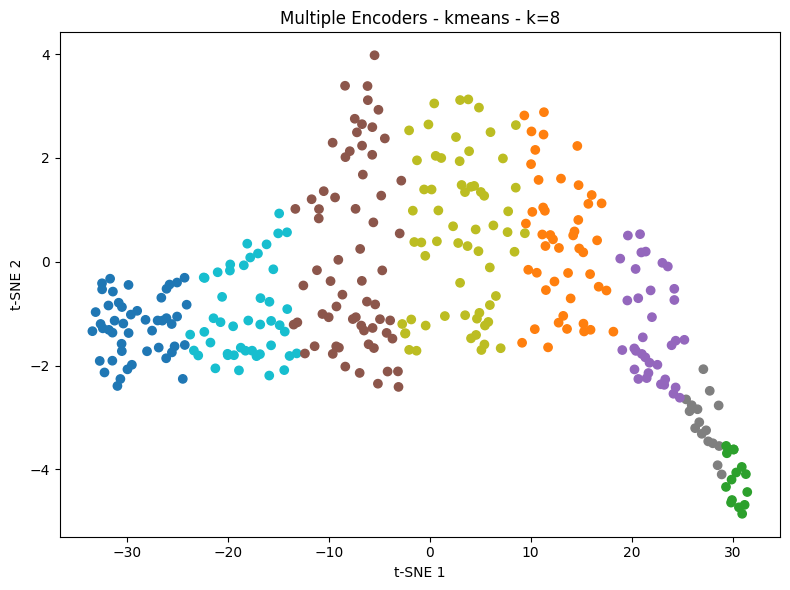

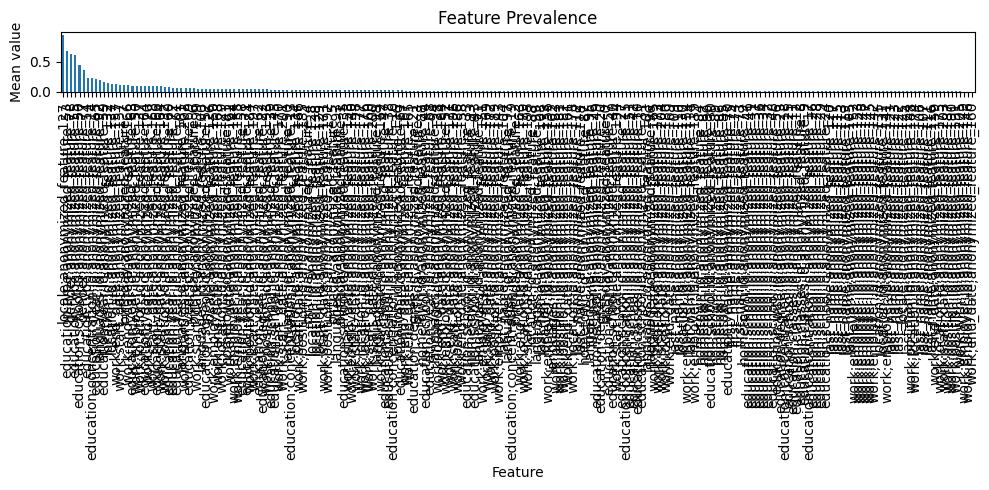


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.000000   
1                             0.021277                       0.063830   
2                             0.000000                       0.000000   
3                             0.028571                       0.028571   
4                             0.015625                       0.046875   
5                             0.000000                       0.000000   
6                             0.016129                       0.016129   
7                             0.000000                       0.000000   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.000000                       0.000000   
1               

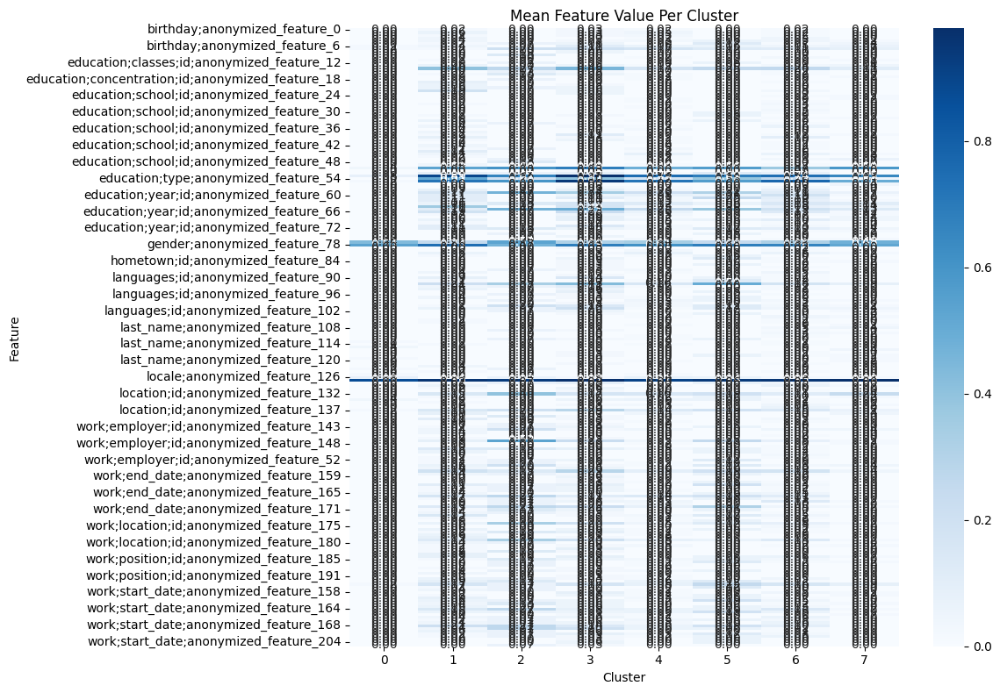

Features with > 30% prevalence/value in at least one cluster:
         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.000000   
1                                                0.404255   
2                                                0.266667   
3                                                0.457143   
4                                                0.171875   
5                                                0.250000   
6                                                0.258065   
7                                                0.108696   

         education;school;id;anonymized_feature_50  \
cluster                                              
0                                         0.041667   
1                                         0.531915   
2                                         0.600000   
3                                         0.685714   
4  

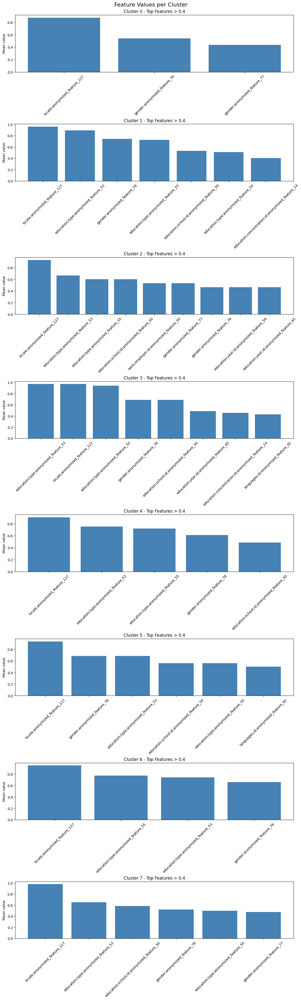


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0              education;type;anonymized_feature_53   
1         0              education;type;anonymized_feature_55   
2         0         education;school;id;anonymized_feature_50   
3         0              education;type;anonymized_feature_54   
4         0  education;concentration;id;anonymized_feature_14   
5         0           education;year;id;anonymized_feature_65   
6         0                languages;id;anonymized_feature_92   
7         0           education;year;id;anonymized_feature_59   
8         0                location;id;anonymized_feature_132   
9         0              work;end_date;anonymized_feature_157   
10        0                location;id;anonymized_feature_137   
11        0              work;end_date;anonymized_feature_166   
12        0           education;year;id;anonymized_feature_63   
13        0            work;employer;id;anonymized_feature_50   

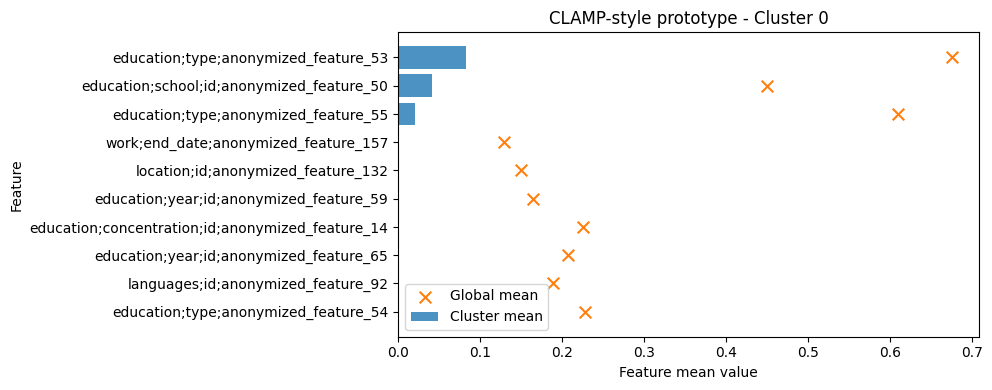

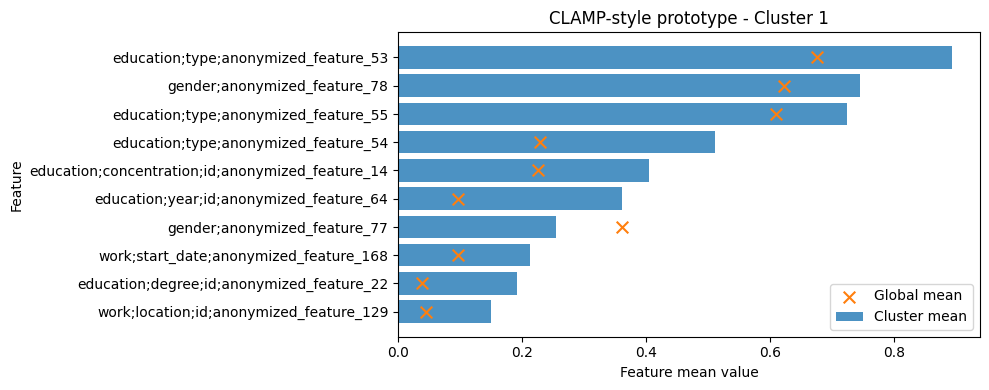

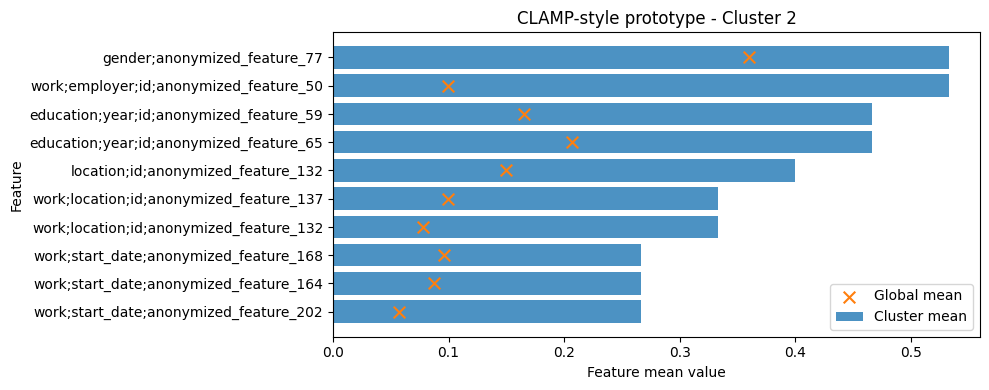

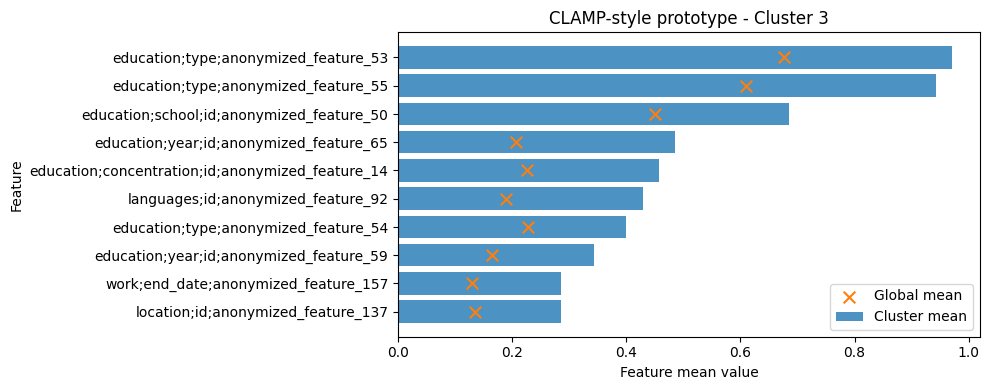

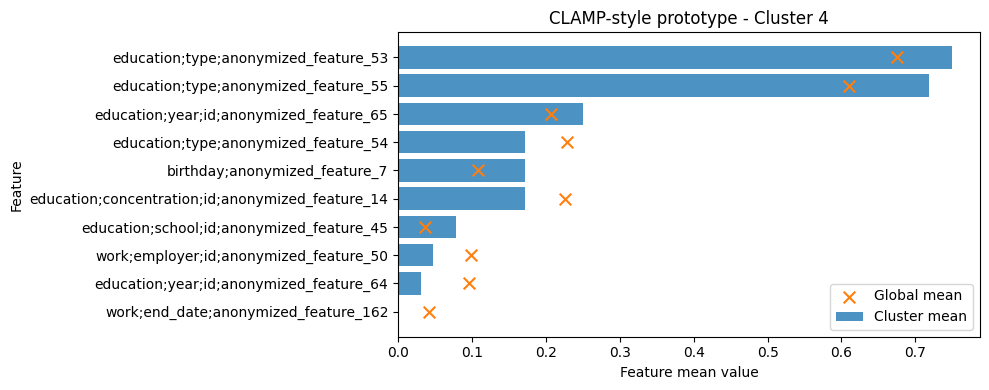

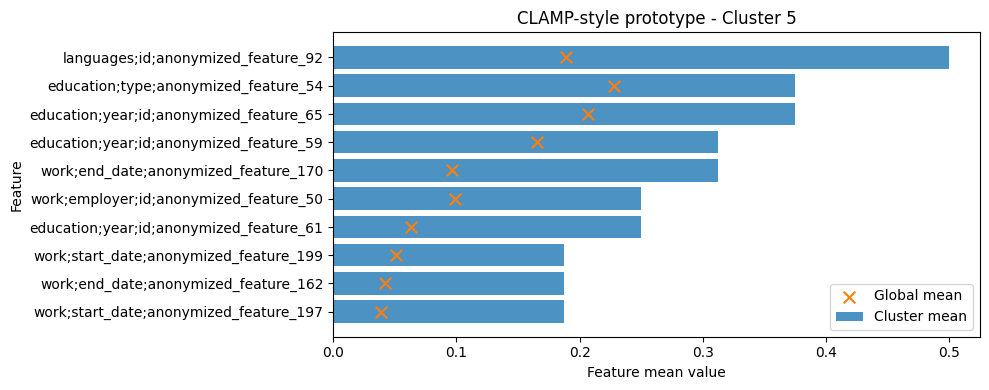

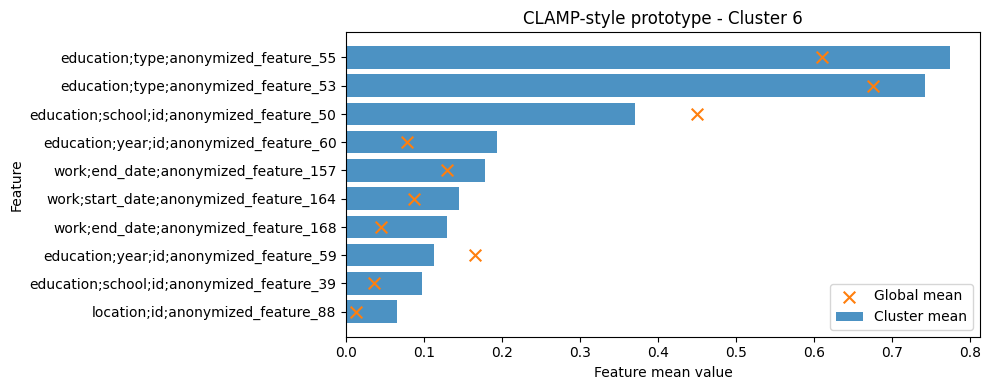

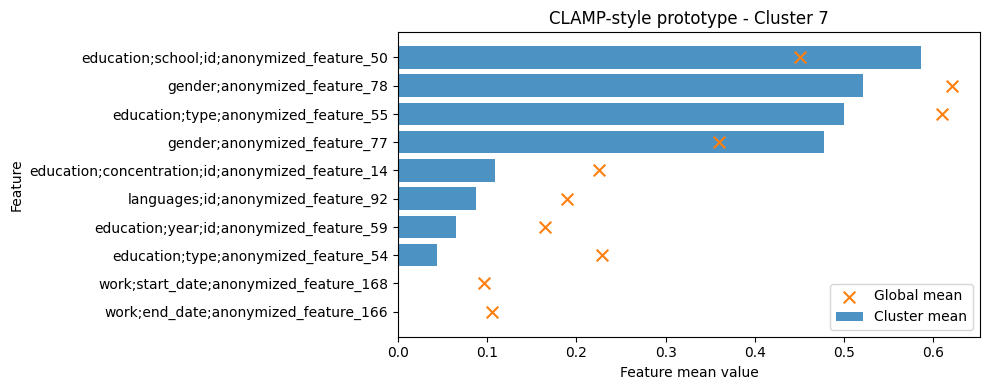

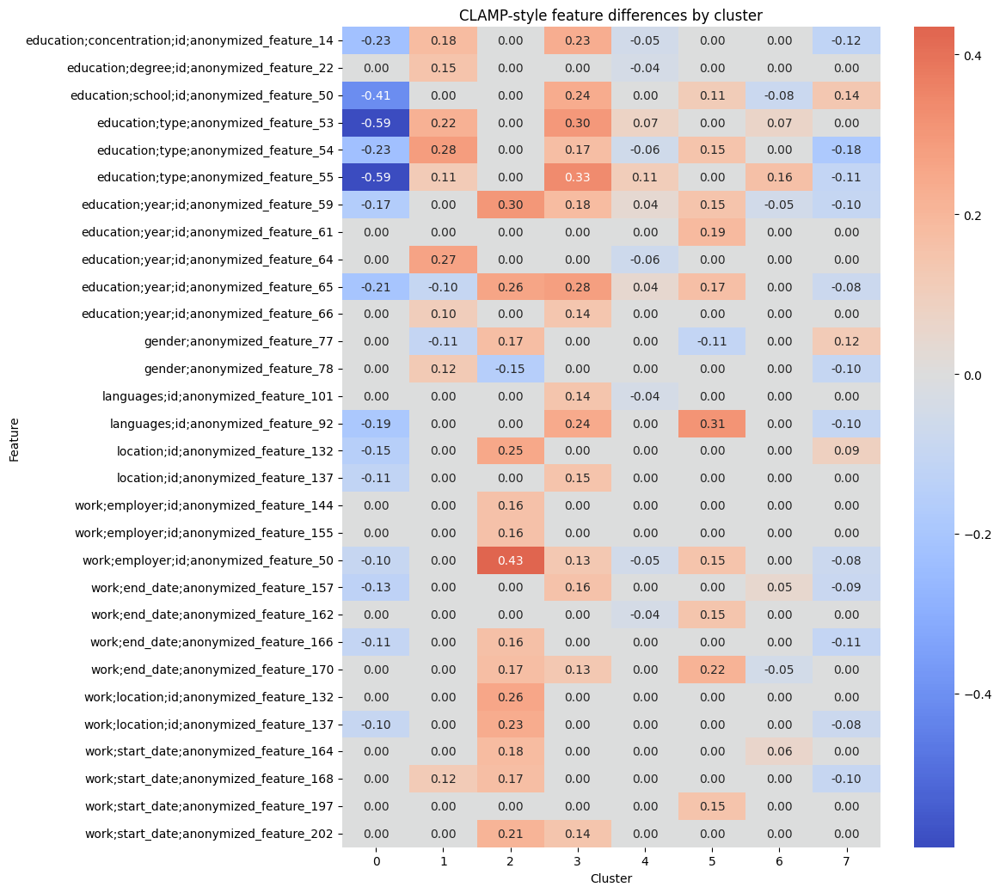


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.387387                          0.38649          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         9           4  

=== Decision tree rules ===
|--- education;type;anonymized_feature_53 <= 0.50
|   |--- education;type;anonymized_feature_55 <= 0.50
|   |   |--- gender;anonymized_feature_77 <= 0.50
|   |   |   |--- class: 0
|   |   |--- gender;anonymized_feature_77 >  0.50
|   |   |   |--- class: 0
|   |--- education;type;anonymized_feature_55 >  0.50
|   |   |--- class: 6
|--- education;type;anonymized_feature_53 >  0.50
|   |--- work;employer;id;anonymized_feature_50 <= 0.50
|   |   |--- education;type;anonymized_feature_54 <= 0.50
|   |   |   |--- education;type;anonymized_feature_55 <= 0.50
|   |   |   |   |--- class: 7
|   |   |   |--- education;type;anonymized_feature_55 >  0.50
|   |   |   |   |--- class: 4
|   |   |--- edu

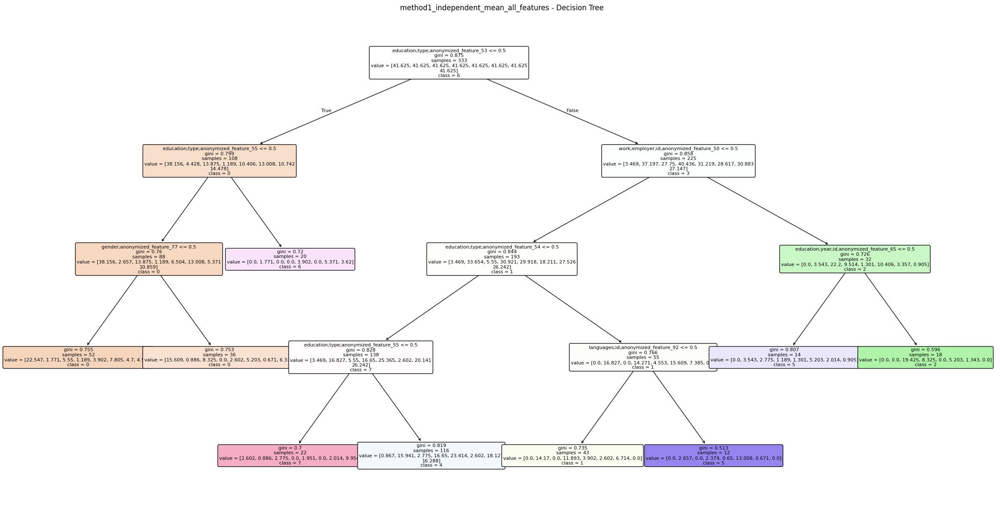


=== Decision tree feature importance ===
education;type;anonymized_feature_53       0.260959
work;employer;id;anonymized_feature_50     0.203375
education;type;anonymized_feature_55       0.179272
education;type;anonymized_feature_54       0.141704
languages;id;anonymized_feature_92         0.134393
education;year;id;anonymized_feature_65    0.068417
gender;anonymized_feature_77               0.011881
dtype: float64


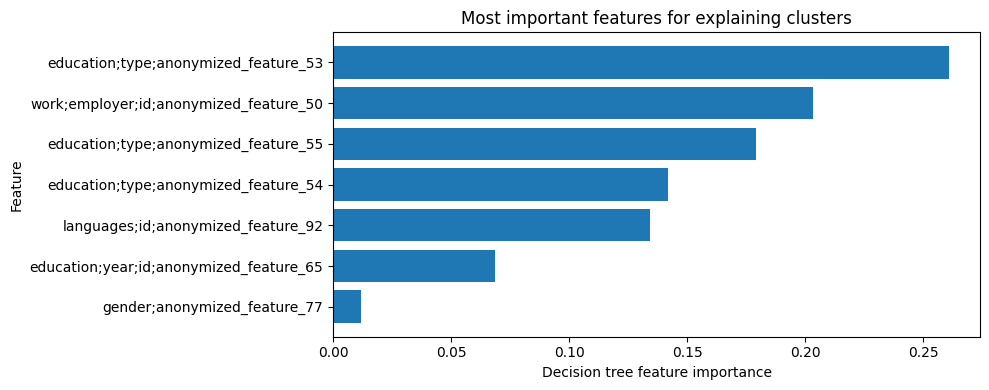


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.208333  0.000000  0.041667  0.083333  0.062500  0.000000  0.562500   
1        0.255319  0.276596  0.021277  0.021277  0.085106  0.000000  0.297872   
2        0.733333  0.000000  0.133333  0.000000  0.000000  0.066667  0.000000   
3        0.400000  0.000000  0.228571  0.028571  0.028571  0.000000  0.228571   
4        0.328125  0.046875  0.078125  0.062500  0.062500  0.015625  0.328125   
5        0.750000  0.000000  0.062500  0.062500  0.000000  0.000000  0.062500   
6        0.258065  0.080645  0.064516  0.032258  0.096774  0.064516  0.322581   
7        0.391304  0.000000  0.065217  0.043478  0.021739  0.086957  0.347826   

         circleOverlap  
cluster                 
0             0.041667  
1             0.042553  
2             0.066667  
3             0.085714  


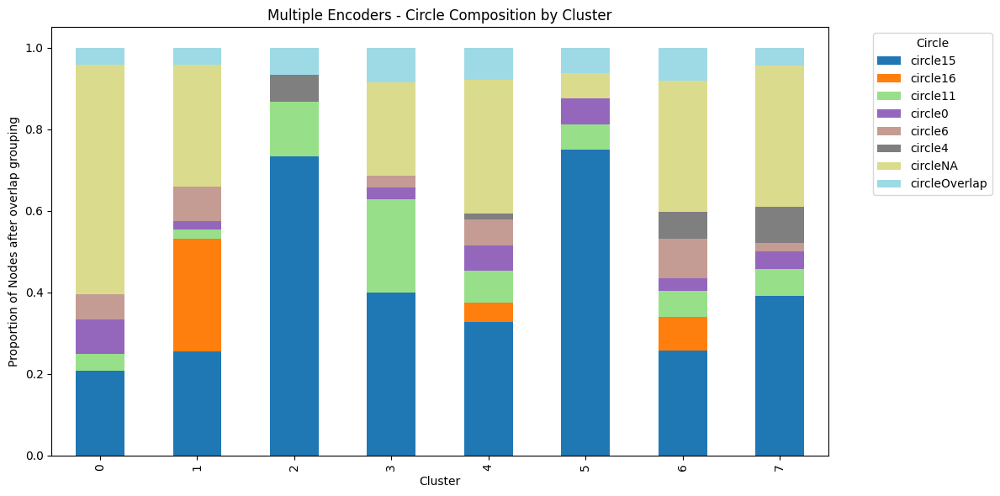

In [28]:
# ============================================================
# CELL 22 - MODEL 1A - Independent DGI with all features
# ============================================================

diagnostics_method1_all, result_method1_all = (
    run_final_dataset_analysis(
        dataset_name="method1_independent_mean_all_features",
        n_clusters=K_ALL_FEATURES,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: method1_independent_mean_circles_only
Embeddings shape: (333, 64)
Features shape: (333, 7)
Membership shape: (333, 8)

Running diagnostics for: method1_independent_mean_circles_only

=== method1_independent_mean_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.720972        1165.779983        0.430186                 2   
3     0.591102        1403.201619        0.538669                 3   
6     0.582382        1866.426006        0.507714                 4   
9     0.557737        1970.113675        0.512458                 5   
12    0.553423        2550.455952        0.520039                 6   
15    0.554569        2789.513532        0.515819                 7   
18    0.538827        3305.902293        0.536088                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3         ok   
6        

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


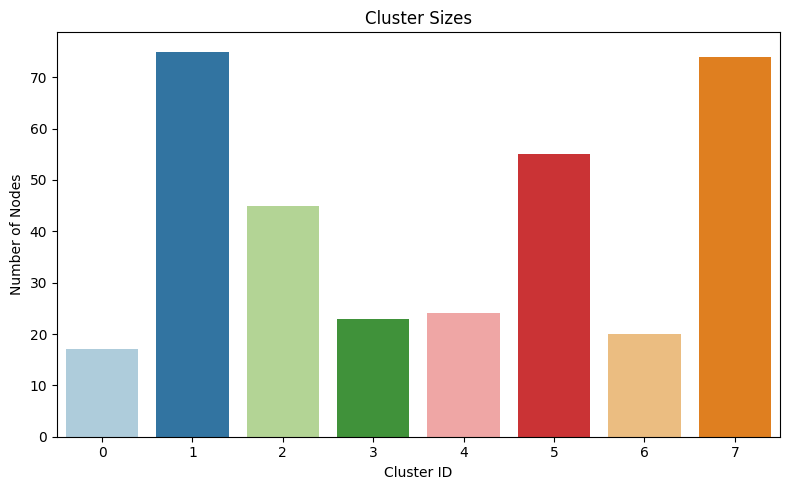


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               1.251433         1.302442         1.460177         1.426269   
1               0.387198         0.418628         0.481206         0.445859   
2               0.694126         0.738196         0.836712         0.797890   
3               1.553291         1.635615         1.831889         1.766529   
4               0.980875         1.032353         1.153236         1.110880   
5               0.533600         0.575262         0.661232         0.611271   
6               1.832311         1.924961         2.159284         2.093523   
7               0.235822         0.252446         0.291047         0.273276   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               1.488974 

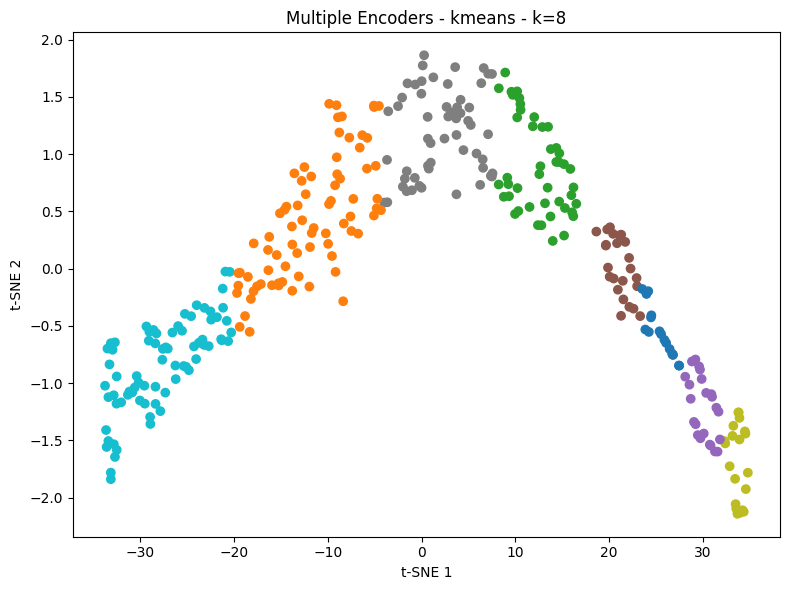

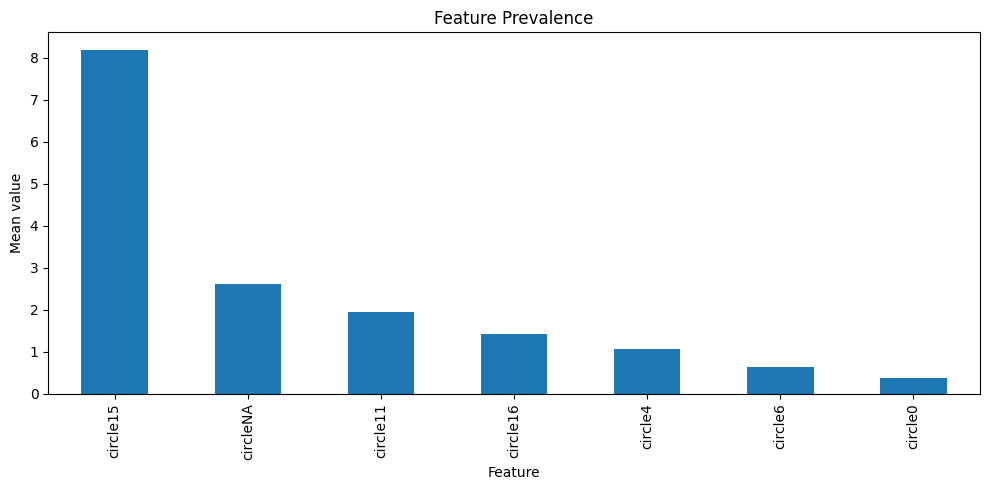


=== Cluster feature profiles ===
          circle15  circle16   circle11   circle0   circle6   circle4  \
cluster                                                                 
0        18.764706  1.000000   4.294118  0.411765  0.000000  2.588235   
1         1.706667  0.266667   0.360000  0.293333  0.920000  0.093333   
2         7.844444  4.000000   1.133333  0.200000  0.466667  0.733333   
3        24.956522  0.913043   7.782609  1.000000  0.000000  3.956522   
4        12.458333  0.666667   2.875000  0.583333  0.000000  1.958333   
5         3.436364  3.054545   0.509091  0.145455  2.054545  0.090909   
6        41.300000  2.150000  10.800000  1.250000  0.000000  6.300000   
7         0.540541  0.121622   0.054054  0.229730  0.175676  0.027027   

         circleNA  
cluster            
0        1.588235  
1        3.040000  
2        3.133333  
3        1.913043  
4        1.750000  
5        4.200000  
6        4.300000  
7        0.932432  


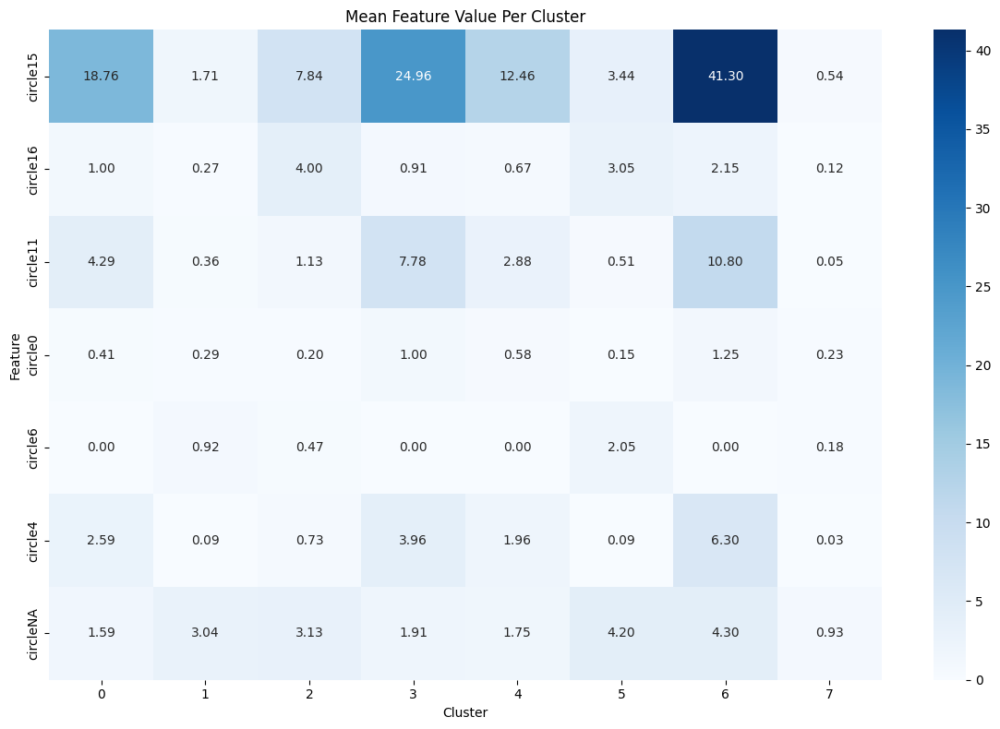

Features with > 30% prevalence/value in at least one cluster:
          circle15  circle16   circle11   circle0   circle6   circle4  \
cluster                                                                 
0        18.764706  1.000000   4.294118  0.411765  0.000000  2.588235   
1         1.706667  0.266667   0.360000  0.293333  0.920000  0.093333   
2         7.844444  4.000000   1.133333  0.200000  0.466667  0.733333   
3        24.956522  0.913043   7.782609  1.000000  0.000000  3.956522   
4        12.458333  0.666667   2.875000  0.583333  0.000000  1.958333   
5         3.436364  3.054545   0.509091  0.145455  2.054545  0.090909   
6        41.300000  2.150000  10.800000  1.250000  0.000000  6.300000   
7         0.540541  0.121622   0.054054  0.229730  0.175676  0.027027   

         circleNA  
cluster            
0        1.588235  
1        3.040000  
2        3.133333  
3        1.913043  
4        1.750000  
5        4.200000  
6        4.300000  
7        0.932432  

=== To

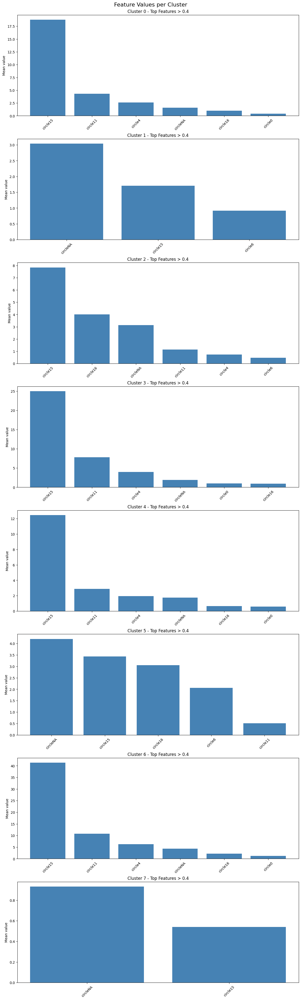


=== CLAMP prototypes ===
    cluster   feature  cluster_prevalence  global_prevalence  prevalence_diff  \
0         0  circle15           18.764706           8.192192        10.572514   
1         0  circle11            4.294118           1.942943         2.351175   
2         0   circle4            2.588235           1.066066         1.522169   
3         0  circleNA            1.588235           2.606607        -1.018371   
4         0   circle6            0.000000           0.648649        -0.648649   
5         0  circle16            1.000000           1.423423        -0.423423   
6         0   circle0            0.411765           0.375375         0.036389   
7         1  circle15            1.706667           8.192192        -6.485526   
8         1  circle11            0.360000           1.942943        -1.582943   
9         1  circle16            0.266667           1.423423        -1.156757   
10        1   circle4            0.093333           1.066066        -0.972733   
11

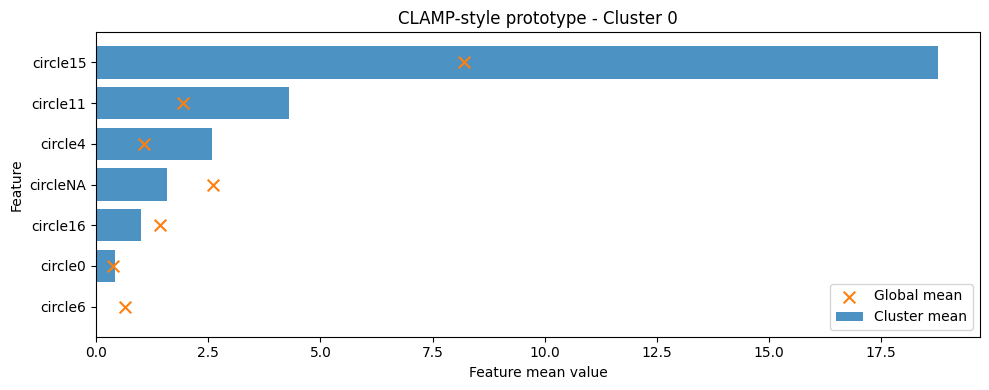

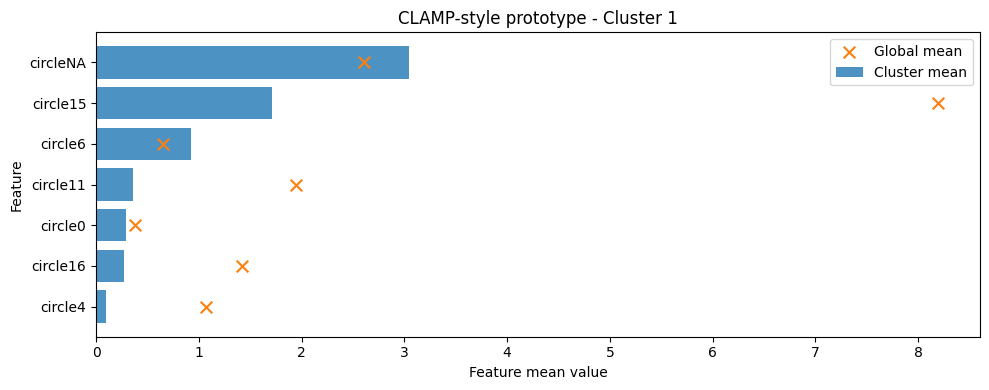

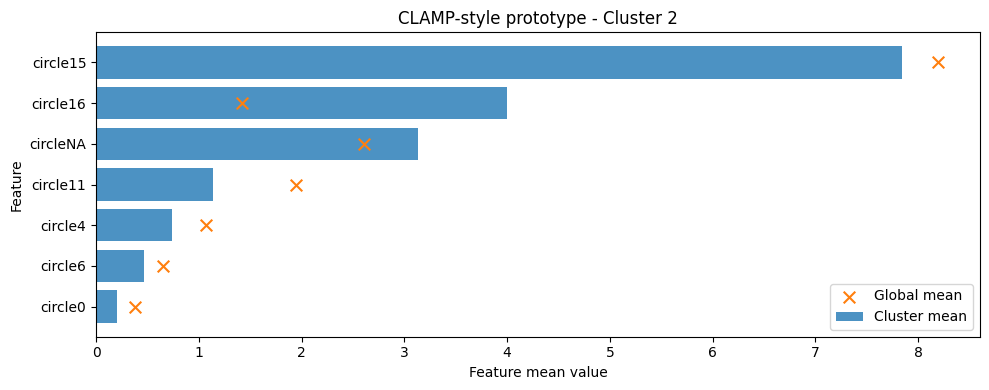

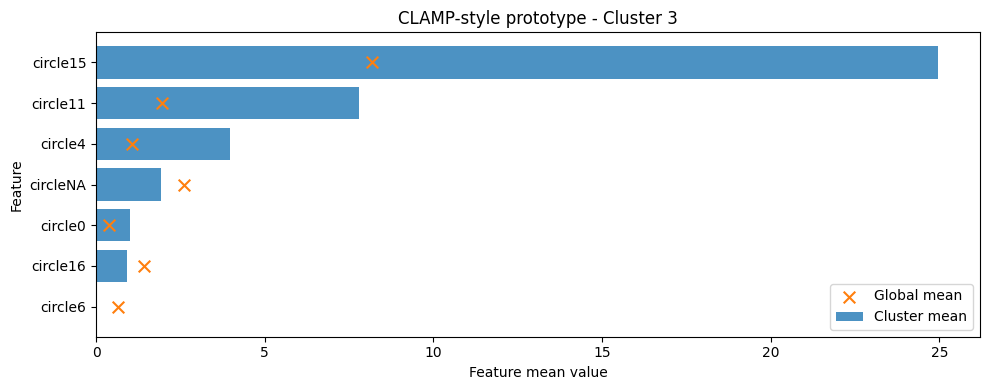

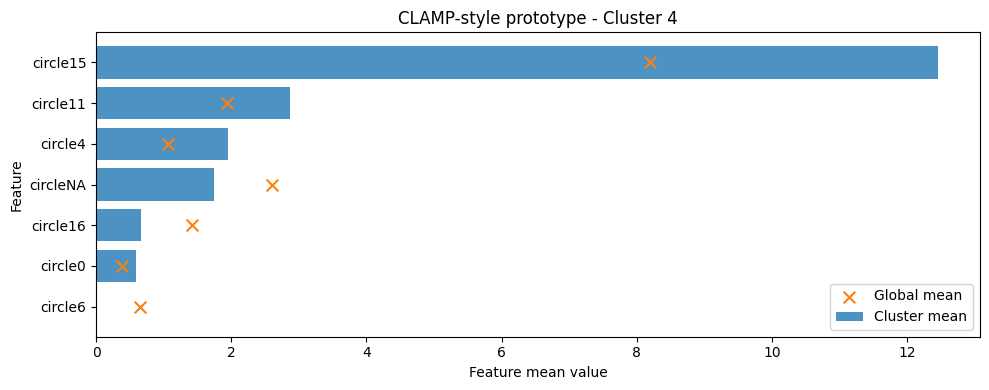

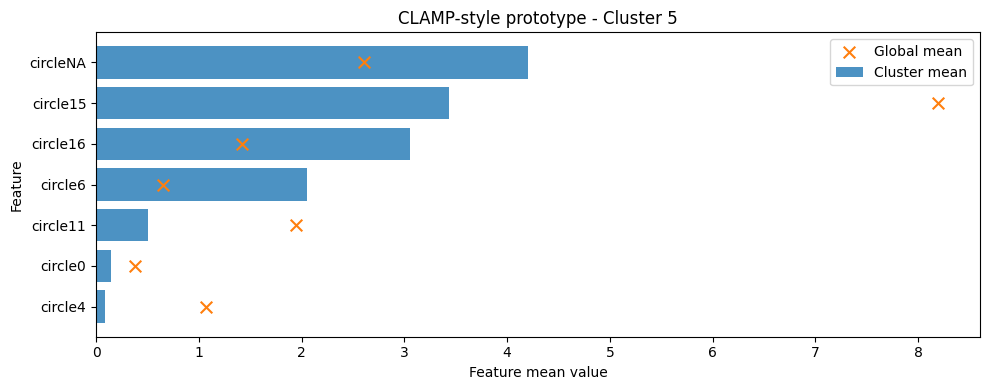

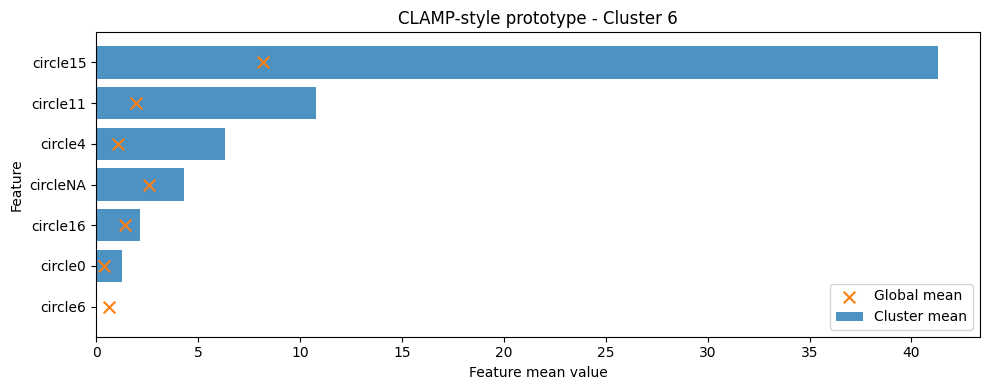

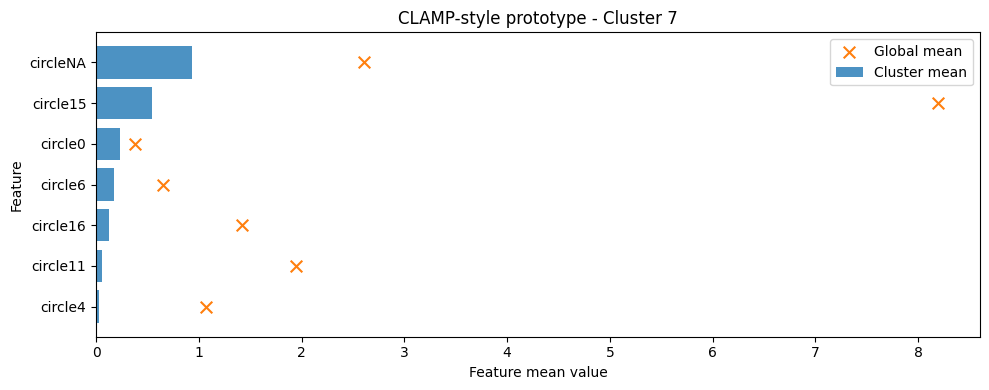

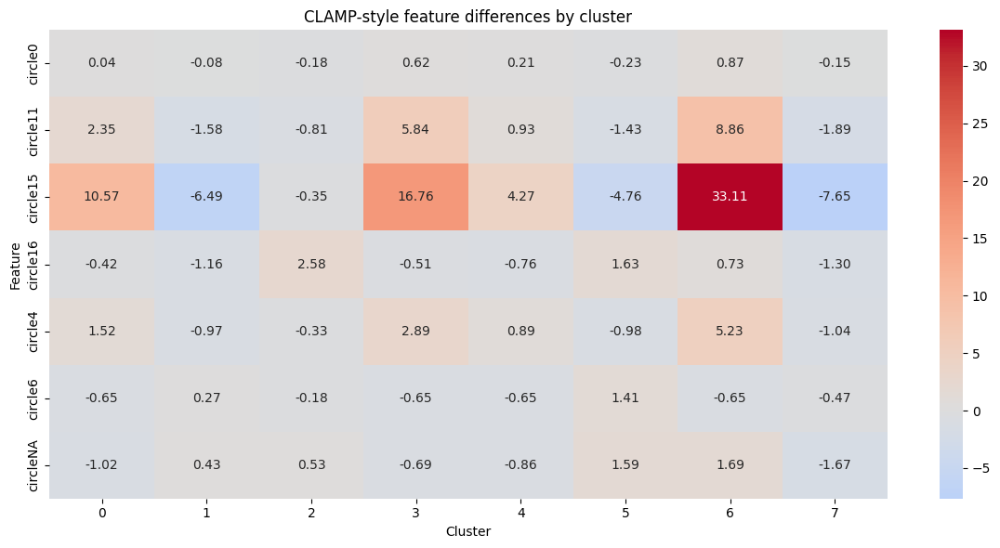


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.693694                         0.696626          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        10           4  

=== Decision tree rules ===
|--- circle15 <= 30.50
|   |--- circle15 <= 6.50
|   |   |--- circleNA <= 2.50
|   |   |   |--- circle15 <= 2.50
|   |   |   |   |--- class: 7
|   |   |   |--- circle15 >  2.50
|   |   |   |   |--- class: 1
|   |   |--- circleNA >  2.50
|   |   |   |--- circle16 <= 3.50
|   |   |   |   |--- class: 1
|   |   |   |--- circle16 >  3.50
|   |   |   |   |--- class: 5
|   |--- circle15 >  6.50
|   |   |--- circle15 <= 16.50
|   |   |   |--- circle4 <= 1.50
|   |   |   |   |--- class: 2
|   |   |   |--- circle4 >  1.50
|   |   |   |   |--- class: 4
|   |   |--- circle15 >  16.50
|   |   |   |--- circle11 <= 7.50
|   |   |   |   |--- class: 0
|   |   |   |--- circle11 >  7.50
|   |   |   |   |--

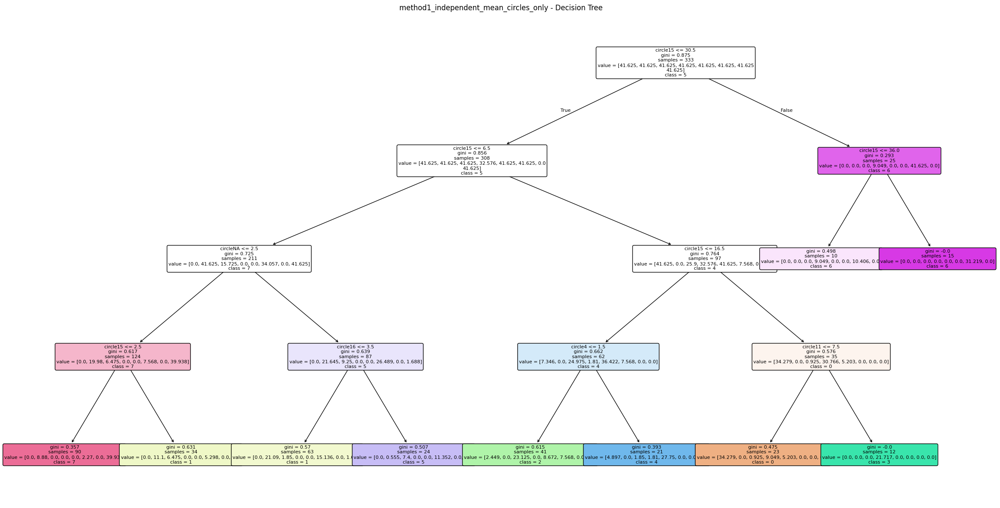


=== Decision tree feature importance ===
circle15    0.689676
circle11    0.114228
circleNA    0.084772
circle4     0.076548
circle16    0.034775
dtype: float64


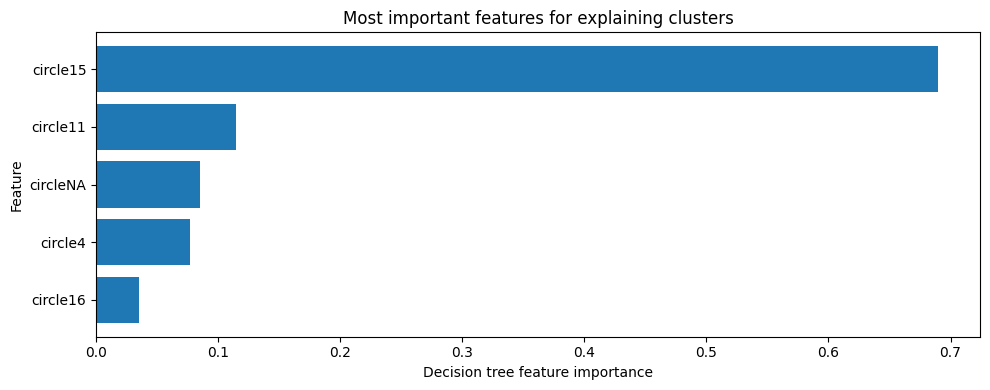


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.705882  0.000000  0.117647  0.058824  0.000000  0.058824  0.058824   
1        0.266667  0.013333  0.040000  0.026667  0.053333  0.013333  0.560000   
2        0.377778  0.133333  0.000000  0.044444  0.044444  0.111111  0.200000   
3        0.565217  0.000000  0.304348  0.000000  0.000000  0.000000  0.043478   
4        0.416667  0.000000  0.291667  0.000000  0.000000  0.083333  0.083333   
5        0.200000  0.200000  0.036364  0.018182  0.145455  0.000000  0.290909   
6        0.750000  0.000000  0.100000  0.000000  0.000000  0.050000  0.000000   
7        0.216216  0.040541  0.040541  0.121622  0.067568  0.000000  0.486486   

         circleOverlap  
cluster                 
0             0.000000  
1             0.026667  
2             0.088889  
3             0.086957  


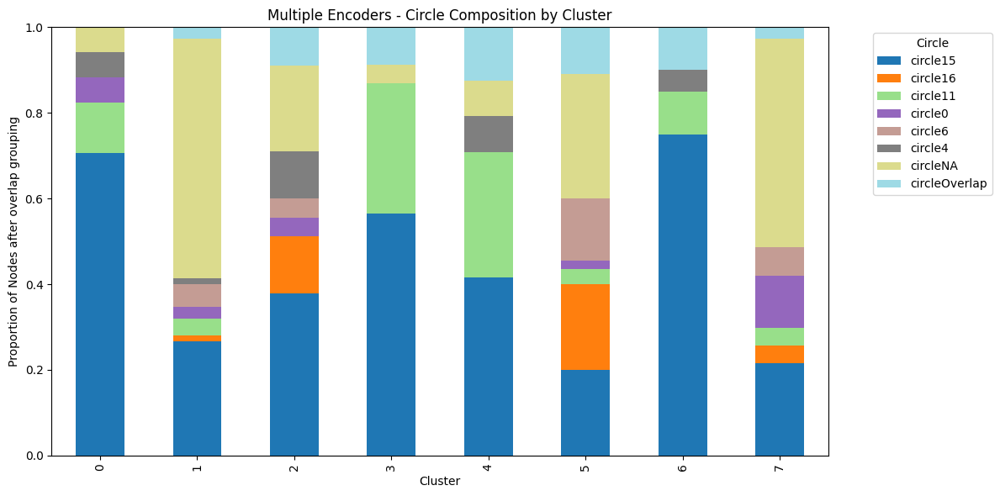

In [29]:
# ============================================================
# CELL 23 - MODEL 1B - Independent DGI with circles-only ARD
# ============================================================

diagnostics_method1_circles, result_method1_circles = (
    run_final_dataset_analysis(
        dataset_name="method1_independent_mean_circles_only",
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: method1_independent_mean_graph_structure_identity_only
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method1_independent_mean_graph_structure_identity_only

=== method1_independent_mean_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.402895         387.368528        0.886893                 2   
3     0.405652         457.982711        0.877737                 3   
6     0.327346         380.782573        1.157061                 4   
9     0.237255         316.489687        1.490672                 5   
12    0.180271         271.243955        1.688555                 6   
15    0.161880         237.199710        1.606250                 7   
18    0.137371         210.712161        1.818915                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3       

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


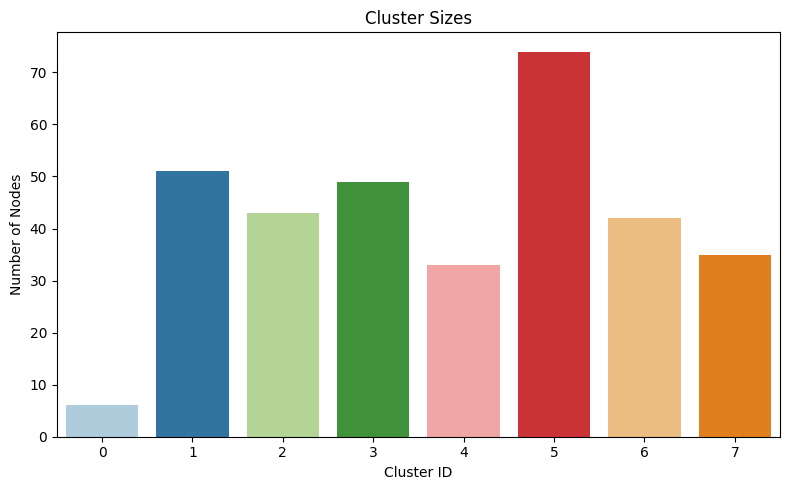


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.030020         0.030014         0.030308         0.029374   
1               0.020775         0.020239         0.021238         0.020826   
2               0.023401         0.022903         0.024182         0.023277   
3               0.018156         0.018059         0.018238         0.017567   
4               0.026019         0.025635         0.027438         0.026575   
5               0.022011         0.021189         0.022569         0.021687   
6               0.019344         0.019467         0.019230         0.019128   
7               0.025106         0.025187         0.025330         0.024814   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.026816 

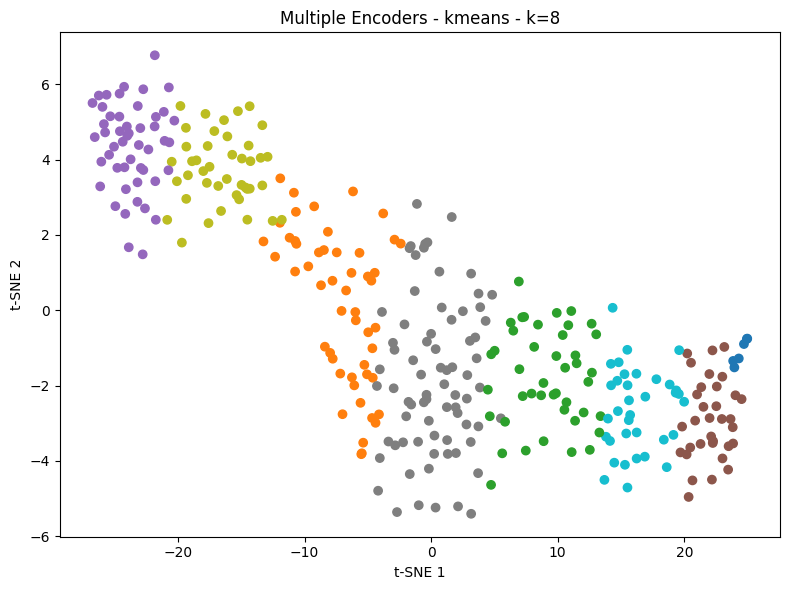

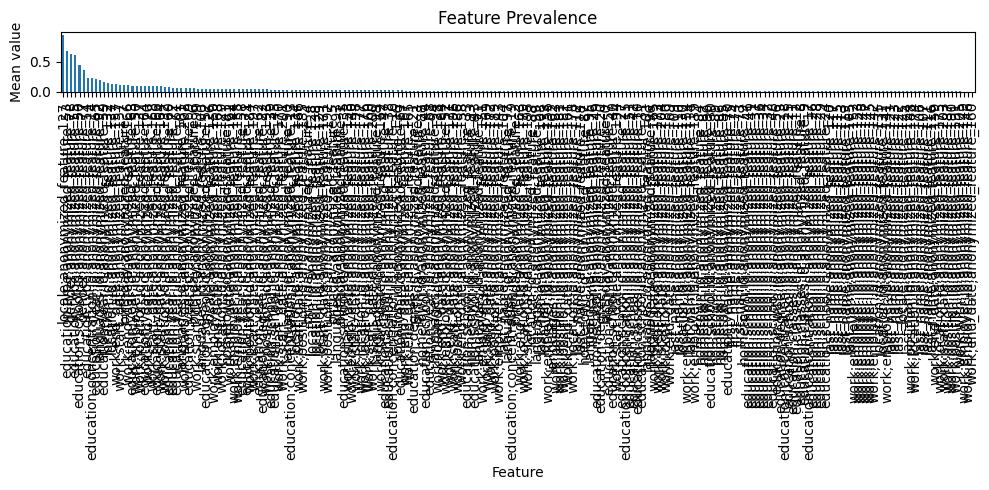


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.000000   
1                             0.000000                       0.000000   
2                             0.023256                       0.046512   
3                             0.000000                       0.000000   
4                             0.000000                       0.030303   
5                             0.040541                       0.040541   
6                             0.000000                       0.000000   
7                             0.000000                       0.057143   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.000000                       0.000000   
1               

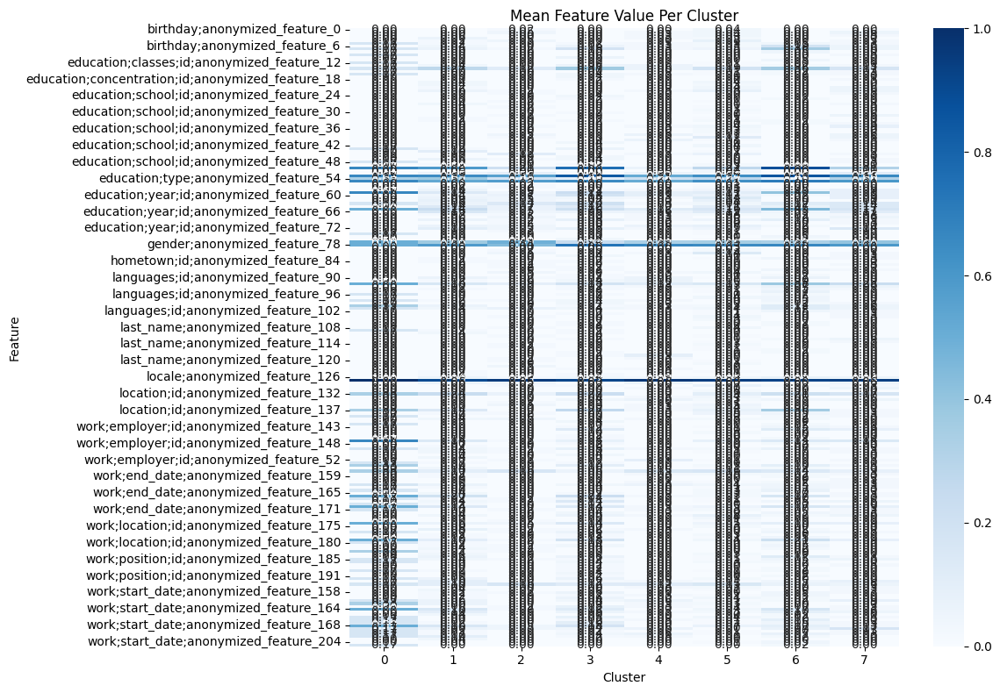

Features with > 30% prevalence/value in at least one cluster:
         birthday;anonymized_feature_7  \
cluster                                  
0                             0.166667   
1                             0.058824   
2                             0.023256   
3                             0.183673   
4                             0.030303   
5                             0.054054   
6                             0.357143   
7                             0.057143   

         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.166667   
1                                                0.274510   
2                                                0.116279   
3                                                0.367347   
4                                                0.060606   
5                                                0.189189   
6                            

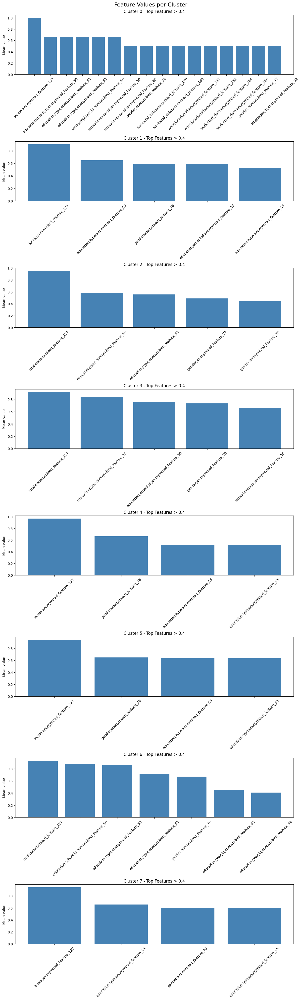


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0            work;employer;id;anonymized_feature_50   
1         0           education;year;id;anonymized_feature_59   
2         0           work;location;id;anonymized_feature_132   
3         0            work;start_date;anonymized_feature_164   
4         0            work;start_date;anonymized_feature_168   
5         0              work;end_date;anonymized_feature_170   
6         0           work;location;id;anonymized_feature_137   
7         0              work;end_date;anonymized_feature_166   
8         0           work;position;id;anonymized_feature_182   
9         0                languages;id;anonymized_feature_92   
10        0            work;start_date;anonymized_feature_162   
11        0           education;year;id;anonymized_feature_65   
12        0           work;employer;id;anonymized_feature_155   
13        0               languages;id;anonymized_feature_100   

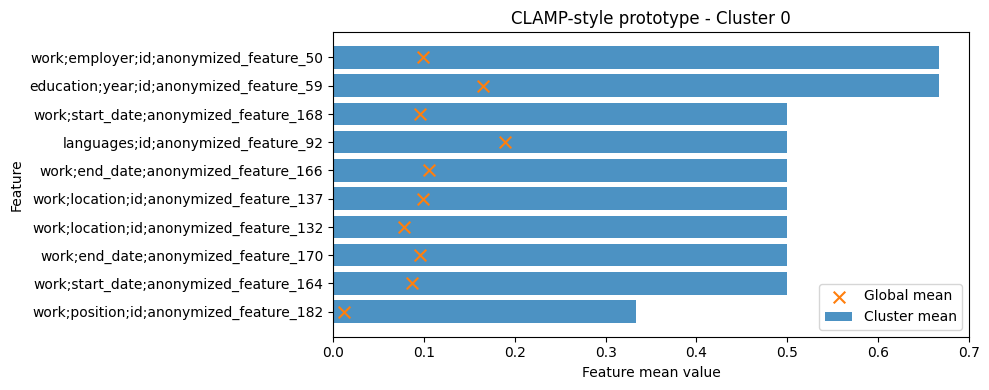

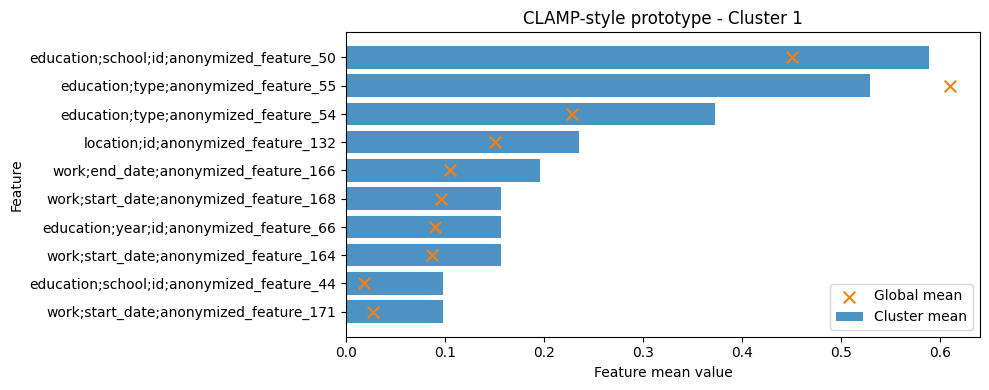

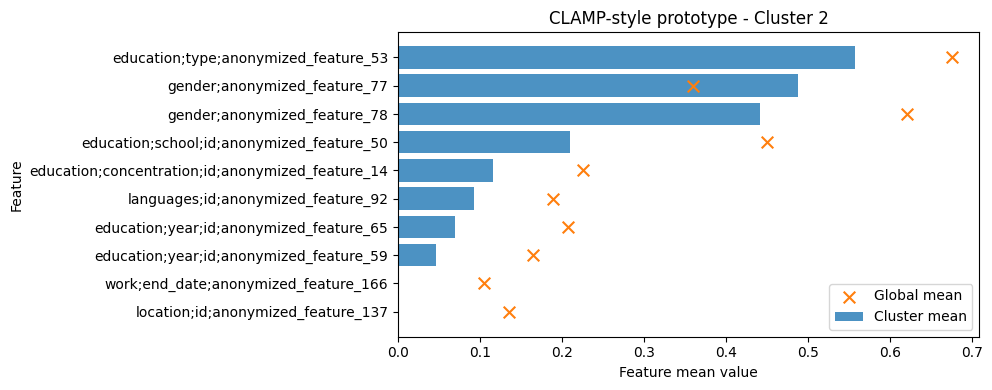

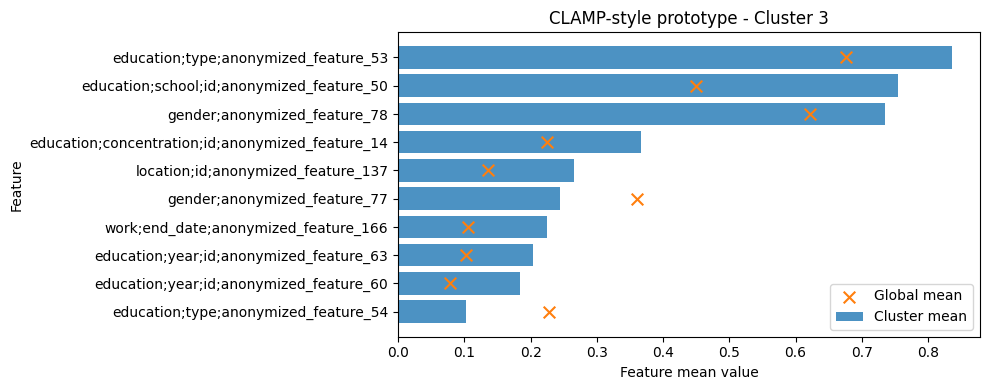

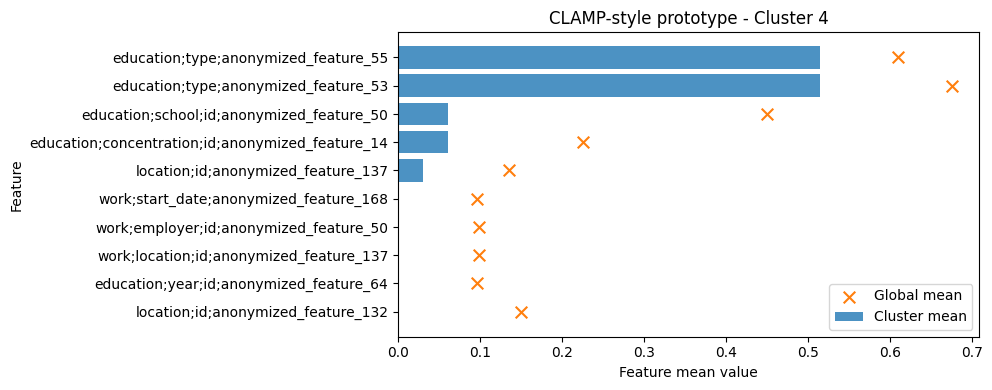

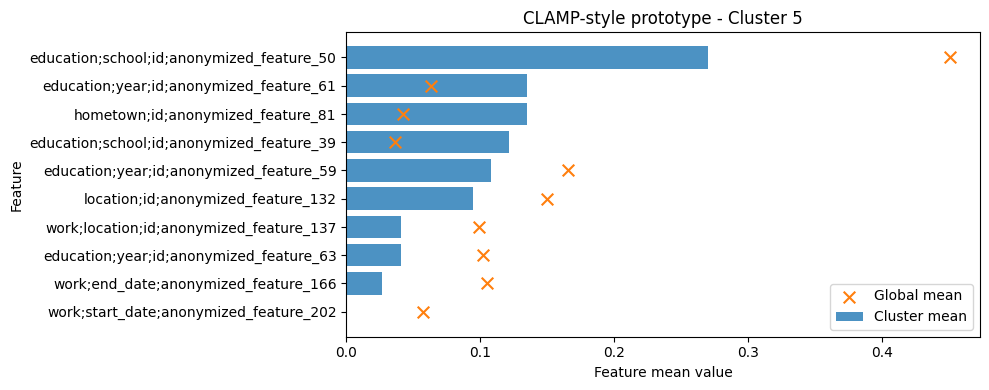

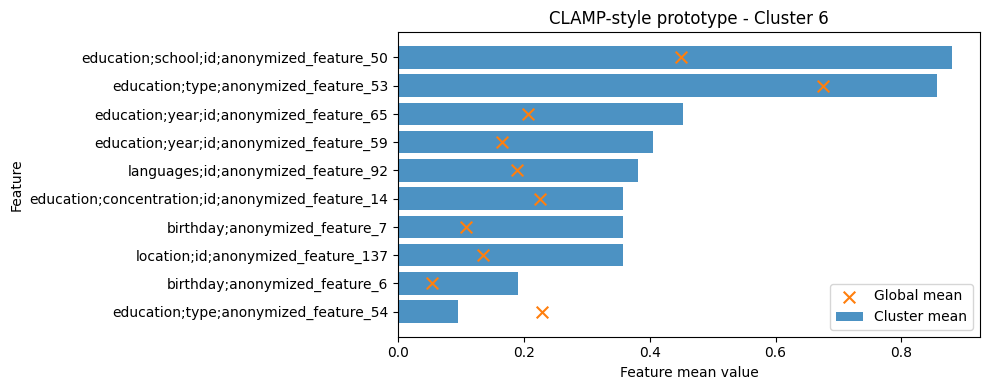

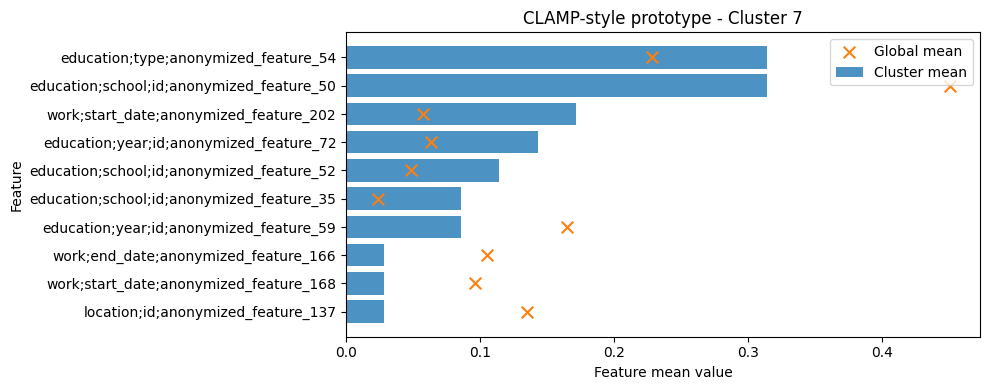

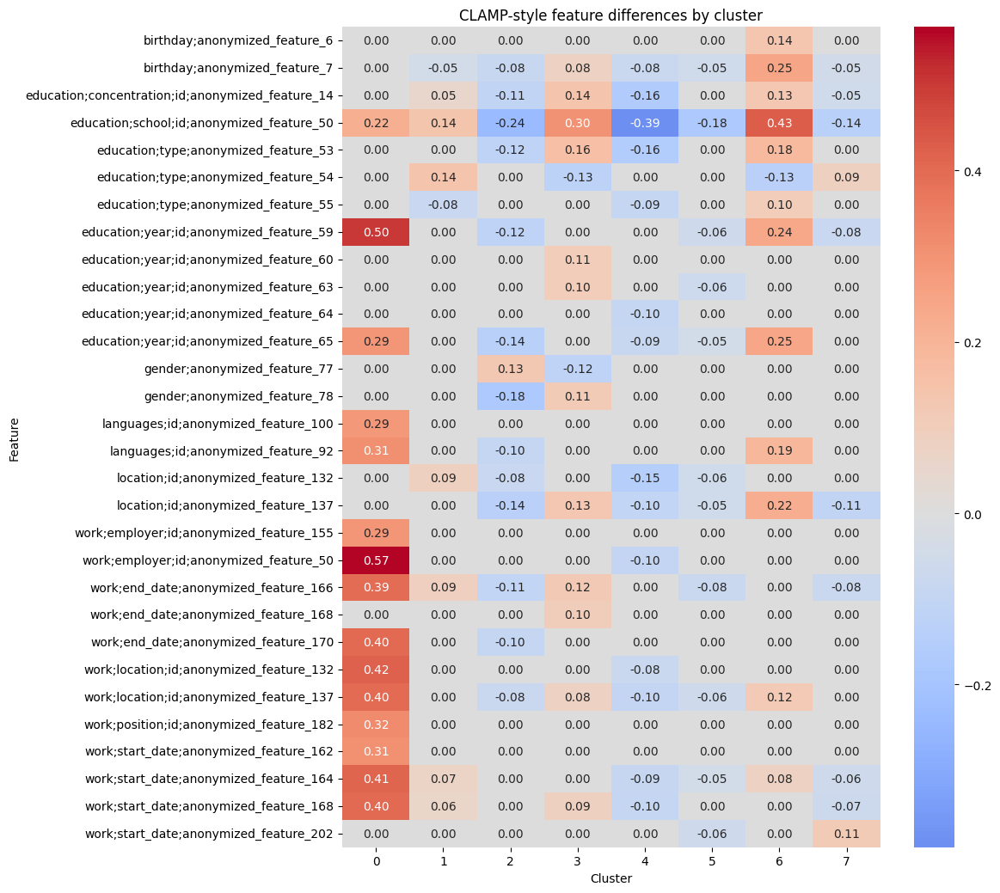


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.291291                         0.360772          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        10           4  

=== Decision tree rules ===
|--- education;school;id;anonymized_feature_50 <= 0.50
|   |--- education;school;id;anonymized_feature_39 <= 0.50
|   |   |--- education;year;id;anonymized_feature_66 <= 0.50
|   |   |   |--- education;type;anonymized_feature_55 <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- education;type;anonymized_feature_55 >  0.50
|   |   |   |   |--- class: 4
|   |   |--- education;year;id;anonymized_feature_66 >  0.50
|   |   |   |--- class: 7
|   |--- education;school;id;anonymized_feature_39 >  0.50
|   |   |--- class: 5
|--- education;school;id;anonymized_feature_50 >  0.50
|   |--- work;employer;id;anonymized_feature_50 <= 0.50
|   |   |--- education;type;anonymized_feature_54 <= 0.50


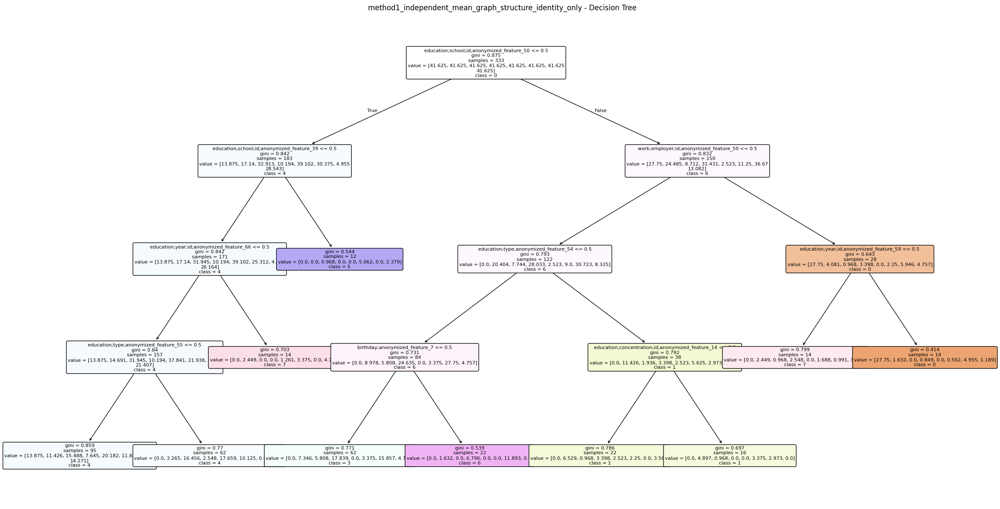


=== Decision tree feature importance ===
work;employer;id;anonymized_feature_50              0.288498
education;school;id;anonymized_feature_50           0.269217
education;year;id;anonymized_feature_59             0.140326
education;type;anonymized_feature_54                0.099531
education;school;id;anonymized_feature_39           0.051629
education;type;anonymized_feature_55                0.045666
education;year;id;anonymized_feature_66             0.041646
birthday;anonymized_feature_7                       0.035998
education;concentration;id;anonymized_feature_14    0.027488
dtype: float64


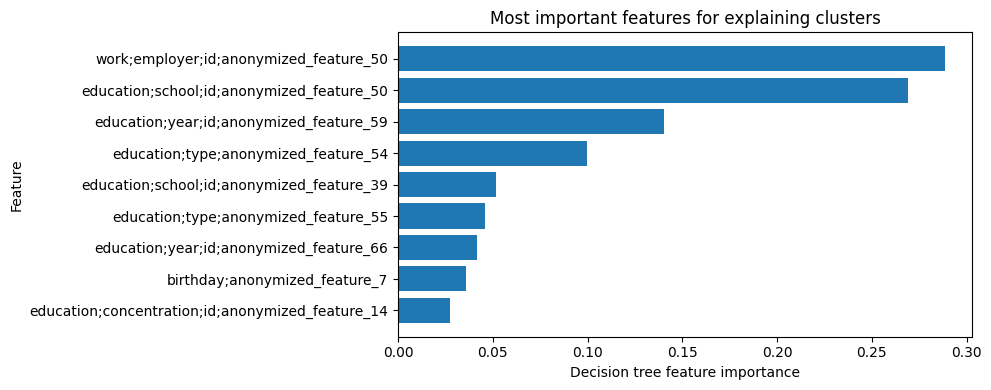


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.833333  0.000000  0.166667  0.000000  0.000000  0.000000  0.000000   
1        0.313725  0.176471  0.019608  0.039216  0.000000  0.000000  0.392157   
2        0.209302  0.023256  0.069767  0.116279  0.069767  0.000000  0.465116   
3        0.530612  0.020408  0.163265  0.020408  0.000000  0.163265  0.040816   
4        0.151515  0.030303  0.030303  0.060606  0.090909  0.000000  0.575758   
5        0.243243  0.094595  0.013514  0.013514  0.148649  0.000000  0.405405   
6        0.523810  0.023810  0.214286  0.071429  0.000000  0.023810  0.047619   
7        0.371429  0.028571  0.057143  0.028571  0.057143  0.028571  0.400000   

         circleOverlap  
cluster                 
0             0.000000  
1             0.058824  
2             0.046512  
3             0.061224  


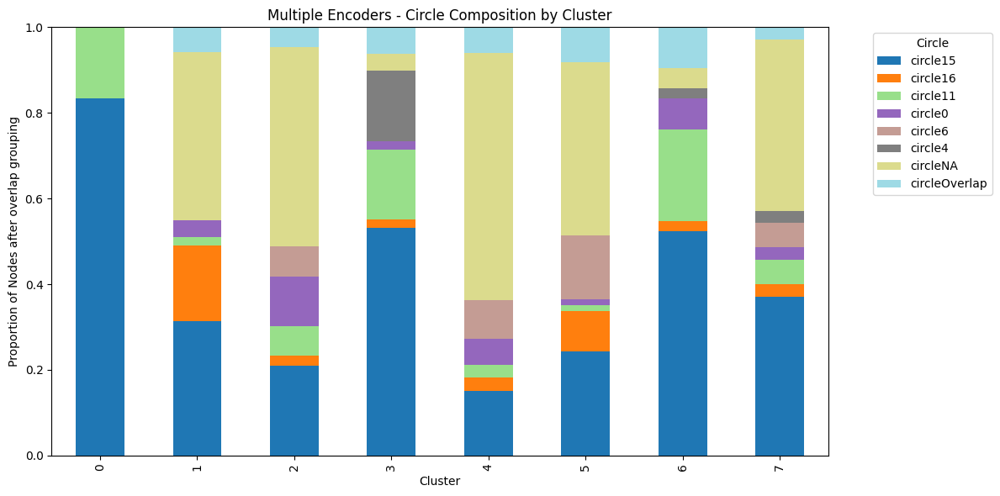

In [30]:
# ============================================================
# CELL 24 - MODEL 1C - Independent DGI with structure only
# ============================================================

diagnostics_method1_structure, result_method1_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method1_independent_mean_"
            "graph_structure_identity_only"
        ),
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: method2_shared_sequential_mean_all_features
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method2_shared_sequential_mean_all_features

=== method2_shared_sequential_mean_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.180914          73.464883        1.325048                 2   
3     0.221389          60.861053        1.987440                 3   
6     0.234022          55.915528        1.623884                 4   
9     0.218432          55.528301        1.711908                 5   
12    0.180946          50.917755        1.664299                 6   
15    0.195253          46.834933        1.645534                 7   
18    0.200458          42.763357        1.836133                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3    

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


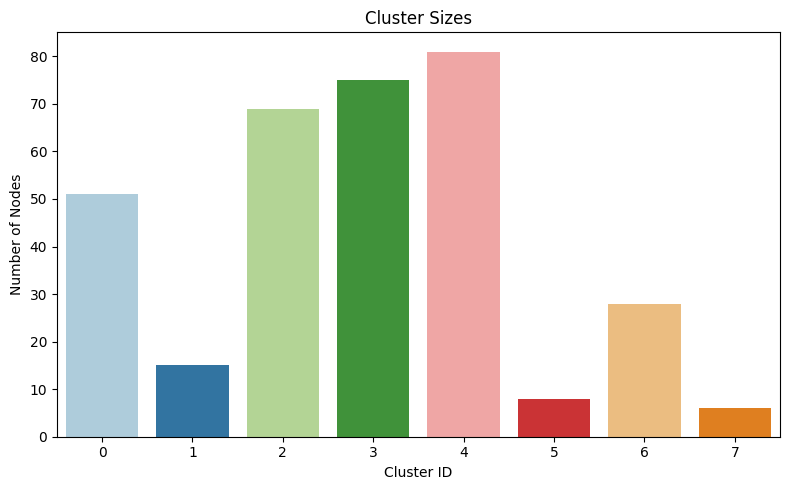


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.223413              0.0         0.011696         0.087833   
1               0.050873              0.0         0.083992         0.091477   
2               0.228071              0.0         0.020134         0.143687   
3               0.172470              0.0         0.014886         0.131224   
4               0.170637              0.0         0.036063         0.079697   
5               0.125043              0.0         0.284001         0.123952   
6               0.104414              0.0         0.032150         0.065677   
7               0.108321              0.0         0.152302         0.011118   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.055350 

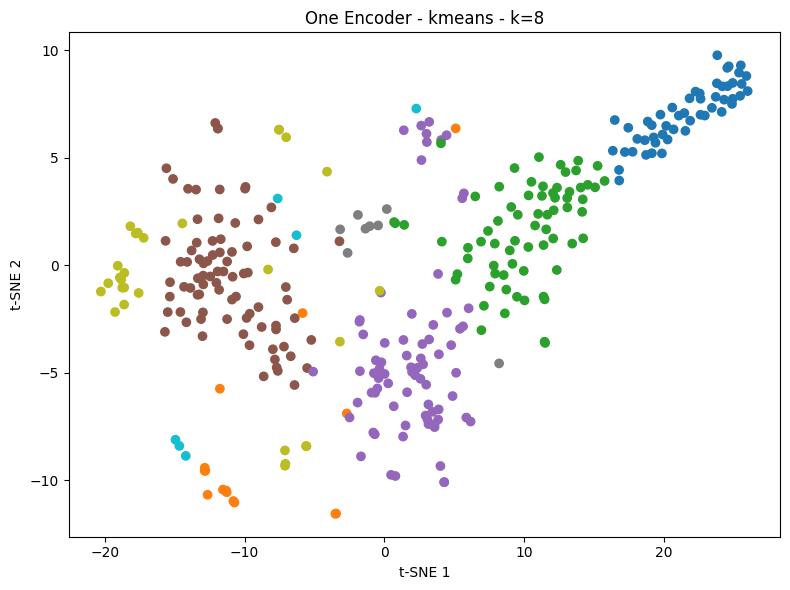

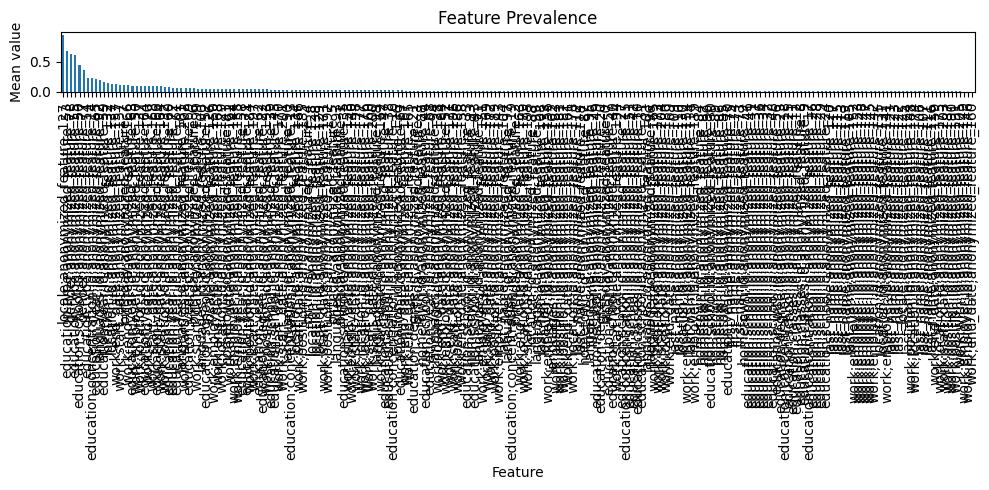


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.000000   
1                             0.000000                       0.066667   
2                             0.000000                       0.000000   
3                             0.000000                       0.000000   
4                             0.049383                       0.061728   
5                             0.000000                       0.000000   
6                             0.000000                       0.035714   
7                             0.000000                       0.166667   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.000000                       0.000000   
1               

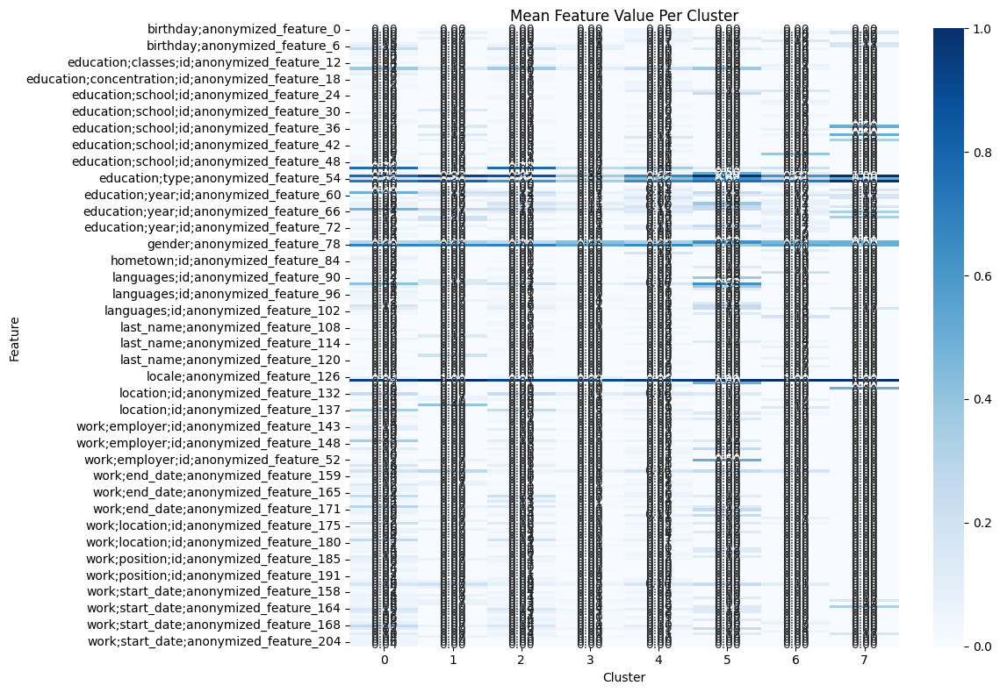

Features with > 30% prevalence/value in at least one cluster:
         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.372549   
1                                                0.133333   
2                                                0.362319   
3                                                0.093333   
4                                                0.222222   
5                                                0.375000   
6                                                0.035714   
7                                                0.000000   

         education;school;id;anonymized_feature_35  \
cluster                                              
0                                         0.000000   
1                                         0.133333   
2                                         0.000000   
3                                         0.000000   
4  

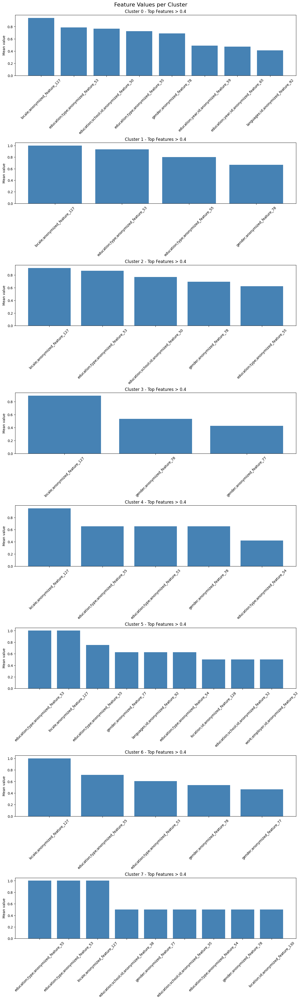


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0           education;year;id;anonymized_feature_59   
1         0         education;school;id;anonymized_feature_50   
2         0           education;year;id;anonymized_feature_65   
3         0            work;employer;id;anonymized_feature_50   
4         0                languages;id;anonymized_feature_92   
5         0                location;id;anonymized_feature_137   
6         0              work;end_date;anonymized_feature_170   
7         0            work;start_date;anonymized_feature_168   
8         0           work;location;id;anonymized_feature_137   
9         0  education;concentration;id;anonymized_feature_14   
10        0           work;location;id;anonymized_feature_132   
11        0              work;end_date;anonymized_feature_166   
12        0               languages;id;anonymized_feature_100   
13        0                     birthday;anonymized_feature_7   

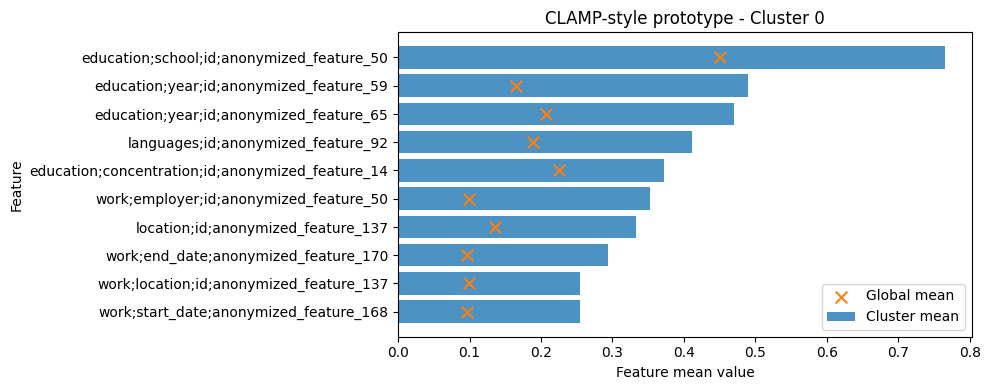

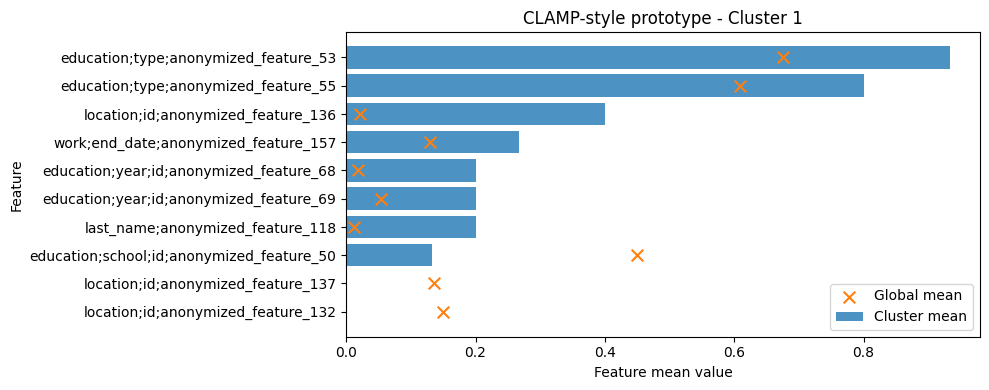

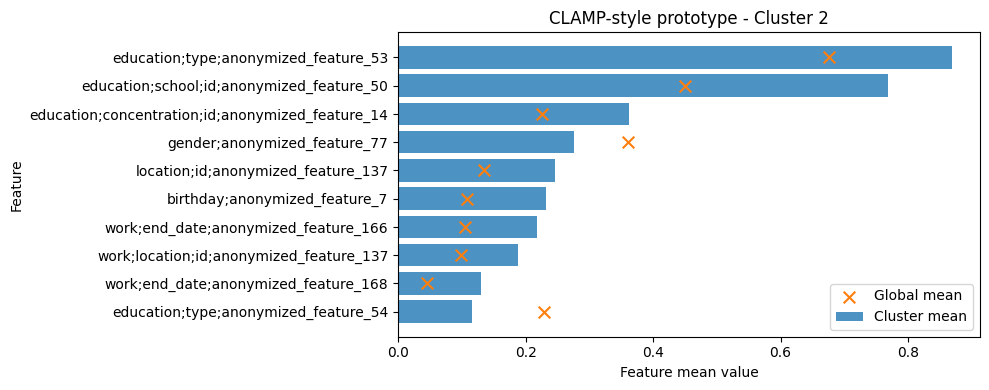

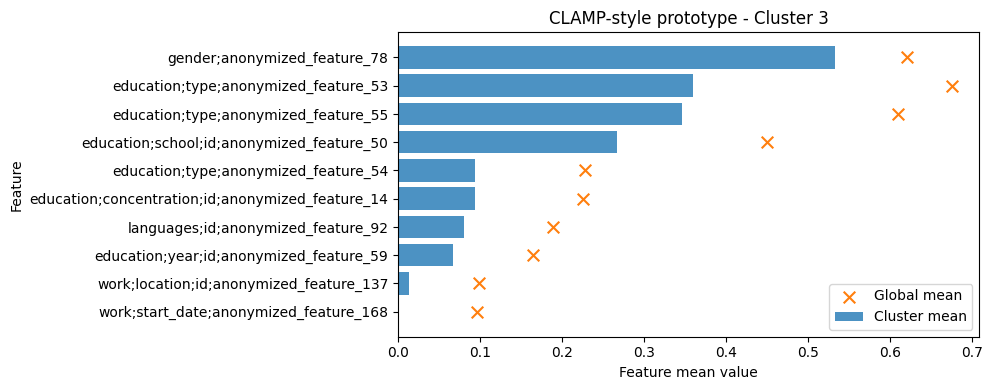

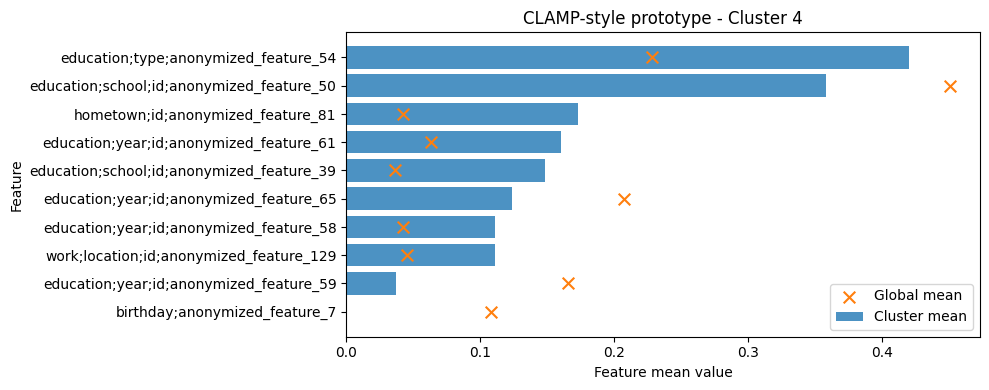

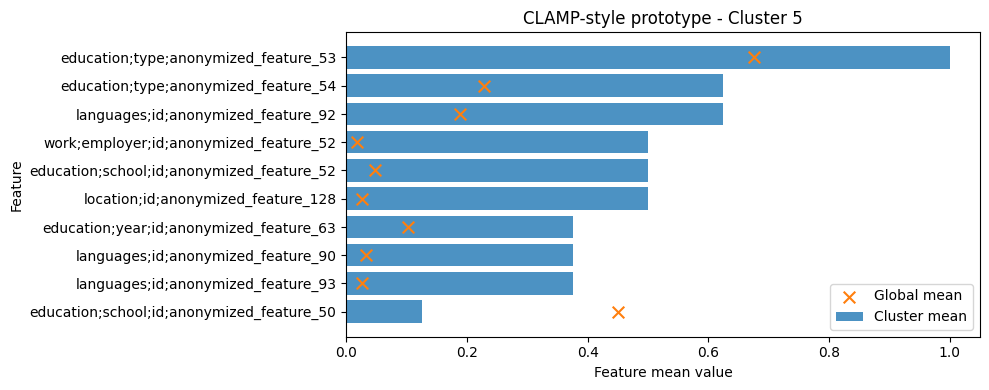

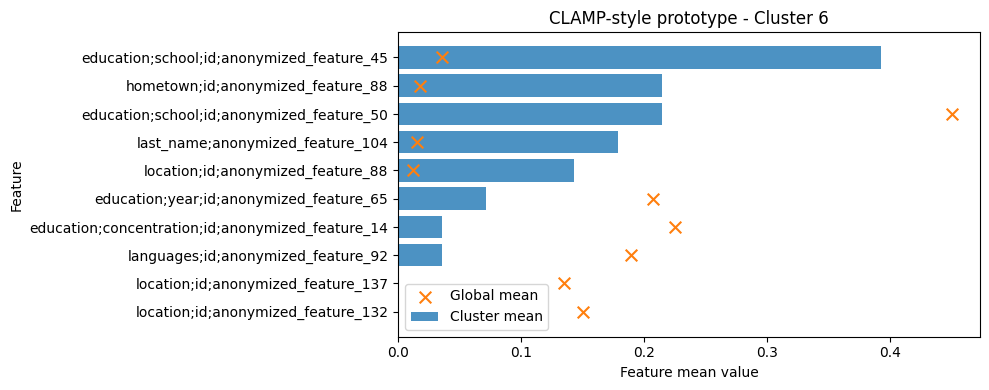

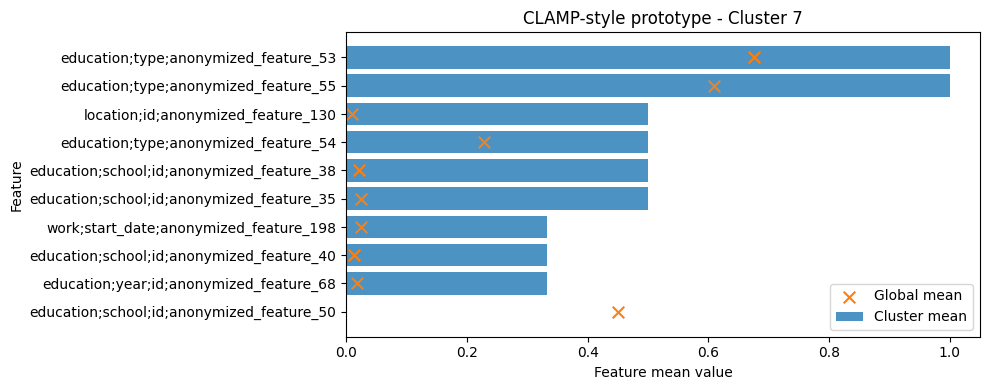

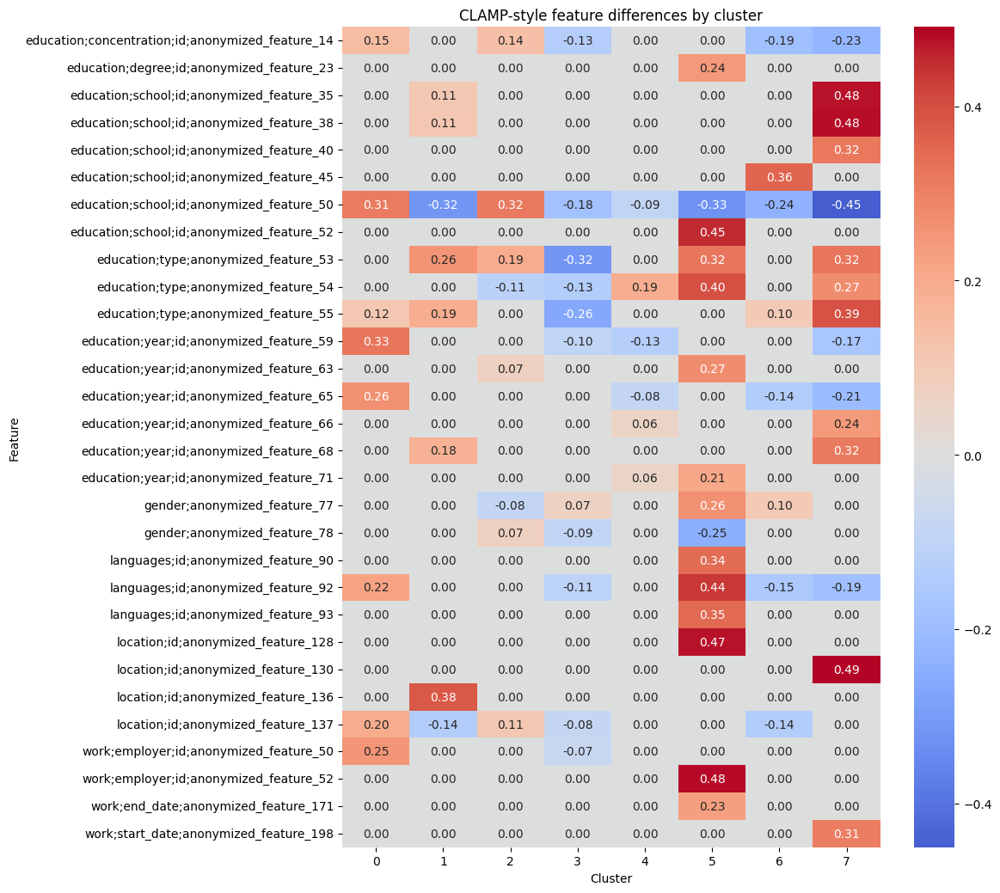


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.423423                          0.49486          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        12           4  

=== Decision tree rules ===
|--- education;school;id;anonymized_feature_50 <= 0.50
|   |--- education;type;anonymized_feature_53 <= 0.50
|   |   |--- education;type;anonymized_feature_55 <= 0.50
|   |   |   |--- gender;anonymized_feature_77 <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- gender;anonymized_feature_77 >  0.50
|   |   |   |   |--- class: 3
|   |   |--- education;type;anonymized_feature_55 >  0.50
|   |   |   |--- class: 6
|   |--- education;type;anonymized_feature_53 >  0.50
|   |   |--- languages;id;anonymized_feature_92 <= 0.50
|   |   |   |--- work;end_date;anonymized_feature_157 <= 0.50
|   |   |   |   |--- class: 7
|   |   |   |--- work;end_date;anonymized_feature_157 >  0.50
|   |   |   |

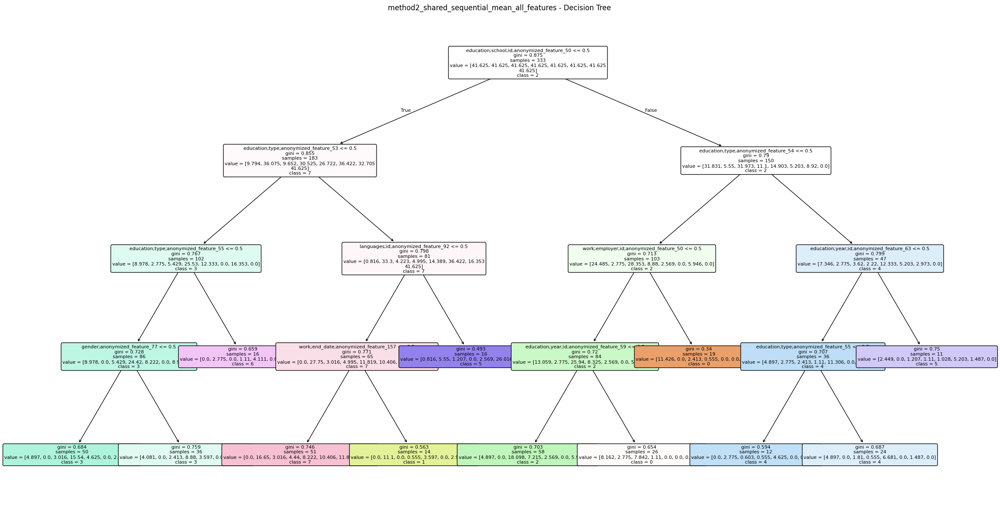


=== Decision tree feature importance ===
education;type;anonymized_feature_53         0.212709
languages;id;anonymized_feature_92           0.206806
education;school;id;anonymized_feature_50    0.197421
work;end_date;anonymized_feature_157         0.088094
education;type;anonymized_feature_54         0.075696
education;type;anonymized_feature_55         0.072775
work;employer;id;anonymized_feature_50       0.070154
education;year;id;anonymized_feature_63      0.040124
education;year;id;anonymized_feature_59      0.028113
gender;anonymized_feature_77                 0.008108
dtype: float64


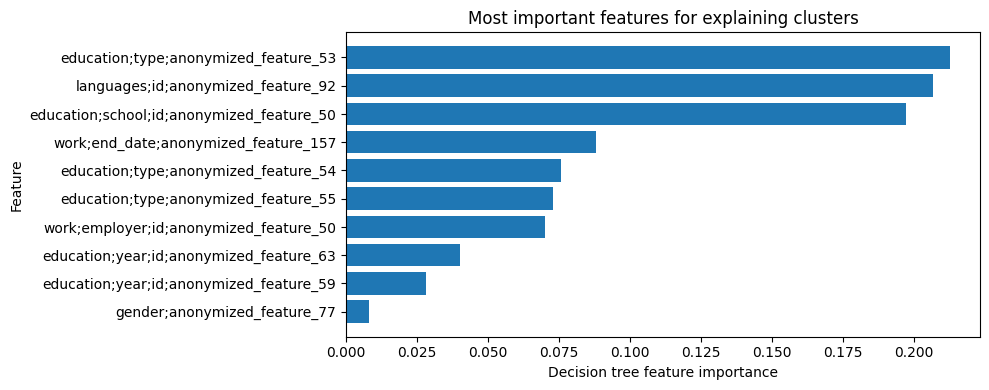


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.647059  0.000000  0.215686  0.000000  0.000000  0.019608  0.039216   
1        0.333333  0.066667  0.066667  0.133333  0.066667  0.000000  0.333333   
2        0.565217  0.028986  0.115942  0.057971  0.000000  0.101449  0.072464   
3        0.253333  0.000000  0.053333  0.066667  0.040000  0.013333  0.520000   
4        0.098765  0.197531  0.000000  0.037037  0.160494  0.012346  0.395062   
5        0.375000  0.000000  0.125000  0.125000  0.000000  0.000000  0.250000   
6        0.142857  0.071429  0.035714  0.000000  0.035714  0.000000  0.714286   
7        0.500000  0.000000  0.000000  0.000000  0.166667  0.000000  0.333333   

         circleOverlap  
cluster                 
0             0.078431  
1             0.000000  
2             0.057971  
3             0.053333  


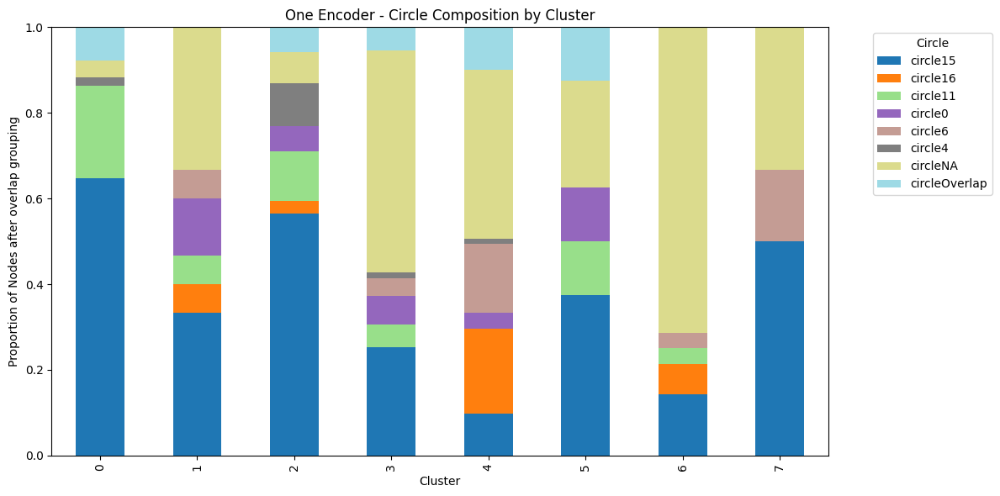

In [31]:
# ============================================================
# CELL 25 - MODEL 2A - Shared sequential DGI with all features
# ============================================================

diagnostics_method2_all, result_method2_all = (
    run_final_dataset_analysis(
        dataset_name="method2_shared_sequential_mean_all_features",
        n_clusters=K_ALL_FEATURES,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: method2_shared_sequential_mean_circles_only
Embeddings shape: (333, 64)
Features shape: (333, 7)
Membership shape: (333, 8)

Running diagnostics for: method2_shared_sequential_mean_circles_only

=== method2_shared_sequential_mean_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.603251         629.325392        0.562677                 2   
3     0.442000         560.976856        0.876871                 3   
6     0.441832         606.250961        0.805360                 4   
9     0.461909         582.540636        0.797845                 5   
12    0.435745         599.605605        0.809003                 6   
15    0.440707         585.375195        0.803575                 7   
18    0.402455         565.973126        0.934437                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3      

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


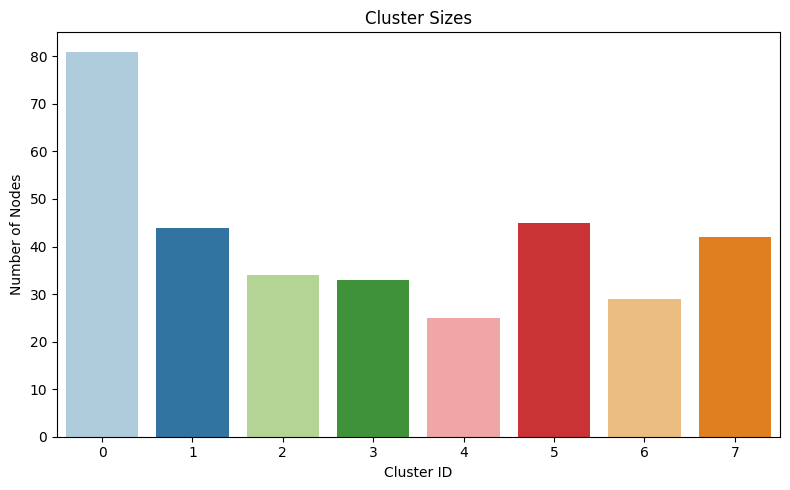


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.009997         0.125929         0.168597         0.526566   
1               0.000174         0.267782         1.619492         0.680737   
2               0.001613         0.239776         1.021373         0.620905   
3               0.128273         0.027582         0.046025         0.313060   
4               0.041887         0.205465         0.326963         0.136776   
5               0.006388         0.204216         0.511196         0.650205   
6               0.222283         0.193089         0.041304         0.361602   
7               0.022114         0.104331         0.135505         0.355871   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.344207 

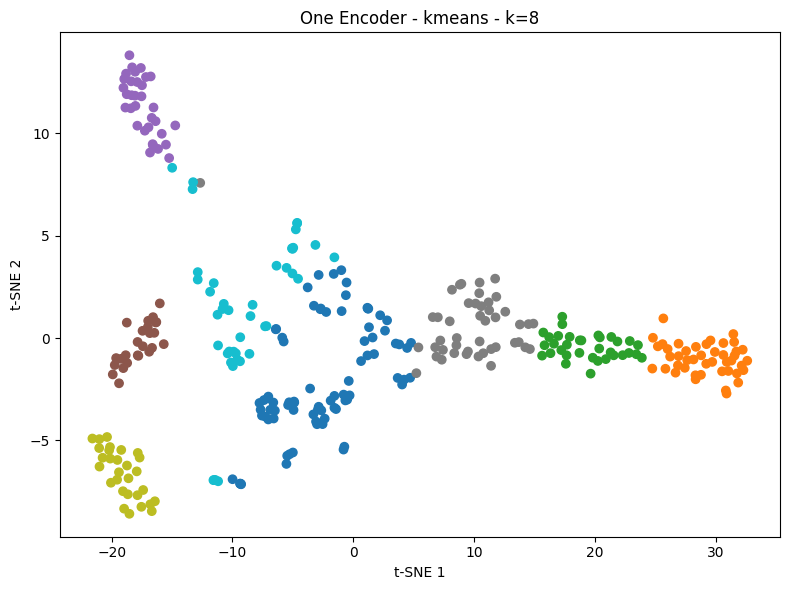

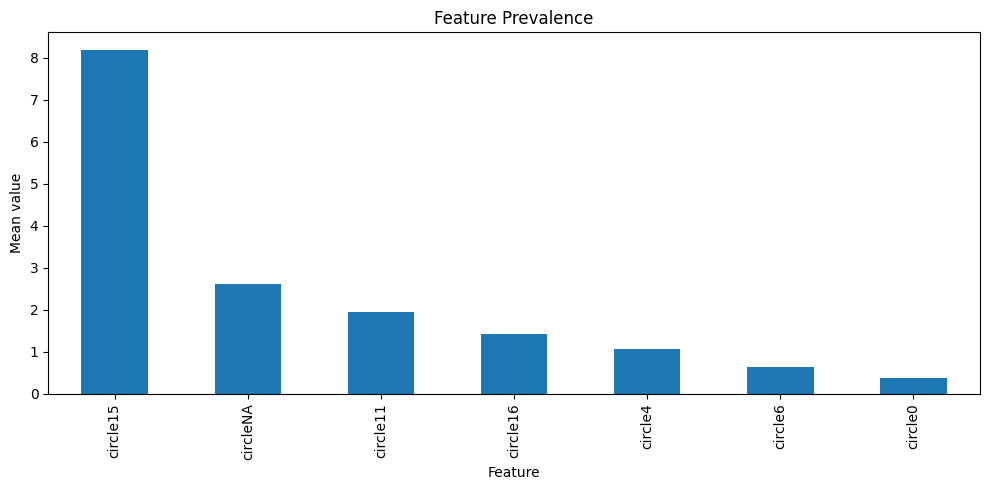


=== Cluster feature profiles ===
          circle15  circle16  circle11   circle0   circle6   circle4  circleNA
cluster                                                                       
0         1.876543  0.086420  0.209877  0.148148  0.061728  0.111111  0.617284
1        32.090909  1.454545  9.227273  1.113636  0.000000  5.000000  2.954545
2        15.382353  0.676471  3.588235  0.470588  0.000000  2.352941  1.470588
3         4.818182  9.757576  0.212121  0.121212  0.000000  0.090909  4.606061
4         0.880000  0.040000  0.360000  0.080000  0.120000  0.040000  7.560000
5         8.888889  0.711111  1.622222  0.266667  0.000000  0.866667  0.888889
6         0.137931  0.000000  0.206897  0.000000  6.827586  0.000000  5.206897
7         1.333333  0.595238  0.166667  0.714286  0.238095  0.071429  2.523810


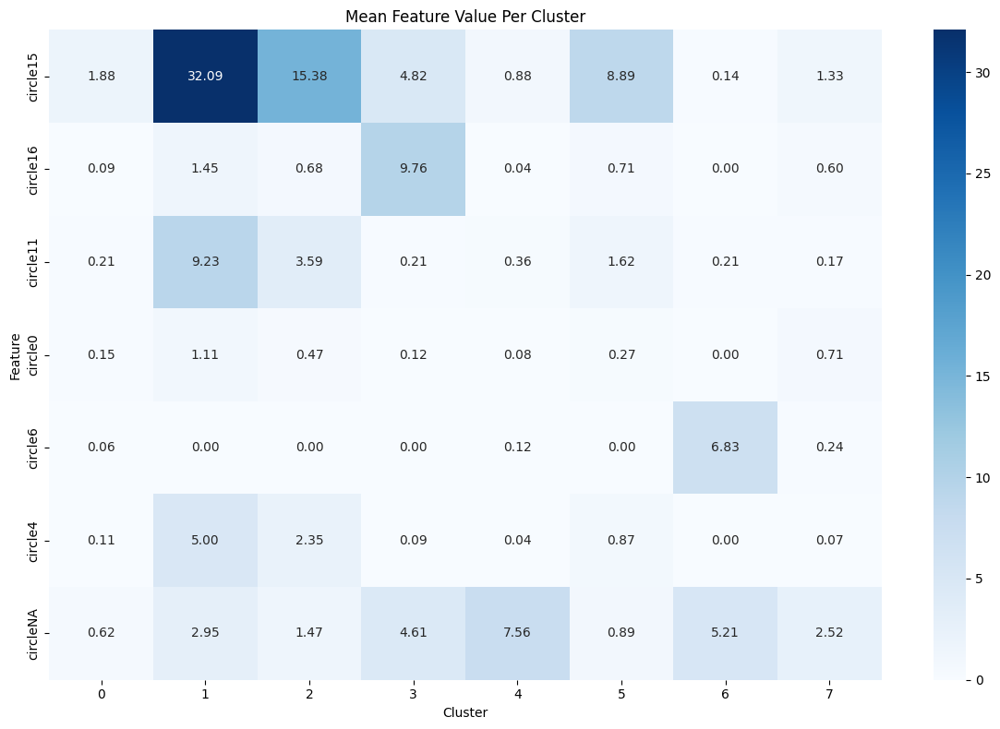

Features with > 30% prevalence/value in at least one cluster:
          circle15  circle16  circle11   circle0   circle6   circle4  circleNA
cluster                                                                       
0         1.876543  0.086420  0.209877  0.148148  0.061728  0.111111  0.617284
1        32.090909  1.454545  9.227273  1.113636  0.000000  5.000000  2.954545
2        15.382353  0.676471  3.588235  0.470588  0.000000  2.352941  1.470588
3         4.818182  9.757576  0.212121  0.121212  0.000000  0.090909  4.606061
4         0.880000  0.040000  0.360000  0.080000  0.120000  0.040000  7.560000
5         8.888889  0.711111  1.622222  0.266667  0.000000  0.866667  0.888889
6         0.137931  0.000000  0.206897  0.000000  6.827586  0.000000  5.206897
7         1.333333  0.595238  0.166667  0.714286  0.238095  0.071429  2.523810

=== Top mutual information features ===
circle15    0.961126
circle11    0.568473
circleNA    0.567317
circle4     0.527804
circle16    0.472585
ci

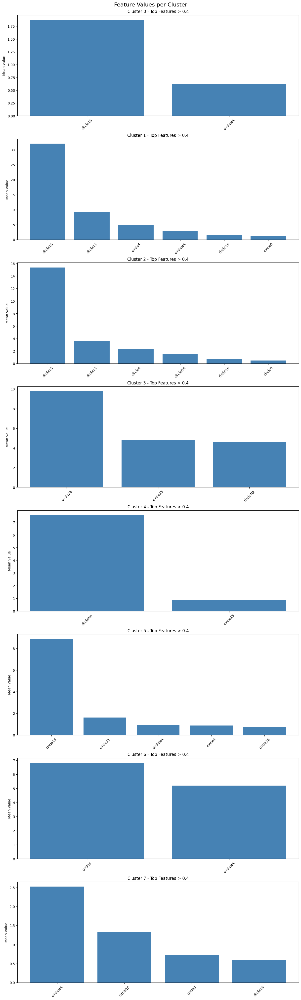


=== CLAMP prototypes ===
    cluster   feature  cluster_prevalence  global_prevalence  prevalence_diff  \
0         0  circle15            1.876543           8.192192        -6.315649   
1         0  circleNA            0.617284           2.606607        -1.989323   
2         0  circle11            0.209877           1.942943        -1.733066   
3         0  circle16            0.086420           1.423423        -1.337004   
4         0   circle4            0.111111           1.066066        -0.954955   
5         0   circle6            0.061728           0.648649        -0.586920   
6         0   circle0            0.148148           0.375375        -0.227227   
7         1  circle15           32.090909           8.192192        23.898717   
8         1  circle11            9.227273           1.942943         7.284330   
9         1   circle4            5.000000           1.066066         3.933934   
10        1   circle0            1.113636           0.375375         0.738261   
11

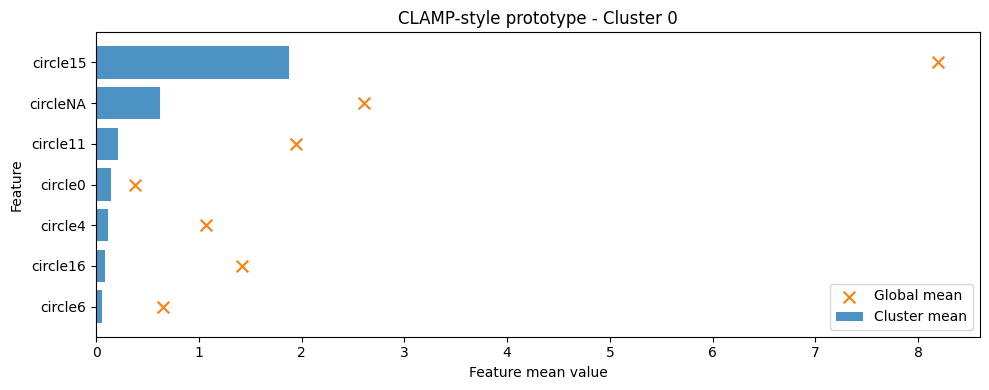

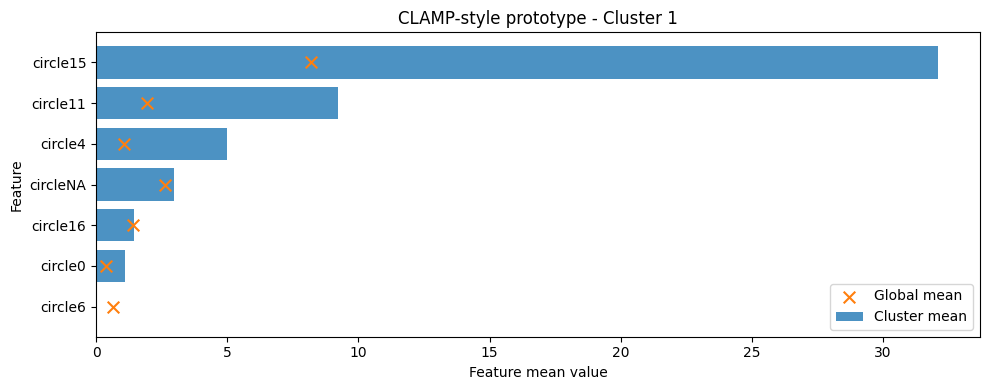

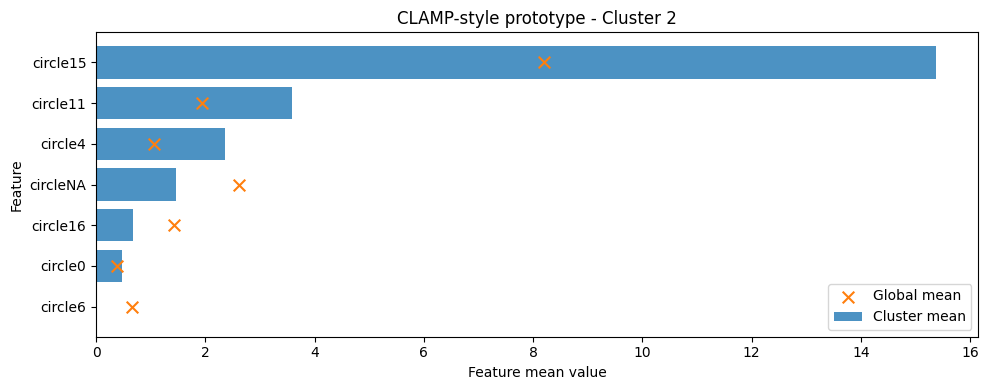

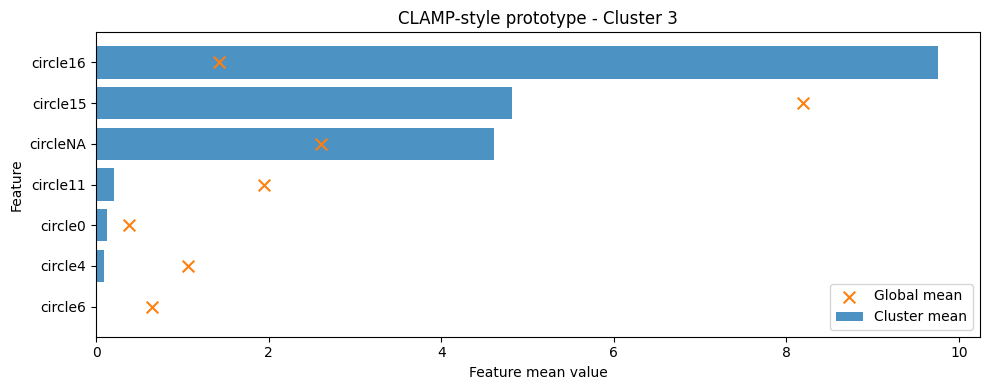

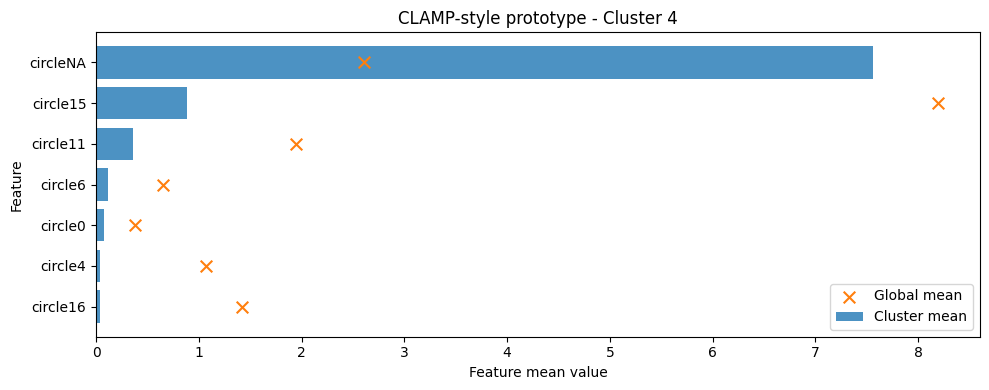

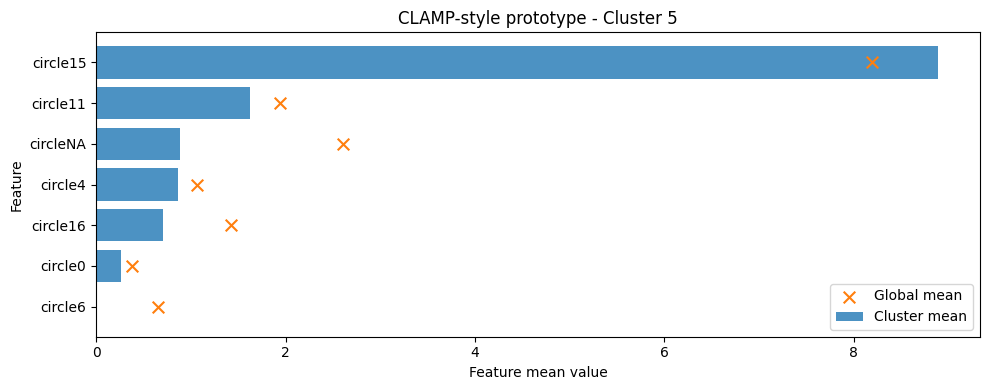

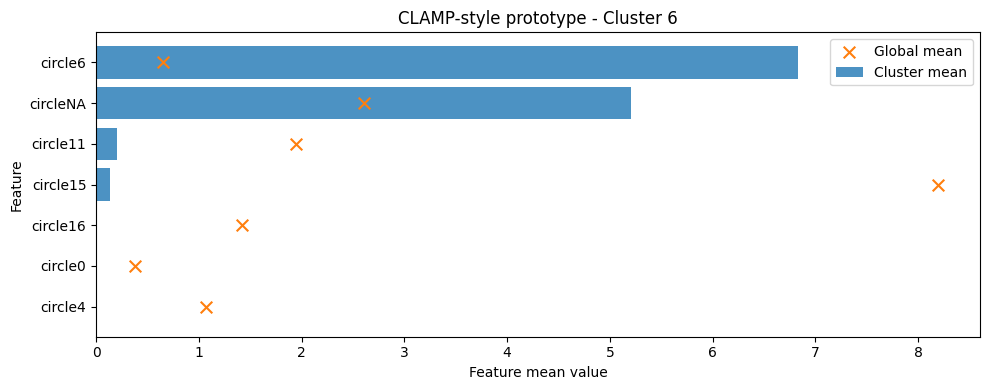

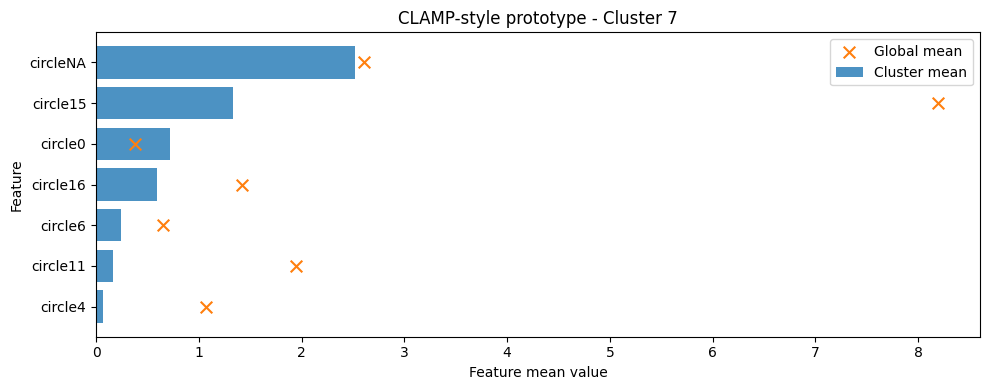

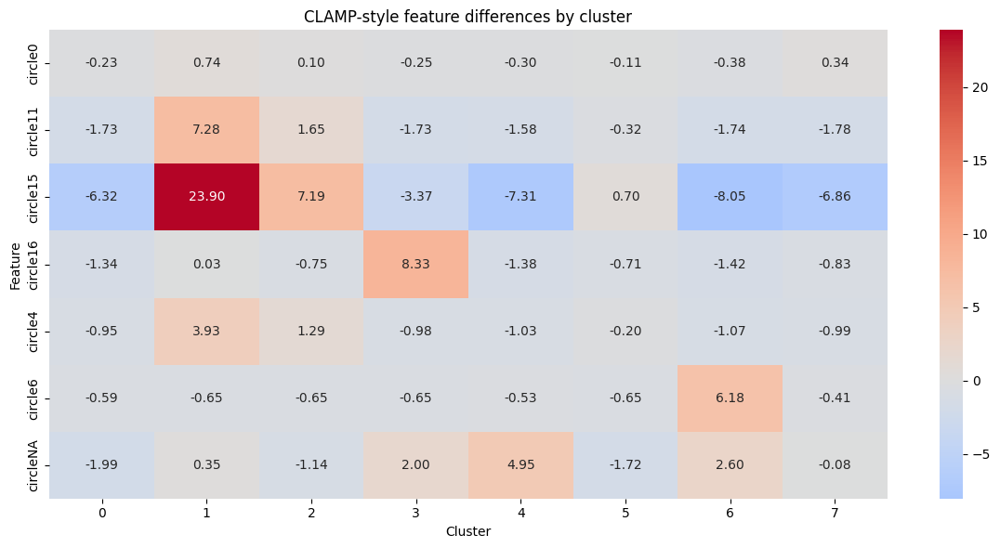


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.684685                          0.69622          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         8           4  

=== Decision tree rules ===
|--- circle6 <= 2.50
|   |--- circle16 <= 4.50
|   |   |--- circle15 <= 6.50
|   |   |   |--- circleNA <= 4.50
|   |   |   |   |--- class: 0
|   |   |   |--- circleNA >  4.50
|   |   |   |   |--- class: 4
|   |   |--- circle15 >  6.50
|   |   |   |--- circle15 <= 23.50
|   |   |   |   |--- class: 2
|   |   |   |--- circle15 >  23.50
|   |   |   |   |--- class: 1
|   |--- circle16 >  4.50
|   |   |--- circle15 <= 8.00
|   |   |   |--- class: 3
|   |   |--- circle15 >  8.00
|   |   |   |--- class: 3
|--- circle6 >  2.50
|   |--- circle6 <= 5.50
|   |   |--- class: 6
|   |--- circle6 >  5.50
|   |   |--- class: 6



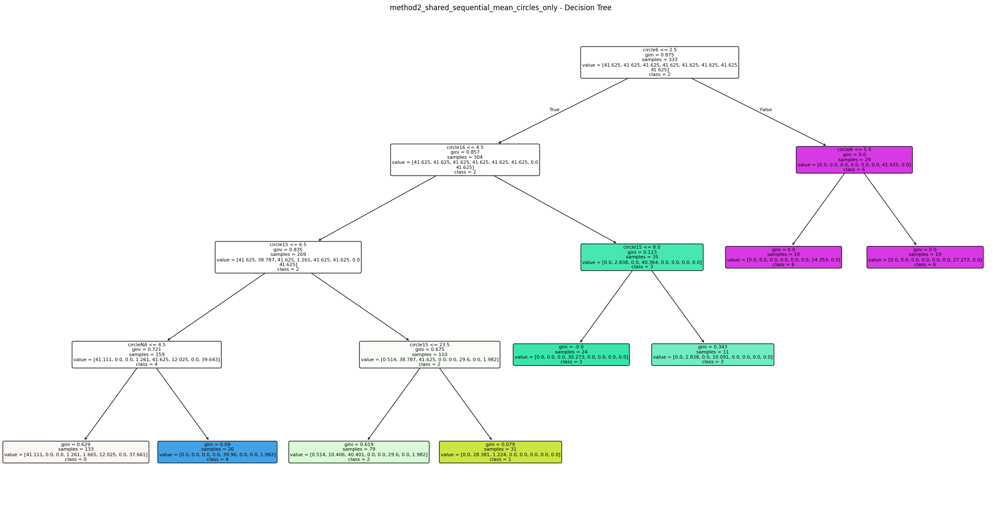


=== Decision tree feature importance ===
circle15    0.332188
circle6     0.244044
circle16    0.218392
circleNA    0.205377
dtype: float64


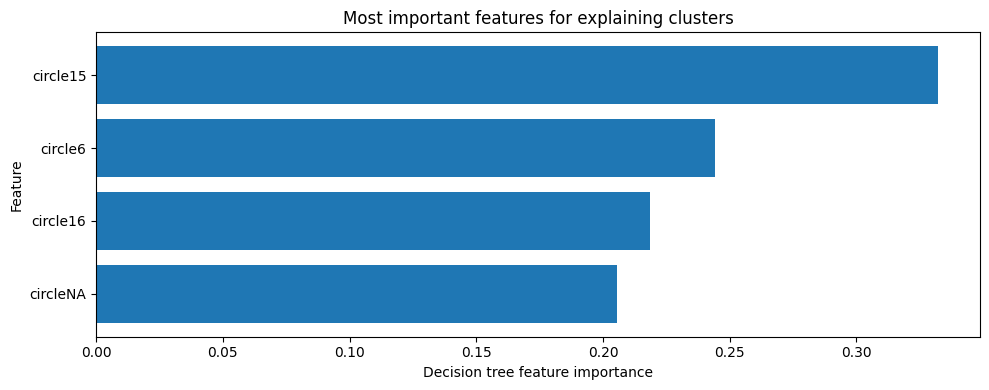


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.358025  0.024691  0.049383  0.037037  0.024691  0.012346  0.469136   
1        0.636364  0.000000  0.227273  0.000000  0.000000  0.022727  0.022727   
2        0.558824  0.000000  0.205882  0.029412  0.000000  0.088235  0.058824   
3        0.090909  0.454545  0.000000  0.000000  0.000000  0.000000  0.212121   
4        0.080000  0.000000  0.040000  0.000000  0.000000  0.000000  0.880000   
5        0.577778  0.044444  0.066667  0.066667  0.000000  0.111111  0.066667   
6        0.000000  0.000000  0.034483  0.000000  0.482759  0.000000  0.482759   
7        0.166667  0.047619  0.000000  0.190476  0.071429  0.000000  0.476190   

         circleOverlap  
cluster                 
0             0.024691  
1             0.090909  
2             0.058824  
3             0.242424  


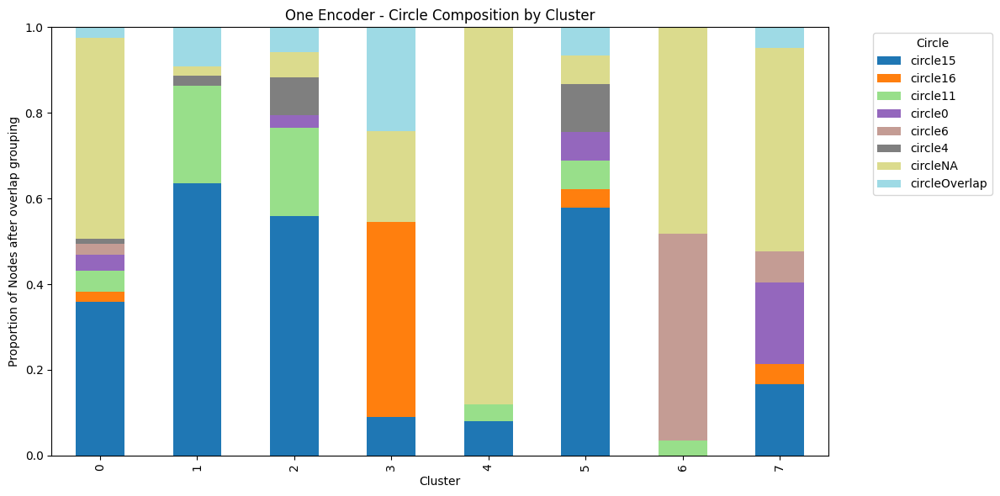

In [32]:
# ============================================================
# CELL 26 - MODEL 2B - Shared sequential DGI with circles-only ARD
# ============================================================

diagnostics_method2_circles, result_method2_circles = (
    run_final_dataset_analysis(
        dataset_name="method2_shared_sequential_mean_circles_only",
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: method2_shared_sequential_mean_graph_structure_identity_only
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method2_shared_sequential_mean_graph_structure_identity_only

=== method2_shared_sequential_mean_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.165266          55.915520        2.072530                 2   
3     0.173450          44.668922        2.578957                 3   
6     0.153540          41.560271        2.270822                 4   
9     0.150477          34.816357        2.691319                 5   
12    0.148898          30.444454        2.840804                 6   
15    0.135682          26.567941        2.756276                 7   
18    0.142787          23.914668        3.053623                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2     

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


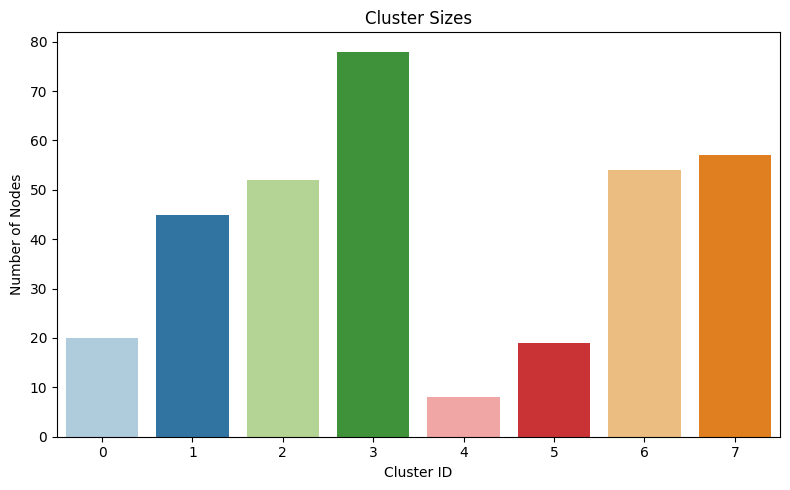


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.068569         0.061511         0.064063         0.075707   
1               0.090720         0.067122         0.048895         0.097577   
2               0.204218         0.097015         0.014416         0.041537   
3               0.128618         0.132618         0.053147         0.092976   
4               0.049002         0.125266         0.057784         0.037210   
5               0.090654         0.069008         0.055295         0.126786   
6               0.047598         0.074842         0.066217         0.115382   
7               0.023312         0.069218         0.054247         0.081014   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.041776 

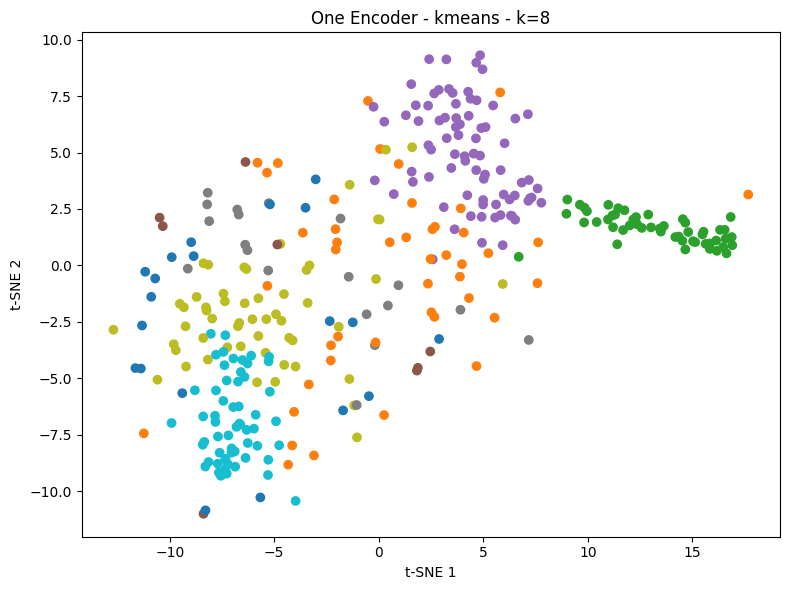

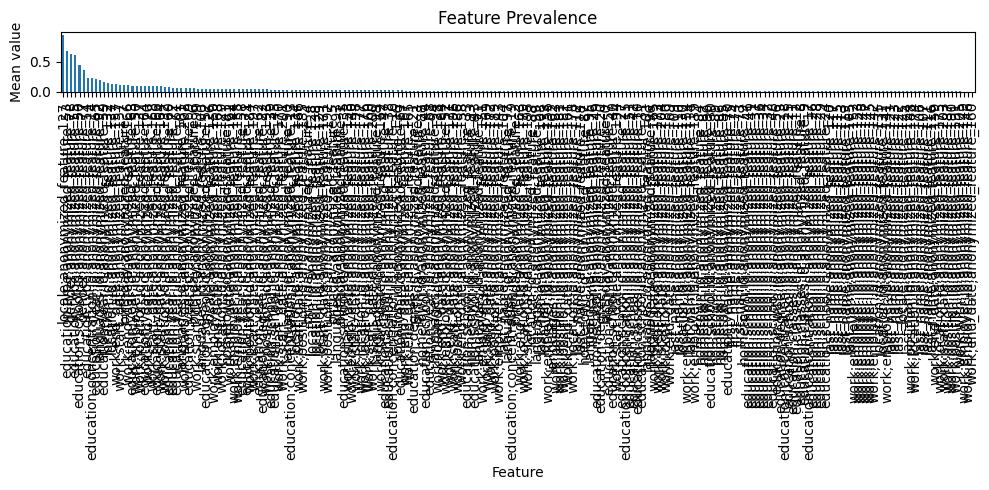


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.100000   
1                             0.022222                       0.022222   
2                             0.000000                       0.000000   
3                             0.000000                       0.000000   
4                             0.000000                       0.125000   
5                             0.000000                       0.000000   
6                             0.055556                       0.018519   
7                             0.000000                       0.052632   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.050000                       0.000000   
1               

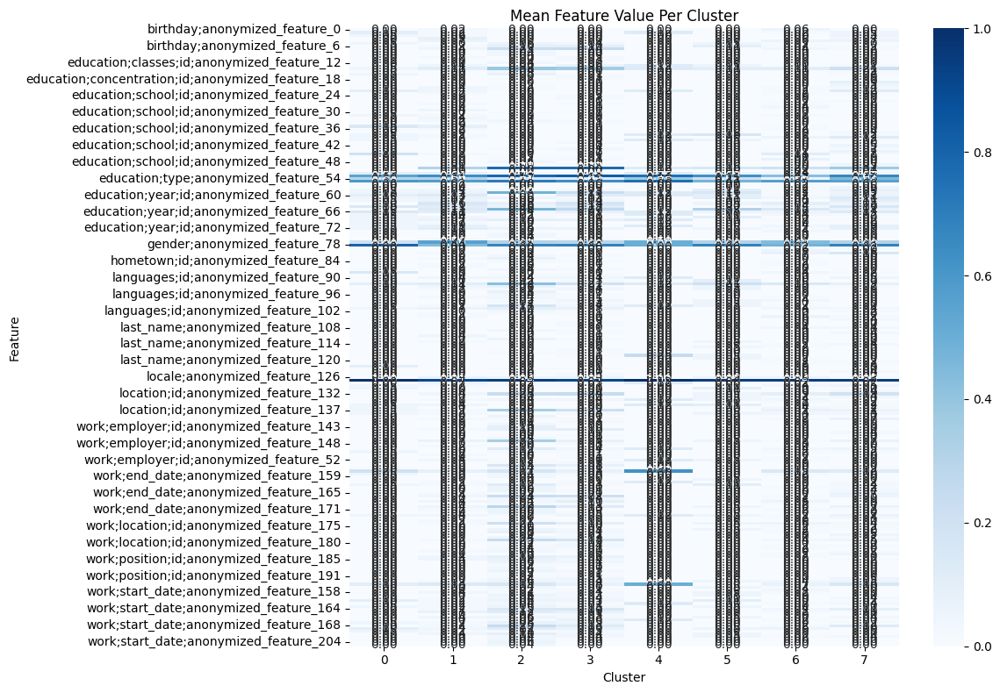

Features with > 30% prevalence/value in at least one cluster:
         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.050000   
1                                                0.111111   
2                                                0.384615   
3                                                0.358974   
4                                                0.125000   
5                                                0.105263   
6                                                0.111111   
7                                                0.210526   

         education;school;id;anonymized_feature_50  \
cluster                                              
0                                         0.000000   
1                                         0.311111   
2                                         0.769231   
3                                         0.769231   
4  

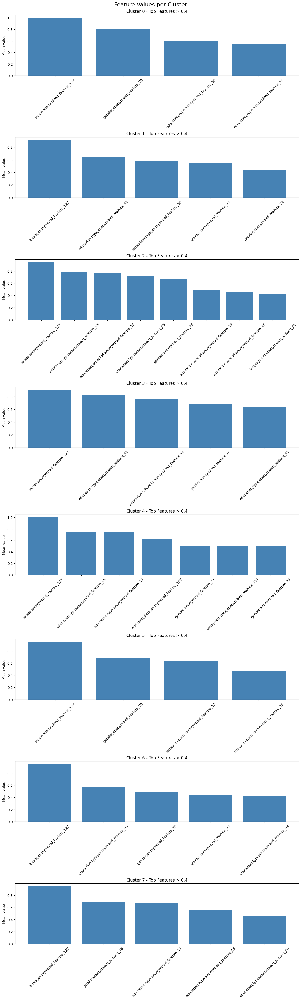


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0         education;school;id;anonymized_feature_50   
1         0           education;year;id;anonymized_feature_65   
2         0                      gender;anonymized_feature_78   
3         0  education;concentration;id;anonymized_feature_14   
4         0         education;school;id;anonymized_feature_45   
5         0                      gender;anonymized_feature_77   
6         0                location;id;anonymized_feature_132   
7         0                 hometown;id;anonymized_feature_88   
8         0         education;school;id;anonymized_feature_35   
9         0              education;type;anonymized_feature_53   
10        0           education;year;id;anonymized_feature_59   
11        0                     birthday;anonymized_feature_7   
12        0              work;end_date;anonymized_feature_166   
13        0           education;year;id;anonymized_feature_63   

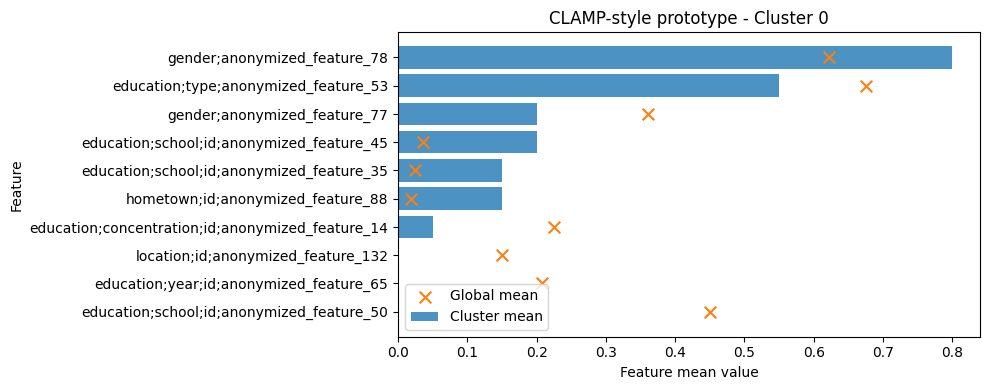

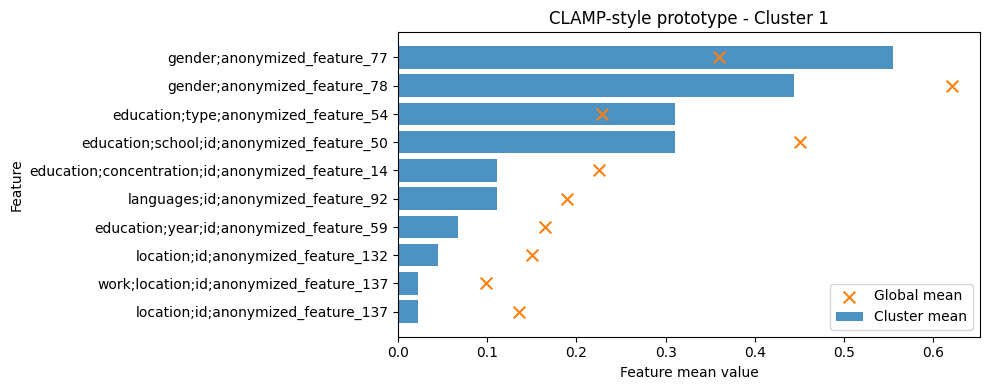

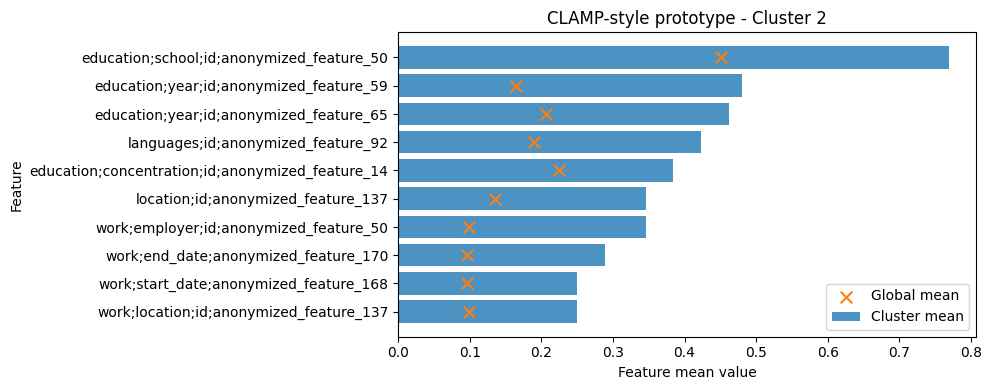

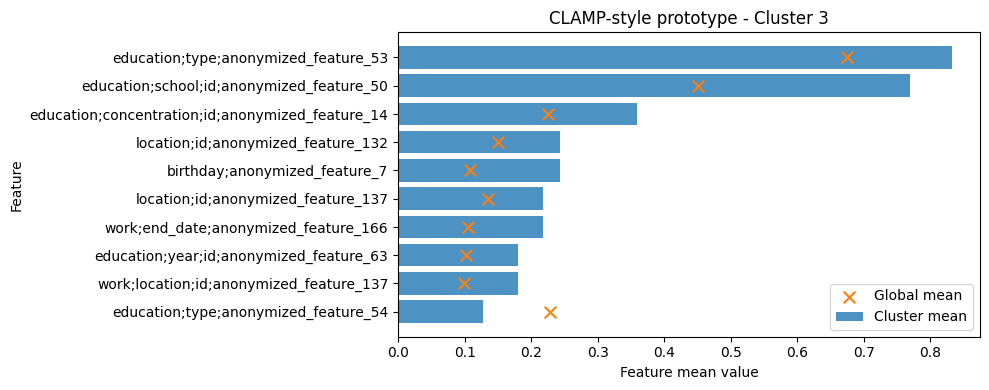

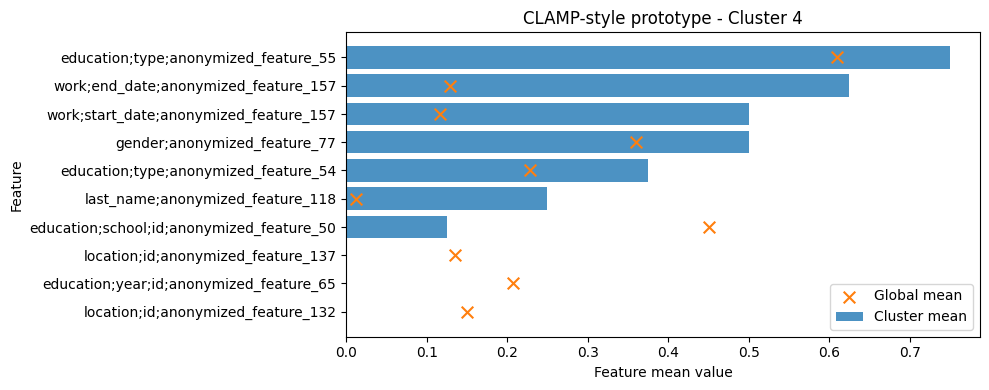

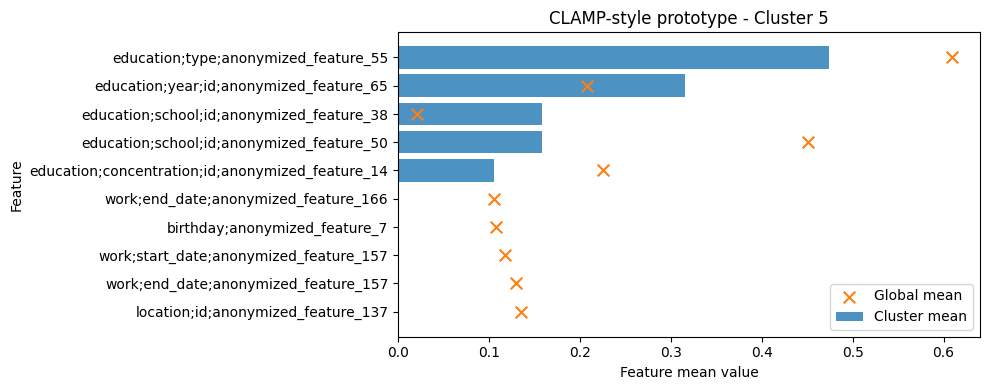

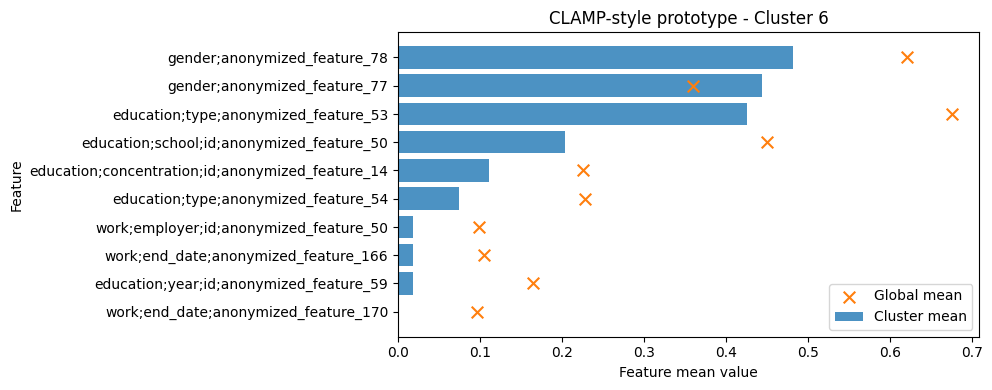

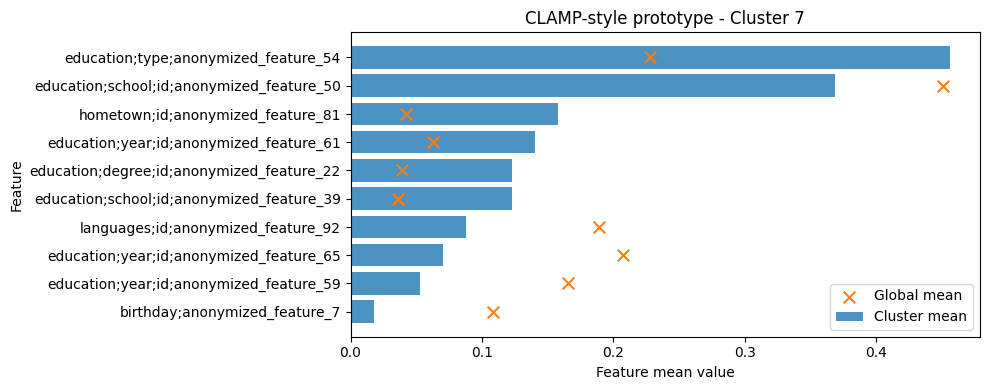

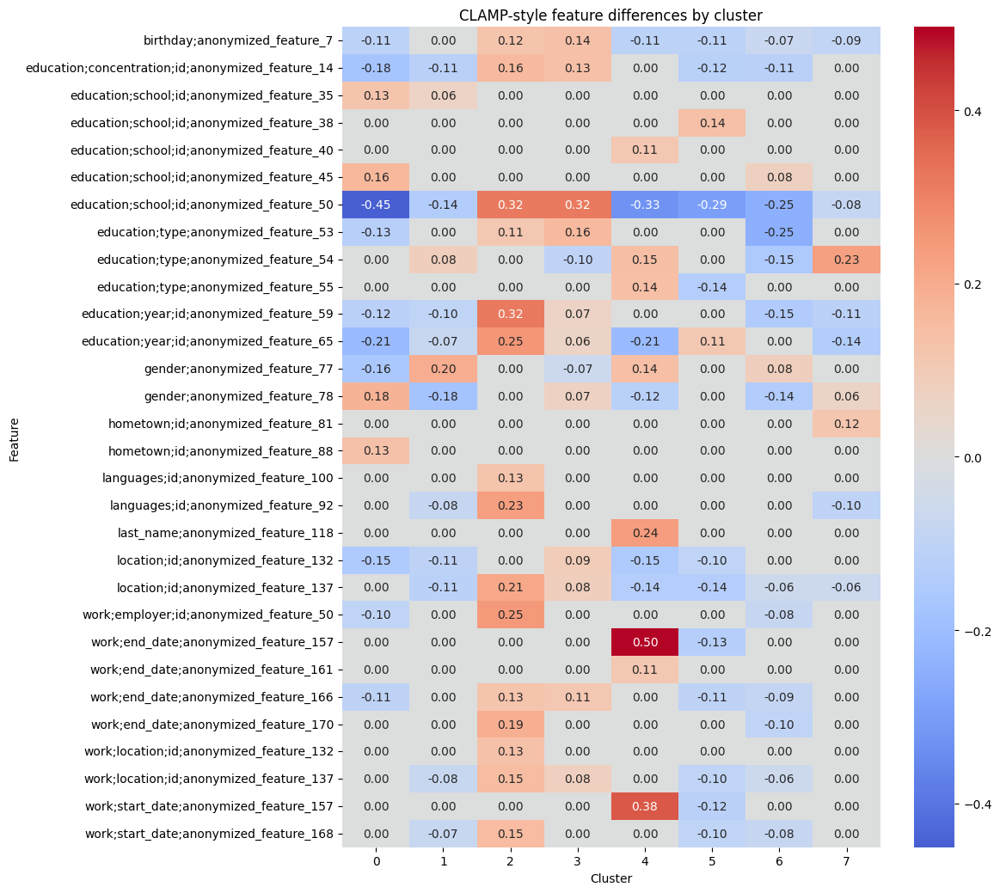


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.345345                         0.409414          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        11           4  

=== Decision tree rules ===
|--- education;school;id;anonymized_feature_50 <= 0.50
|   |--- work;end_date;anonymized_feature_157 <= 0.50
|   |   |--- gender;anonymized_feature_78 <= 0.50
|   |   |   |--- education;type;anonymized_feature_53 <= 0.50
|   |   |   |   |--- class: 6
|   |   |   |--- education;type;anonymized_feature_53 >  0.50
|   |   |   |   |--- class: 4
|   |   |--- gender;anonymized_feature_78 >  0.50
|   |   |   |--- education;type;anonymized_feature_54 <= 0.50
|   |   |   |   |--- class: 5
|   |   |   |--- education;type;anonymized_feature_54 >  0.50
|   |   |   |   |--- class: 0
|   |--- work;end_date;anonymized_feature_157 >  0.50
|   |   |--- class: 4
|--- education;school;id;anonymized_feature

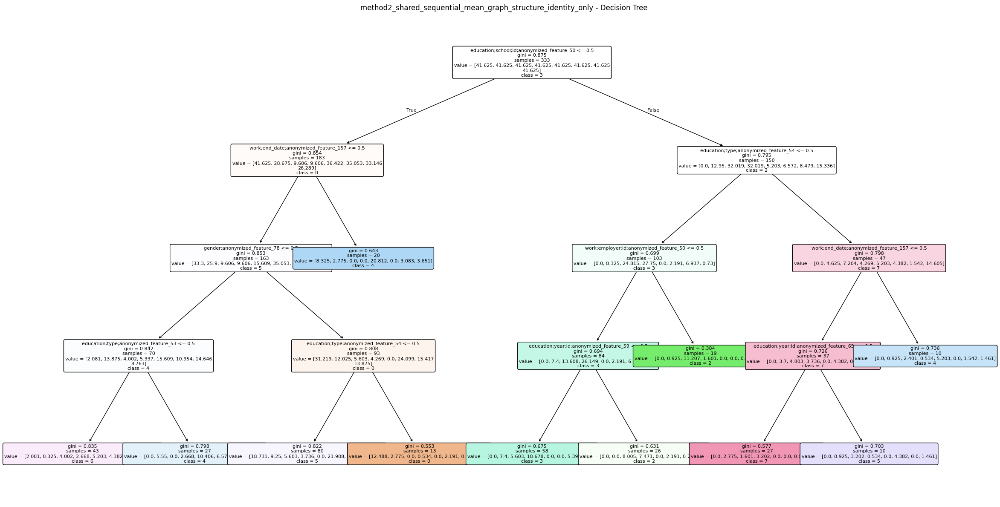


=== Decision tree feature importance ===
education;school;id;anonymized_feature_50    0.258332
work;end_date;anonymized_feature_157         0.213995
education;type;anonymized_feature_54         0.199328
gender;anonymized_feature_78                 0.108068
work;employer;id;anonymized_feature_50       0.091496
education;year;id;anonymized_feature_65      0.059291
education;year;id;anonymized_feature_59      0.036012
education;type;anonymized_feature_53         0.033476
dtype: float64


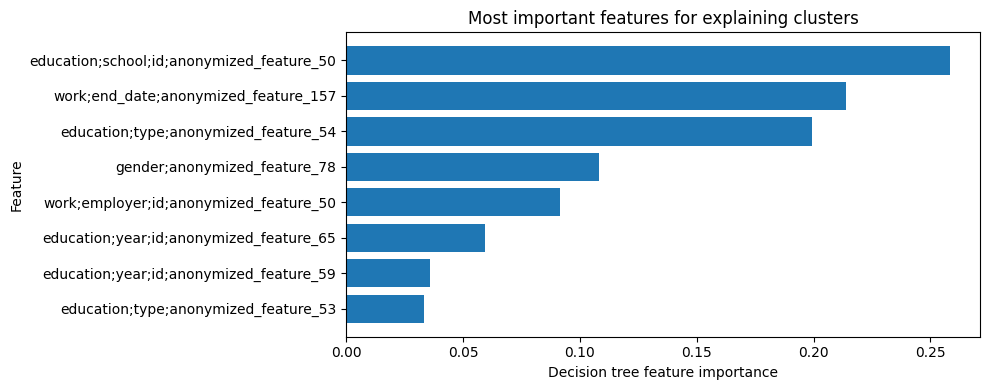


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.200000  0.050000  0.050000  0.000000  0.150000  0.000000  0.500000   
1        0.333333  0.022222  0.066667  0.066667  0.000000  0.022222  0.444444   
2        0.653846  0.000000  0.211538  0.000000  0.000000  0.019231  0.038462   
3        0.538462  0.025641  0.115385  0.051282  0.000000  0.102564  0.102564   
4        0.125000  0.000000  0.000000  0.125000  0.125000  0.000000  0.625000   
5        0.263158  0.052632  0.052632  0.105263  0.000000  0.000000  0.526316   
6        0.166667  0.000000  0.018519  0.074074  0.111111  0.000000  0.611111   
7        0.070175  0.280702  0.000000  0.017544  0.157895  0.000000  0.333333   

         circleOverlap  
cluster                 
0             0.050000  
1             0.044444  
2             0.076923  
3             0.064103  


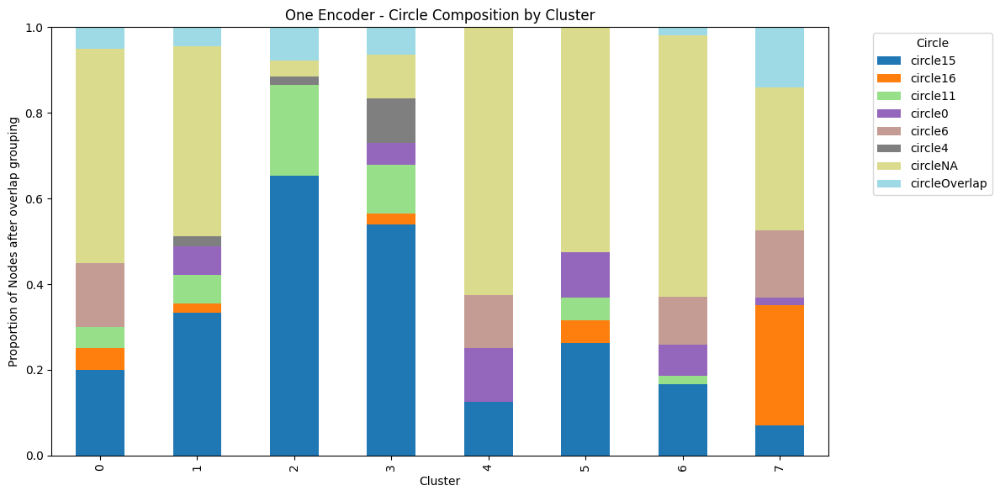

In [33]:
# ============================================================
# CELL 27 - MODEL 2C - Shared sequential DGI with structure only
# ============================================================

diagnostics_method2_structure, result_method2_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method2_shared_sequential_mean_"
            "graph_structure_identity_only"
        ),
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: method3_batch_mean_all_features
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method3_batch_mean_all_features

=== method3_batch_mean_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.525124         330.496380        0.616616                 2   
3     0.328678         293.171885        1.073915                 3   
6     0.286071         229.927199        1.021185                 4   
9     0.245028         200.200370        1.326135                 5   
12    0.257290         184.888309        1.234453                 6   
15    0.254606         171.106145        1.262965                 7   
18    0.251959         158.560688        1.475747                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3         ok   
6                     Tru

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


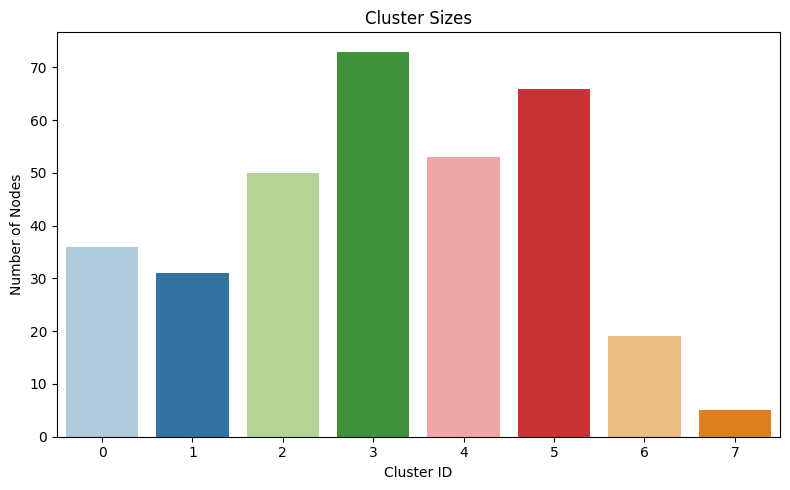


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.023166         0.062777         0.096714         0.009692   
1               0.176351         0.122952         0.012833         0.153159   
2               0.115607         0.080958         0.043473         0.104027   
3               0.052071         0.037320         0.061850         0.052812   
4               0.033755         0.029094         0.077515         0.034389   
5               0.025983         0.025271         0.071241         0.038362   
6               0.181620         0.120273         0.003735         0.152161   
7               0.019517         0.018732         0.189819         0.000211   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.023402 

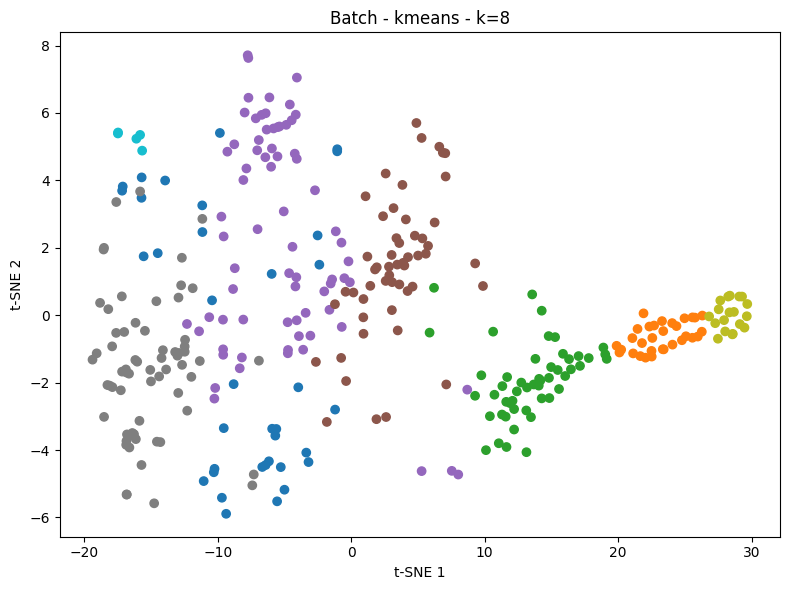

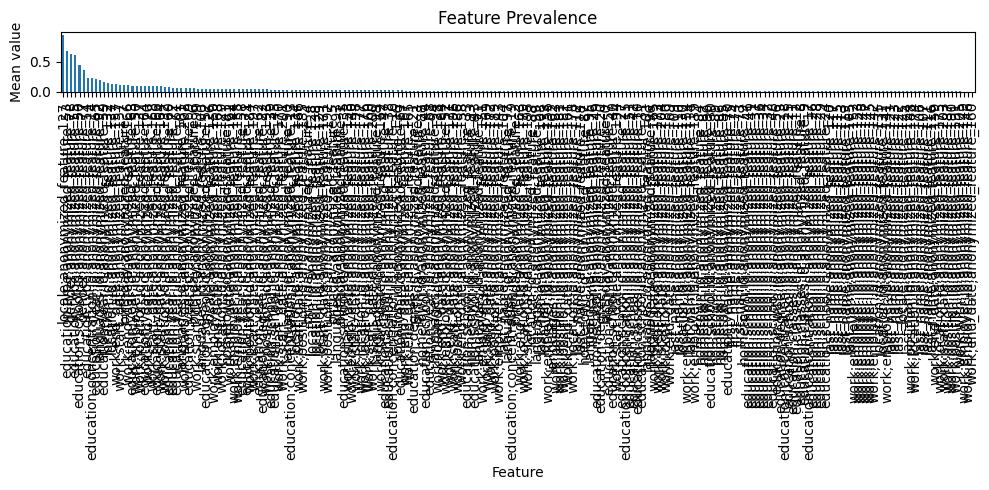


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.027778                       0.055556   
1                             0.000000                       0.000000   
2                             0.000000                       0.000000   
3                             0.027397                       0.027397   
4                             0.018868                       0.056604   
5                             0.000000                       0.000000   
6                             0.000000                       0.000000   
7                             0.000000                       0.200000   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.027778                       0.083333   
1               

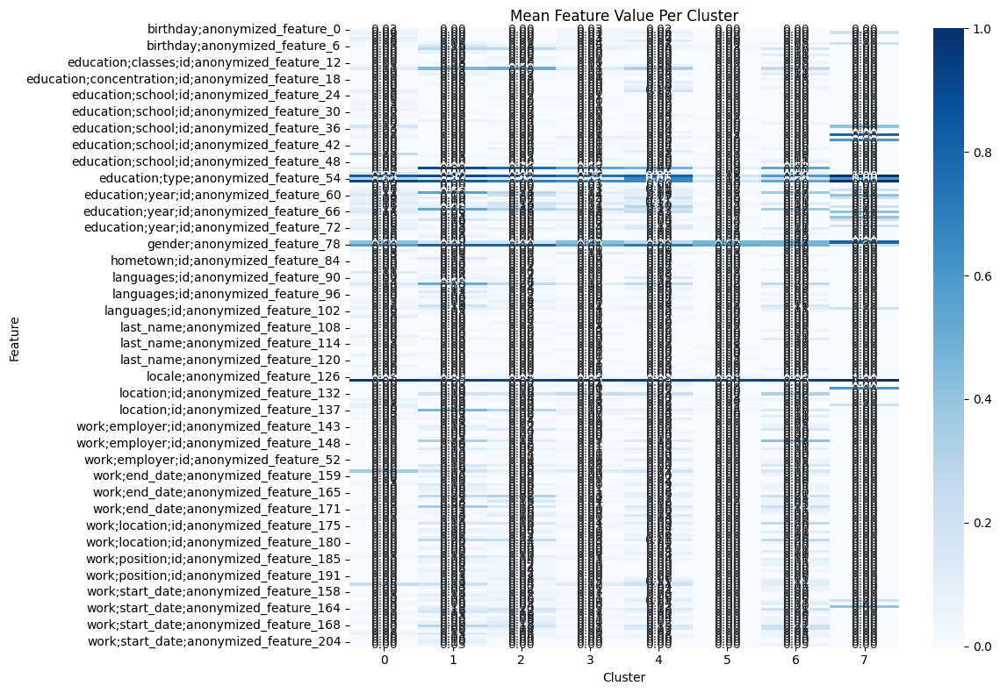

Features with > 30% prevalence/value in at least one cluster:
         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.111111   
1                                                0.451613   
2                                                0.500000   
3                                                0.136986   
4                                                0.320755   
5                                                0.000000   
6                                                0.263158   
7                                                0.000000   

         education;school;id;anonymized_feature_35  \
cluster                                              
0                                         0.166667   
1                                         0.000000   
2                                         0.000000   
3                                         0.000000   
4  

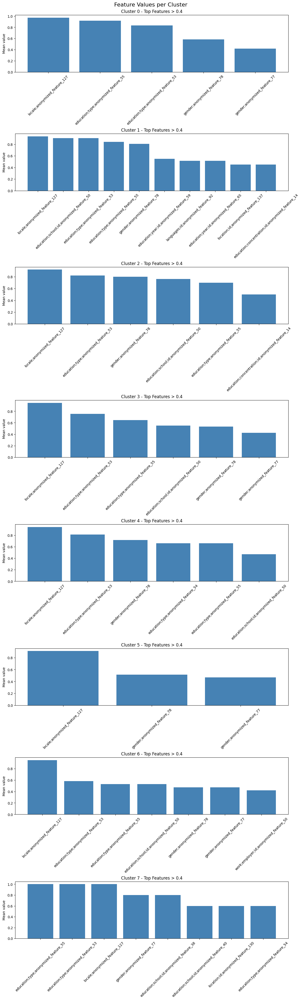


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0         education;school;id;anonymized_feature_50   
1         0              education;type;anonymized_feature_55   
2         0              work;end_date;anonymized_feature_157   
3         0         education;school;id;anonymized_feature_45   
4         0              education;type;anonymized_feature_53   
5         0                location;id;anonymized_feature_132   
6         0         education;school;id;anonymized_feature_35   
7         0                location;id;anonymized_feature_137   
8         0            work;start_date;anonymized_feature_157   
9         0  education;concentration;id;anonymized_feature_14   
10        0                     birthday;anonymized_feature_7   
11        0              work;end_date;anonymized_feature_166   
12        0           work;location;id;anonymized_feature_137   
13        0            work;employer;id;anonymized_feature_50   

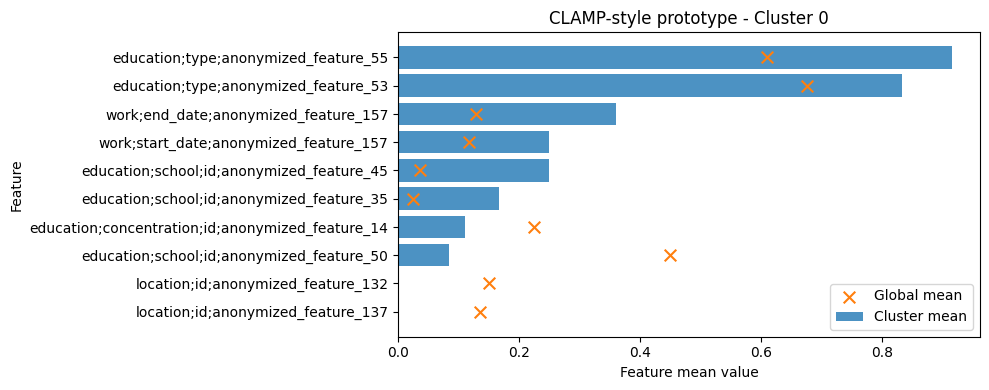

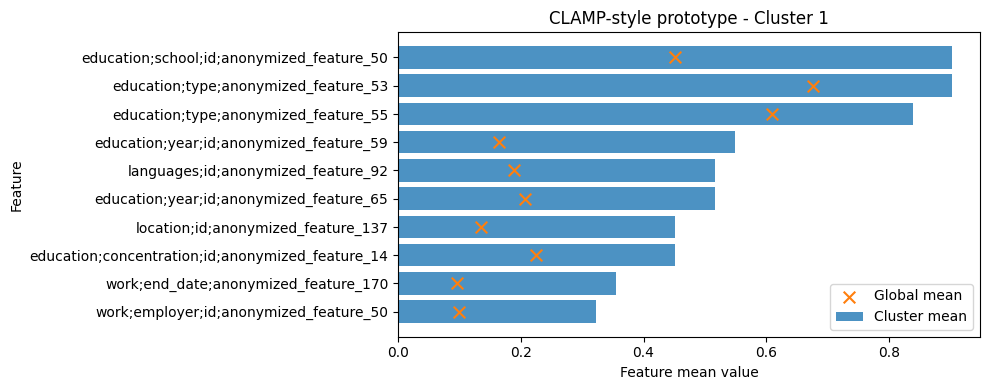

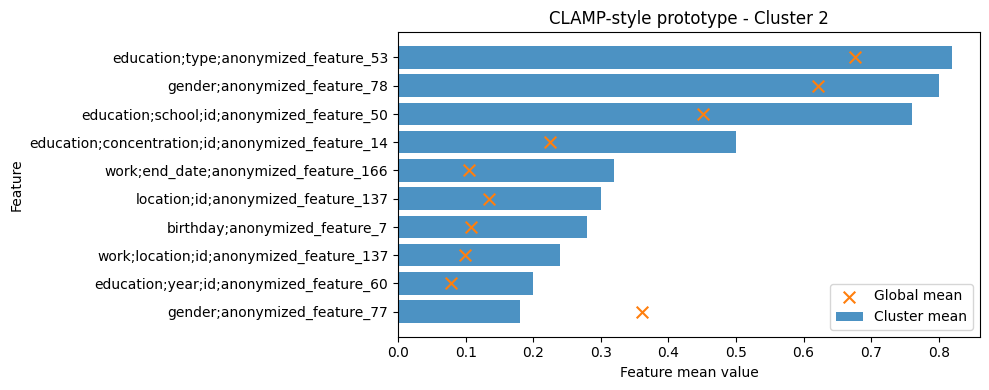

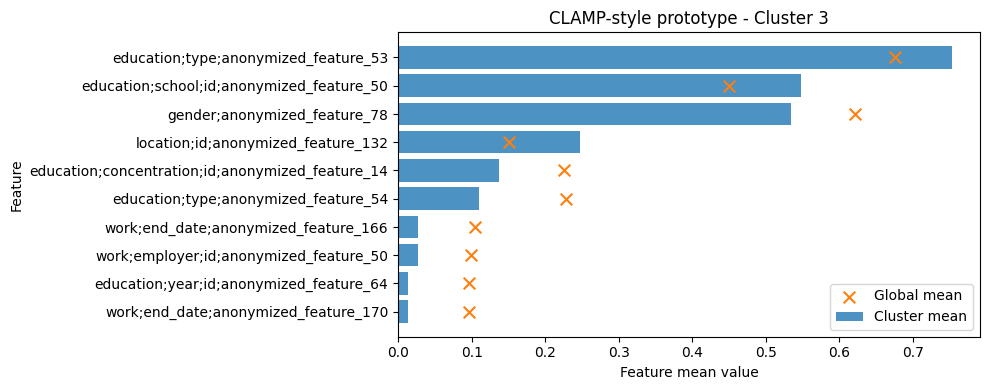

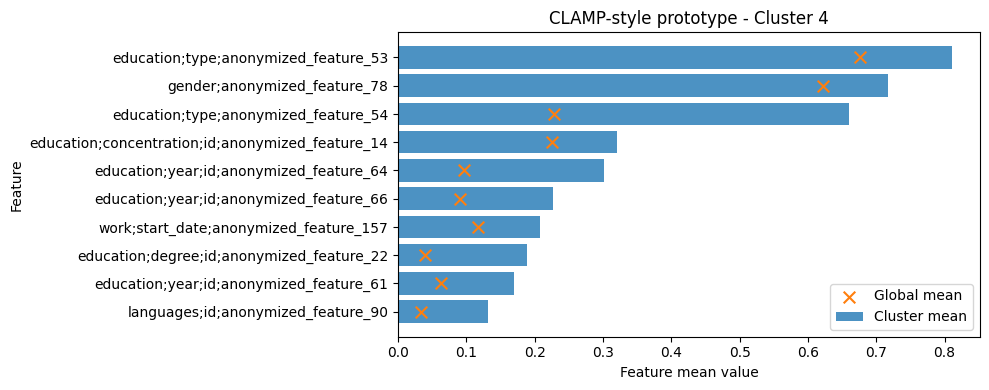

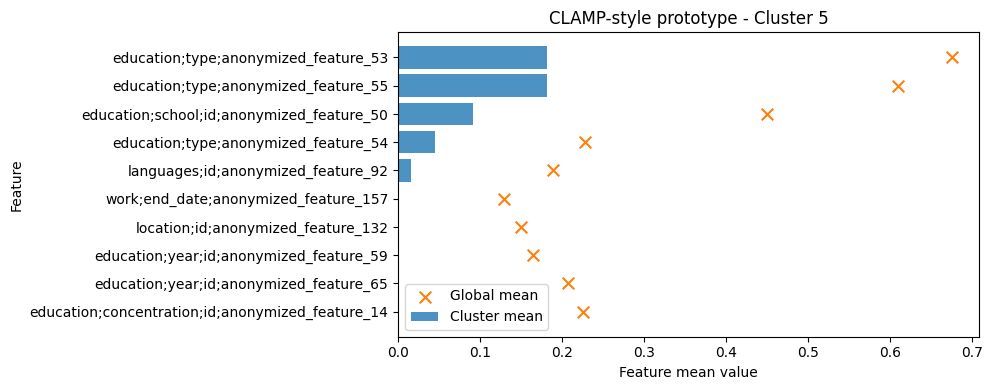

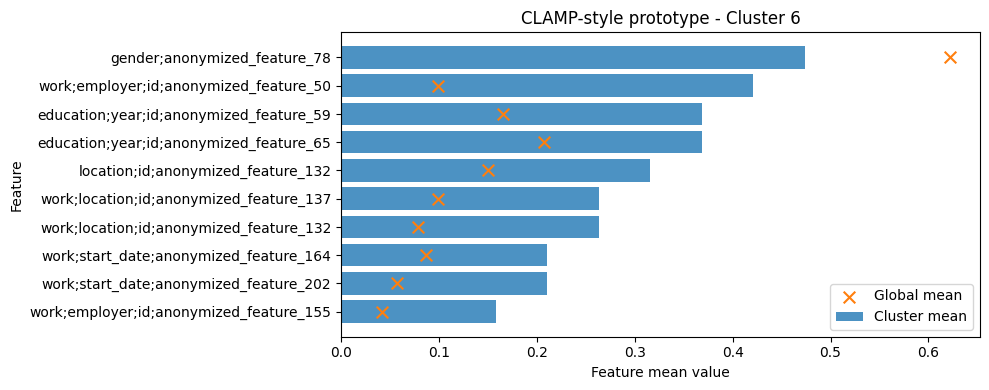

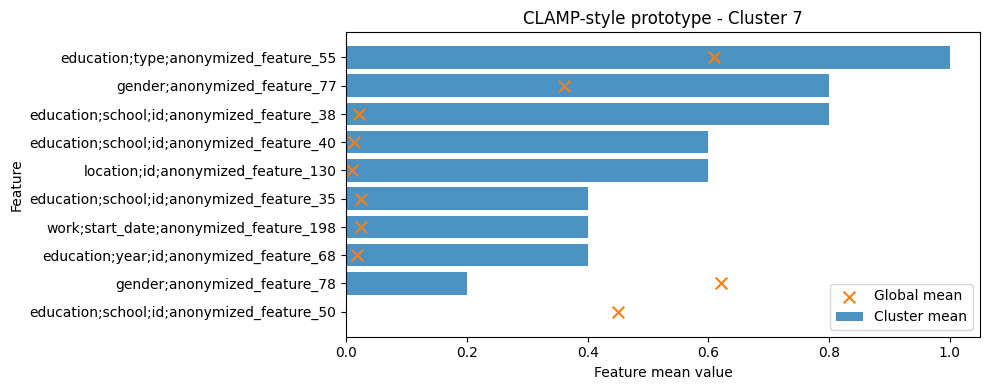

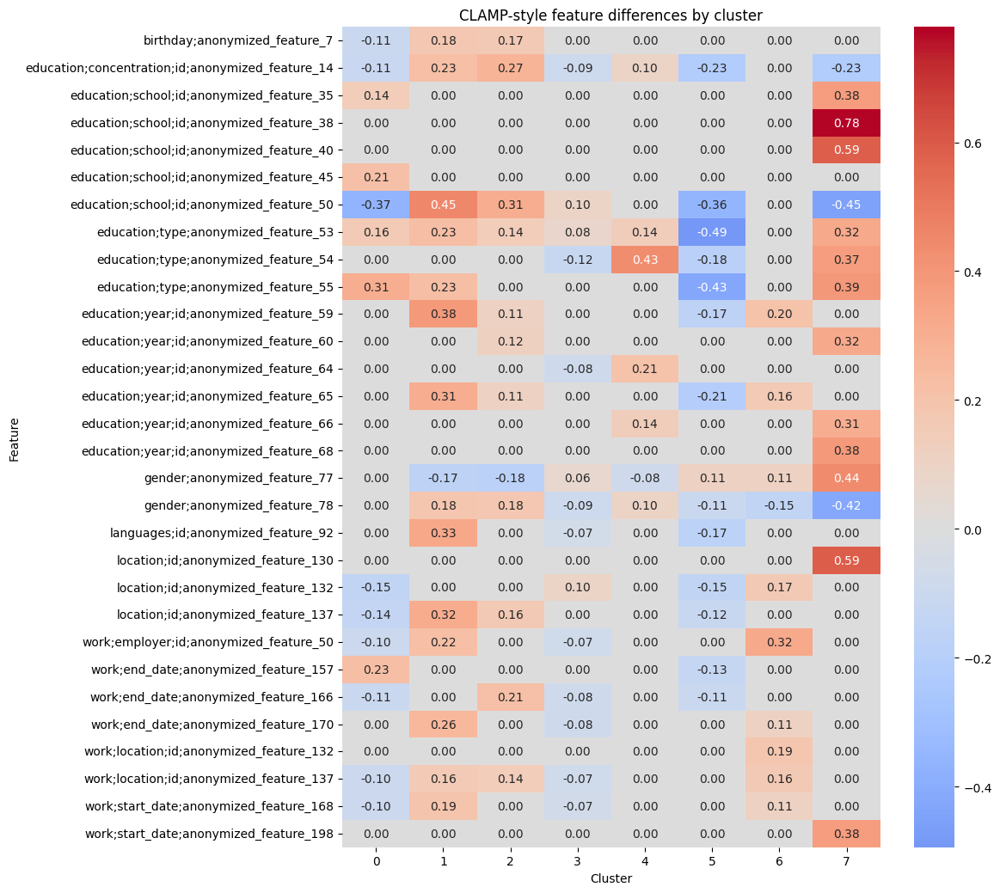


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.468468                          0.48322          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        12           4  

=== Decision tree rules ===
|--- education;school;id;anonymized_feature_50 <= 0.50
|   |--- education;type;anonymized_feature_55 <= 0.50
|   |   |--- education;type;anonymized_feature_53 <= 0.50
|   |   |   |--- gender;anonymized_feature_78 <= 0.50
|   |   |   |   |--- class: 5
|   |   |   |--- gender;anonymized_feature_78 >  0.50
|   |   |   |   |--- class: 5
|   |   |--- education;type;anonymized_feature_53 >  0.50
|   |   |   |--- class: 4
|   |--- education;type;anonymized_feature_55 >  0.50
|   |   |--- work;end_date;anonymized_feature_157 <= 0.50
|   |   |   |--- gender;anonymized_feature_77 <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- gender;anonymized_feature_77 >  0.50
|   |   |   |   |--- class:

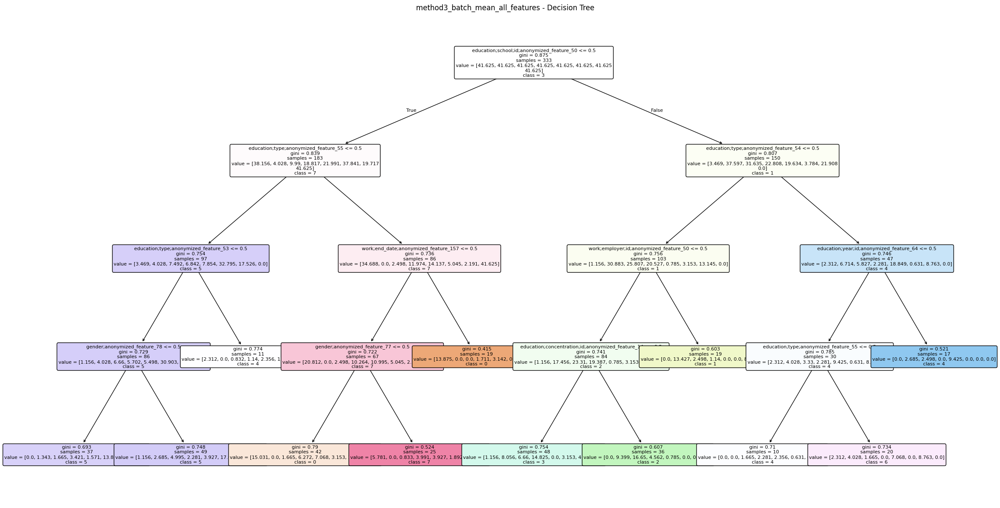


=== Decision tree feature importance ===
education;type;anonymized_feature_55                0.280186
education;school;id;anonymized_feature_50           0.232815
education;type;anonymized_feature_54                0.107511
work;end_date;anonymized_feature_157                0.103868
gender;anonymized_feature_77                        0.096864
work;employer;id;anonymized_feature_50              0.069561
education;concentration;id;anonymized_feature_14    0.052053
education;year;id;anonymized_feature_64             0.029812
education;type;anonymized_feature_53                0.023045
gender;anonymized_feature_78                        0.004284
dtype: float64


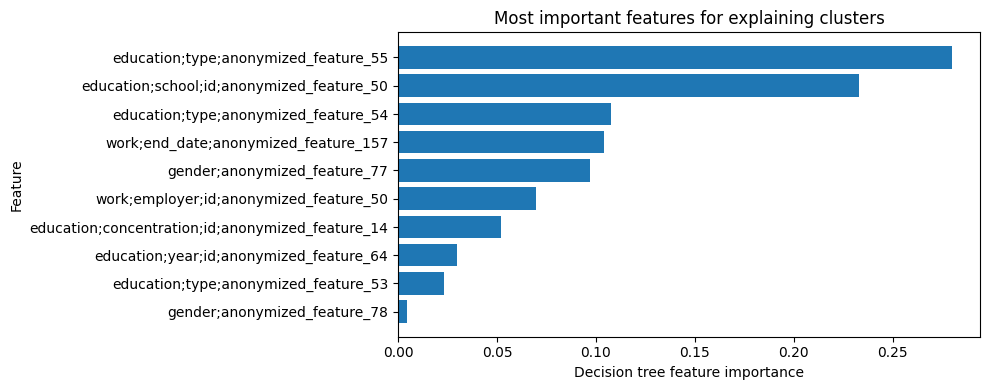


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.166667  0.083333  0.027778  0.055556  0.027778  0.000000  0.638889   
1        0.612903  0.000000  0.290323  0.000000  0.000000  0.000000  0.032258   
2        0.560000  0.040000  0.140000  0.040000  0.000000  0.100000  0.040000   
3        0.356164  0.027397  0.041096  0.054795  0.109589  0.054795  0.301370   
4        0.169811  0.264151  0.018868  0.018868  0.075472  0.000000  0.339623   
5        0.166667  0.000000  0.045455  0.090909  0.060606  0.000000  0.590909   
6        0.684211  0.000000  0.105263  0.000000  0.000000  0.052632  0.052632   
7        0.400000  0.000000  0.000000  0.000000  0.400000  0.000000  0.200000   

         circleOverlap  
cluster                 
0             0.000000  
1             0.064516  
2             0.080000  
3             0.054795  


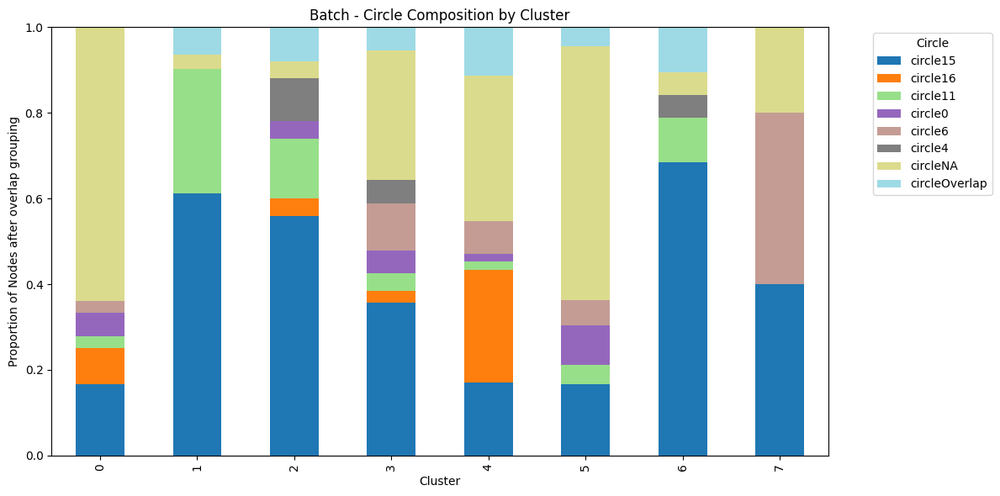

In [34]:
# ============================================================
# CELL 28 - MODEL 3A - Batch DGI with all features
# ============================================================

diagnostics_method3_all, result_method3_all = (
    run_final_dataset_analysis(
        dataset_name="method3_batch_mean_all_features",
        n_clusters=K_ALL_FEATURES,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: method3_batch_mean_circles_only
Embeddings shape: (333, 64)
Features shape: (333, 7)
Membership shape: (333, 8)

Running diagnostics for: method3_batch_mean_circles_only

=== method3_batch_mean_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.683639        1034.343298        0.469708                 2   
3     0.556186        1044.628262        0.594426                 3   
6     0.445815        1010.465690        0.836429                 4   
9     0.480554        1086.127796        0.744350                 5   
12    0.468484        1076.680752        0.730890                 6   
15    0.425907        1127.610234        0.794636                 7   
18    0.454501        1191.533810        0.754277                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3         ok   
6                     True 

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


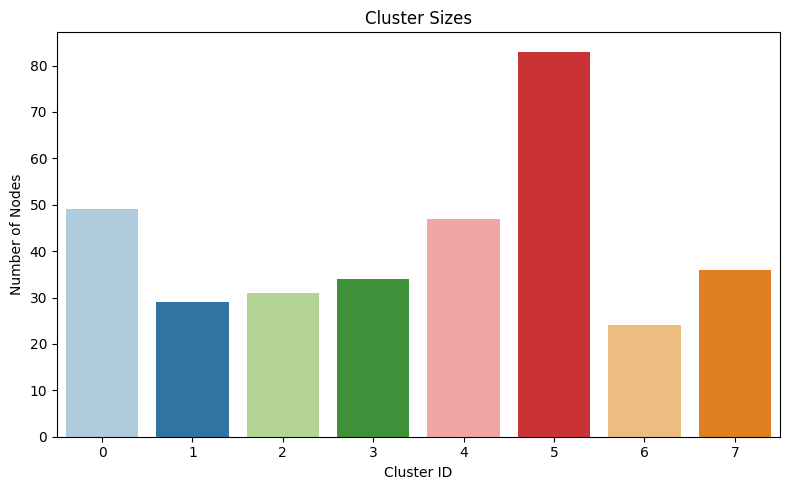


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.077770         0.250182         0.119166         0.311027   
1               0.000000         1.661429         1.881666         3.780684   
2               0.000014         0.925913         1.032793         2.156663   
3               0.003902         0.072334         0.045373         0.952390   
4               0.002072         0.398895         0.347690         0.835240   
5               0.018181         0.166652         0.120830         0.365780   
6               0.000000         1.333756         1.546449         3.054951   
7               0.000729         0.594530         0.622412         1.498466   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               1.801992 

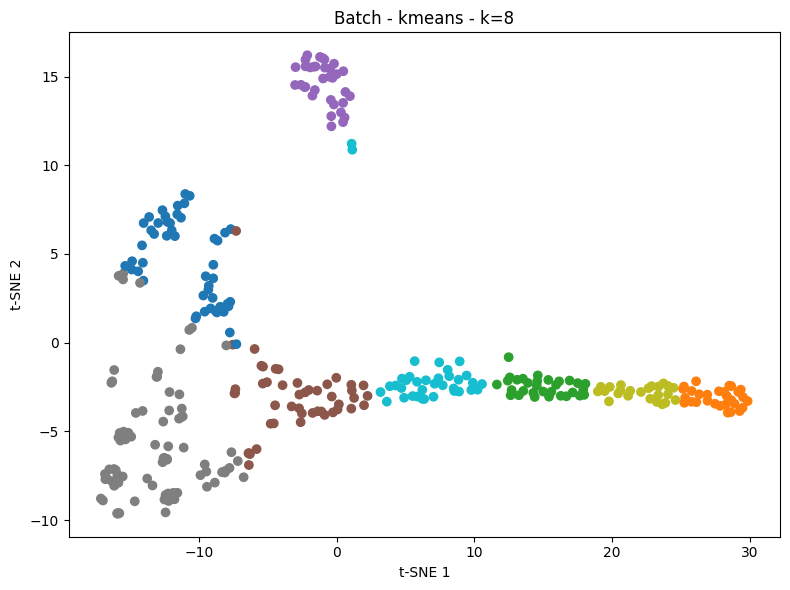

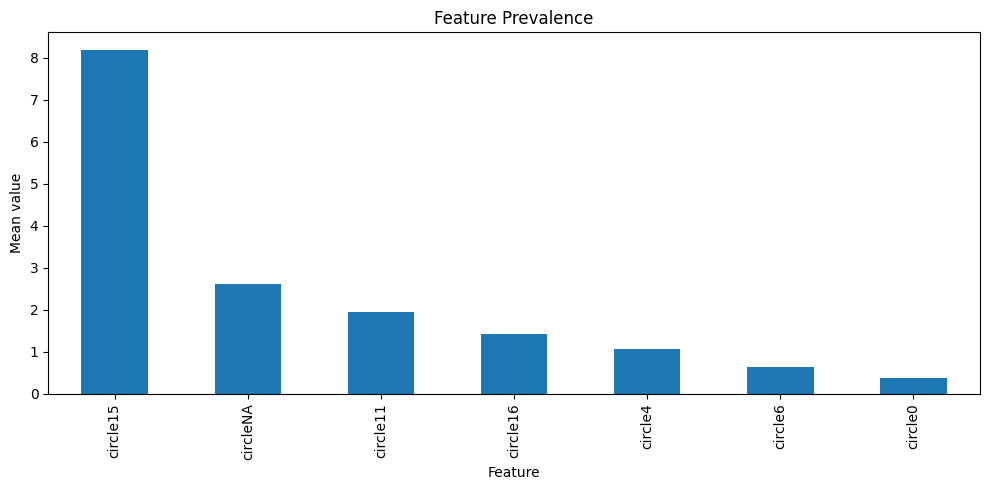


=== Cluster feature profiles ===
          circle15  circle16   circle11   circle0   circle6   circle4  \
cluster                                                                 
0         0.632653  0.081633   0.326531  0.040816  3.755102  0.020408   
1        36.379310  1.931034  10.241379  1.275862  0.000000  5.862069   
2        13.516129  0.612903   3.193548  0.580645  0.000000  1.935484   
3         4.941176  9.588235   0.205882  0.117647  0.000000  0.088235   
4         3.404255  0.063830   0.553191  0.553191  0.042553  0.191489   
5         0.506024  0.192771   0.048193  0.216867  0.361446  0.024096   
6        22.666667  0.916667   5.875000  0.583333  0.000000  3.250000   
7         8.583333  0.777778   1.583333  0.166667  0.000000  0.888889   

         circleNA  
cluster            
0        6.693878  
1        3.758621  
2        1.645161  
3        4.588235  
4        1.319149  
5        1.096386  
6        1.625000  
7        0.888889  


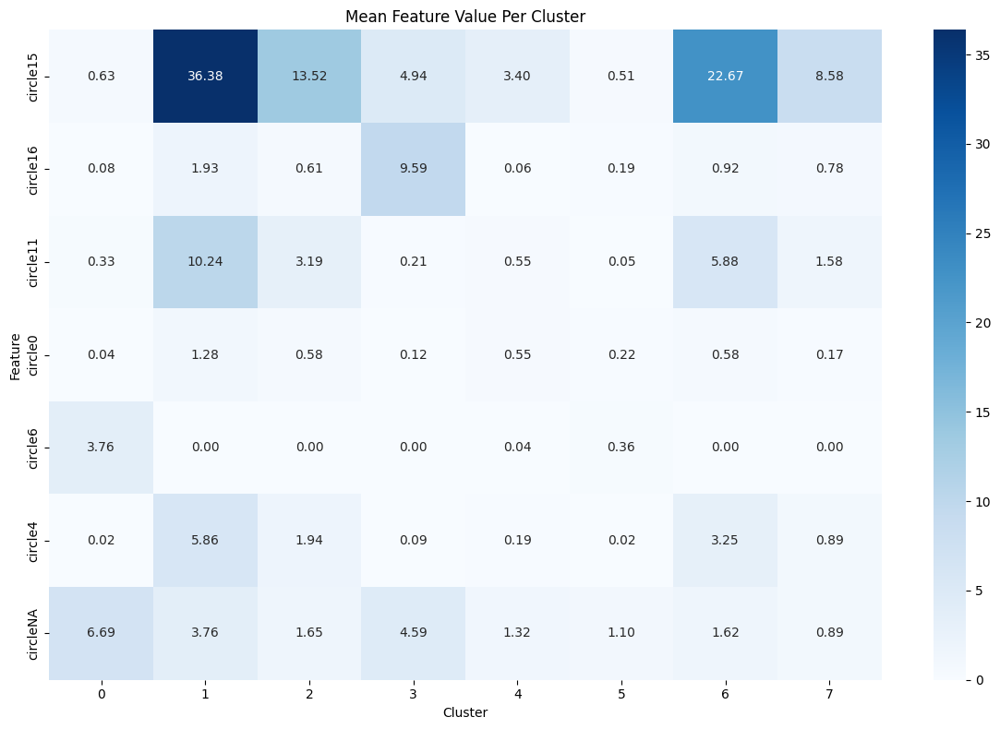

Features with > 30% prevalence/value in at least one cluster:
          circle15  circle16   circle11   circle0   circle6   circle4  \
cluster                                                                 
0         0.632653  0.081633   0.326531  0.040816  3.755102  0.020408   
1        36.379310  1.931034  10.241379  1.275862  0.000000  5.862069   
2        13.516129  0.612903   3.193548  0.580645  0.000000  1.935484   
3         4.941176  9.588235   0.205882  0.117647  0.000000  0.088235   
4         3.404255  0.063830   0.553191  0.553191  0.042553  0.191489   
5         0.506024  0.192771   0.048193  0.216867  0.361446  0.024096   
6        22.666667  0.916667   5.875000  0.583333  0.000000  3.250000   
7         8.583333  0.777778   1.583333  0.166667  0.000000  0.888889   

         circleNA  
cluster            
0        6.693878  
1        3.758621  
2        1.645161  
3        4.588235  
4        1.319149  
5        1.096386  
6        1.625000  
7        0.888889  

=== To

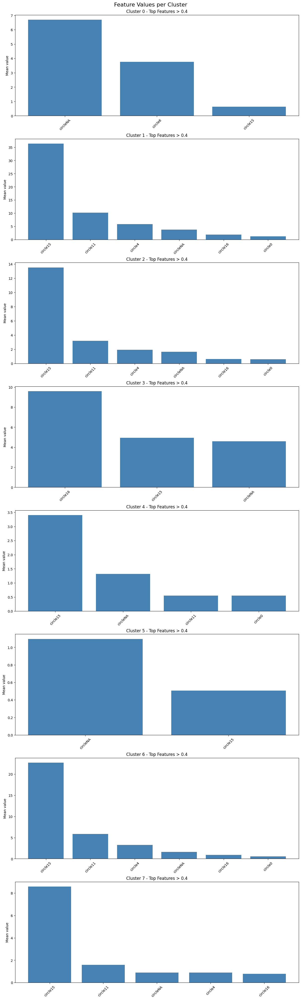


=== CLAMP prototypes ===
    cluster   feature  cluster_prevalence  global_prevalence  prevalence_diff  \
0         0  circle15            0.632653           8.192192        -7.559539   
1         0  circleNA            6.693878           2.606607         4.087271   
2         0   circle6            3.755102           0.648649         3.106453   
3         0  circle11            0.326531           1.942943        -1.616412   
4         0  circle16            0.081633           1.423423        -1.341791   
5         0   circle4            0.020408           1.066066        -1.045658   
6         0   circle0            0.040816           0.375375        -0.334559   
7         1  circle15           36.379310           8.192192        28.187118   
8         1  circle11           10.241379           1.942943         8.298436   
9         1   circle4            5.862069           1.066066         4.796003   
10        1  circleNA            3.758621           2.606607         1.152014   
11

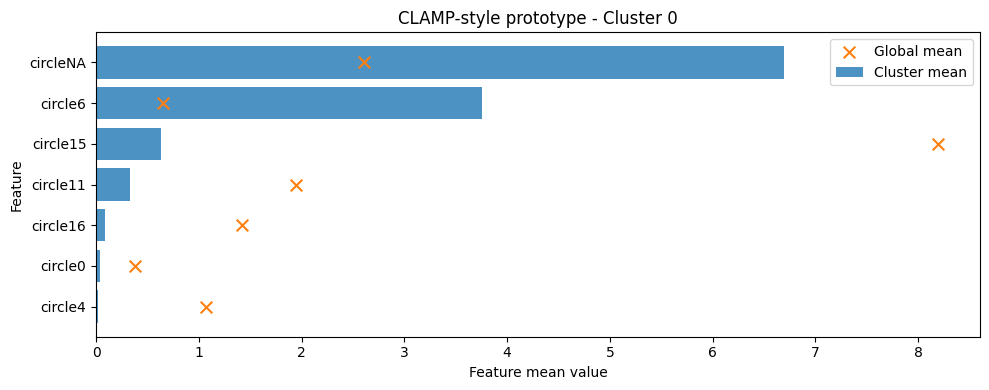

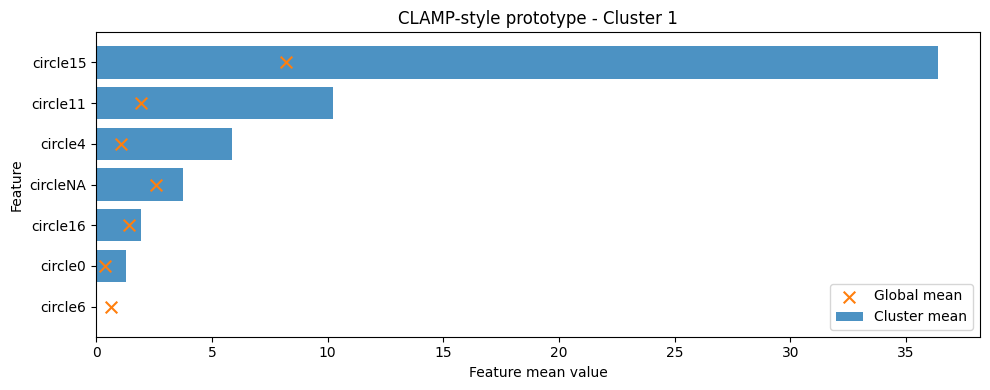

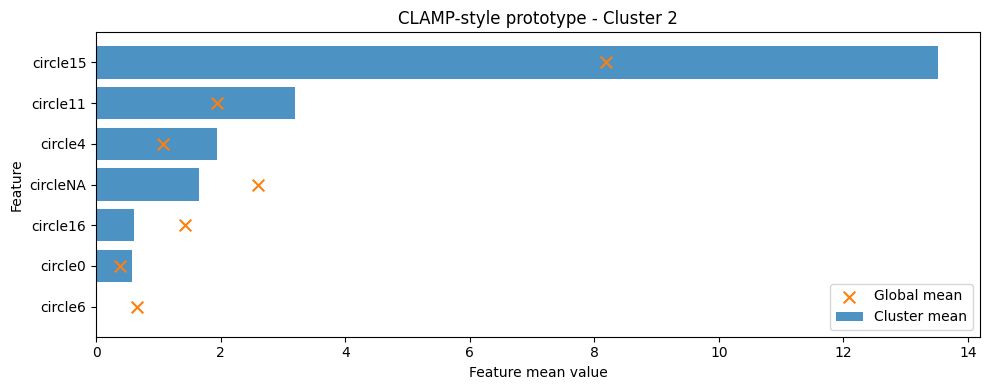

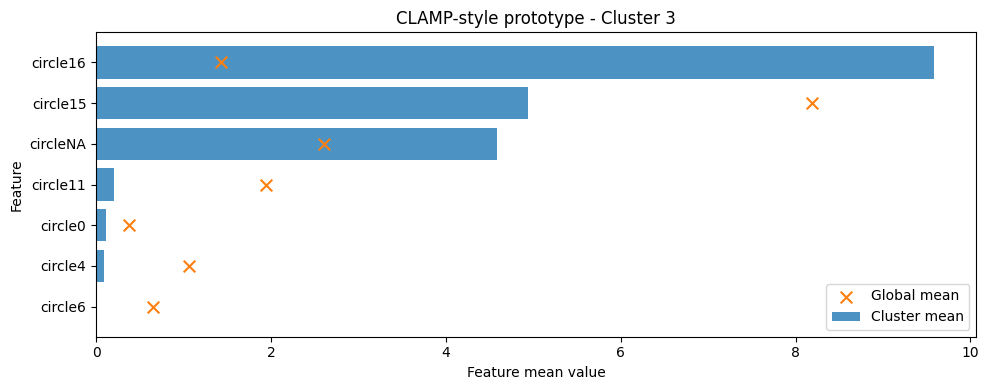

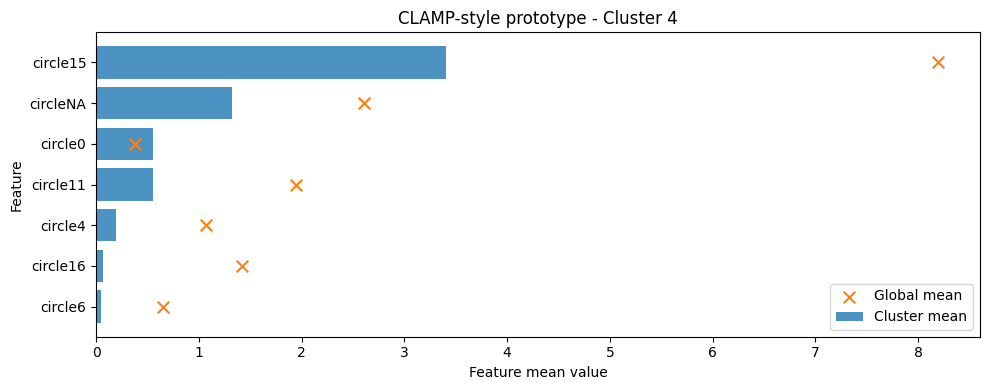

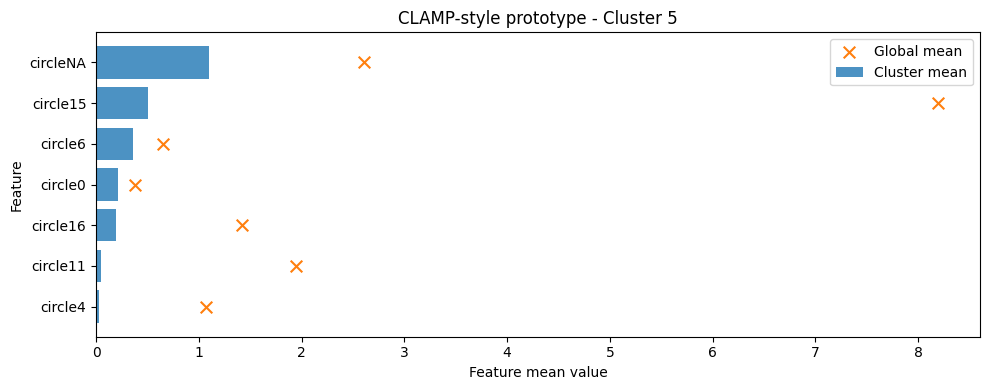

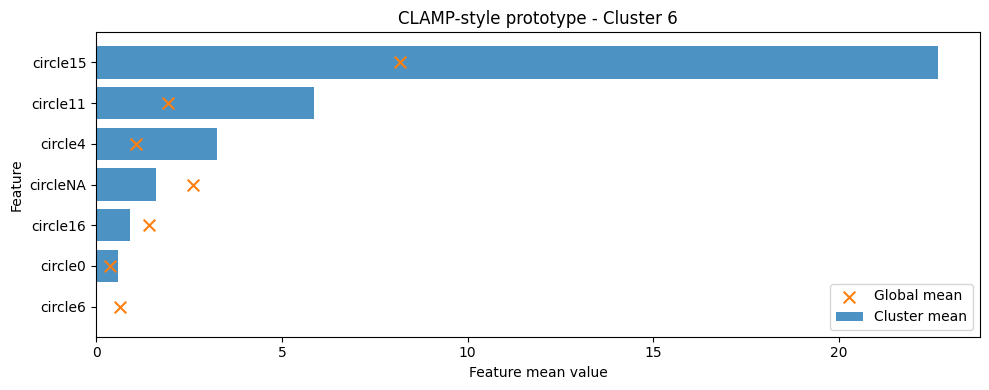

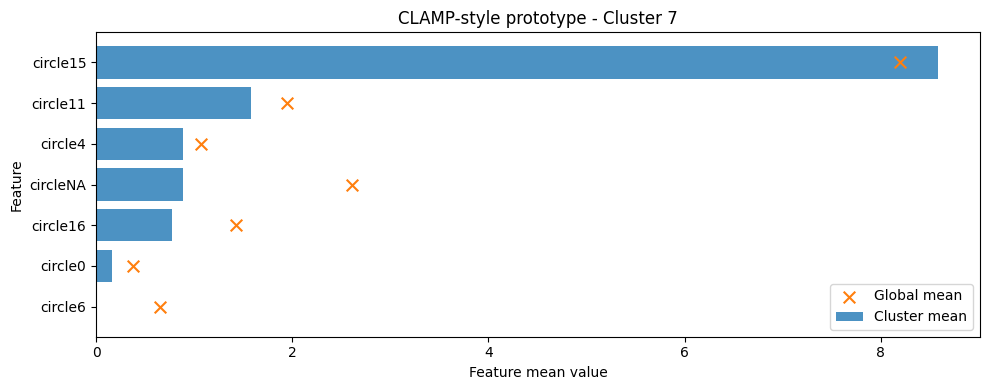

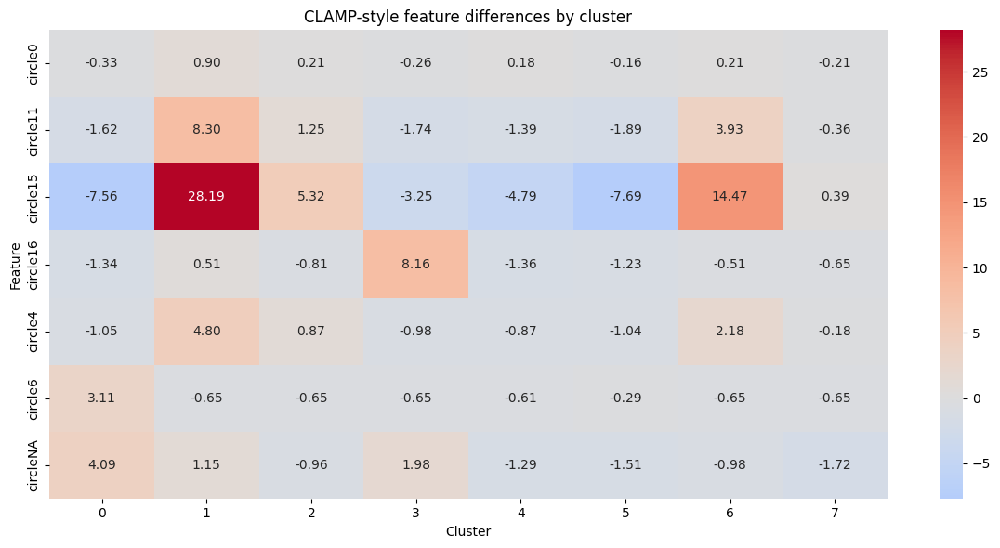


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.783784                         0.765732          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        11           4  

=== Decision tree rules ===
|--- circle16 <= 4.50
|   |--- circle15 <= 5.50
|   |   |--- circleNA <= 3.50
|   |   |   |--- circle15 <= 1.50
|   |   |   |   |--- class: 5
|   |   |   |--- circle15 >  1.50
|   |   |   |   |--- class: 4
|   |   |--- circleNA >  3.50
|   |   |   |--- circleNA <= 5.50
|   |   |   |   |--- class: 0
|   |   |   |--- circleNA >  5.50
|   |   |   |   |--- class: 0
|   |--- circle15 >  5.50
|   |   |--- circle15 <= 16.50
|   |   |   |--- circle4 <= 1.50
|   |   |   |   |--- class: 7
|   |   |   |--- circle4 >  1.50
|   |   |   |   |--- class: 2
|   |   |--- circle15 >  16.50
|   |   |   |--- circle4 <= 5.50
|   |   |   |   |--- class: 6
|   |   |   |--- circle4 >  5.50
|   |   |   |   |--- c

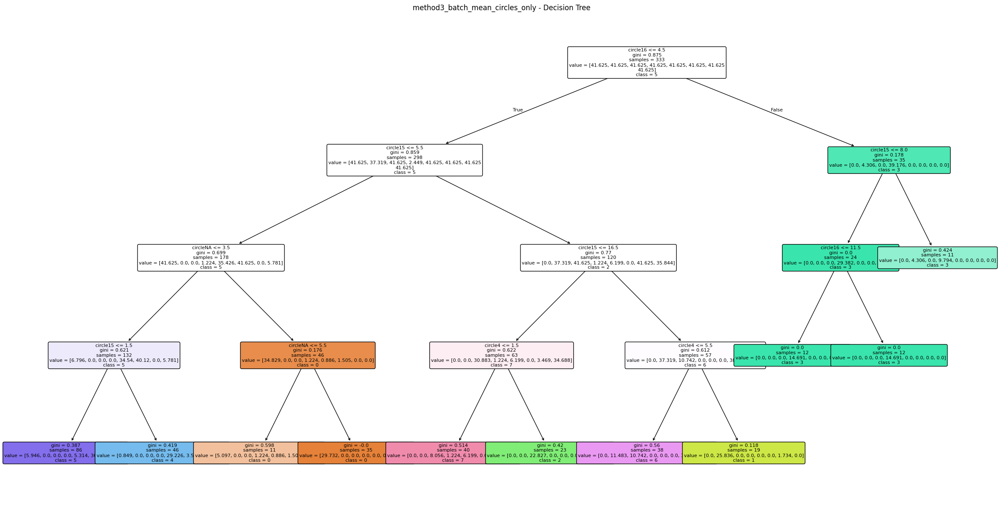


=== Decision tree feature importance ===
circle15    0.470009
circle16    0.202477
circleNA    0.165299
circle4     0.162215
dtype: float64


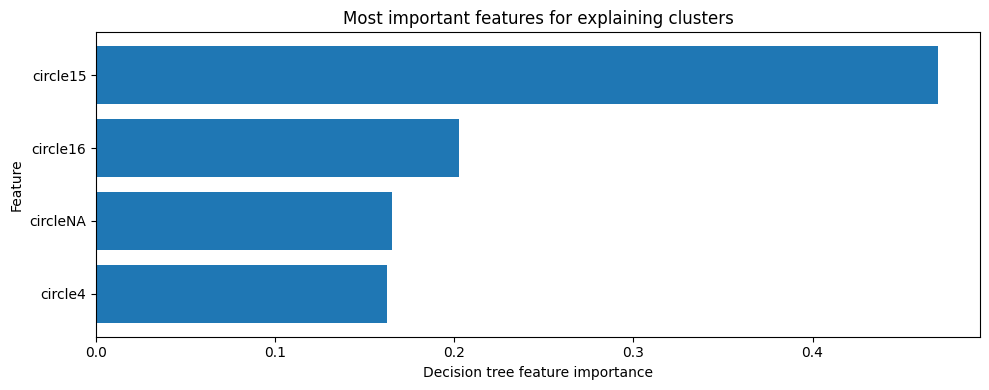


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.061224  0.000000  0.020408  0.000000  0.265306  0.000000  0.653061   
1        0.758621  0.000000  0.103448  0.000000  0.000000  0.034483  0.034483   
2        0.483871  0.000000  0.225806  0.032258  0.000000  0.096774  0.064516   
3        0.088235  0.441176  0.000000  0.000000  0.000000  0.000000  0.235294   
4        0.468085  0.000000  0.042553  0.042553  0.000000  0.021277  0.382979   
5        0.192771  0.048193  0.048193  0.108434  0.072289  0.000000  0.506024   
6        0.541667  0.000000  0.333333  0.000000  0.000000  0.000000  0.041667   
7        0.555556  0.055556  0.027778  0.083333  0.000000  0.138889  0.083333   

         circleOverlap  
cluster                 
0             0.000000  
1             0.068966  
2             0.096774  
3             0.235294  


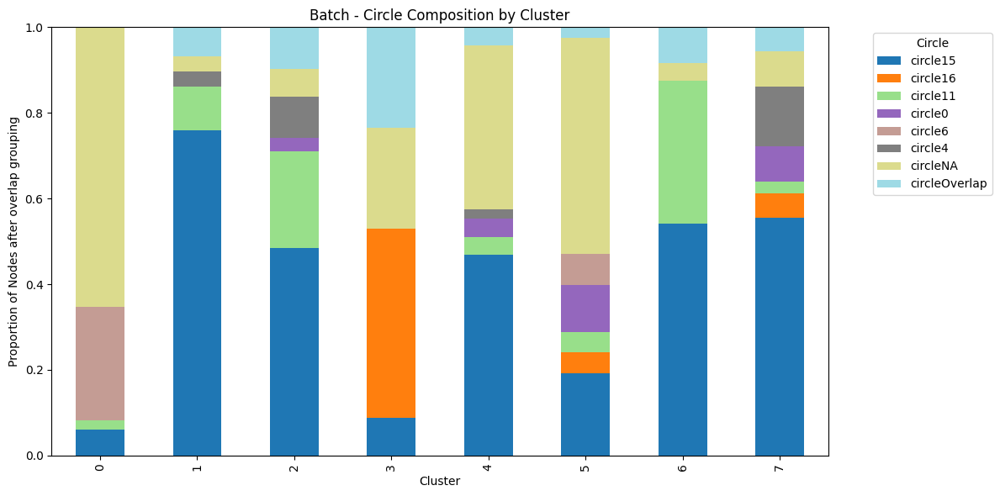

In [35]:
# ============================================================
# CELL 29 - MODEL 3B - Batch DGI with circles-only ARD
# ============================================================

diagnostics_method3_circles, result_method3_circles = (
    run_final_dataset_analysis(
        dataset_name="method3_batch_mean_circles_only",
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: method3_batch_mean_graph_structure_identity_only
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method3_batch_mean_graph_structure_identity_only

=== method3_batch_mean_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.211493          52.434894        1.904840                 2   
3     0.240147          45.407730        2.221190                 3   
6     0.247591          39.494477        2.196794                 4   
9     0.254557          34.712410        1.984434                 5   
12    0.260362          30.043866        2.126011                 6   
15    0.265323          29.311487        1.896343                 7   
18    0.265524          26.225773        2.248087                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


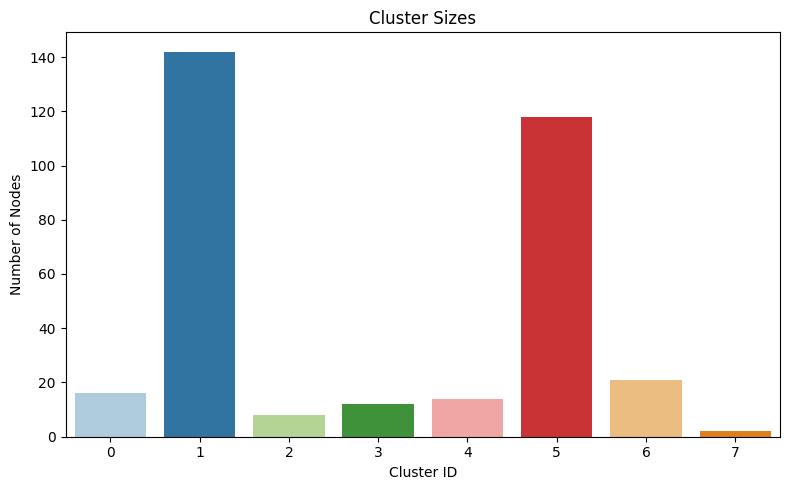


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.101129         0.002003         0.031497         0.017291   
1               0.043239         0.036216         0.008860         0.027473   
2               0.033576         0.005813         0.026786         0.063343   
3               0.039577         0.016612         0.034826         0.006760   
4               0.010479         0.038342         0.031496         0.008417   
5               0.011781         0.016487         0.015040         0.019275   
6               0.028456         0.070843         0.030614         0.031051   
7               0.203048         0.000833         0.042607         0.132228   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.032320 

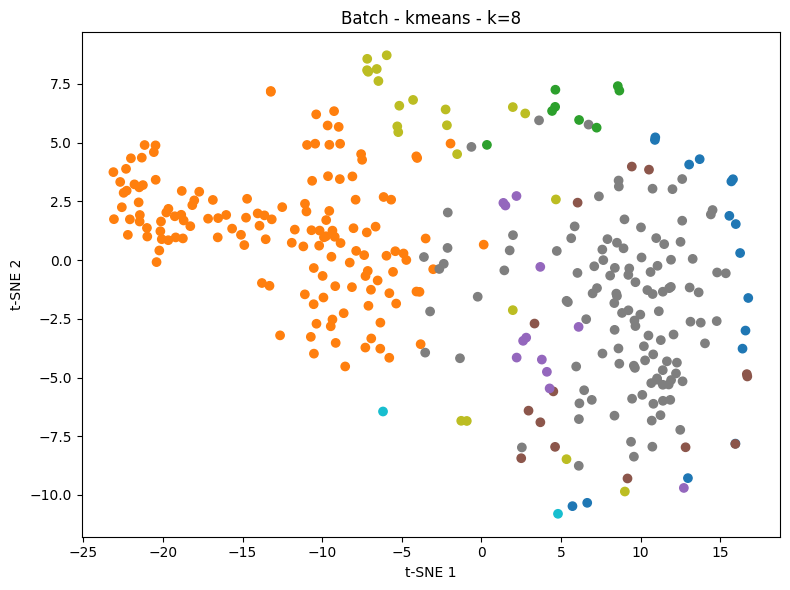

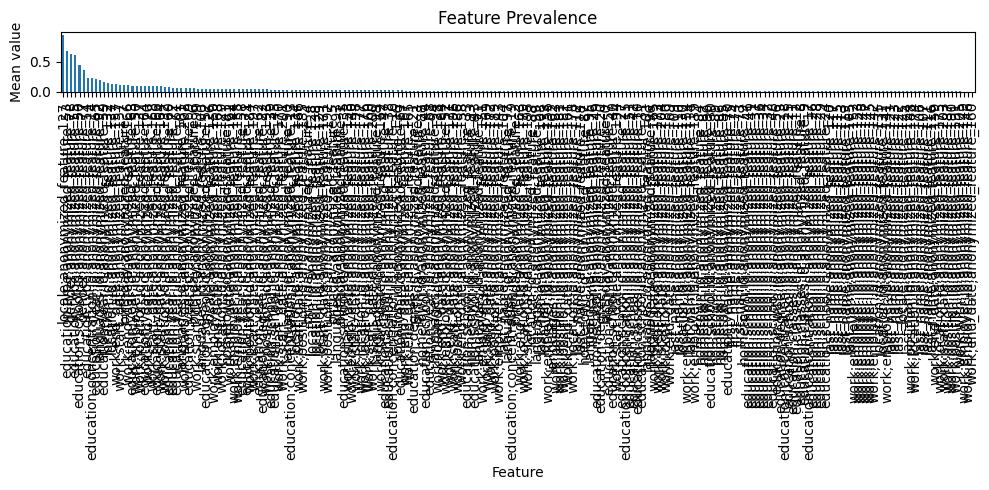


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.062500   
1                             0.007042                       0.007042   
2                             0.000000                       0.000000   
3                             0.000000                       0.000000   
4                             0.000000                       0.071429   
5                             0.025424                       0.042373   
6                             0.000000                       0.000000   
7                             0.000000                       0.000000   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.062500                       0.000000   
1               

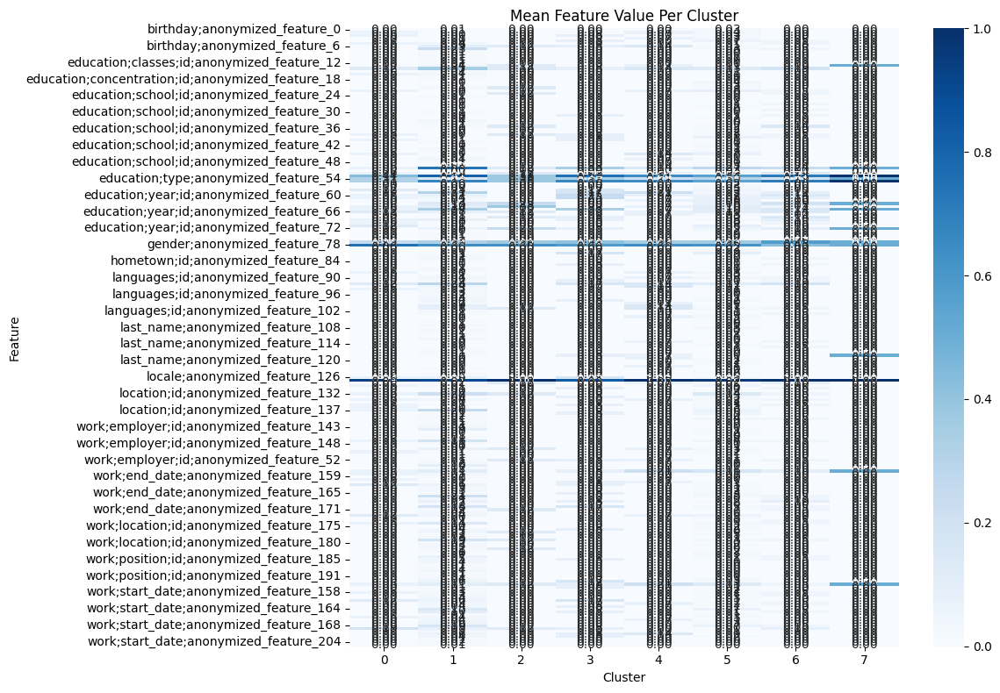

Features with > 30% prevalence/value in at least one cluster:
         education;concentration;id;anonymized_feature_13  \
cluster                                                     
0                                                0.000000   
1                                                0.042254   
2                                                0.125000   
3                                                0.000000   
4                                                0.071429   
5                                                0.008475   
6                                                0.000000   
7                                                0.500000   

         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.125000   
1                                                0.352113   
2                                                0.125000   
3                     

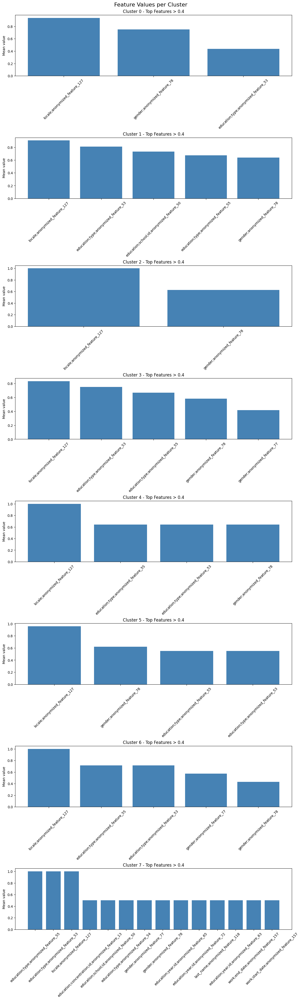


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0         education;school;id;anonymized_feature_50   
1         0              education;type;anonymized_feature_55   
2         0              education;type;anonymized_feature_53   
3         0           education;year;id;anonymized_feature_59   
4         0           education;year;id;anonymized_feature_65   
5         0            work;start_date;anonymized_feature_202   
6         0                      gender;anonymized_feature_78   
7         0                      gender;anonymized_feature_77   
8         0                     birthday;anonymized_feature_7   
9         0              work;end_date;anonymized_feature_166   
10        0           education;year;id;anonymized_feature_63   
11        0  education;concentration;id;anonymized_feature_14   
12        0           work;location;id;anonymized_feature_137   
13        0              work;end_date;anonymized_feature_170   

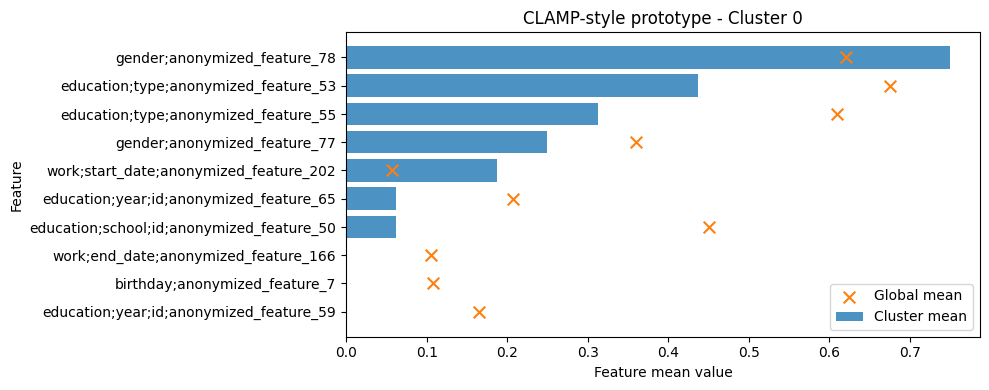

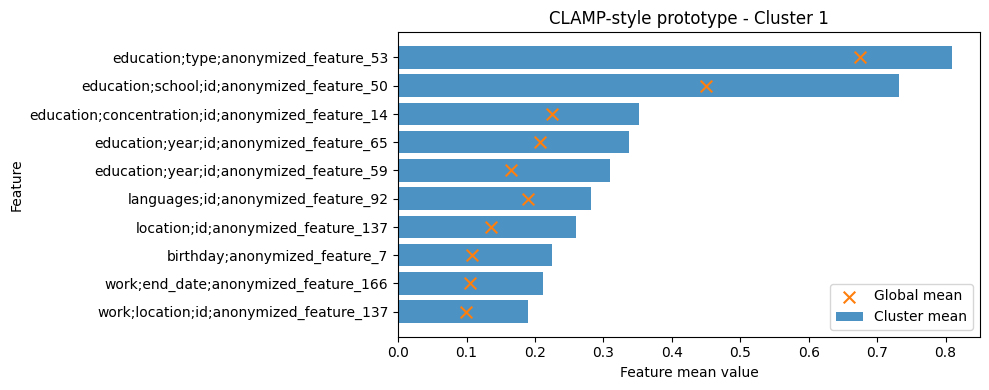

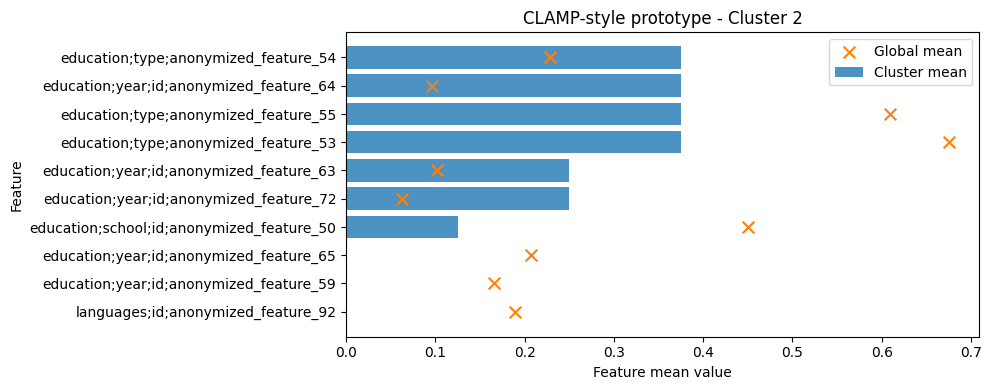

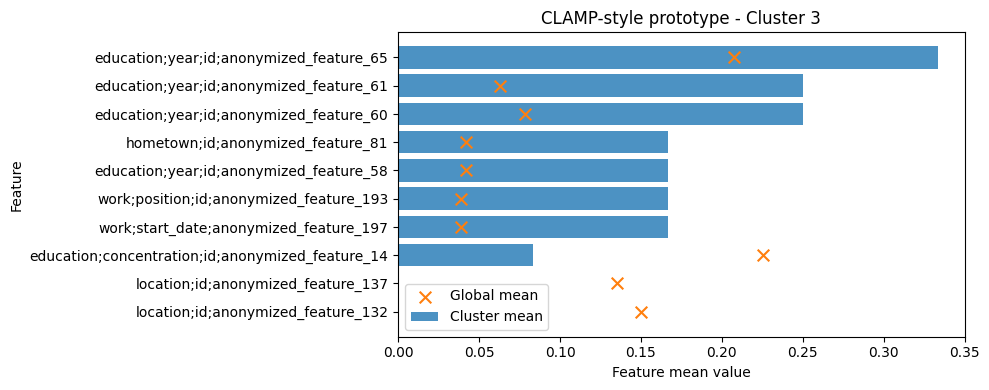

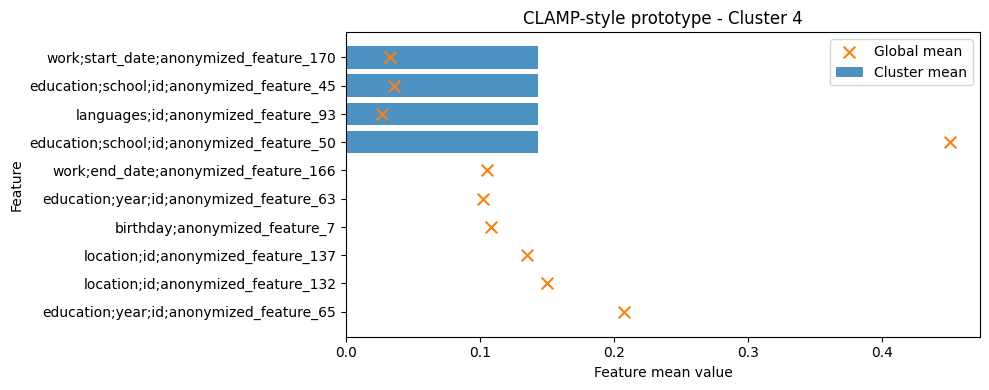

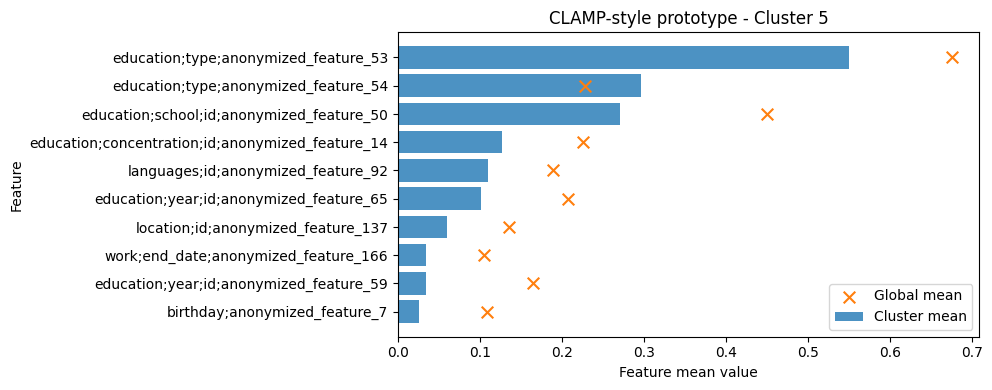

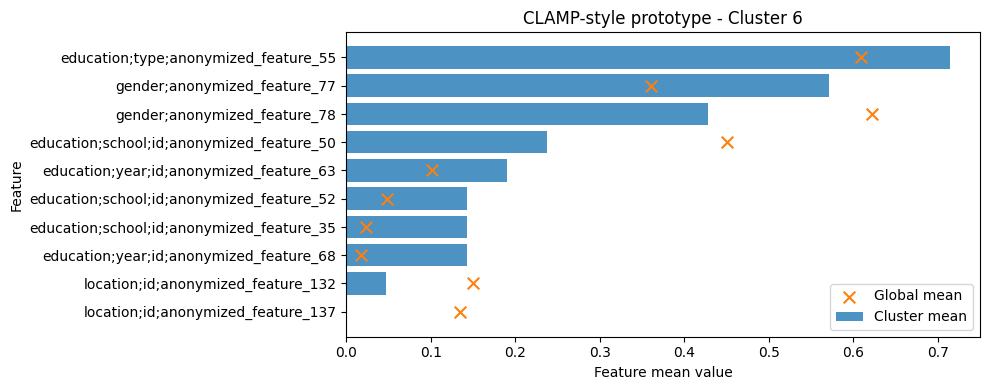

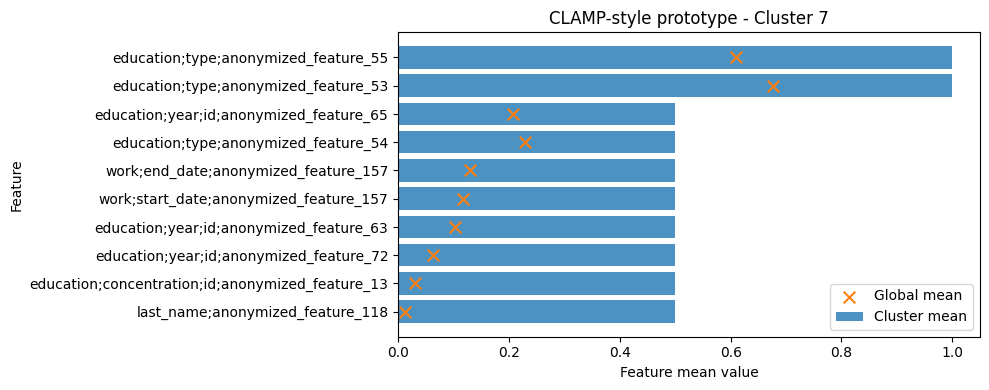

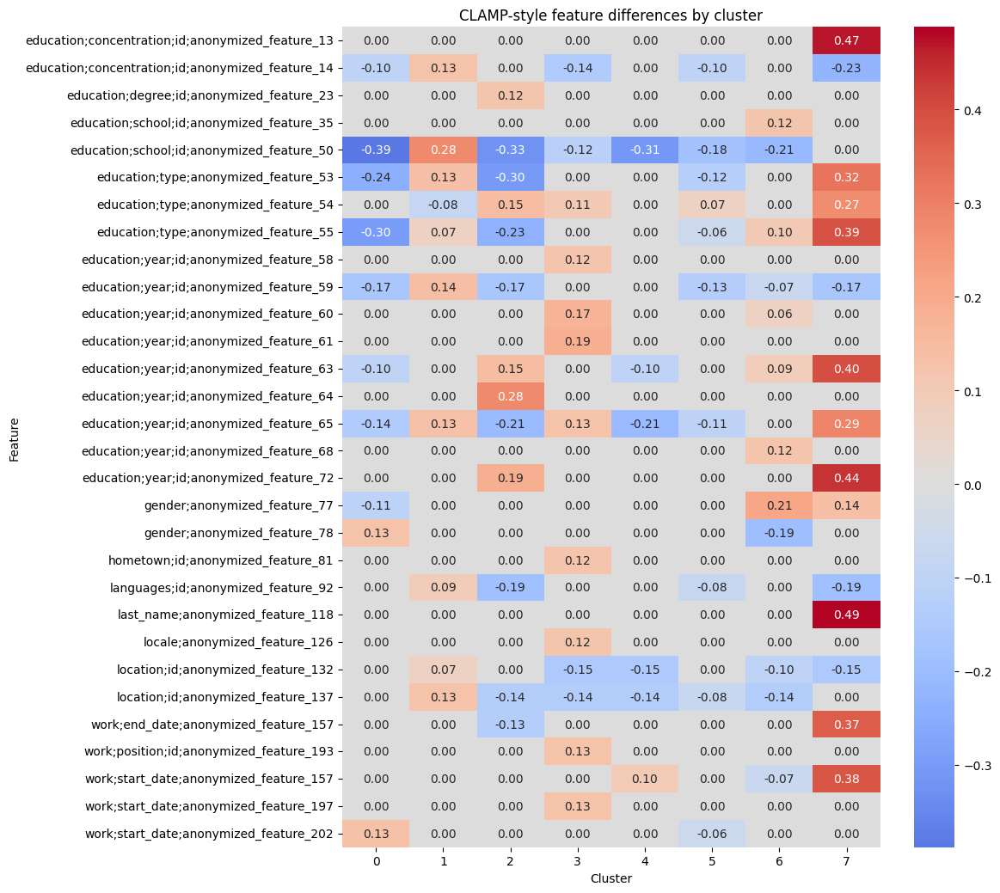


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.333333                          0.38269          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         8           4  

=== Decision tree rules ===
|--- education;concentration;id;anonymized_feature_13 <= 0.50
|   |--- education;school;id;anonymized_feature_50 <= 0.50
|   |   |--- work;start_date;anonymized_feature_157 <= 0.50
|   |   |   |--- hometown;id;anonymized_feature_81 <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- hometown;id;anonymized_feature_81 >  0.50
|   |   |   |   |--- class: 3
|   |   |--- work;start_date;anonymized_feature_157 >  0.50
|   |   |   |--- class: 7
|   |--- education;school;id;anonymized_feature_50 >  0.50
|   |   |--- education;type;anonymized_feature_54 <= 0.50
|   |   |   |--- education;year;id;anonymized_feature_60 <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- education;year;id;anon

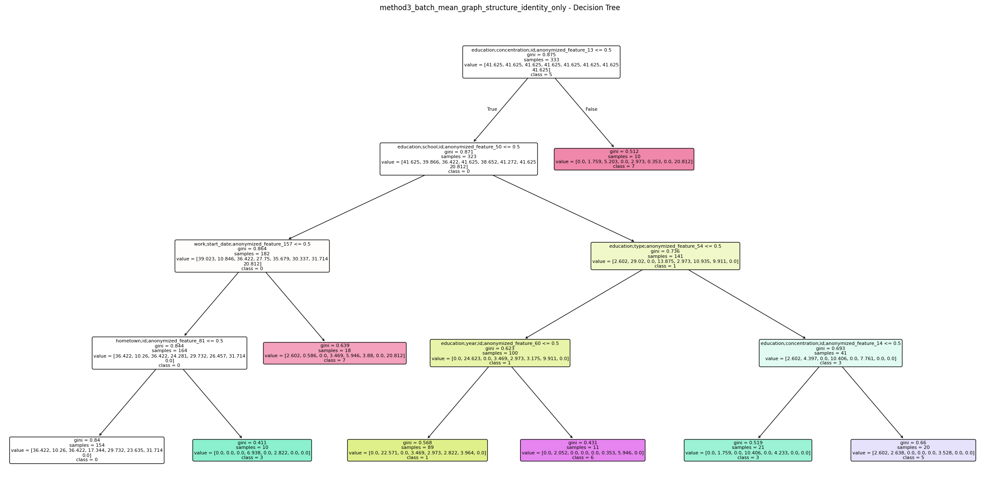


=== Decision tree feature importance ===
education;concentration;id;anonymized_feature_13    0.232625
work;start_date;anonymized_feature_157              0.227719
education;school;id;anonymized_feature_50           0.206780
education;type;anonymized_feature_54                0.113816
hometown;id;anonymized_feature_81                   0.093863
education;year;id;anonymized_feature_60             0.066645
education;concentration;id;anonymized_feature_14    0.058552
dtype: float64


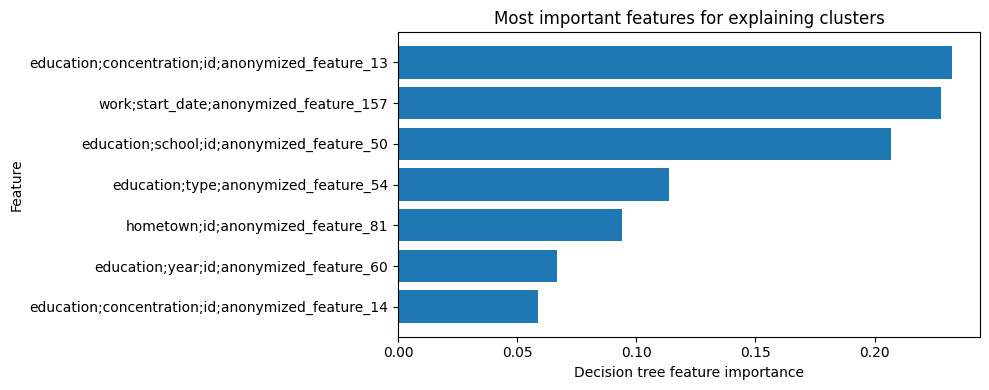


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.125000  0.000000  0.062500  0.000000  0.125000  0.000000  0.625000   
1        0.563380  0.014085  0.140845  0.035211  0.007042  0.063380  0.105634   
2        0.500000  0.000000  0.000000  0.000000  0.125000  0.000000  0.375000   
3        0.250000  0.000000  0.083333  0.083333  0.000000  0.000000  0.583333   
4        0.142857  0.000000  0.071429  0.071429  0.000000  0.000000  0.714286   
5        0.127119  0.144068  0.025424  0.050847  0.118644  0.008475  0.449153   
6        0.333333  0.095238  0.000000  0.095238  0.047619  0.000000  0.380952   
7        0.500000  0.000000  0.000000  0.000000  0.000000  0.000000  0.500000   

         circleOverlap  
cluster                 
0             0.062500  
1             0.070423  
2             0.000000  
3             0.000000  


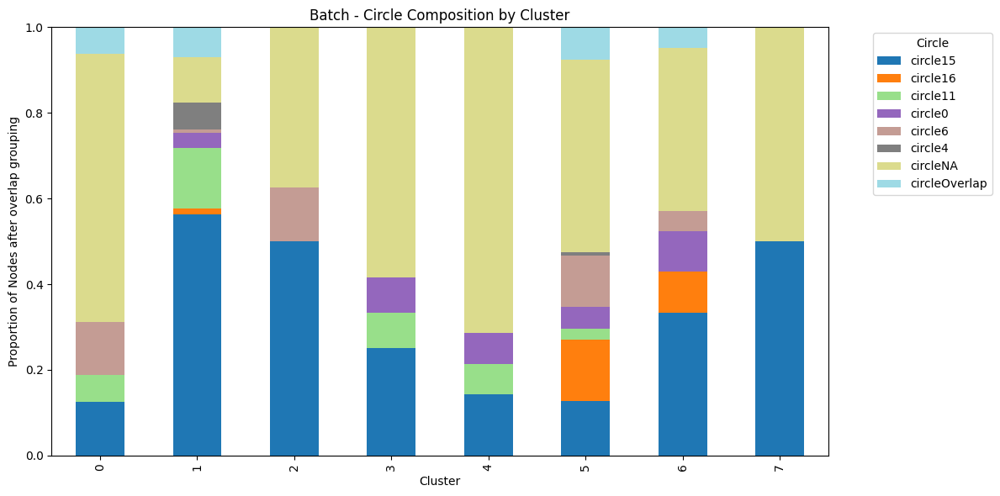

In [36]:
# ============================================================
# CELL 30 - MODEL 3C - Batch DGI with structure only
# ============================================================

diagnostics_method3_structure, result_method3_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method3_batch_mean_"
            "graph_structure_identity_only"
        ),
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)

Dataset loaded: method2_shared_sequential_TRAINING_MEAN_all_features
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method2_shared_sequential_TRAINING_MEAN_all_features

=== method2_shared_sequential_TRAINING_MEAN_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.184666          74.843540        1.322281                 2   
3     0.217588          61.610257        1.878653                 3   
6     0.231746          56.275777        1.658681                 4   
9     0.216661          55.611393        1.727714                 5   
12    0.184809          51.061159        1.671015                 6   
15    0.194112          47.085067        1.635667                 7   
18    0.209627          43.038147        1.745220                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3             

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


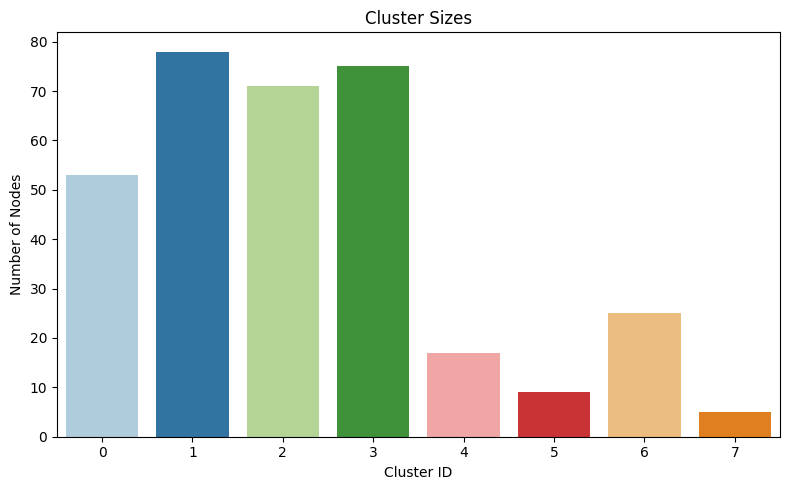


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.240512              0.0         0.015211         0.109590   
1               0.175169              0.0         0.041418         0.085774   
2               0.166091              0.0         0.015959         0.134304   
3               0.236617              0.0         0.023068         0.159094   
4               0.065426              0.0         0.105152         0.074471   
5               0.137881              0.0         0.262687         0.113556   
6               0.110307              0.0         0.034898         0.081566   
7               0.144272              0.0         0.005604         0.032217   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.059937 

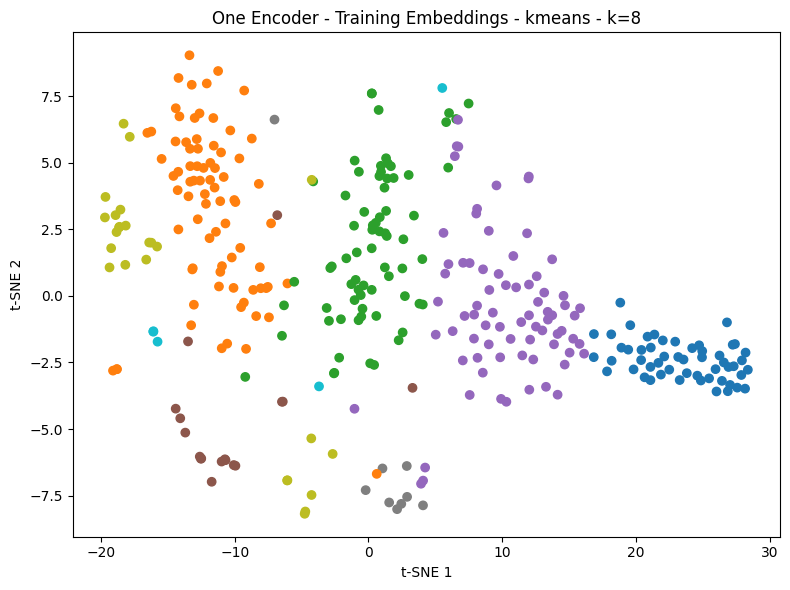

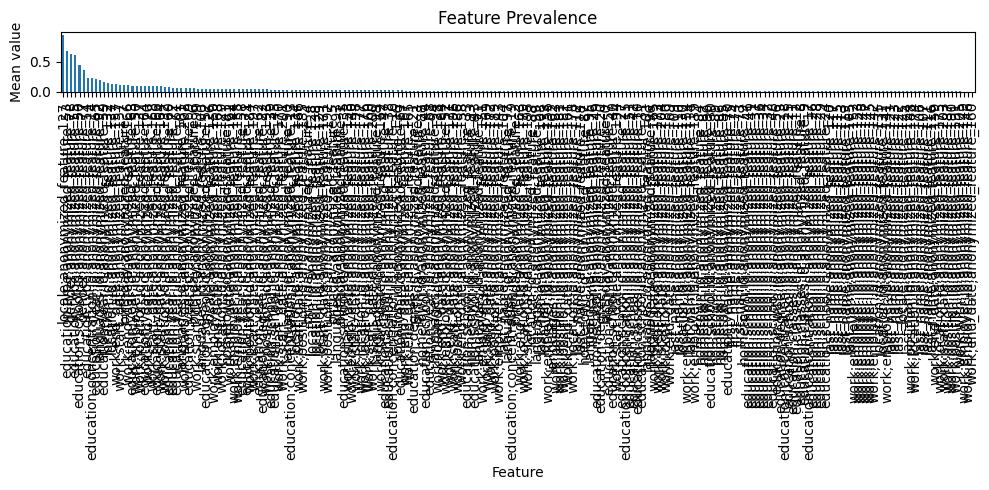


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.000000   
1                             0.051282                       0.064103   
2                             0.000000                       0.014085   
3                             0.000000                       0.000000   
4                             0.000000                       0.058824   
5                             0.000000                       0.000000   
6                             0.000000                       0.000000   
7                             0.000000                       0.200000   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.000000                       0.000000   
1               

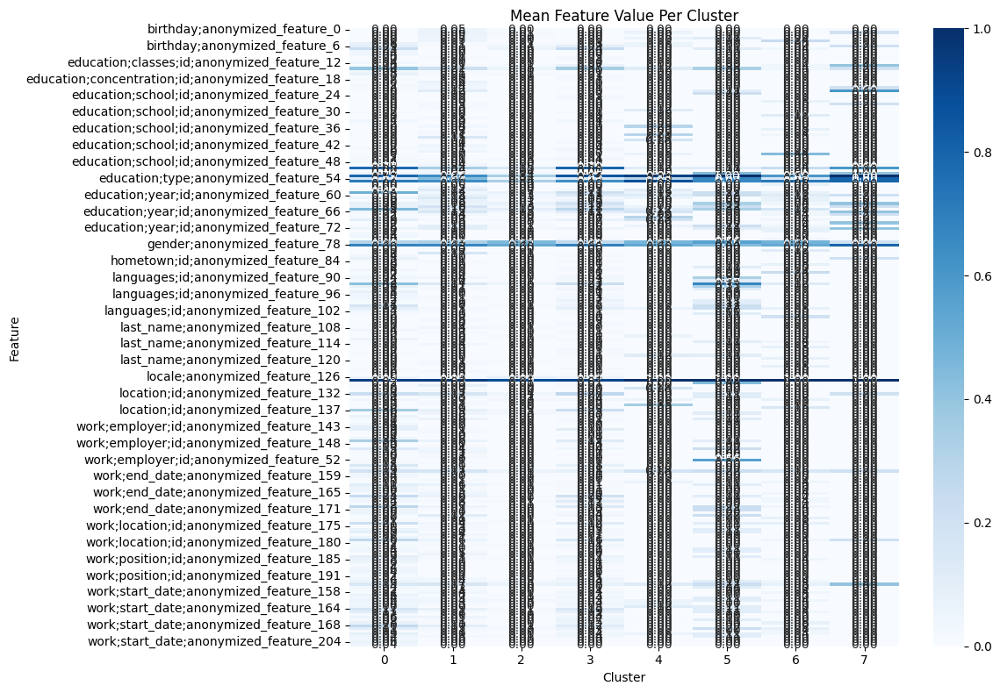

Features with > 30% prevalence/value in at least one cluster:
         education;concentration;id;anonymized_feature_13  \
cluster                                                     
0                                                0.000000   
1                                                0.012821   
2                                                0.014085   
3                                                0.066667   
4                                                0.000000   
5                                                0.000000   
6                                                0.040000   
7                                                0.400000   

         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.396226   
1                                                0.217949   
2                                                0.056338   
3                     

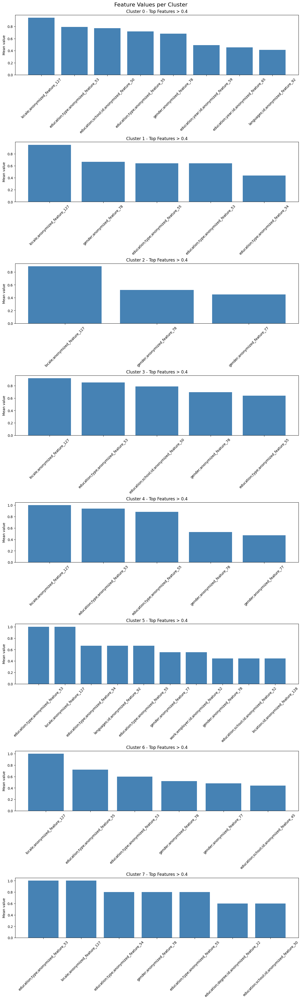


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0           education;year;id;anonymized_feature_59   
1         0         education;school;id;anonymized_feature_50   
2         0           education;year;id;anonymized_feature_65   
3         0            work;employer;id;anonymized_feature_50   
4         0                languages;id;anonymized_feature_92   
5         0                location;id;anonymized_feature_137   
6         0              work;end_date;anonymized_feature_170   
7         0  education;concentration;id;anonymized_feature_14   
8         0            work;start_date;anonymized_feature_168   
9         0           work;location;id;anonymized_feature_137   
10        0              work;end_date;anonymized_feature_166   
11        0           work;location;id;anonymized_feature_132   
12        0               languages;id;anonymized_feature_100   
13        0                     birthday;anonymized_feature_7   

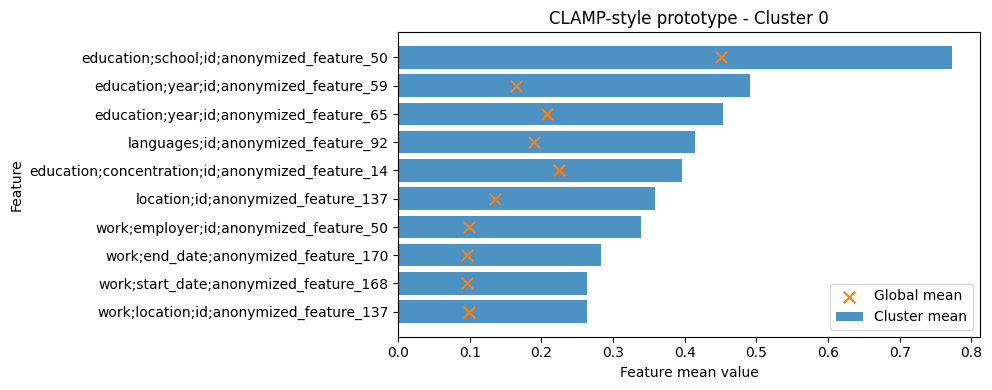

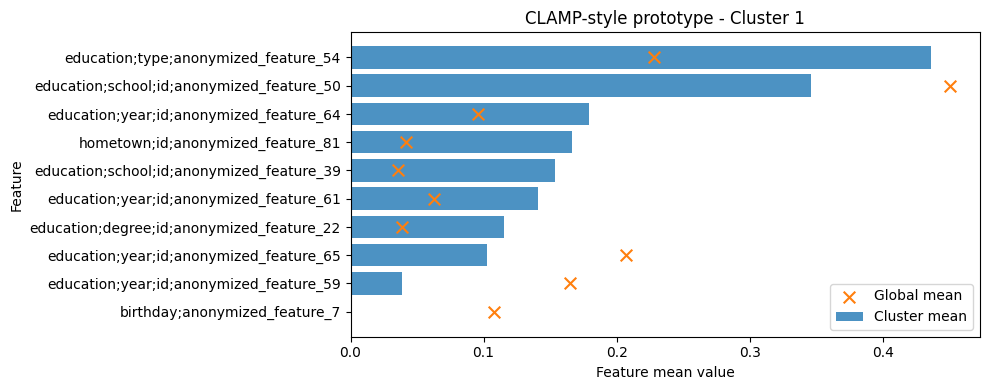

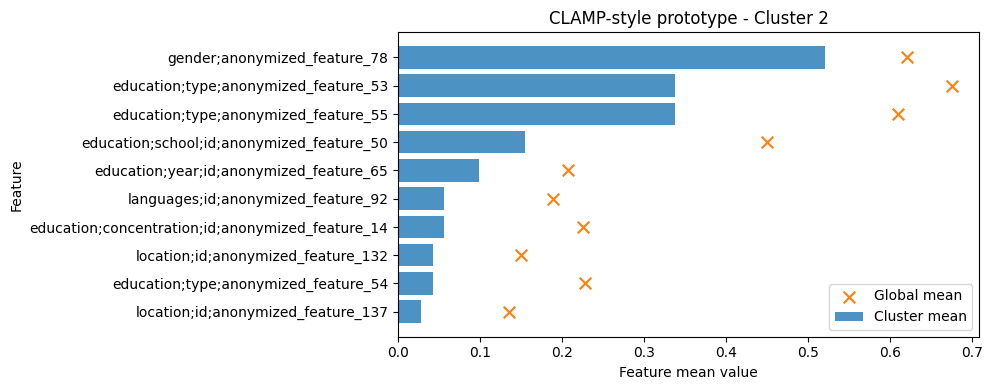

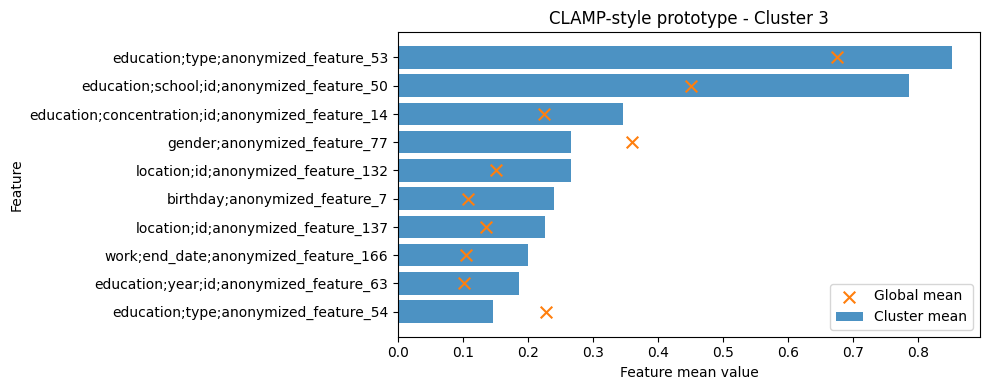

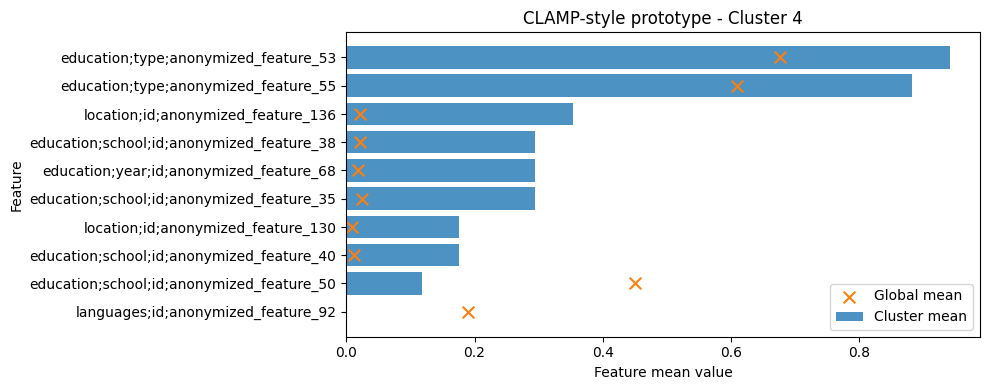

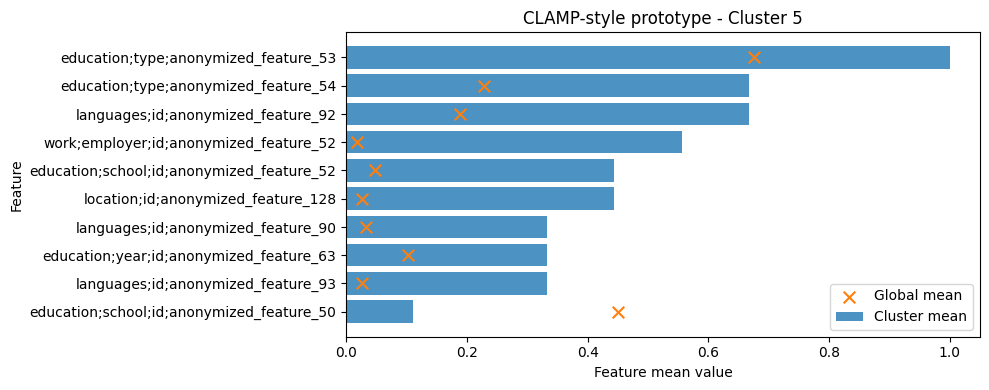

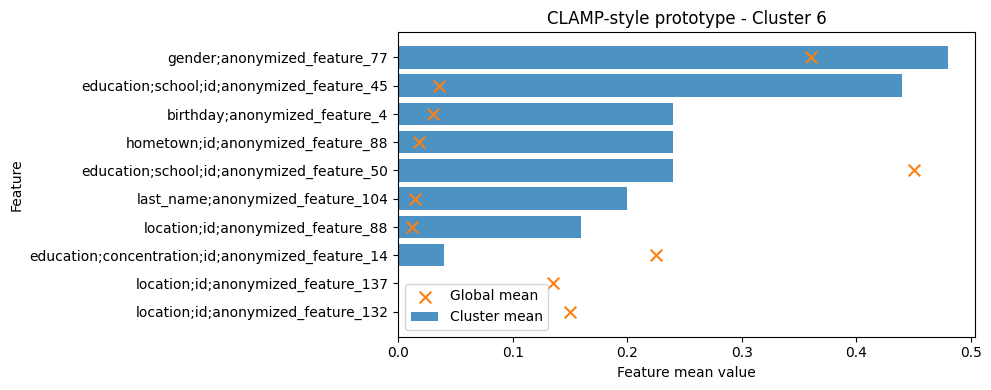

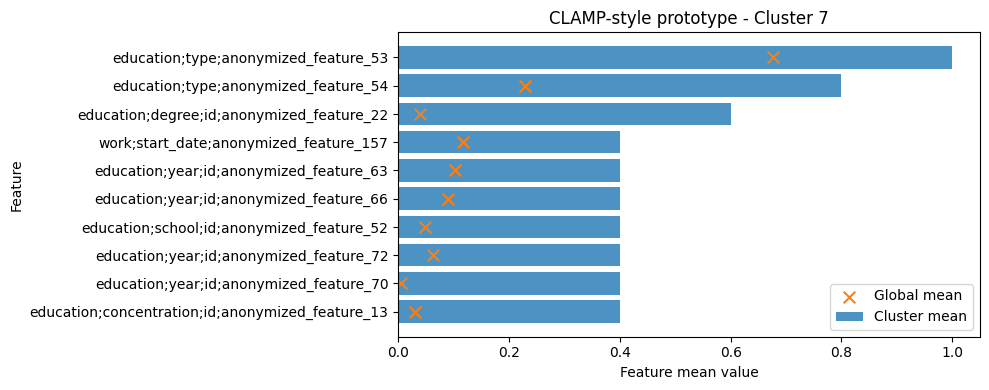

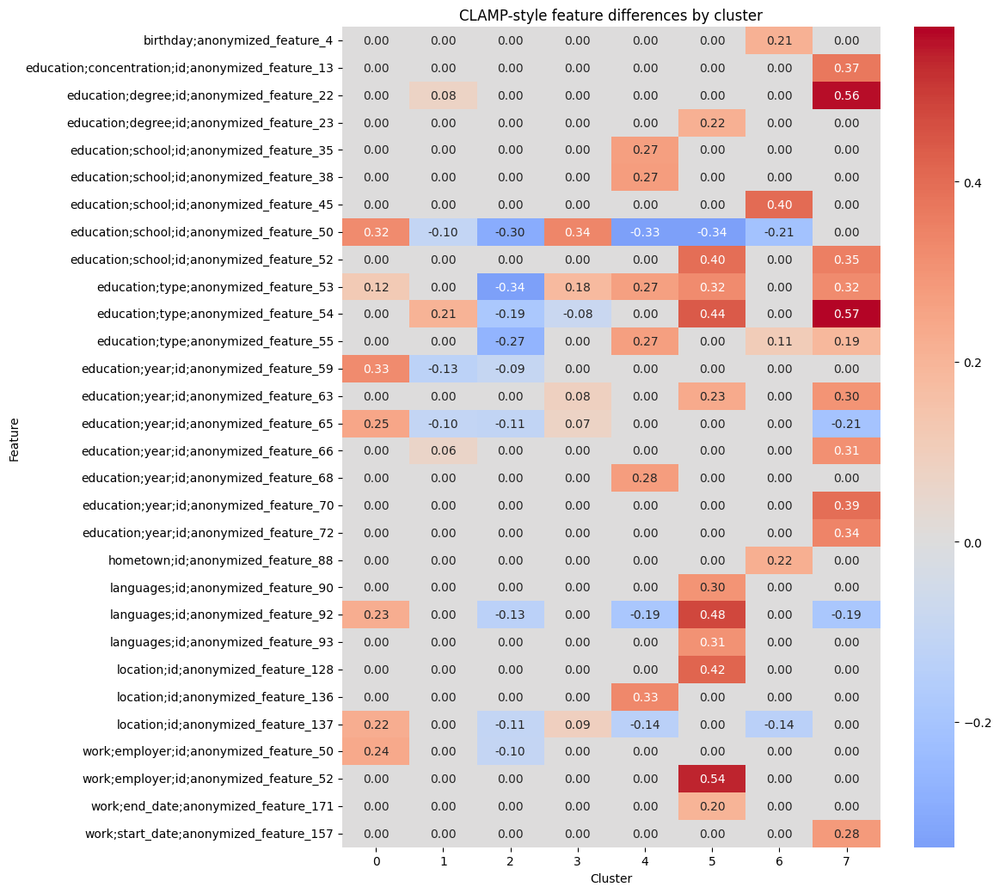


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.216216                          0.43965          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         6           4  

=== Decision tree rules ===
|--- education;degree;id;anonymized_feature_22 <= 0.50
|   |--- education;school;id;anonymized_feature_45 <= 0.50
|   |   |--- education;school;id;anonymized_feature_50 <= 0.50
|   |   |   |--- languages;id;anonymized_feature_92 <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- languages;id;anonymized_feature_92 >  0.50
|   |   |   |   |--- class: 5
|   |   |--- education;school;id;anonymized_feature_50 >  0.50
|   |   |   |--- education;year;id;anonymized_feature_63 <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- education;year;id;anonymized_feature_63 >  0.50
|   |   |   |   |--- class: 7
|   |--- education;school;id;anonymized_feature_45 >  0.50
|   |   |--- class: 6
|--- 

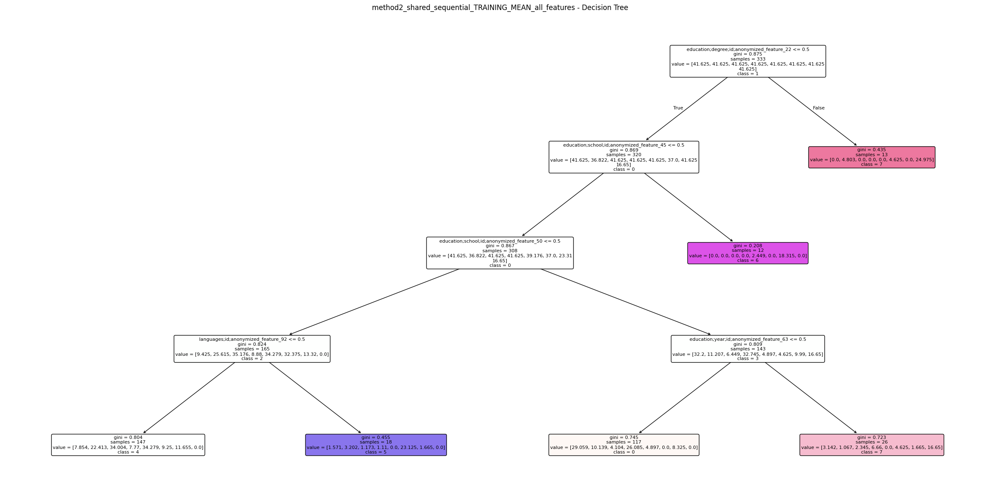


=== Decision tree feature importance ===
education;degree;id;anonymized_feature_22    0.249367
education;school;id;anonymized_feature_45    0.212489
languages;id;anonymized_feature_92           0.211207
education;school;id;anonymized_feature_50    0.203731
education;year;id;anonymized_feature_63      0.123207
dtype: float64


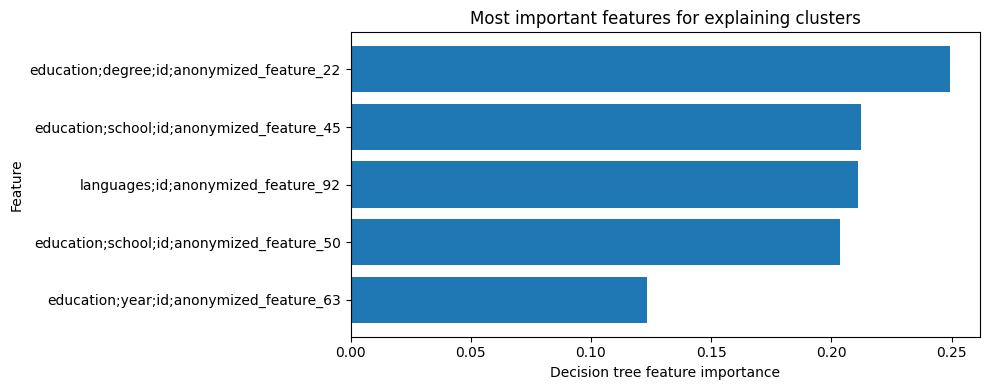


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.660377  0.000000  0.207547  0.000000  0.000000  0.018868  0.037736   
1        0.089744  0.217949  0.000000  0.038462  0.166667  0.012821  0.371795   
2        0.211268  0.014085  0.056338  0.070423  0.042254  0.014085  0.549296   
3        0.560000  0.026667  0.106667  0.053333  0.000000  0.093333  0.093333   
4        0.352941  0.000000  0.058824  0.058824  0.117647  0.000000  0.411765   
5        0.333333  0.000000  0.111111  0.222222  0.000000  0.000000  0.222222   
6        0.200000  0.000000  0.040000  0.000000  0.040000  0.000000  0.720000   
7        0.200000  0.200000  0.000000  0.000000  0.000000  0.000000  0.600000   

         circleOverlap  
cluster                 
0             0.075472  
1             0.102564  
2             0.042254  
3             0.066667  


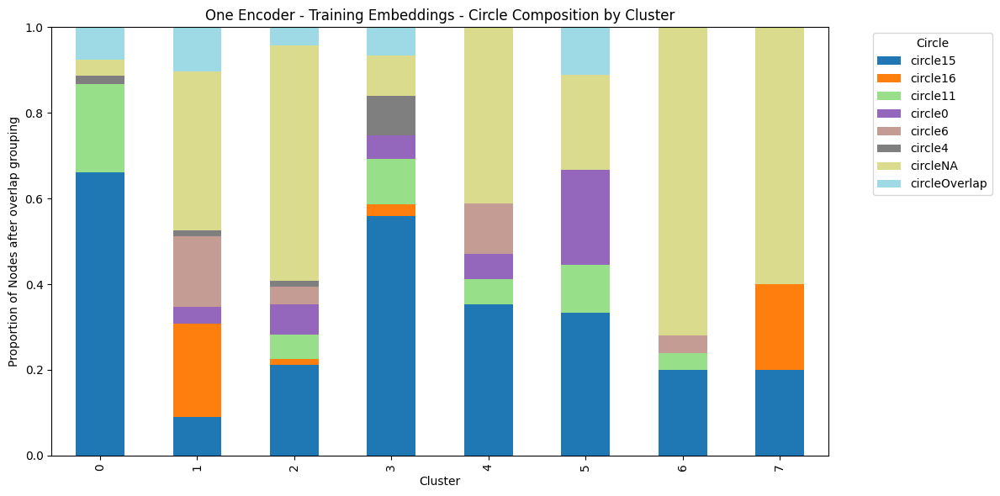

In [37]:
# ============================================================
# TRAINING-TIME MODEL 2A - One Encoder with all features
# ============================================================

diagnostics_method2_training_all, result_method2_training_all = (
    run_final_dataset_analysis(
        dataset_name="method2_shared_sequential_TRAINING_MEAN_all_features",
        n_clusters=K_ALL_FEATURES,
        final_method=final_method,
        random_state=random_state
    )
)


Dataset loaded: method2_shared_sequential_TRAINING_MEAN_circles_only
Embeddings shape: (333, 64)
Features shape: (333, 7)
Membership shape: (333, 8)

Running diagnostics for: method2_shared_sequential_TRAINING_MEAN_circles_only

=== method2_shared_sequential_TRAINING_MEAN_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.613825         671.531606        0.550451                 2   
3     0.439511         586.687100        0.869950                 3   
6     0.447968         654.527394        0.789375                 4   
9     0.417200         614.686615        0.796014                 5   
12    0.438787         631.962656        0.817290                 6   
15    0.444878         609.921236        0.840849                 7   
18    0.401578         588.192921        0.936295                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3               

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


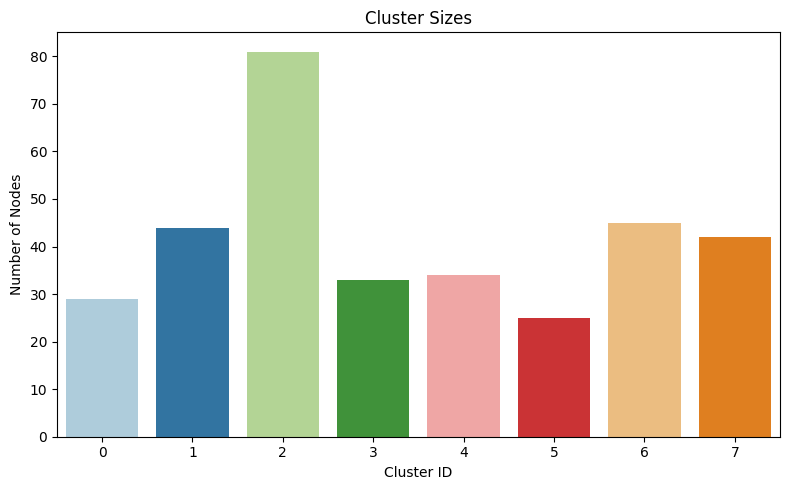


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.204769         0.168753         0.039976         0.345996   
1               0.000176         0.213918         1.598943         0.603503   
2               0.008503         0.125683         0.164516         0.507999   
3               0.109114         0.022333         0.044412         0.297534   
4               0.001464         0.208122         1.007947         0.567112   
5               0.029855         0.235208         0.300722         0.130881   
6               0.005481         0.186893         0.504318         0.613462   
7               0.017534         0.108947         0.127429         0.343742   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.717038 

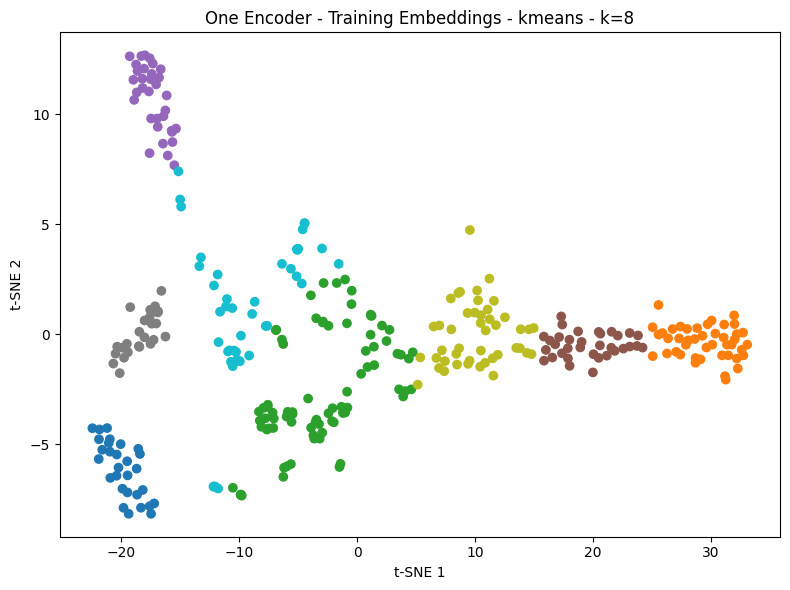

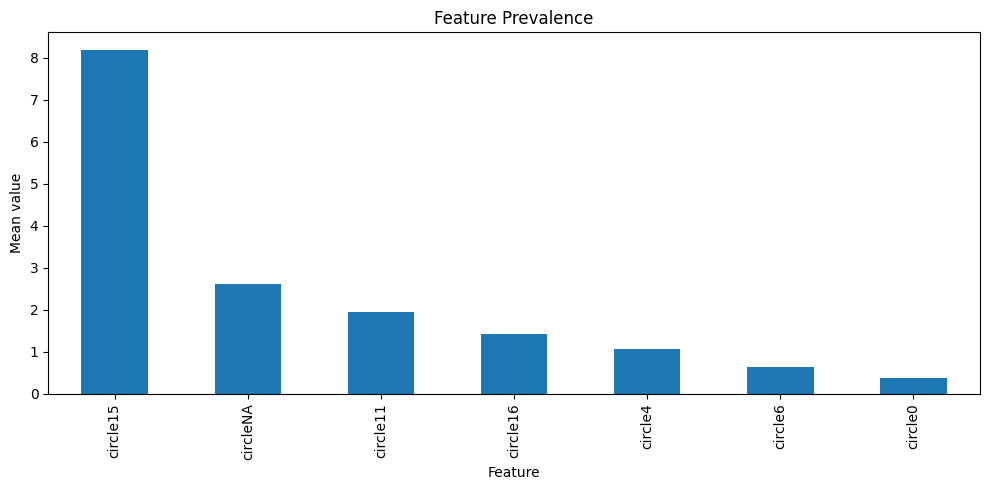


=== Cluster feature profiles ===
          circle15  circle16  circle11   circle0   circle6   circle4  circleNA
cluster                                                                       
0         0.137931  0.000000  0.206897  0.000000  6.827586  0.000000  5.206897
1        32.090909  1.454545  9.227273  1.113636  0.000000  5.000000  2.954545
2         1.876543  0.086420  0.209877  0.148148  0.061728  0.111111  0.617284
3         4.818182  9.757576  0.212121  0.121212  0.000000  0.090909  4.606061
4        15.382353  0.676471  3.588235  0.470588  0.000000  2.352941  1.470588
5         0.880000  0.040000  0.360000  0.080000  0.120000  0.040000  7.560000
6         8.888889  0.711111  1.622222  0.266667  0.000000  0.866667  0.888889
7         1.333333  0.595238  0.166667  0.714286  0.238095  0.071429  2.523810


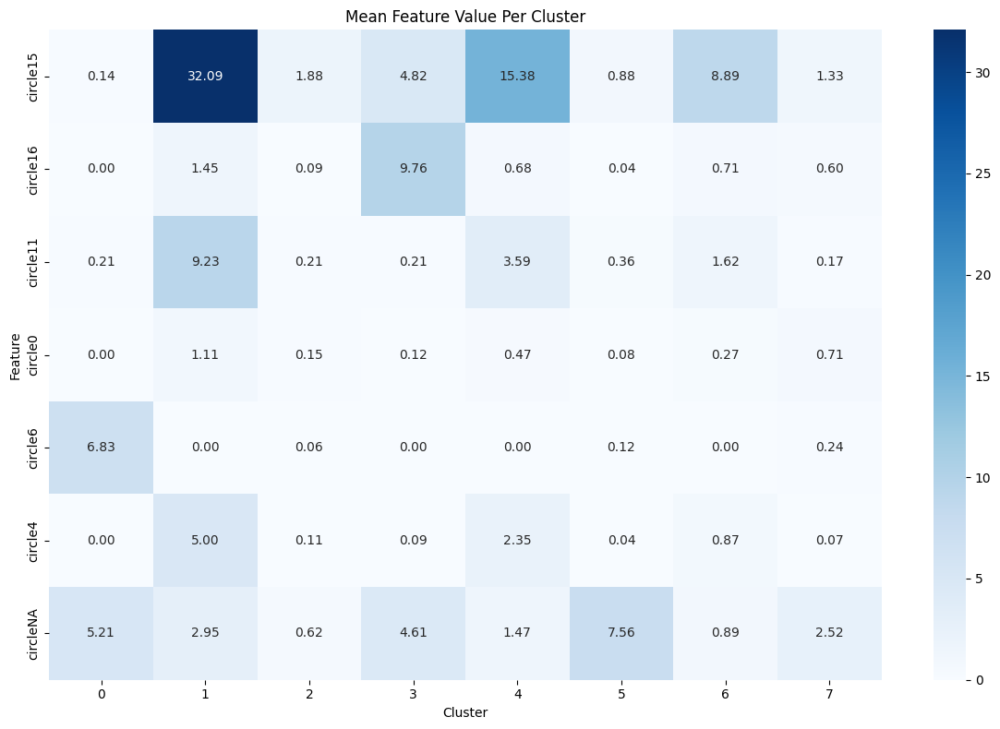

Features with > 30% prevalence/value in at least one cluster:
          circle15  circle16  circle11   circle0   circle6   circle4  circleNA
cluster                                                                       
0         0.137931  0.000000  0.206897  0.000000  6.827586  0.000000  5.206897
1        32.090909  1.454545  9.227273  1.113636  0.000000  5.000000  2.954545
2         1.876543  0.086420  0.209877  0.148148  0.061728  0.111111  0.617284
3         4.818182  9.757576  0.212121  0.121212  0.000000  0.090909  4.606061
4        15.382353  0.676471  3.588235  0.470588  0.000000  2.352941  1.470588
5         0.880000  0.040000  0.360000  0.080000  0.120000  0.040000  7.560000
6         8.888889  0.711111  1.622222  0.266667  0.000000  0.866667  0.888889
7         1.333333  0.595238  0.166667  0.714286  0.238095  0.071429  2.523810

=== Top mutual information features ===
circle15    0.961126
circle11    0.568473
circleNA    0.567317
circle4     0.527804
circle16    0.472585
ci

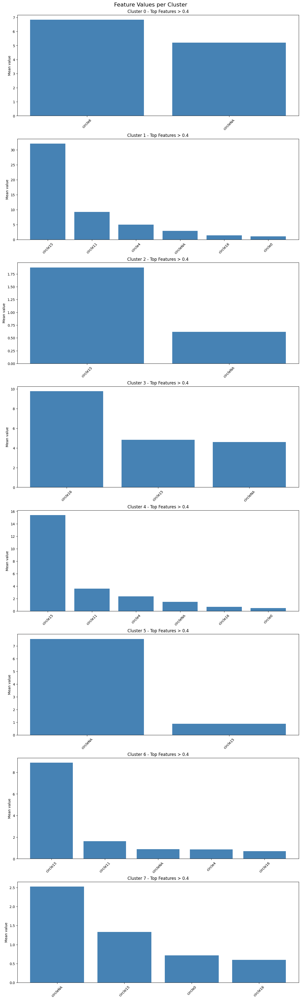


=== CLAMP prototypes ===
    cluster   feature  cluster_prevalence  global_prevalence  prevalence_diff  \
0         0  circle15            0.137931           8.192192        -8.054261   
1         0   circle6            6.827586           0.648649         6.178938   
2         0  circleNA            5.206897           2.606607         2.600290   
3         0  circle11            0.206897           1.942943        -1.736046   
4         0  circle16            0.000000           1.423423        -1.423423   
5         0   circle4            0.000000           1.066066        -1.066066   
6         0   circle0            0.000000           0.375375        -0.375375   
7         1  circle15           32.090909           8.192192        23.898717   
8         1  circle11            9.227273           1.942943         7.284330   
9         1   circle4            5.000000           1.066066         3.933934   
10        1   circle0            1.113636           0.375375         0.738261   
11

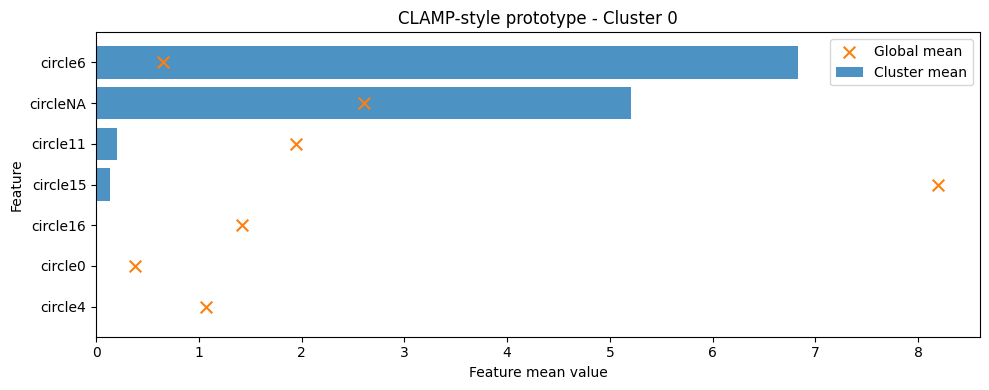

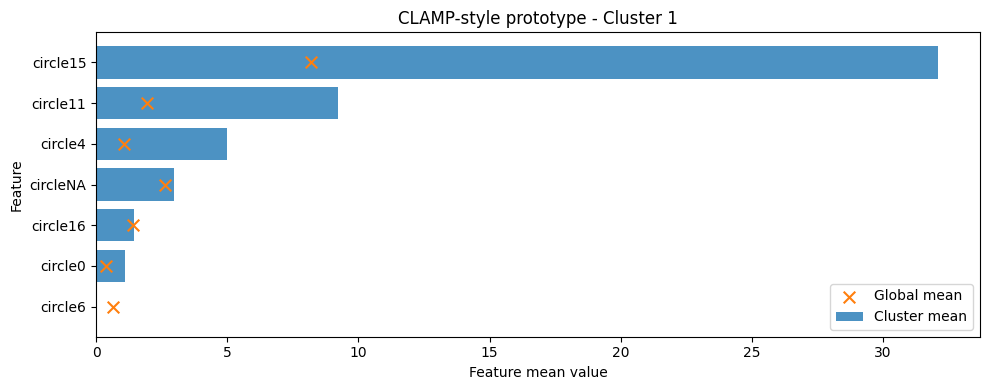

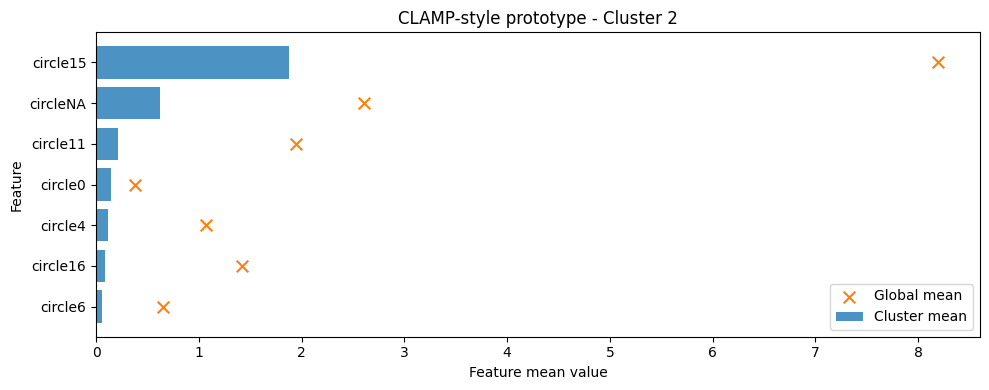

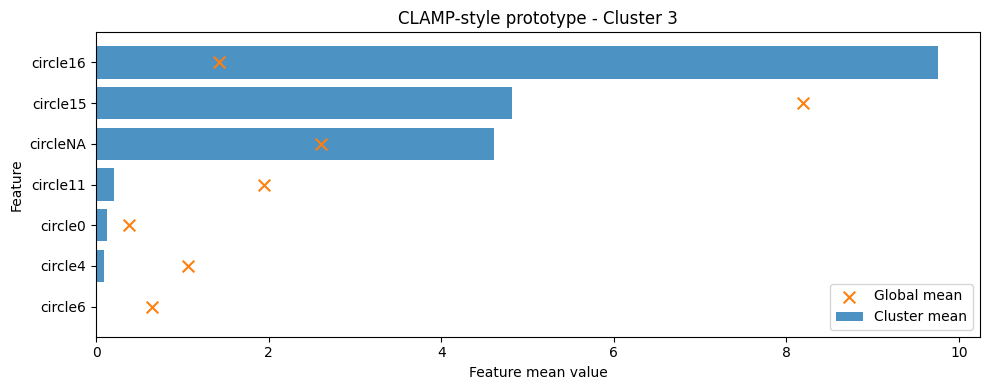

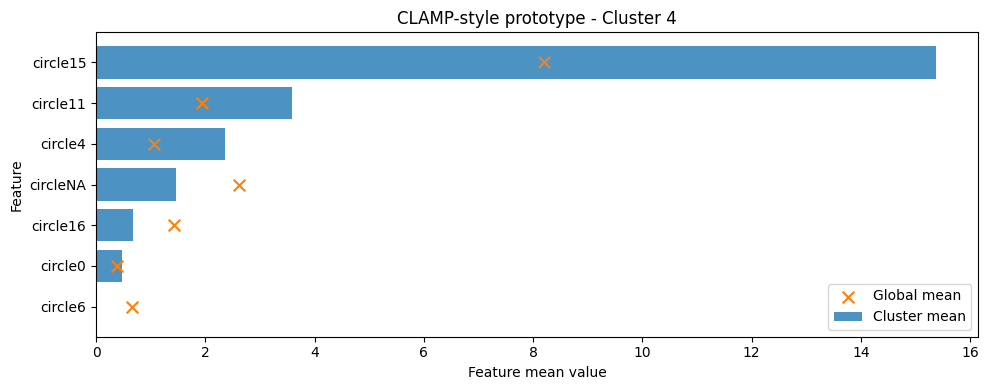

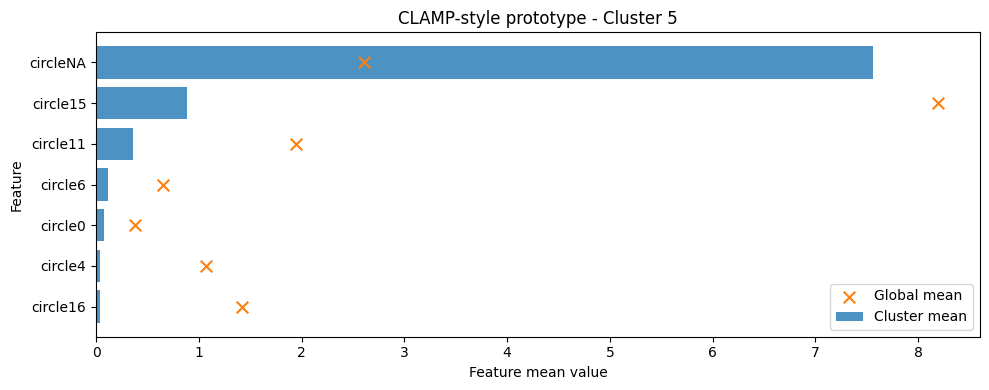

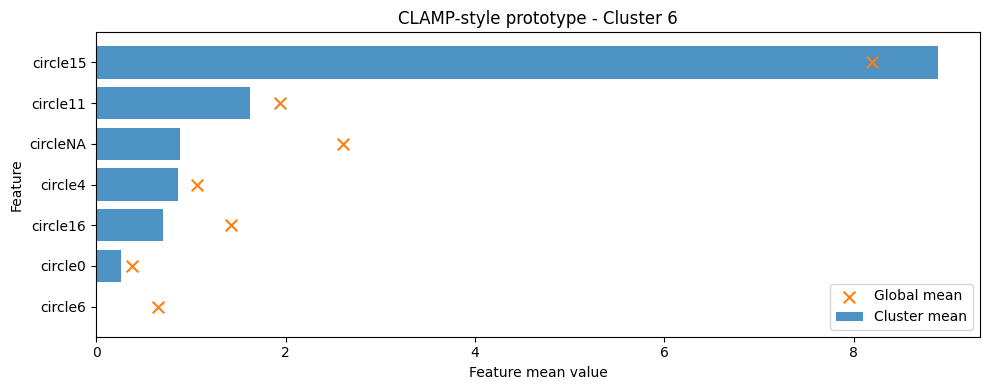

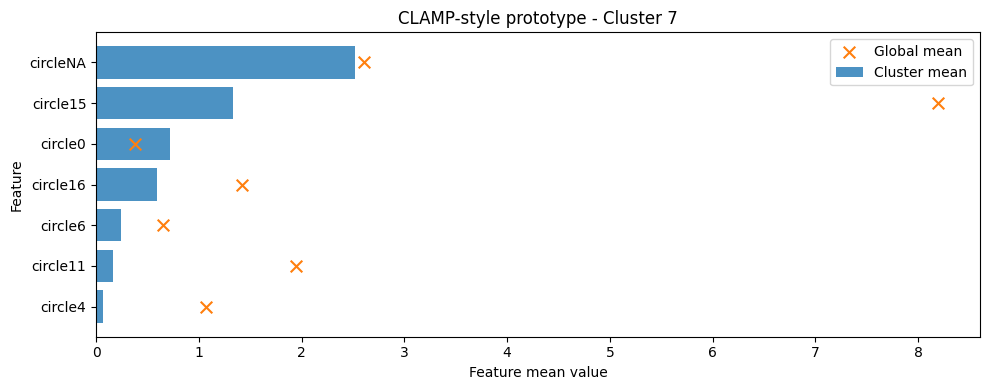

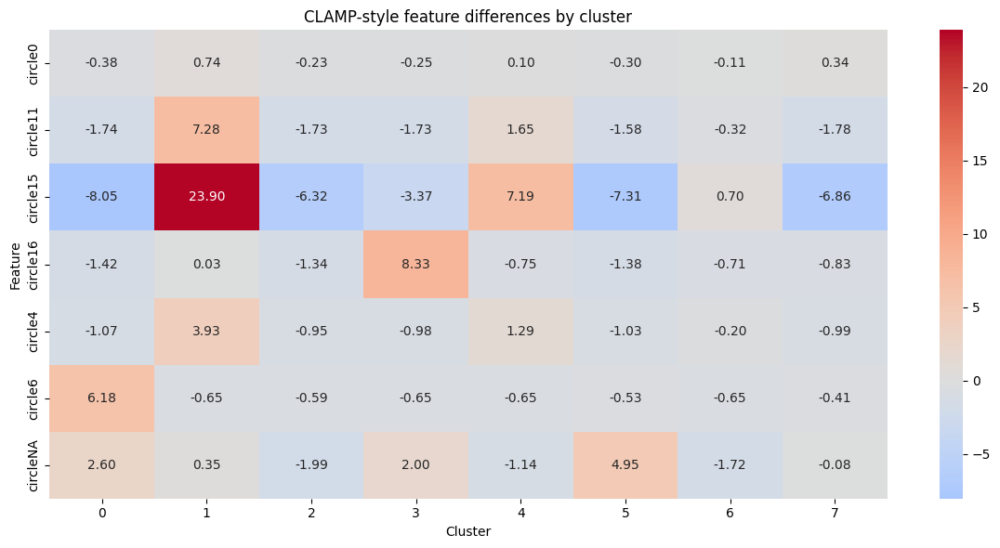


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.684685                          0.69622          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         8           4  

=== Decision tree rules ===
|--- circle6 <= 2.50
|   |--- circle16 <= 4.50
|   |   |--- circle15 <= 6.50
|   |   |   |--- circleNA <= 4.50
|   |   |   |   |--- class: 2
|   |   |   |--- circleNA >  4.50
|   |   |   |   |--- class: 5
|   |   |--- circle15 >  6.50
|   |   |   |--- circle15 <= 23.50
|   |   |   |   |--- class: 4
|   |   |   |--- circle15 >  23.50
|   |   |   |   |--- class: 1
|   |--- circle16 >  4.50
|   |   |--- circle15 <= 8.00
|   |   |   |--- class: 3
|   |   |--- circle15 >  8.00
|   |   |   |--- class: 3
|--- circle6 >  2.50
|   |--- circle6 <= 5.50
|   |   |--- class: 0
|   |--- circle6 >  5.50
|   |   |--- class: 0



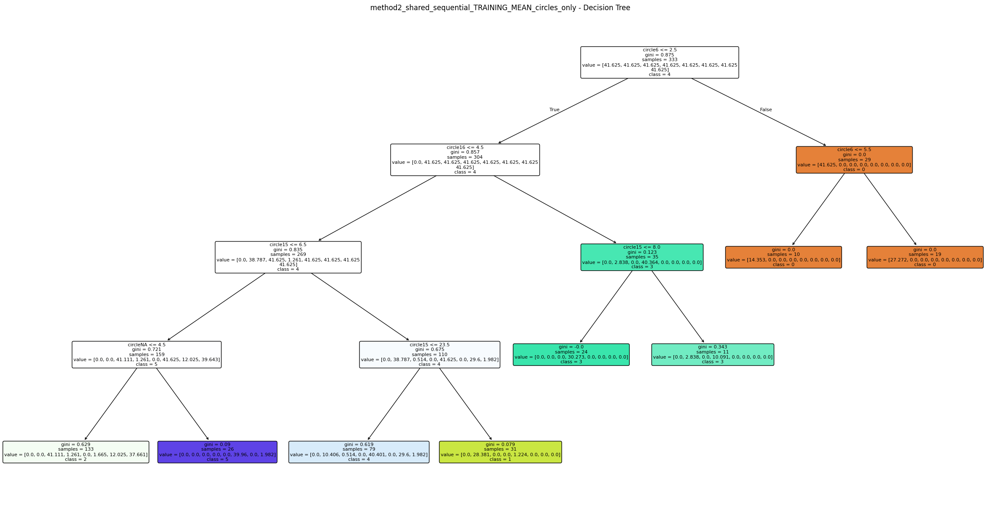


=== Decision tree feature importance ===
circle15    0.332188
circle6     0.244044
circle16    0.218392
circleNA    0.205377
dtype: float64


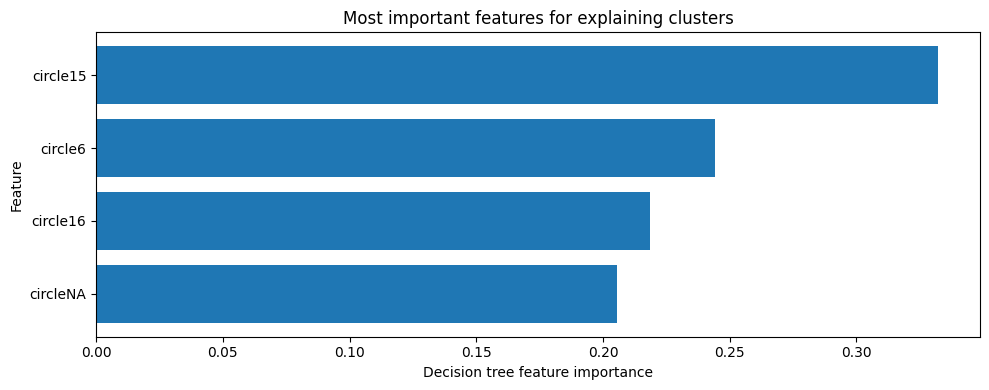


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.000000  0.000000  0.034483  0.000000  0.482759  0.000000  0.482759   
1        0.636364  0.000000  0.227273  0.000000  0.000000  0.022727  0.022727   
2        0.358025  0.024691  0.049383  0.037037  0.024691  0.012346  0.469136   
3        0.090909  0.454545  0.000000  0.000000  0.000000  0.000000  0.212121   
4        0.558824  0.000000  0.205882  0.029412  0.000000  0.088235  0.058824   
5        0.080000  0.000000  0.040000  0.000000  0.000000  0.000000  0.880000   
6        0.577778  0.044444  0.066667  0.066667  0.000000  0.111111  0.066667   
7        0.166667  0.047619  0.000000  0.190476  0.071429  0.000000  0.476190   

         circleOverlap  
cluster                 
0             0.000000  
1             0.090909  
2             0.024691  
3             0.242424  


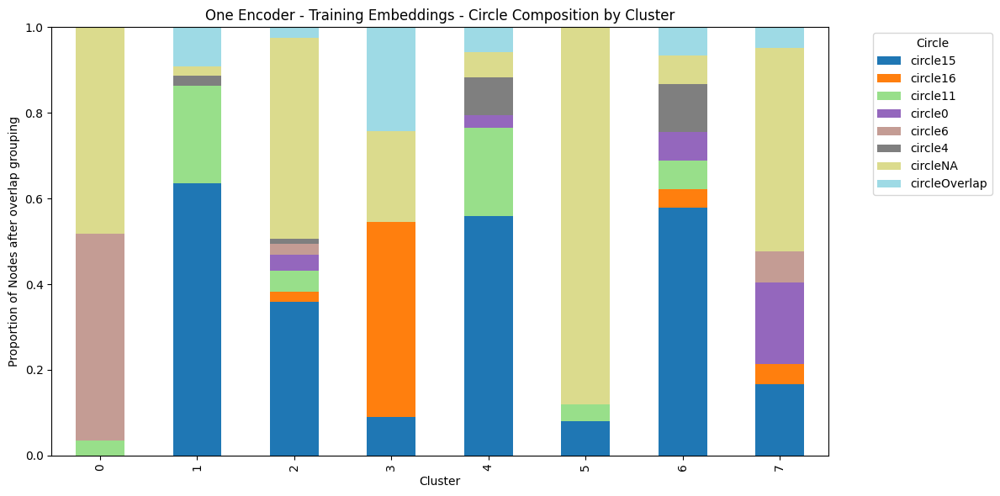

In [38]:
# ============================================================
# TRAINING-TIME MODEL 2B - One Encoder with circles-only ARD
# ============================================================

diagnostics_method2_training_circles, result_method2_training_circles = (
    run_final_dataset_analysis(
        dataset_name="method2_shared_sequential_TRAINING_MEAN_circles_only",
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)


Dataset loaded: method2_shared_sequential_TRAINING_MEAN_graph_structure_identity_only
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method2_shared_sequential_TRAINING_MEAN_graph_structure_identity_only

=== method2_shared_sequential_TRAINING_MEAN_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.166334          56.434803        2.058156                 2   
3     0.158428          45.249016        2.462053                 3   
6     0.152407          41.804012        2.260116                 4   
9     0.156232          34.645550        2.758786                 5   
12    0.160038          30.038177        2.853854                 6   
15    0.161440          26.579773        2.806613                 7   
18    0.079196          23.732792        2.442019                 8   

    valid_internal_metrics  method  k fit_status  \
0              

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


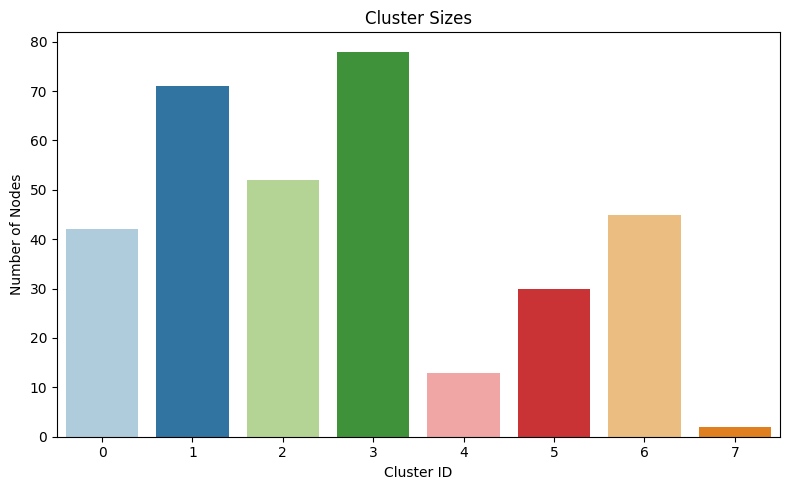


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.085377         0.066396         0.055310         0.103388   
1               0.044692         0.071478         0.060739         0.104853   
2               0.020824         0.065298         0.049424         0.070476   
3               0.106367         0.112278         0.055057         0.090464   
4               0.054090         0.087933         0.061362         0.044846   
5               0.194370         0.075639         0.006955         0.033242   
6               0.166815         0.113294         0.028542         0.059283   
7               0.127921         0.021773         0.081913         0.210162   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.045735 

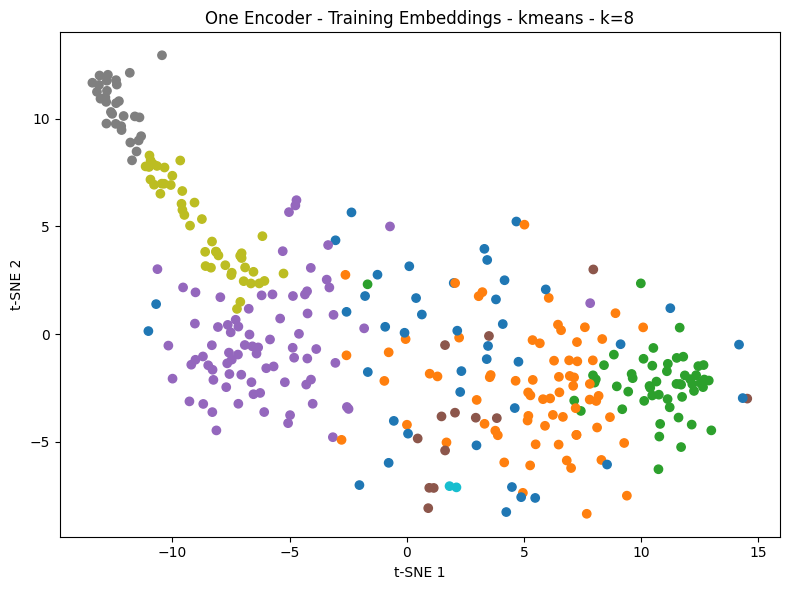

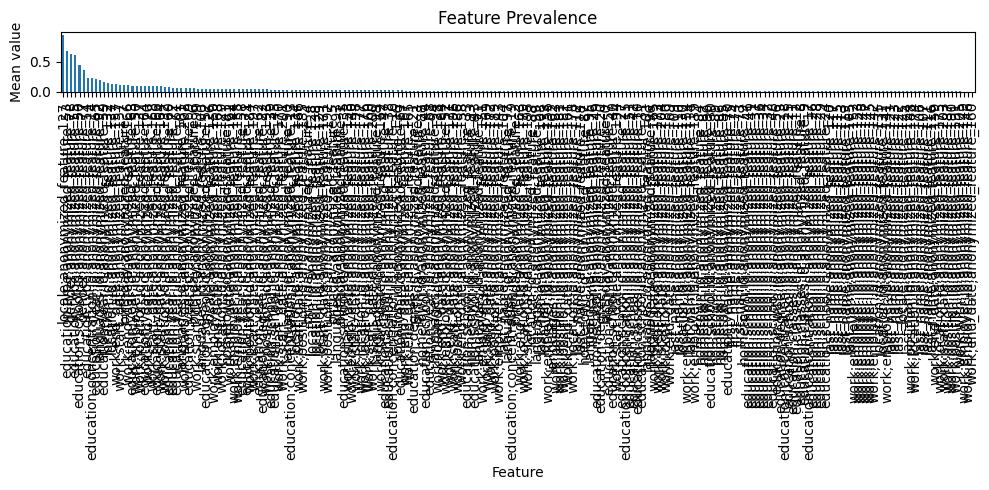


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.047619   
1                             0.056338                       0.028169   
2                             0.000000                       0.038462   
3                             0.000000                       0.012821   
4                             0.000000                       0.076923   
5                             0.000000                       0.000000   
6                             0.000000                       0.000000   
7                             0.000000                       0.000000   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.023810                       0.023810   
1               

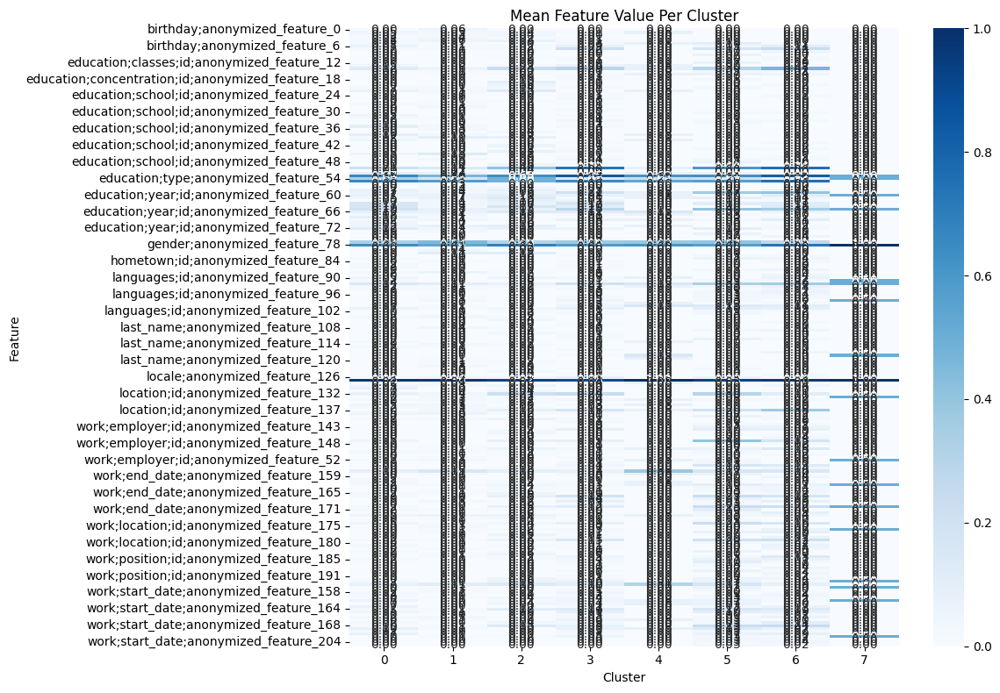

Features with > 30% prevalence/value in at least one cluster:
         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.119048   
1                                                0.056338   
2                                                0.230769   
3                                                0.294872   
4                                                0.076923   
5                                                0.300000   
6                                                0.466667   
7                                                0.000000   

         education;school;id;anonymized_feature_50  \
cluster                                              
0                                         0.214286   
1                                         0.140845   
2                                         0.403846   
3                                         0.730769   
4  

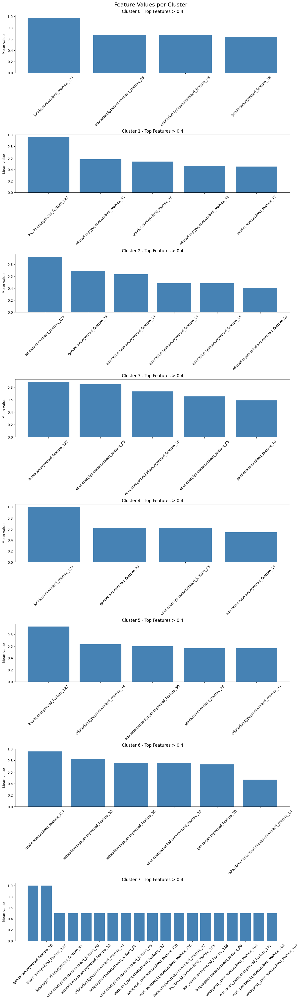


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0         education;school;id;anonymized_feature_50   
1         0                location;id;anonymized_feature_137   
2         0  education;concentration;id;anonymized_feature_14   
3         0              education;type;anonymized_feature_54   
4         0            work;start_date;anonymized_feature_168   
5         0           education;year;id;anonymized_feature_59   
6         0                     birthday;anonymized_feature_7   
7         0              work;end_date;anonymized_feature_166   
8         0                location;id;anonymized_feature_132   
9         0           education;year;id;anonymized_feature_68   
10        0           work;location;id;anonymized_feature_137   
11        0         education;school;id;anonymized_feature_38   
12        0              work;end_date;anonymized_feature_170   
13        0         education;school;id;anonymized_feature_35   

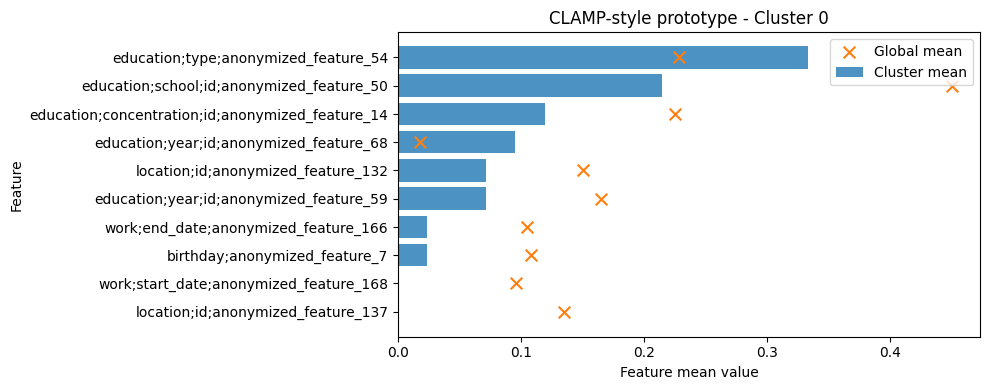

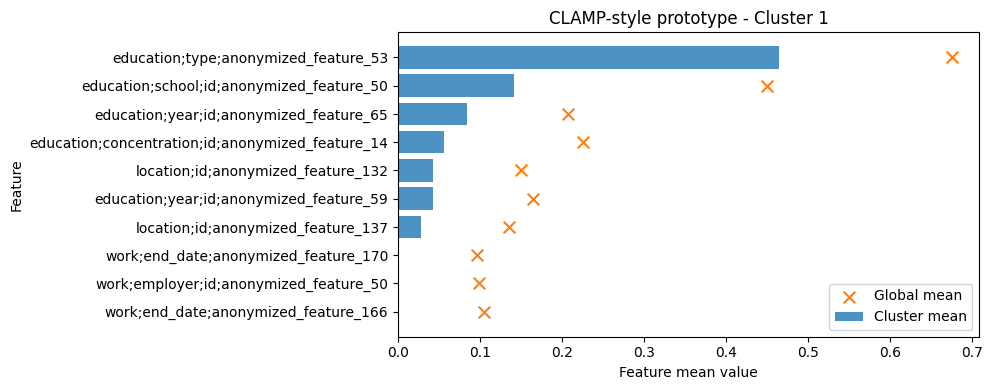

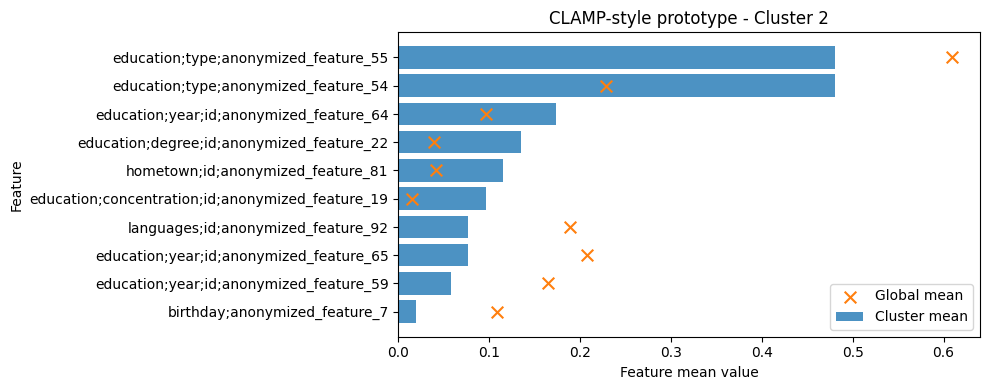

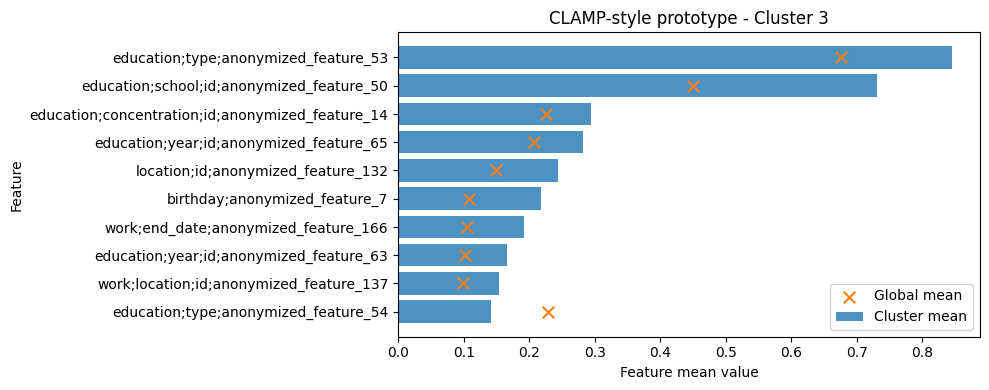

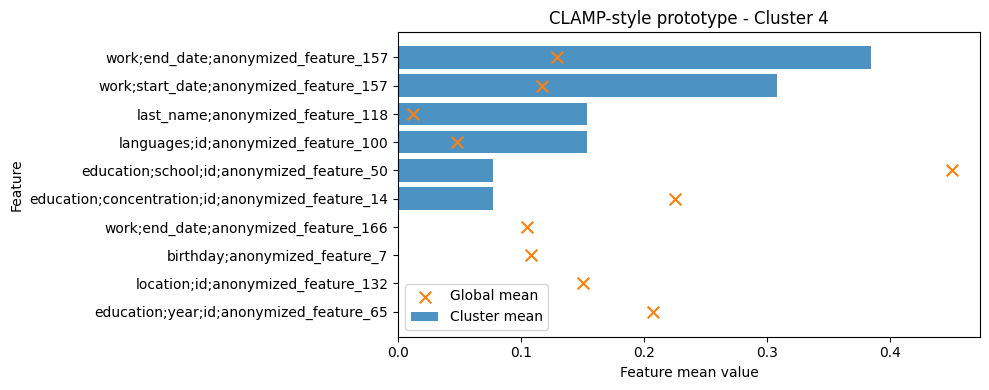

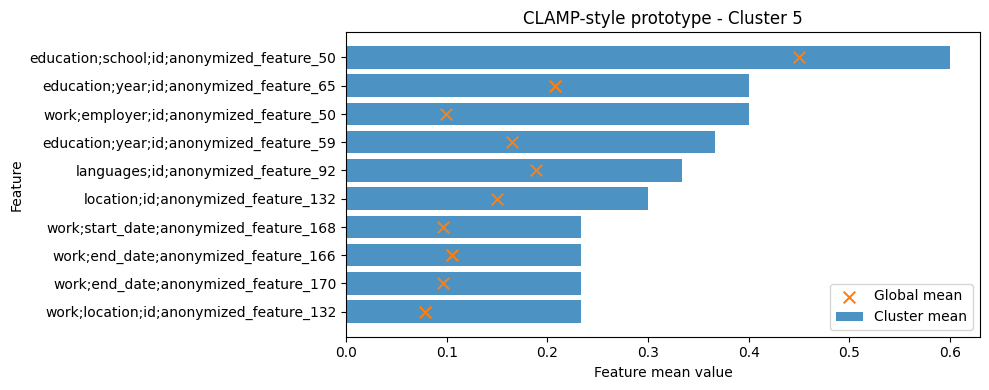

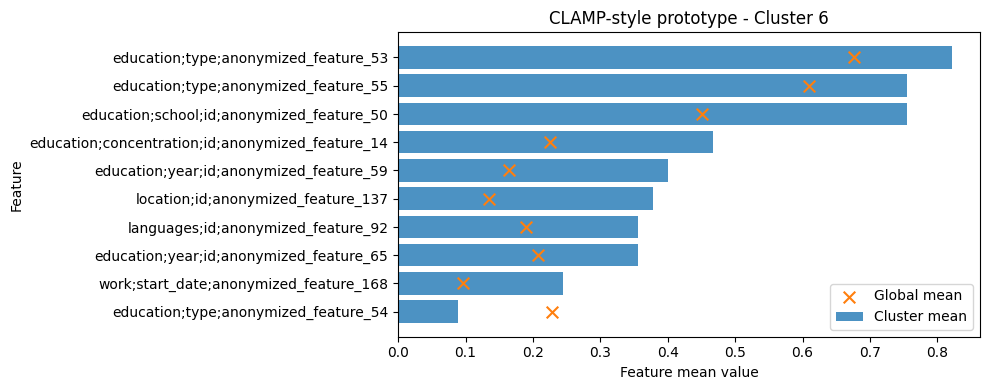

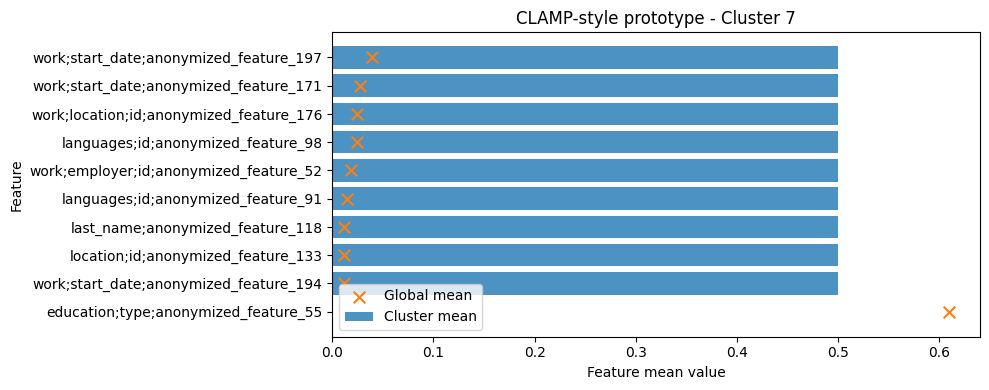

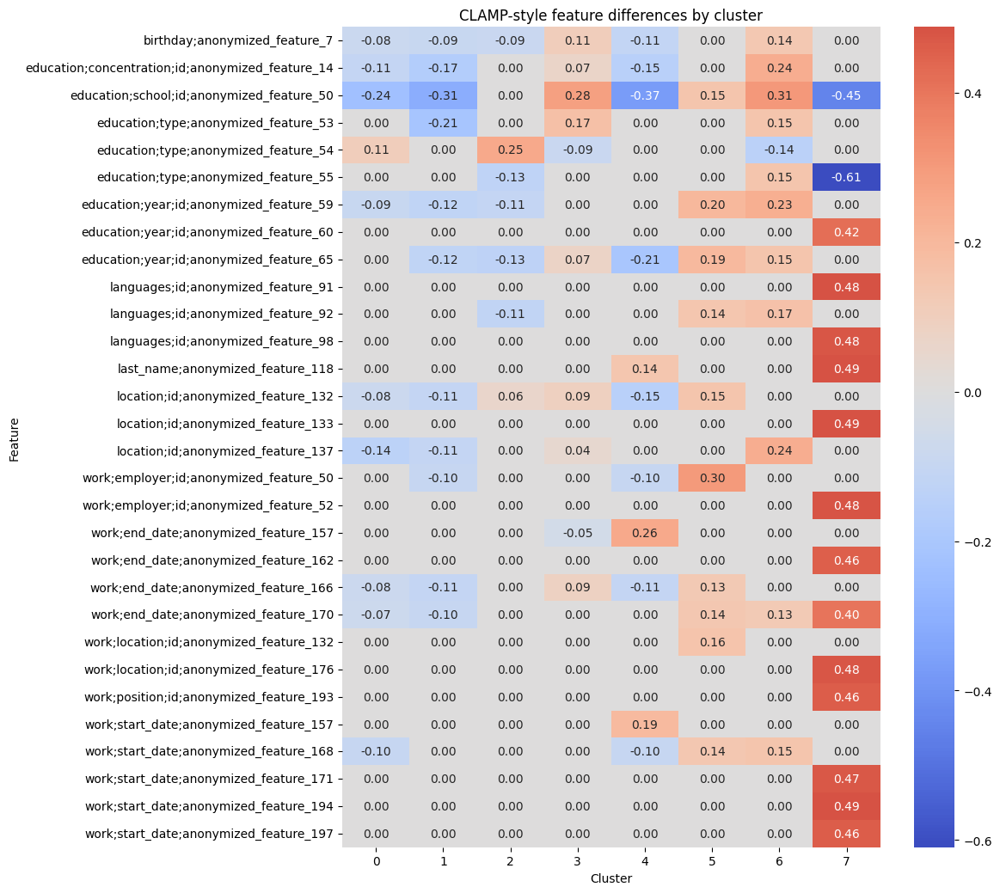


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.303303                         0.417799          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        11           4  

=== Decision tree rules ===
|--- education;school;id;anonymized_feature_50 <= 0.50
|   |--- education;year;id;anonymized_feature_65 <= 0.50
|   |   |--- education;type;anonymized_feature_53 <= 0.50
|   |   |   |--- gender;anonymized_feature_78 <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- gender;anonymized_feature_78 >  0.50
|   |   |   |   |--- class: 7
|   |   |--- education;type;anonymized_feature_53 >  0.50
|   |   |   |--- hometown;id;anonymized_feature_81 <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- hometown;id;anonymized_feature_81 >  0.50
|   |   |   |   |--- class: 2
|   |--- education;year;id;anonymized_feature_65 >  0.50
|   |   |--- class: 7
|--- education;school;id;anonymized_feature

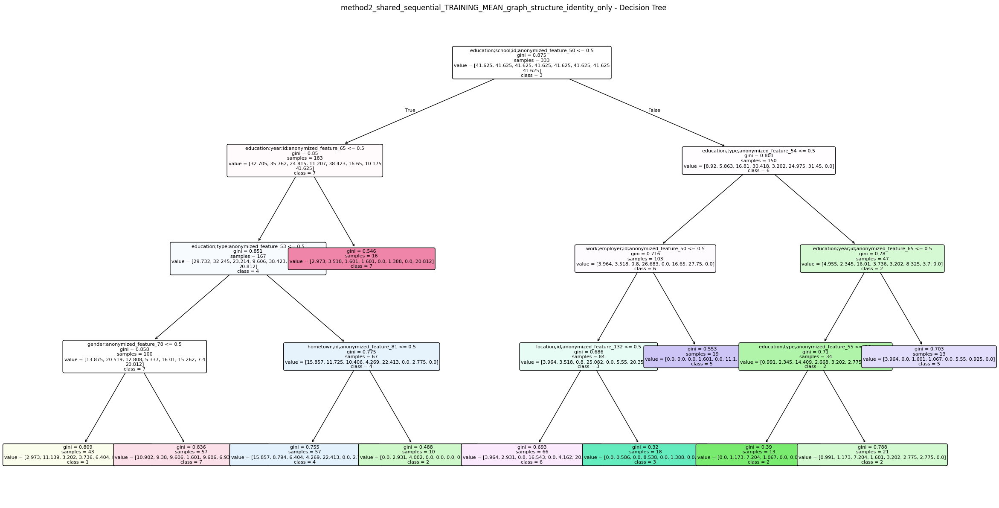


=== Decision tree feature importance ===
education;school;id;anonymized_feature_50    0.255371
education;year;id;anonymized_feature_65      0.227974
education;type;anonymized_feature_54         0.137302
work;employer;id;anonymized_feature_50       0.091075
education;type;anonymized_feature_53         0.078712
location;id;anonymized_feature_132           0.063340
gender;anonymized_feature_78                 0.062250
hometown;id;anonymized_feature_81            0.057344
education;type;anonymized_feature_55         0.026632
dtype: float64


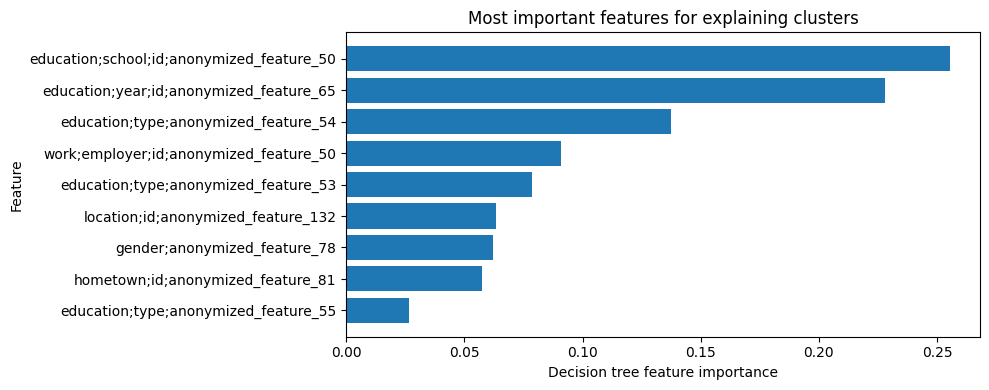


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.261905  0.071429  0.000000  0.047619  0.071429  0.000000  0.500000   
1        0.126761  0.000000  0.042254  0.070423  0.126761  0.000000  0.619718   
2        0.076923  0.307692  0.000000  0.000000  0.115385  0.019231  0.326923   
3        0.525641  0.025641  0.076923  0.064103  0.000000  0.064103  0.179487   
4        0.153846  0.000000  0.153846  0.076923  0.076923  0.000000  0.538462   
5        0.733333  0.000000  0.100000  0.000000  0.000000  0.033333  0.066667   
6        0.533333  0.000000  0.266667  0.022222  0.000000  0.066667  0.044444   
7        0.500000  0.000000  0.000000  0.500000  0.000000  0.000000  0.000000   

         circleOverlap  
cluster                 
0             0.047619  
1             0.014085  
2             0.153846  
3             0.064103  


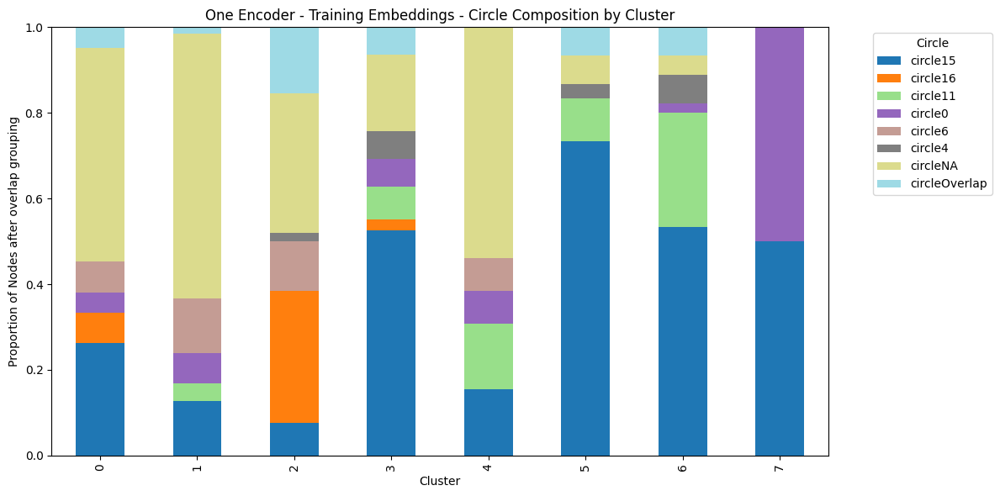

In [39]:
# ============================================================
# TRAINING-TIME MODEL 2C - One Encoder with structure only
# ============================================================

diagnostics_method2_training_structure, result_method2_training_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method2_shared_sequential_TRAINING_MEAN_"
            "graph_structure_identity_only"
        ),
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)


Dataset loaded: method3_batch_TRAINING_MEAN_all_features
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method3_batch_TRAINING_MEAN_all_features

=== method3_batch_TRAINING_MEAN_all_features | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.524718         329.793073        0.617027                 2   
3     0.328452         292.453426        1.074888                 3   
6     0.295441         229.704594        0.991880                 4   
9     0.241565         199.359614        1.311735                 5   
12    0.253308         184.805213        1.265641                 6   
15    0.252724         170.642745        1.281324                 7   
18    0.259010         158.135485        1.237886                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3         ok  

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


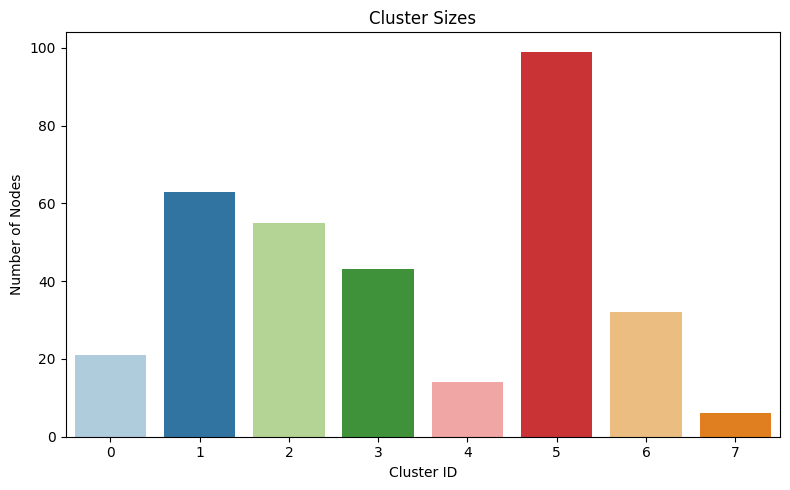


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.182461         0.119425         0.003759         0.153649   
1               0.024582         0.025121         0.068000         0.038393   
2               0.113403         0.073343         0.052821         0.097673   
3               0.026481         0.025165         0.062748         0.036187   
4               0.026786         0.027832         0.132295         0.017281   
5               0.038801         0.044049         0.069785         0.036256   
6               0.173201         0.120269         0.016506         0.151060   
7               0.071432         0.073386         0.195915         0.036476   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.023285 

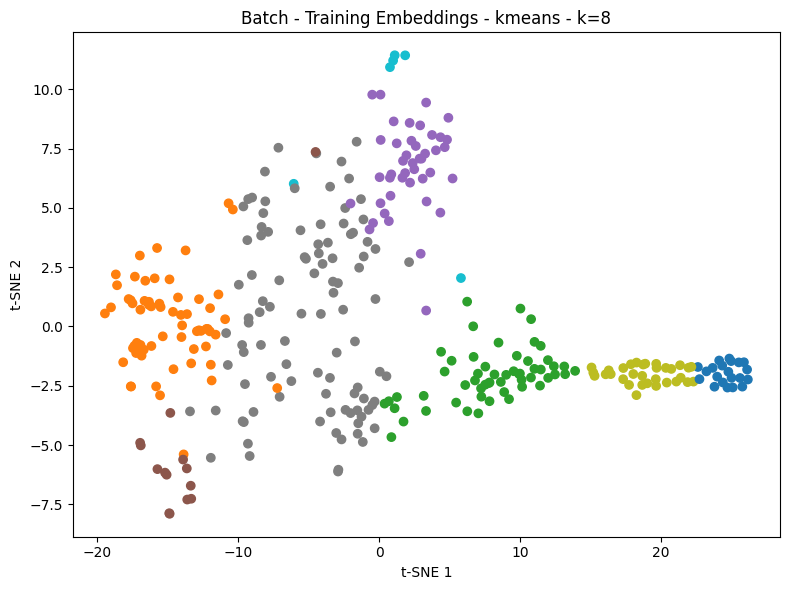

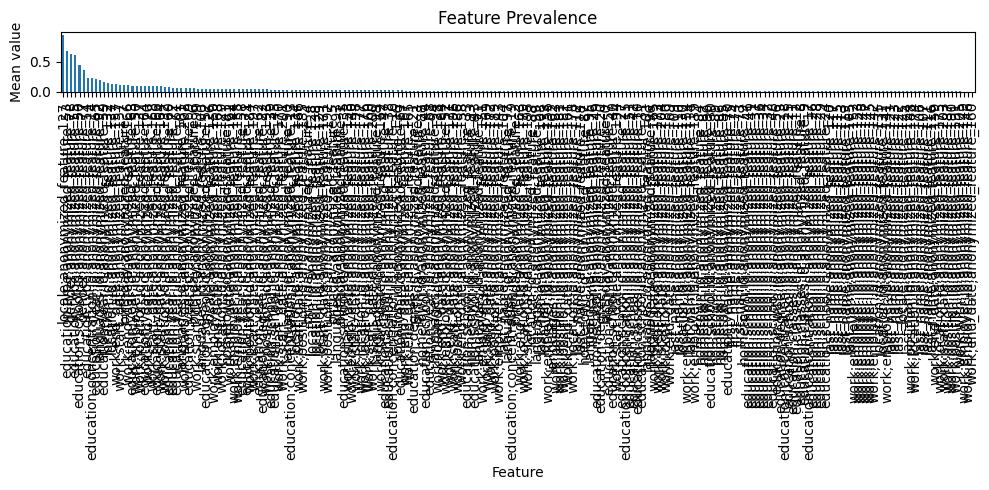


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.000000   
1                             0.000000                       0.000000   
2                             0.000000                       0.000000   
3                             0.023256                       0.046512   
4                             0.000000                       0.071429   
5                             0.030303                       0.050505   
6                             0.000000                       0.000000   
7                             0.000000                       0.000000   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.000000                       0.000000   
1               

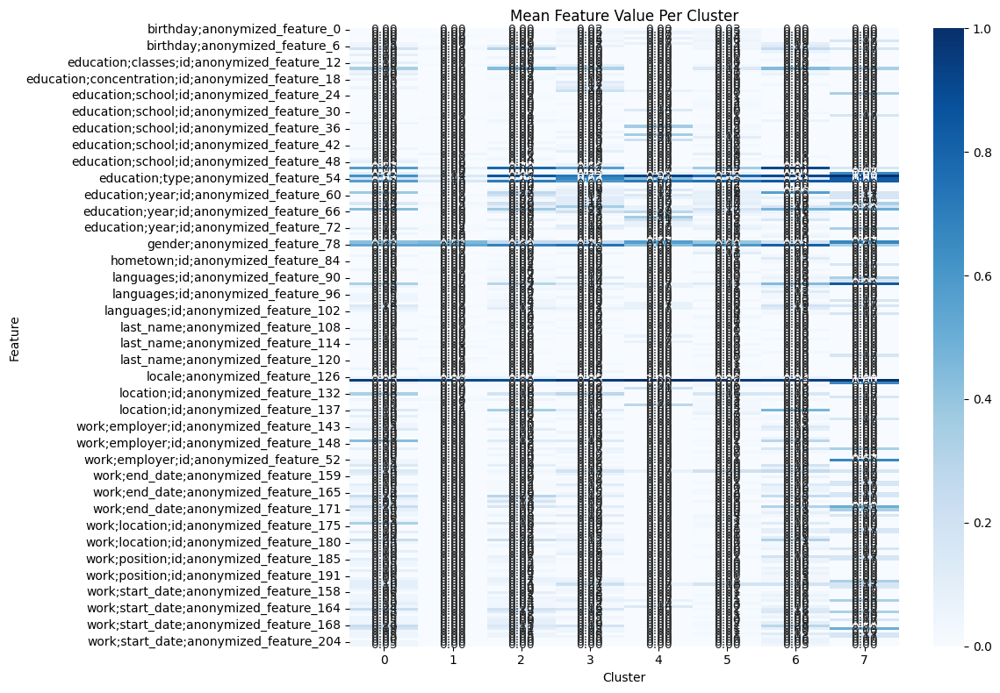

Features with > 30% prevalence/value in at least one cluster:
         birthday;anonymized_feature_7  \
cluster                                  
0                             0.190476   
1                             0.031746   
2                             0.309091   
3                             0.000000   
4                             0.000000   
5                             0.040404   
6                             0.250000   
7                             0.166667   

         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.333333   
1                                                0.000000   
2                                                0.436364   
3                                                0.325581   
4                                                0.000000   
5                                                0.141414   
6                            

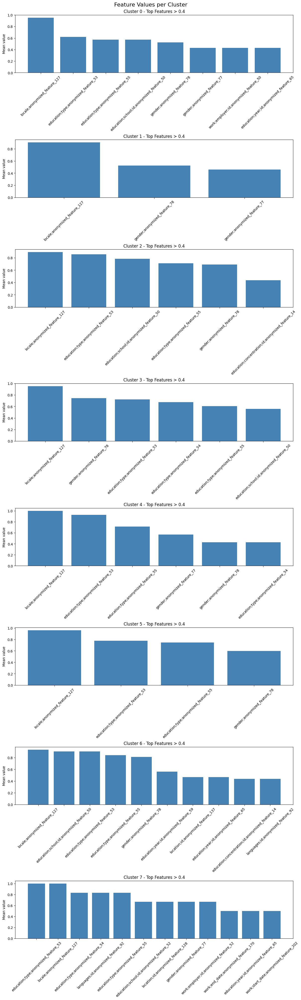


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0            work;employer;id;anonymized_feature_50   
1         0           work;location;id;anonymized_feature_132   
2         0           education;year;id;anonymized_feature_65   
3         0           education;year;id;anonymized_feature_59   
4         0                location;id;anonymized_feature_132   
5         0            work;start_date;anonymized_feature_164   
6         0                languages;id;anonymized_feature_92   
7         0              work;end_date;anonymized_feature_170   
8         0            work;start_date;anonymized_feature_168   
9         0           work;location;id;anonymized_feature_137   
10        0            work;start_date;anonymized_feature_202   
11        0              work;end_date;anonymized_feature_166   
12        0         education;school;id;anonymized_feature_50   
13        0  education;concentration;id;anonymized_feature_14   

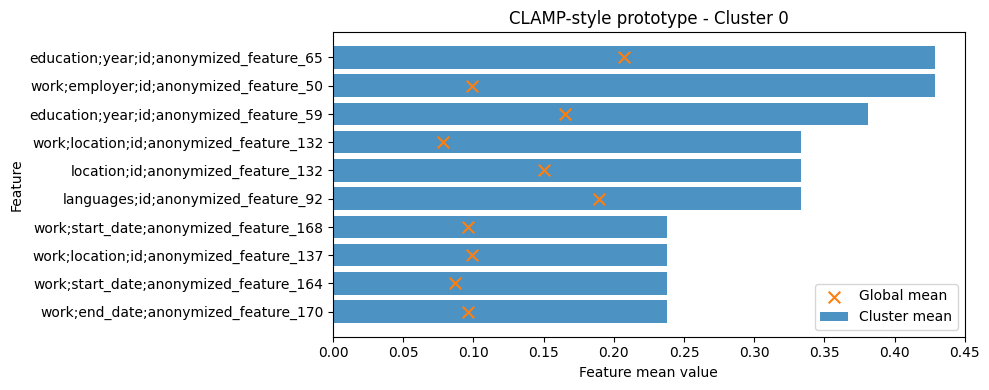

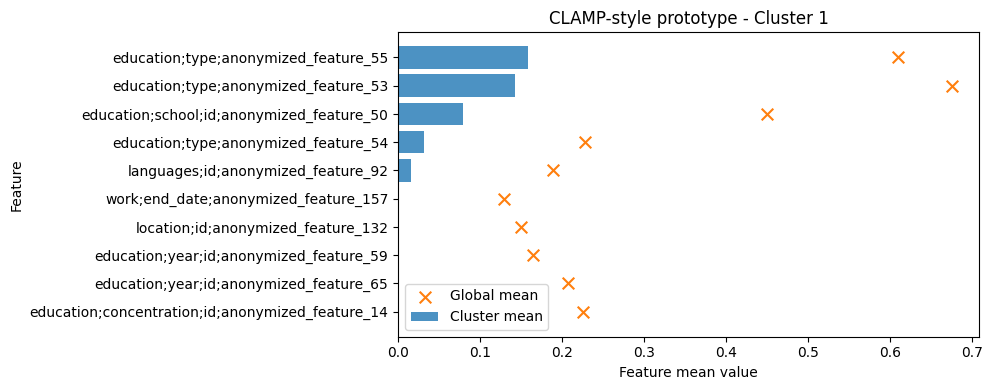

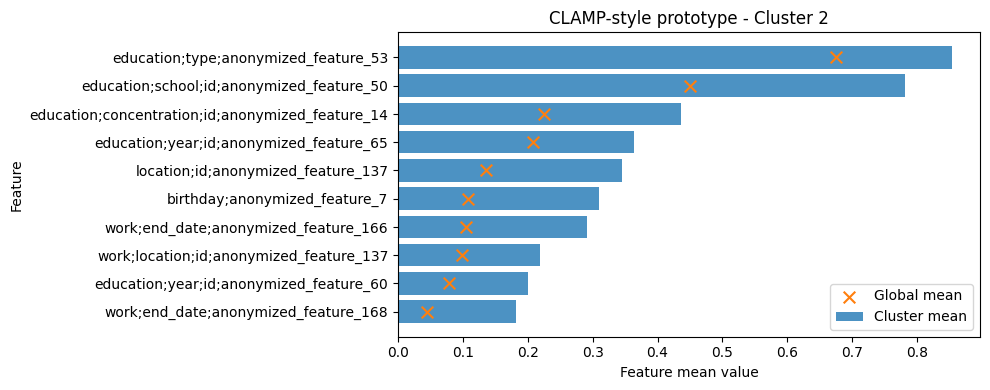

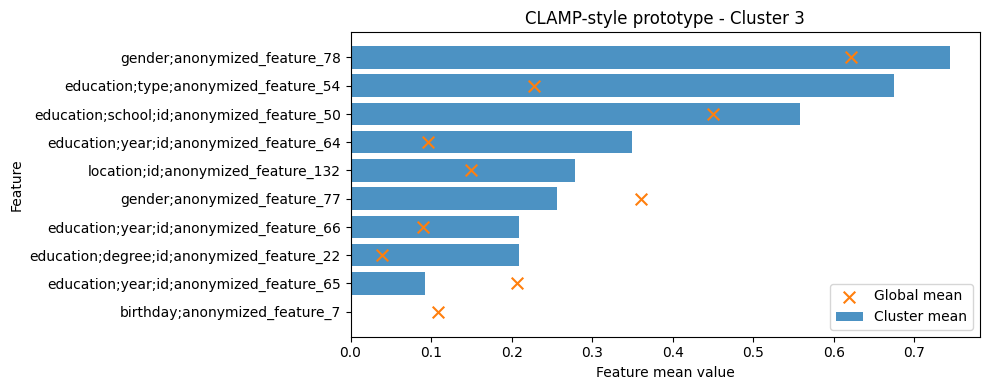

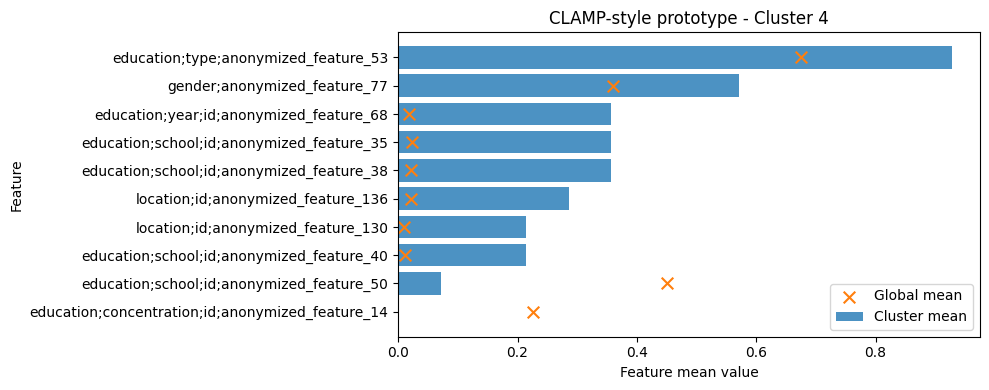

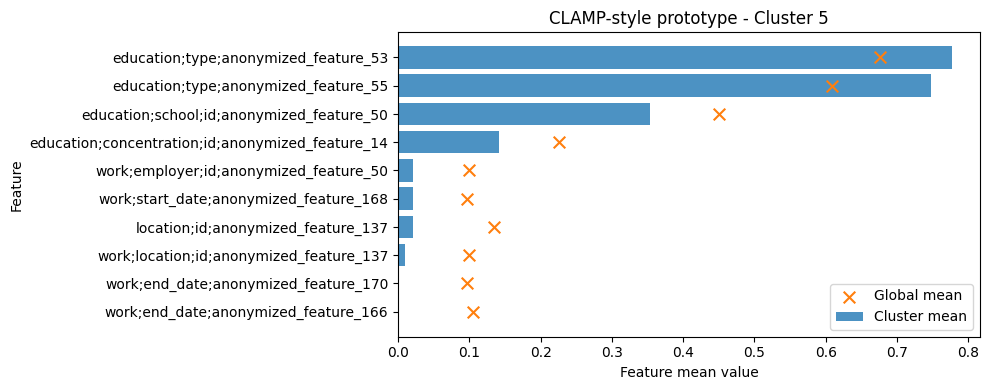

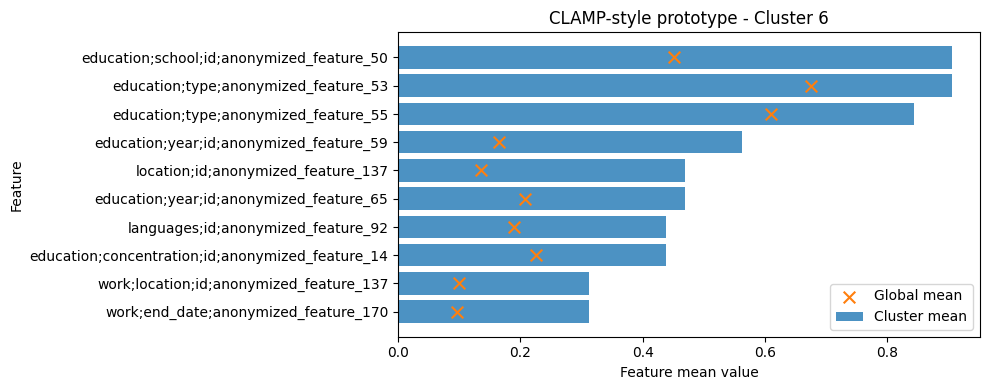

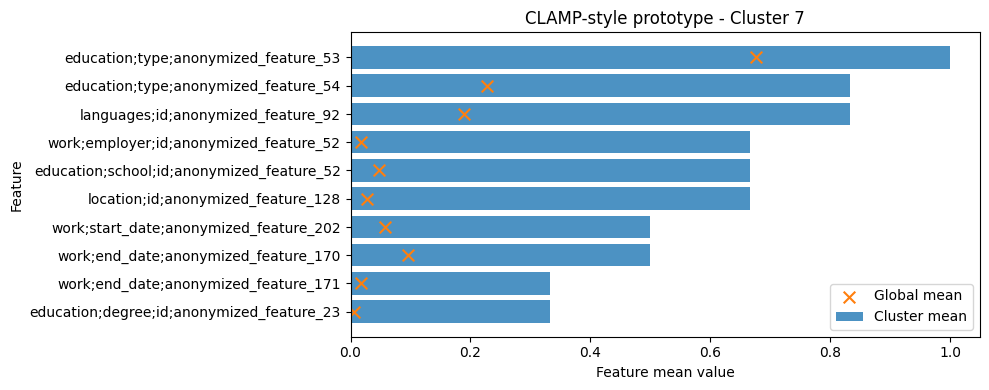

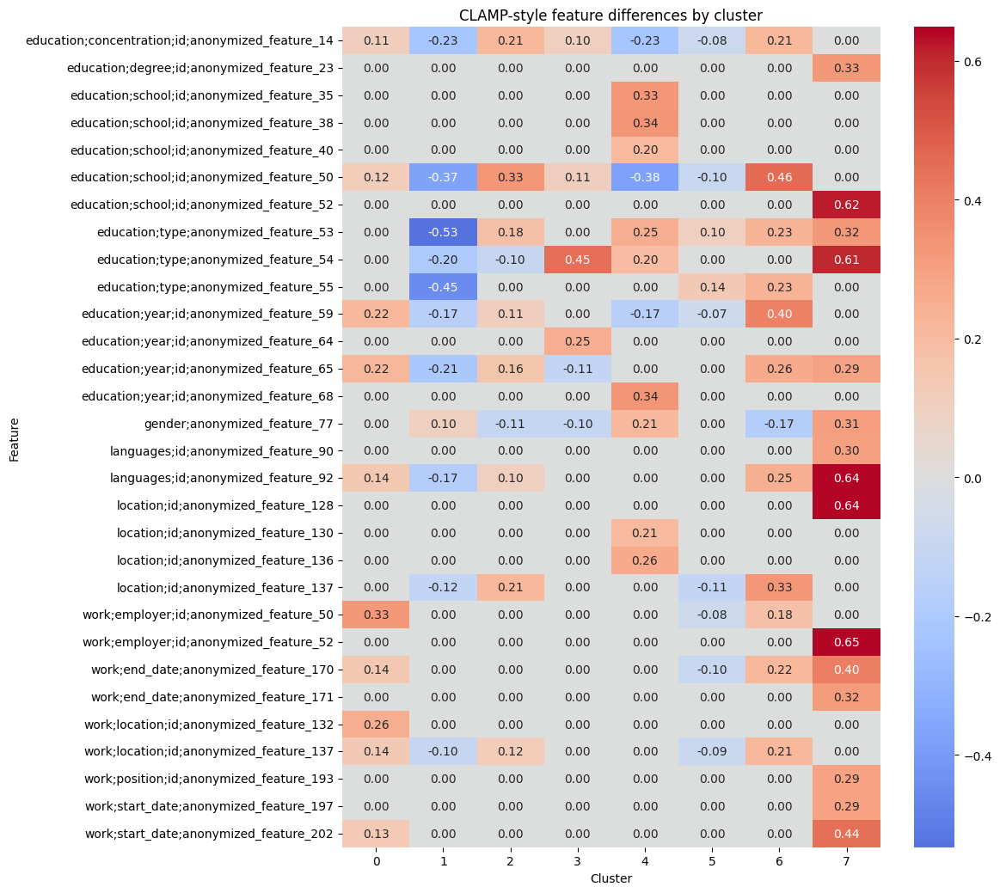


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.405405                         0.487972          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         9           4  

=== Decision tree rules ===
|--- education;school;id;anonymized_feature_52 <= 0.50
|   |--- education;school;id;anonymized_feature_50 <= 0.50
|   |   |--- education;type;anonymized_feature_53 <= 0.50
|   |   |   |--- education;type;anonymized_feature_55 <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- education;type;anonymized_feature_55 >  0.50
|   |   |   |   |--- class: 5
|   |   |--- education;type;anonymized_feature_53 >  0.50
|   |   |   |--- education;year;id;anonymized_feature_65 <= 0.50
|   |   |   |   |--- class: 4
|   |   |   |--- education;year;id;anonymized_feature_65 >  0.50
|   |   |   |   |--- class: 7
|   |--- education;school;id;anonymized_feature_50 >  0.50
|   |   |--- education;type;anony

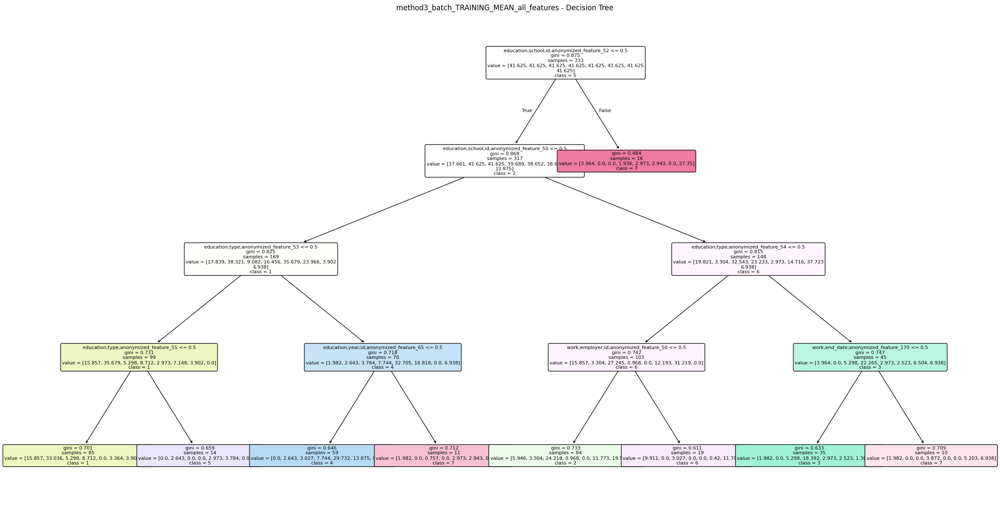


=== Decision tree feature importance ===
education;school;id;anonymized_feature_52    0.243039
education;type;anonymized_feature_53         0.211432
education;school;id;anonymized_feature_50    0.194656
education;type;anonymized_feature_54         0.139231
work;end_date;anonymized_feature_170         0.060587
education;year;id;anonymized_feature_65      0.058908
work;employer;id;anonymized_feature_50       0.053420
education;type;anonymized_feature_55         0.038727
dtype: float64


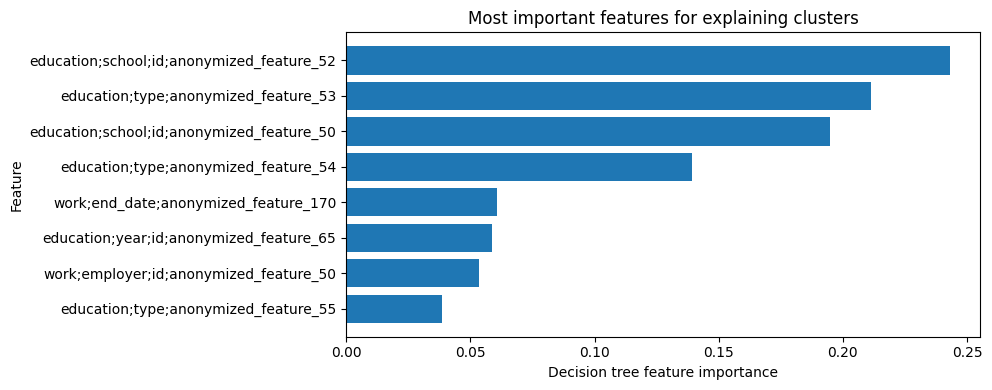


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.714286  0.000000  0.095238  0.000000  0.000000  0.047619  0.047619   
1        0.158730  0.000000  0.047619  0.079365  0.063492  0.000000  0.603175   
2        0.490909  0.036364  0.127273  0.090909  0.000000  0.109091  0.054545   
3        0.139535  0.302326  0.023256  0.000000  0.093023  0.000000  0.325581   
4        0.357143  0.000000  0.142857  0.071429  0.142857  0.000000  0.285714   
5        0.282828  0.060606  0.020202  0.020202  0.090909  0.030303  0.464646   
6        0.625000  0.000000  0.281250  0.000000  0.000000  0.000000  0.031250   
7        0.500000  0.000000  0.000000  0.333333  0.000000  0.000000  0.000000   

         circleOverlap  
cluster                 
0             0.095238  
1             0.047619  
2             0.090909  
3             0.116279  


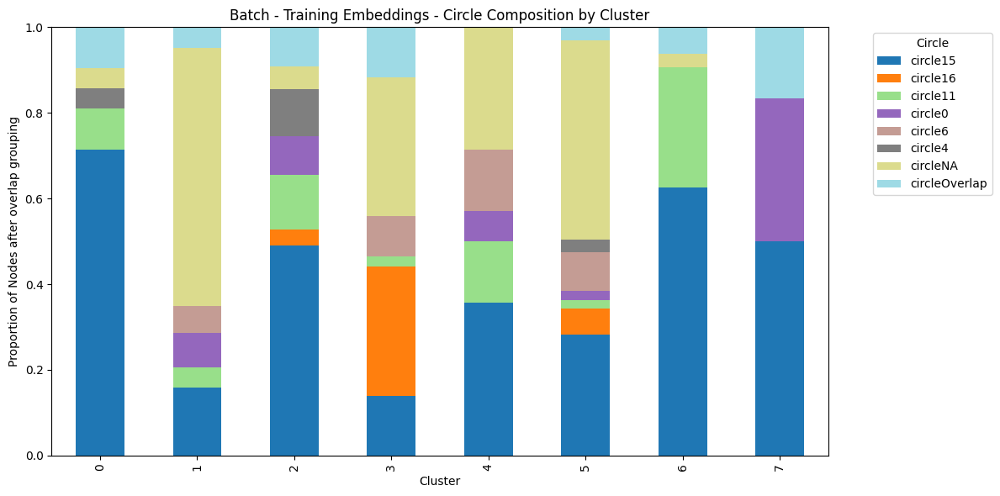

In [40]:
# ============================================================
# TRAINING-TIME MODEL 3A - Batch with all features
# ============================================================

diagnostics_method3_training_all, result_method3_training_all = (
    run_final_dataset_analysis(
        dataset_name="method3_batch_TRAINING_MEAN_all_features",
        n_clusters=K_ALL_FEATURES,
        final_method=final_method,
        random_state=random_state
    )
)


Dataset loaded: method3_batch_TRAINING_MEAN_circles_only
Embeddings shape: (333, 64)
Features shape: (333, 7)
Membership shape: (333, 8)

Running diagnostics for: method3_batch_TRAINING_MEAN_circles_only

=== method3_batch_TRAINING_MEAN_circles_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.683741        1034.979398        0.469583                 2   
3     0.556378        1045.738494        0.594205                 3   
6     0.445787        1011.127831        0.836428                 4   
9     0.480448        1086.666535        0.744680                 5   
12    0.468380        1077.320430        0.731161                 6   
15    0.425905        1128.298413        0.794689                 7   
18    0.454551        1192.264639        0.754388                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   
3                     True  kmeans  3         ok   


C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


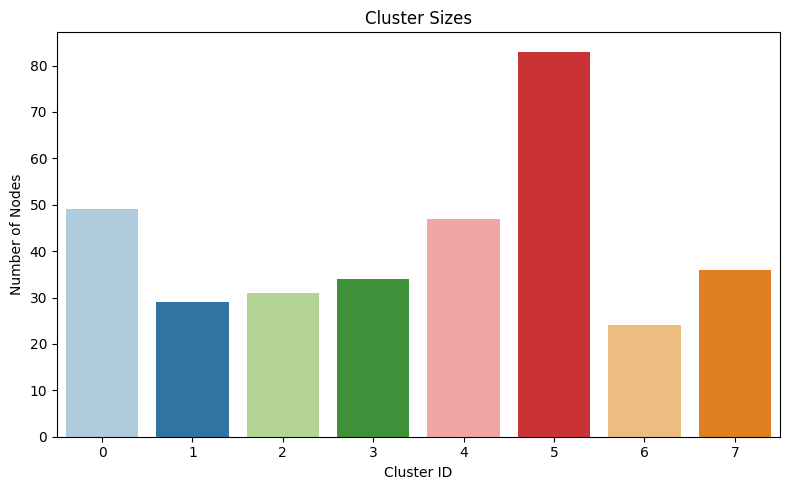


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0           8.153477e-02         0.261363         0.120714         0.310465   
1          -3.725290e-09         1.719533         1.892469         3.780009   
2           1.997501e-05         0.958691         1.038974         2.156029   
3           4.776906e-03         0.078302         0.046250         0.949939   
4           2.283618e-03         0.411542         0.350091         0.834716   
5           1.938323e-02         0.172826         0.121968         0.365263   
6          -1.862645e-09         1.379678         1.554924         3.054348   
7           7.922910e-04         0.615786         0.626562         1.497738   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               1.800602 

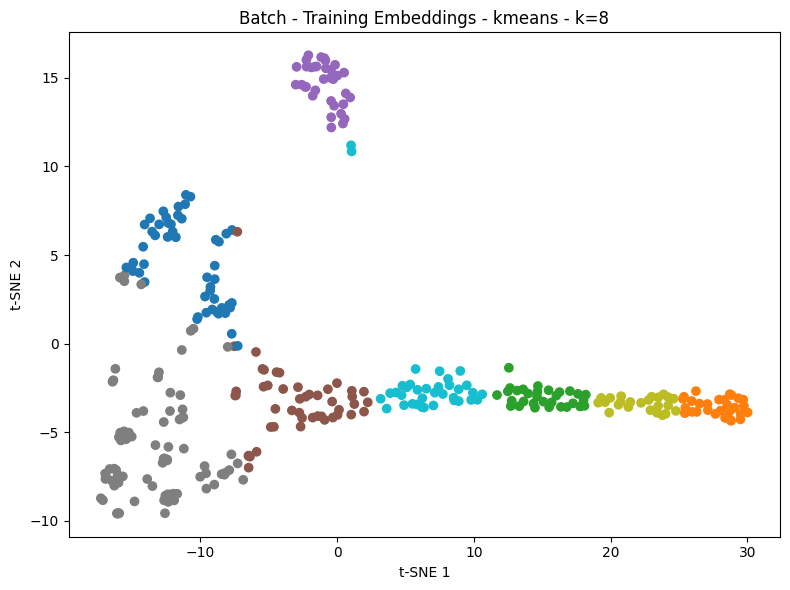

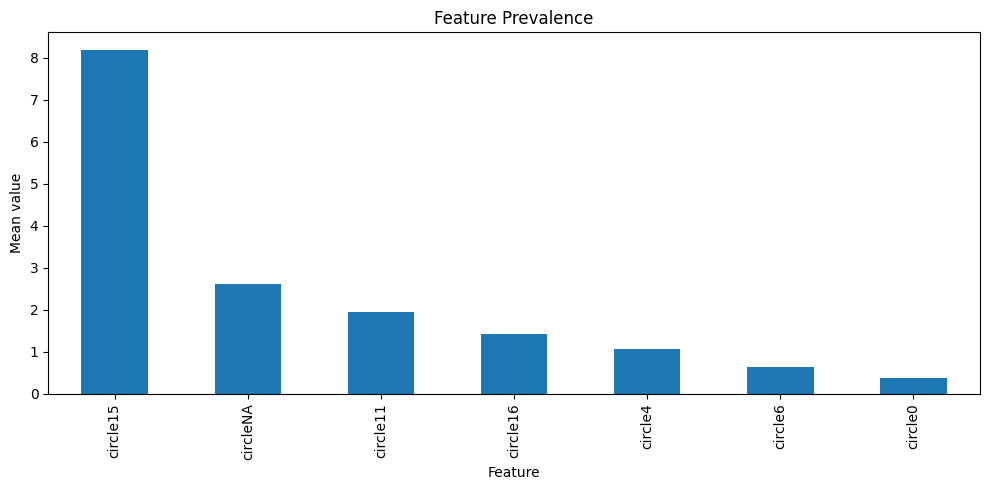


=== Cluster feature profiles ===
          circle15  circle16   circle11   circle0   circle6   circle4  \
cluster                                                                 
0         0.632653  0.081633   0.326531  0.040816  3.755102  0.020408   
1        36.379310  1.931034  10.241379  1.275862  0.000000  5.862069   
2        13.516129  0.612903   3.193548  0.580645  0.000000  1.935484   
3         4.941176  9.588235   0.205882  0.117647  0.000000  0.088235   
4         3.404255  0.063830   0.553191  0.553191  0.042553  0.191489   
5         0.506024  0.192771   0.048193  0.216867  0.361446  0.024096   
6        22.666667  0.916667   5.875000  0.583333  0.000000  3.250000   
7         8.583333  0.777778   1.583333  0.166667  0.000000  0.888889   

         circleNA  
cluster            
0        6.693878  
1        3.758621  
2        1.645161  
3        4.588235  
4        1.319149  
5        1.096386  
6        1.625000  
7        0.888889  


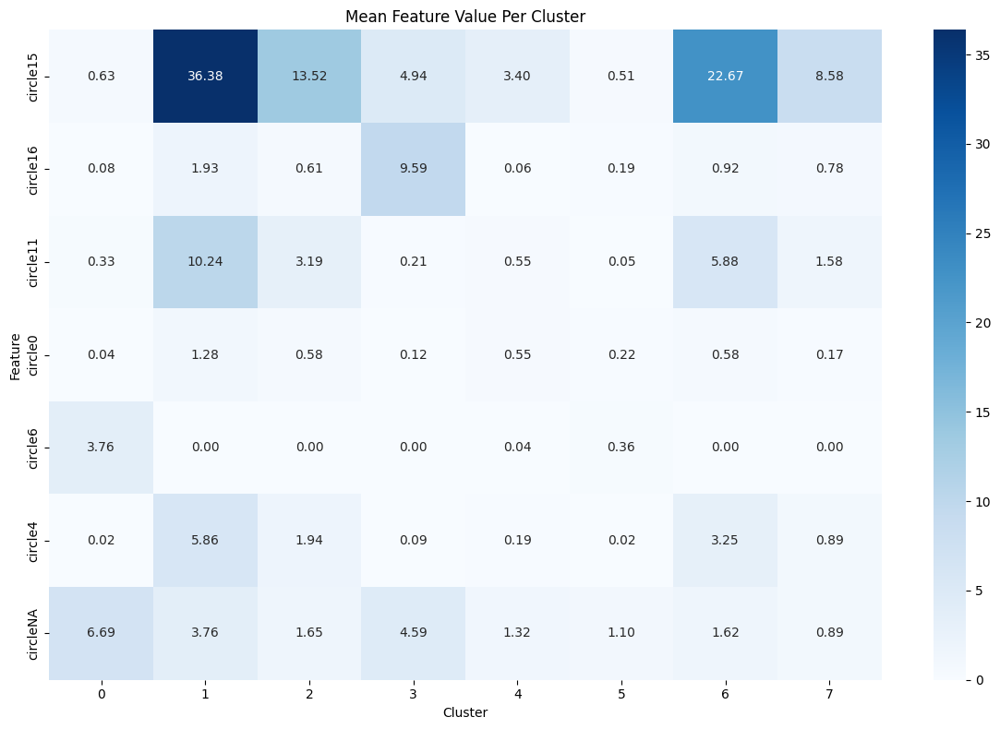

Features with > 30% prevalence/value in at least one cluster:
          circle15  circle16   circle11   circle0   circle6   circle4  \
cluster                                                                 
0         0.632653  0.081633   0.326531  0.040816  3.755102  0.020408   
1        36.379310  1.931034  10.241379  1.275862  0.000000  5.862069   
2        13.516129  0.612903   3.193548  0.580645  0.000000  1.935484   
3         4.941176  9.588235   0.205882  0.117647  0.000000  0.088235   
4         3.404255  0.063830   0.553191  0.553191  0.042553  0.191489   
5         0.506024  0.192771   0.048193  0.216867  0.361446  0.024096   
6        22.666667  0.916667   5.875000  0.583333  0.000000  3.250000   
7         8.583333  0.777778   1.583333  0.166667  0.000000  0.888889   

         circleNA  
cluster            
0        6.693878  
1        3.758621  
2        1.645161  
3        4.588235  
4        1.319149  
5        1.096386  
6        1.625000  
7        0.888889  

=== To

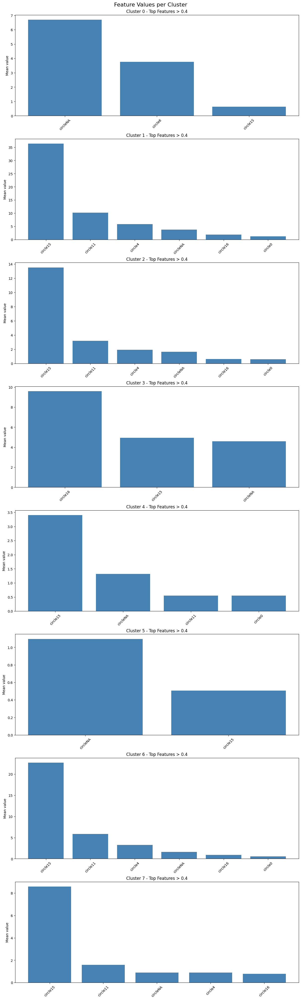


=== CLAMP prototypes ===
    cluster   feature  cluster_prevalence  global_prevalence  prevalence_diff  \
0         0  circle15            0.632653           8.192192        -7.559539   
1         0  circleNA            6.693878           2.606607         4.087271   
2         0   circle6            3.755102           0.648649         3.106453   
3         0  circle11            0.326531           1.942943        -1.616412   
4         0  circle16            0.081633           1.423423        -1.341791   
5         0   circle4            0.020408           1.066066        -1.045658   
6         0   circle0            0.040816           0.375375        -0.334559   
7         1  circle15           36.379310           8.192192        28.187118   
8         1  circle11           10.241379           1.942943         8.298436   
9         1   circle4            5.862069           1.066066         4.796003   
10        1  circleNA            3.758621           2.606607         1.152014   
11

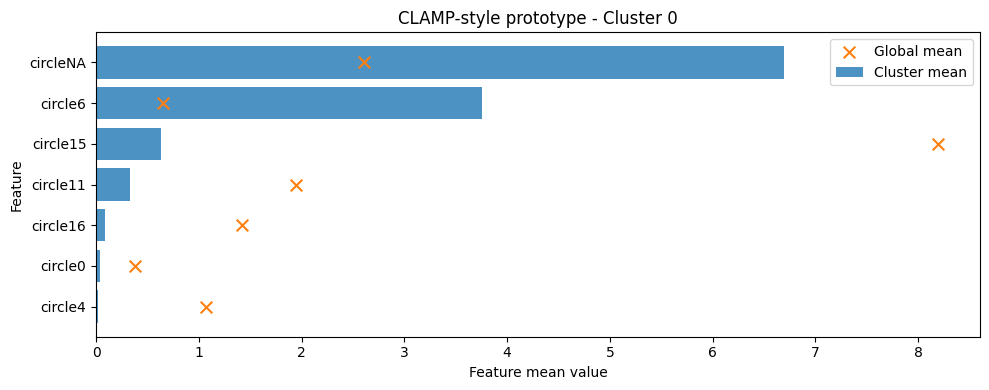

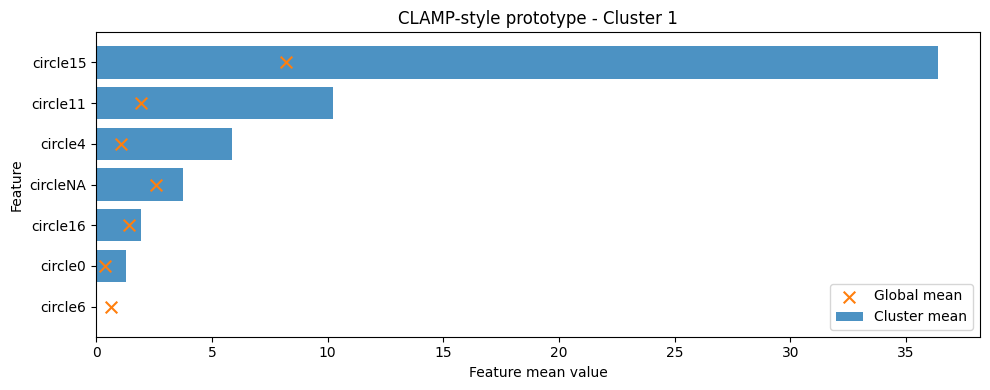

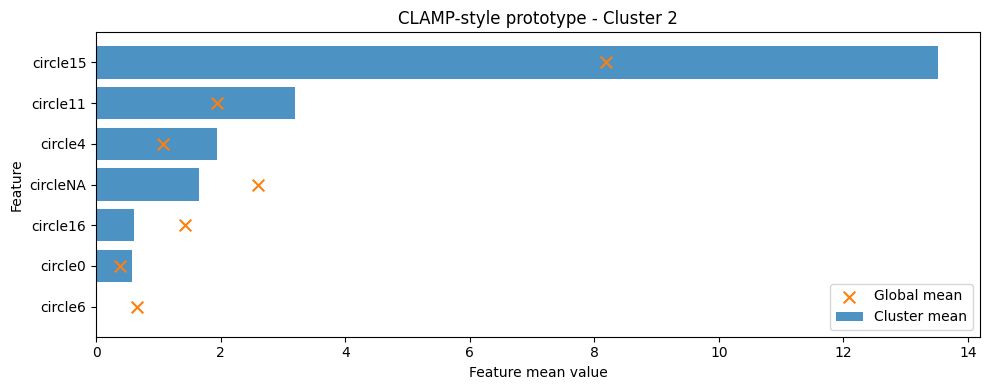

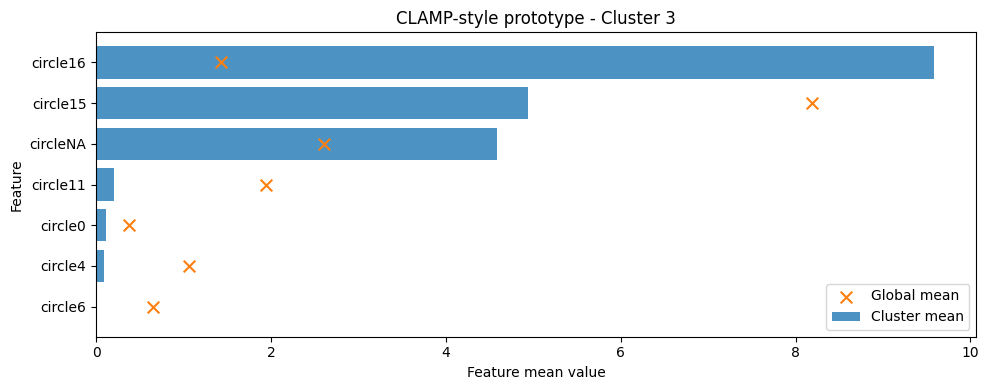

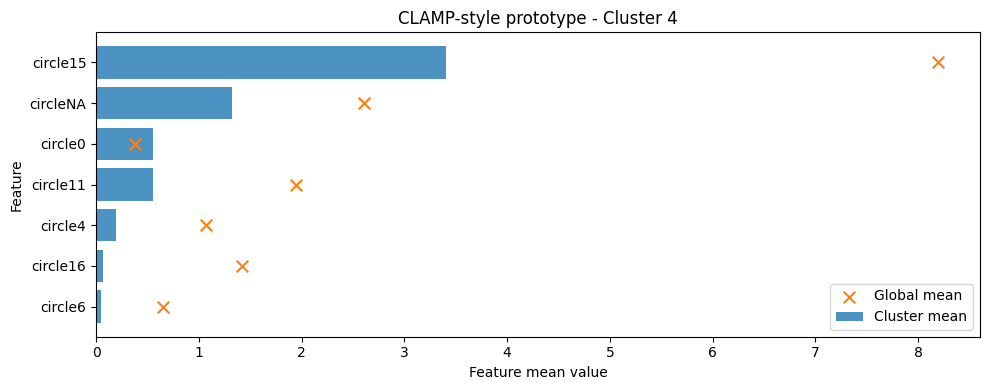

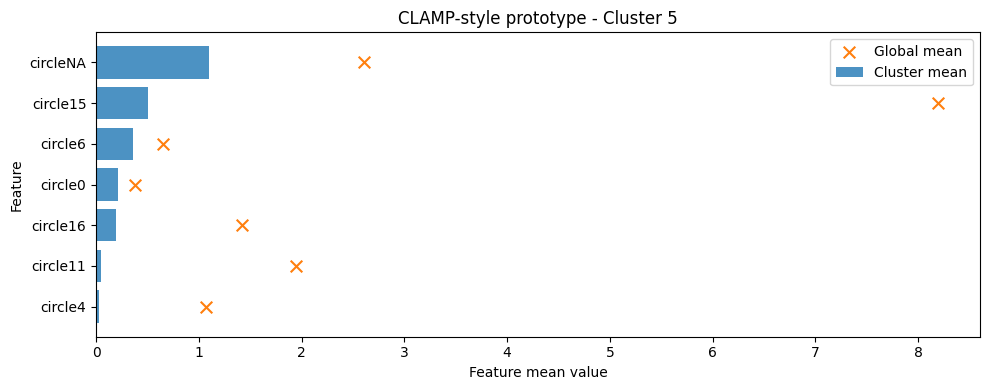

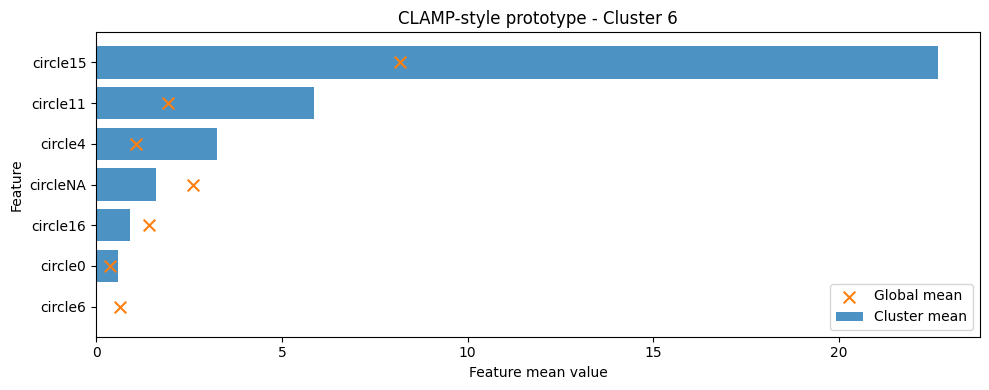

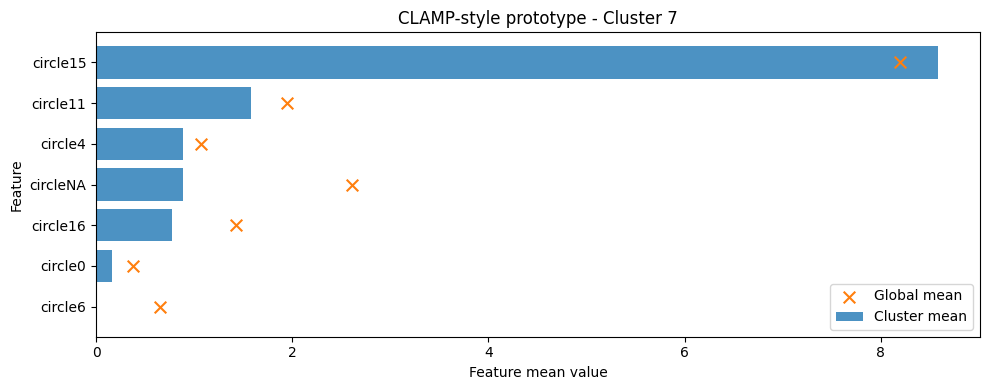

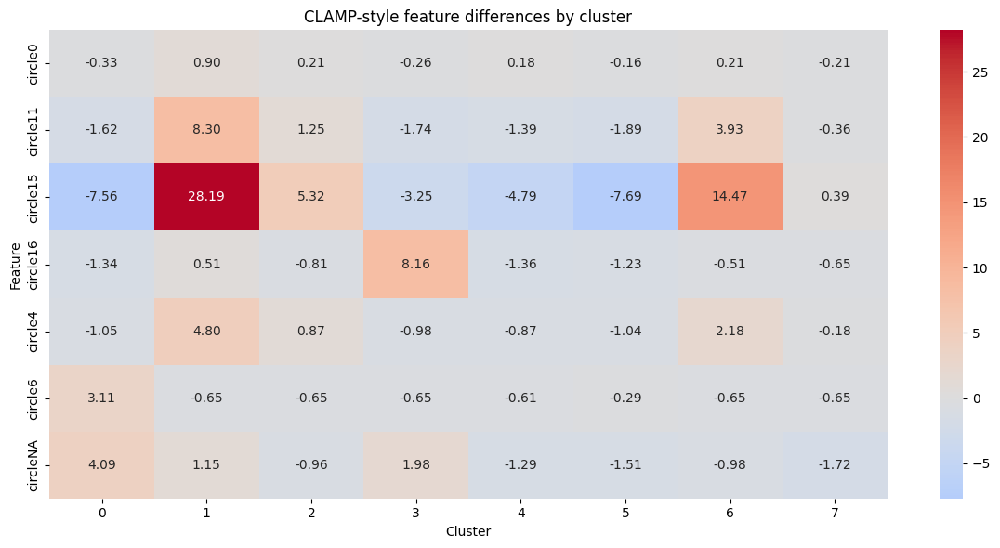


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.783784                         0.765732          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10        11           4  

=== Decision tree rules ===
|--- circle16 <= 4.50
|   |--- circle15 <= 5.50
|   |   |--- circleNA <= 3.50
|   |   |   |--- circle15 <= 1.50
|   |   |   |   |--- class: 5
|   |   |   |--- circle15 >  1.50
|   |   |   |   |--- class: 4
|   |   |--- circleNA >  3.50
|   |   |   |--- circleNA <= 5.50
|   |   |   |   |--- class: 0
|   |   |   |--- circleNA >  5.50
|   |   |   |   |--- class: 0
|   |--- circle15 >  5.50
|   |   |--- circle15 <= 16.50
|   |   |   |--- circle4 <= 1.50
|   |   |   |   |--- class: 7
|   |   |   |--- circle4 >  1.50
|   |   |   |   |--- class: 2
|   |   |--- circle15 >  16.50
|   |   |   |--- circle4 <= 5.50
|   |   |   |   |--- class: 6
|   |   |   |--- circle4 >  5.50
|   |   |   |   |--- c

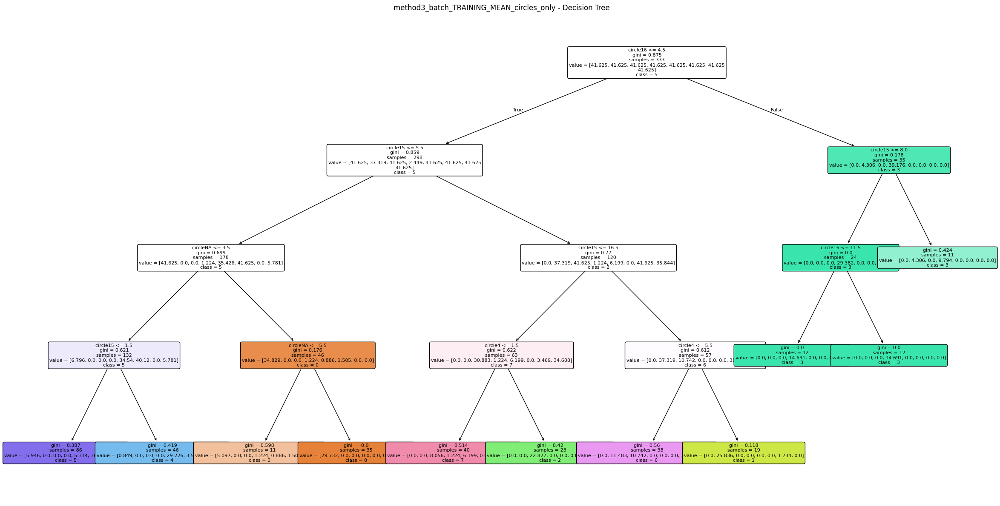


=== Decision tree feature importance ===
circle15    0.470009
circle16    0.202477
circleNA    0.165299
circle4     0.162215
dtype: float64


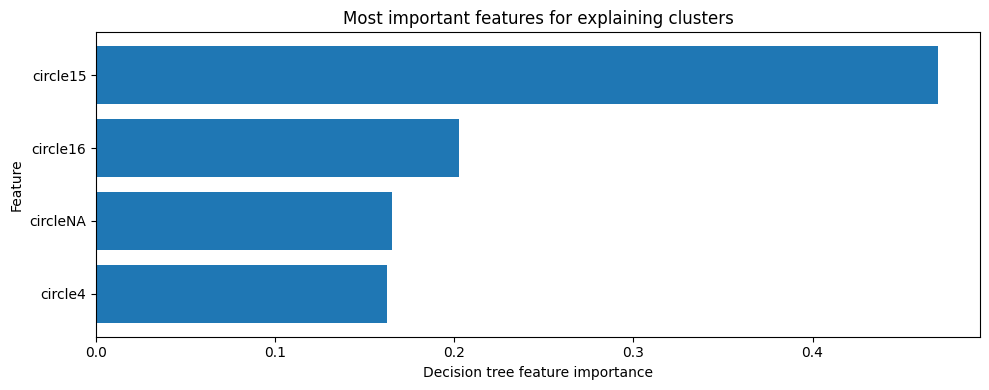


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.061224  0.000000  0.020408  0.000000  0.265306  0.000000  0.653061   
1        0.758621  0.000000  0.103448  0.000000  0.000000  0.034483  0.034483   
2        0.483871  0.000000  0.225806  0.032258  0.000000  0.096774  0.064516   
3        0.088235  0.441176  0.000000  0.000000  0.000000  0.000000  0.235294   
4        0.468085  0.000000  0.042553  0.042553  0.000000  0.021277  0.382979   
5        0.192771  0.048193  0.048193  0.108434  0.072289  0.000000  0.506024   
6        0.541667  0.000000  0.333333  0.000000  0.000000  0.000000  0.041667   
7        0.555556  0.055556  0.027778  0.083333  0.000000  0.138889  0.083333   

         circleOverlap  
cluster                 
0             0.000000  
1             0.068966  
2             0.096774  
3             0.235294  


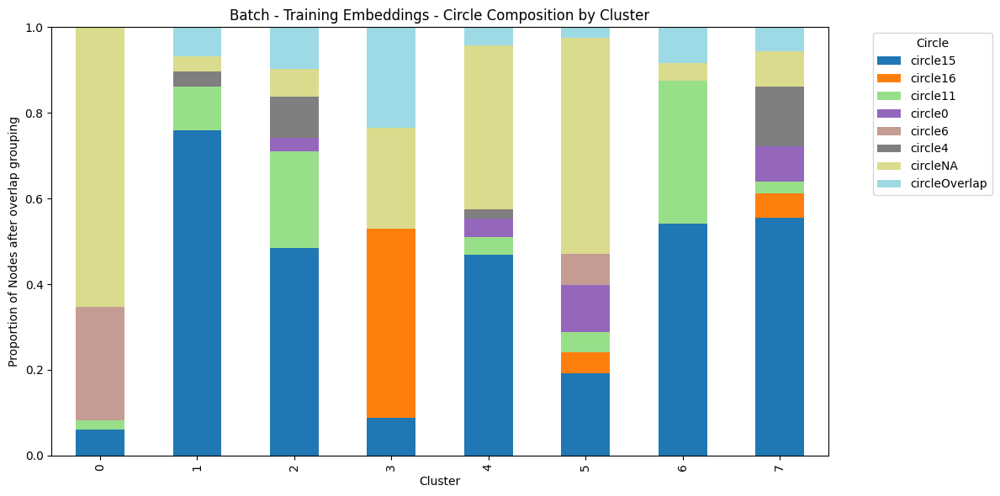

In [41]:
# ============================================================
# TRAINING-TIME MODEL 3B - Batch with circles-only ARD
# ============================================================

diagnostics_method3_training_circles, result_method3_training_circles = (
    run_final_dataset_analysis(
        dataset_name="method3_batch_TRAINING_MEAN_circles_only",
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)


Dataset loaded: method3_batch_TRAINING_MEAN_graph_structure_identity_only
Embeddings shape: (333, 64)
Features shape: (333, 224)
Membership shape: (333, 8)

Running diagnostics for: method3_batch_TRAINING_MEAN_graph_structure_identity_only

=== method3_batch_TRAINING_MEAN_graph_structure_identity_only | KMEANS diagnostics ===
    silhouette  calinski_harabasz  davies_bouldin  n_clusters_found  \
0     0.212134          52.671538        1.900939                 2   
3     0.240812          45.527938        2.221502                 3   
6     0.250548          39.751500        2.281461                 4   
9     0.253983          34.754749        1.944327                 5   
12    0.262106          32.331404        2.243666                 6   
15    0.265920          29.328527        1.897614                 7   
18    0.269485          25.848589        2.326684                 8   

    valid_internal_metrics  method  k fit_status  \
0                     True  kmeans  2         ok   

C:\Users\Giuliana Galassi\AppData\Local\Temp\ipykernel_25992\2694104166.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cluster_counts.index, y=cluster_counts.values, palette="Paired")


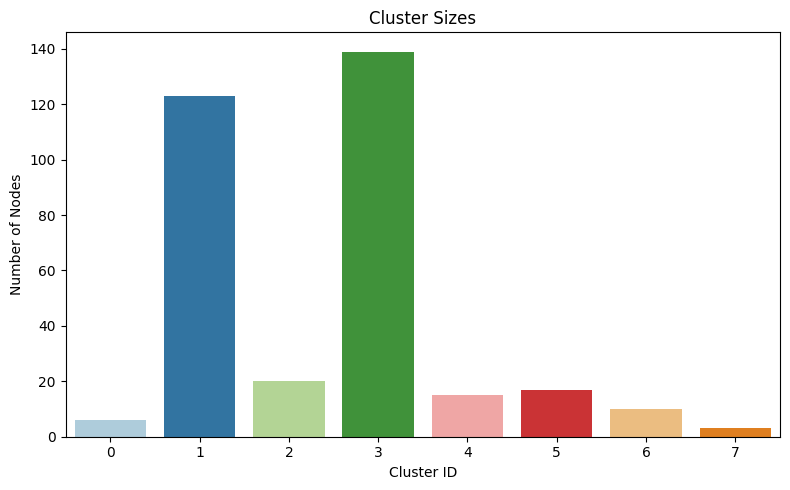


=== KMeans centroids ===
         embedding_dim_0  embedding_dim_1  embedding_dim_2  embedding_dim_3  \
cluster                                                                       
0               0.052268         0.020341         0.034894         0.003858   
1               0.011456         0.016050         0.014945         0.022363   
2               0.033986         0.018363         0.031037         0.011834   
3               0.041100         0.036923         0.008538         0.027845   
4               0.074372         0.022048         0.035414         0.004518   
5               0.057971         0.046280         0.026359         0.060757   
6               0.082853         0.031136         0.038246         0.006904   
7               0.006384         0.130597         0.031233         0.004519   

         embedding_dim_4  embedding_dim_5  embedding_dim_6  embedding_dim_7  \
cluster                                                                       
0               0.032901 

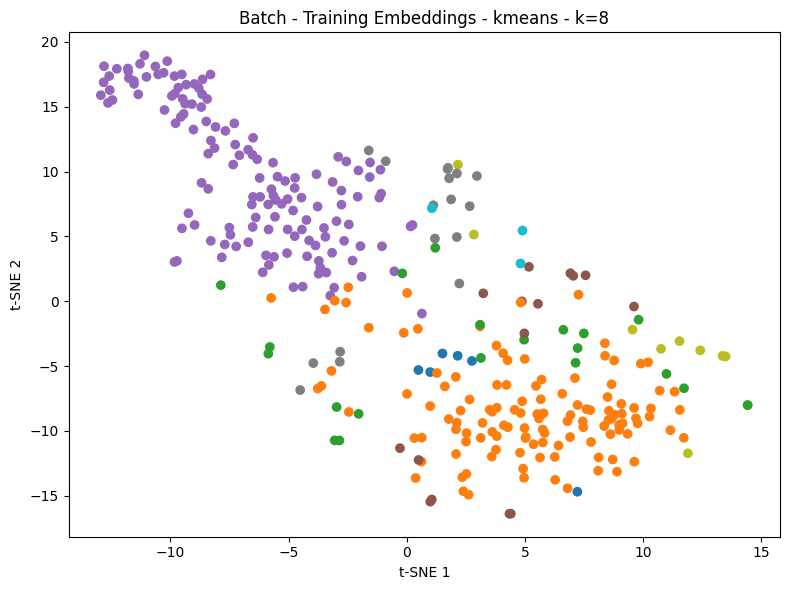

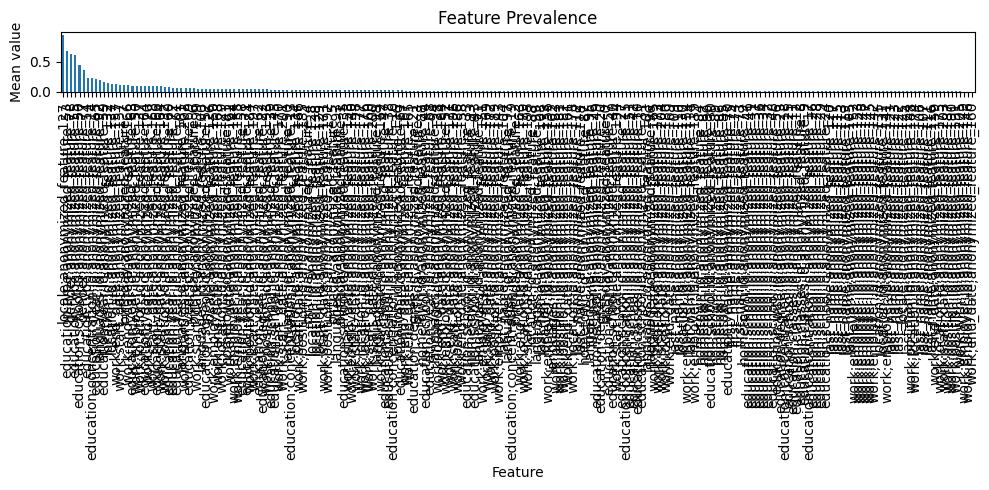


=== Cluster feature profiles ===
         birthday;anonymized_feature_0  birthday;anonymized_feature_1  \
cluster                                                                 
0                             0.000000                       0.000000   
1                             0.024390                       0.048780   
2                             0.000000                       0.000000   
3                             0.007194                       0.007194   
4                             0.000000                       0.066667   
5                             0.000000                       0.000000   
6                             0.000000                       0.000000   
7                             0.000000                       0.000000   

         birthday;anonymized_feature_2  birthday;anonymized_feature_3  \
cluster                                                                 
0                             0.166667                       0.000000   
1               

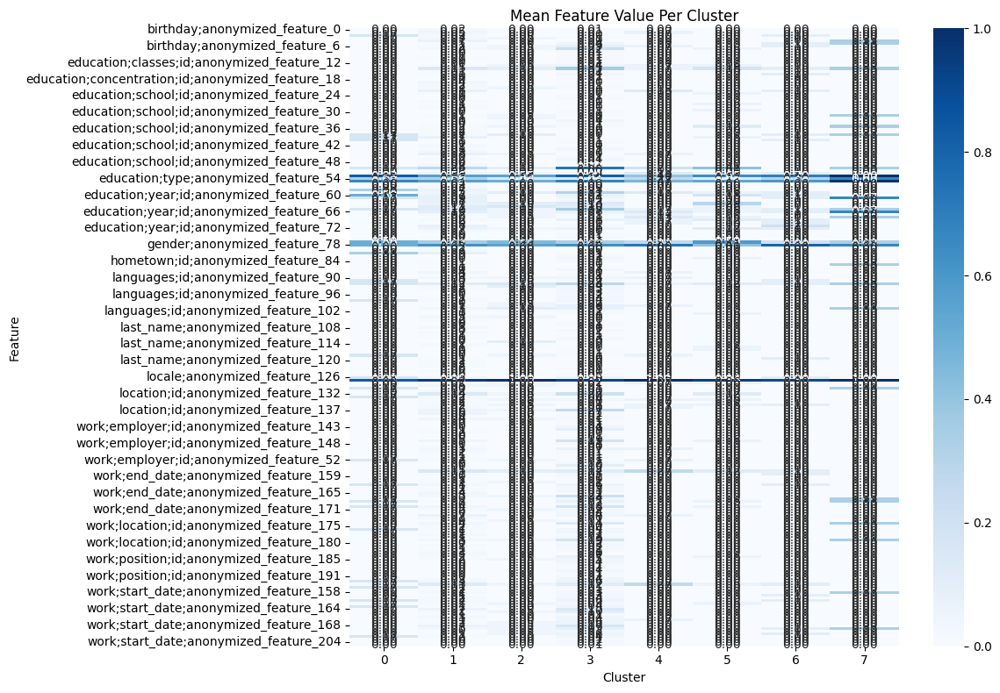

Features with > 30% prevalence/value in at least one cluster:
         birthday;anonymized_feature_4  birthday;anonymized_feature_5  \
cluster                                                                 
0                             0.000000                       0.000000   
1                             0.073171                       0.008130   
2                             0.000000                       0.000000   
3                             0.000000                       0.043165   
4                             0.000000                       0.000000   
5                             0.000000                       0.000000   
6                             0.000000                       0.100000   
7                             0.333333                       0.333333   

         education;concentration;id;anonymized_feature_14  \
cluster                                                     
0                                                0.000000   
1                       

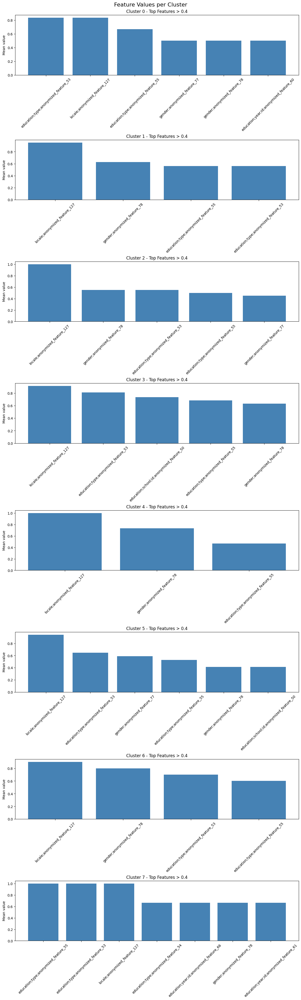


=== CLAMP prototypes ===
    cluster                                           feature  \
0         0           education;year;id;anonymized_feature_60   
1         0           education;year;id;anonymized_feature_58   
2         0                 hometown;id;anonymized_feature_81   
3         0         education;school;id;anonymized_feature_50   
4         0  education;concentration;id;anonymized_feature_14   
5         0           education;year;id;anonymized_feature_59   
6         0              education;type;anonymized_feature_53   
7         0                location;id;anonymized_feature_130   
8         0            work;start_date;anonymized_feature_194   
9         0                location;id;anonymized_feature_133   
10        0                  last_name;anonymized_feature_118   
11        0         education;school;id;anonymized_feature_40   
12        0                languages;id;anonymized_feature_91   
13        0                     birthday;anonymized_feature_2   

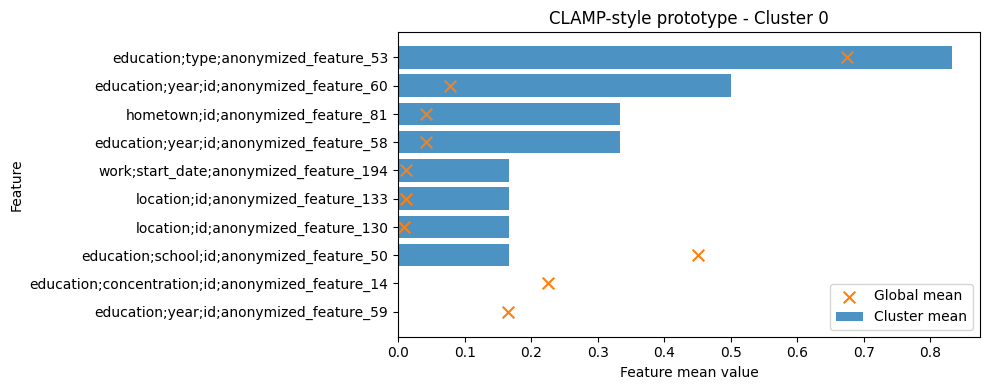

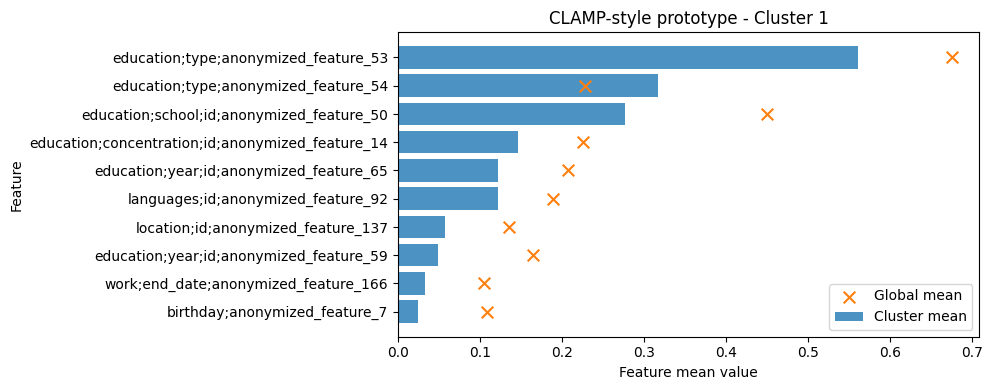

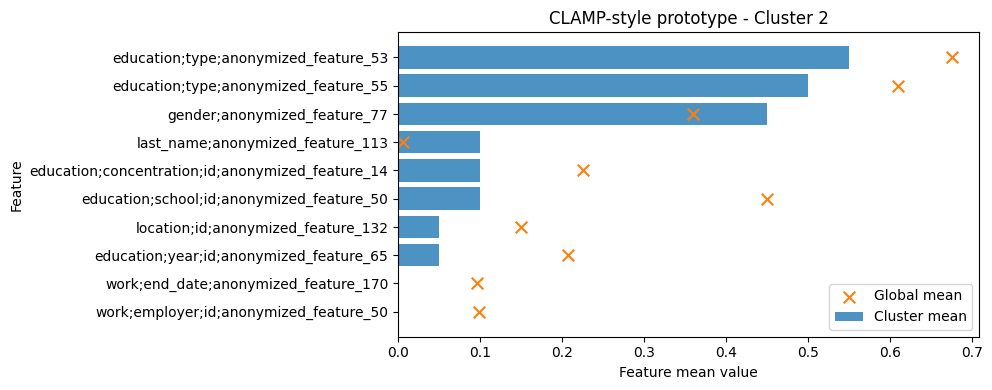

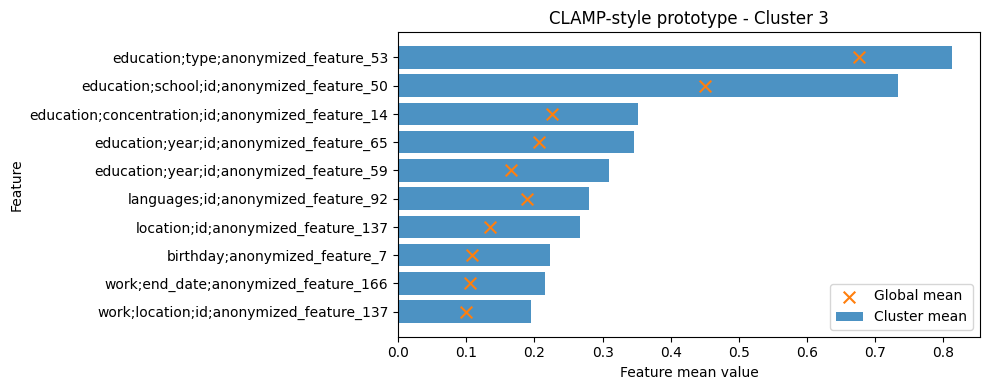

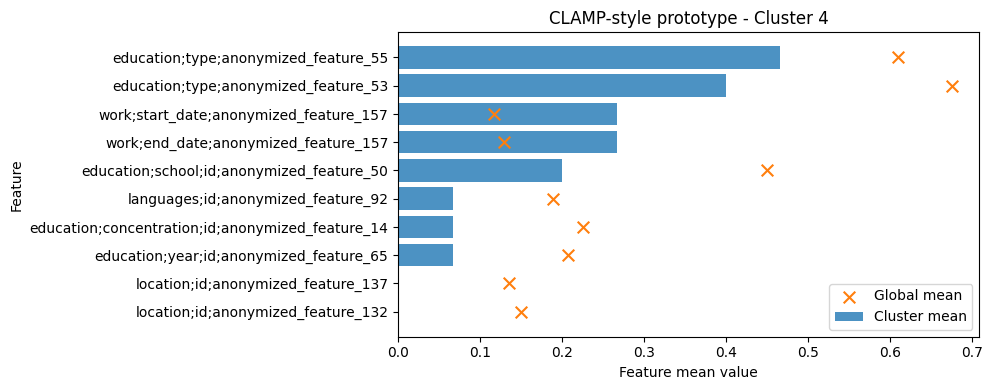

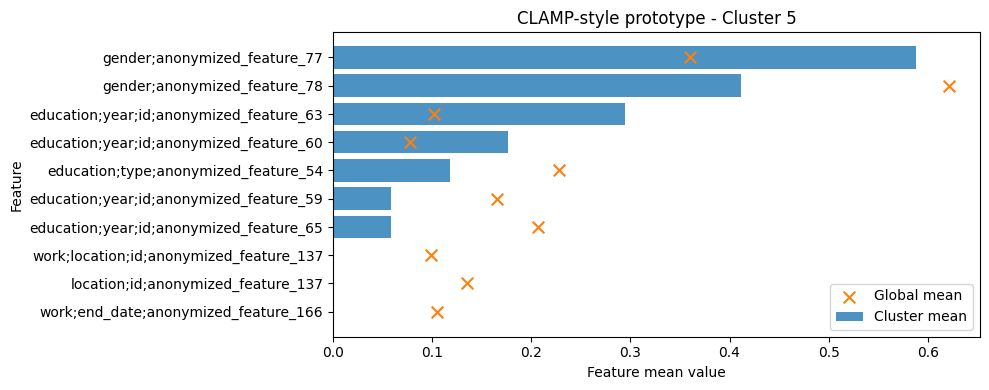

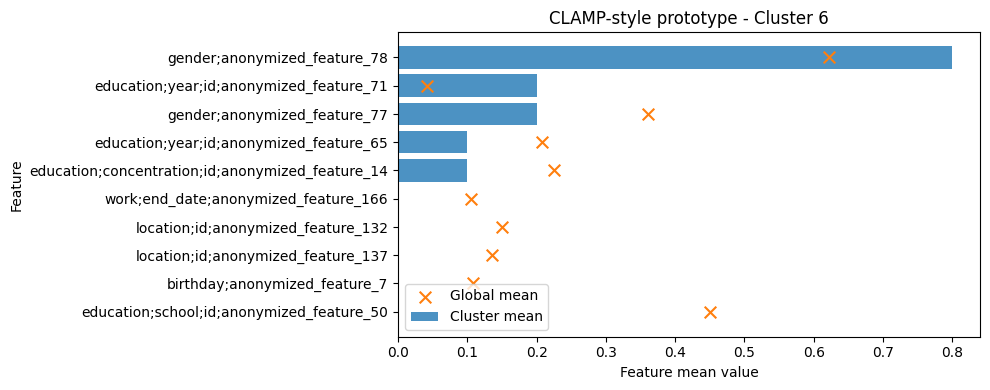

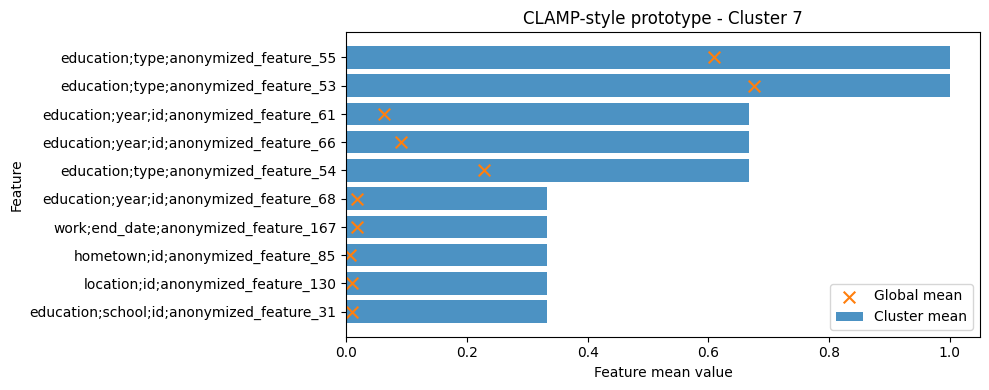

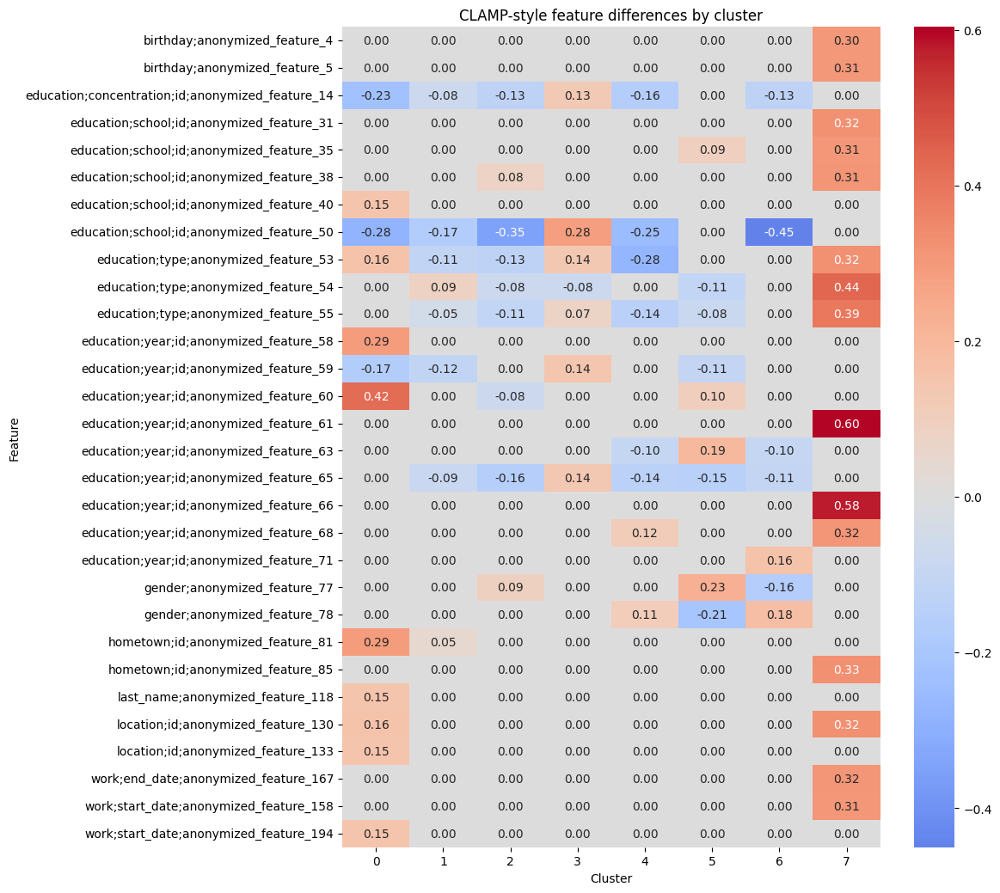


=== Decision tree fidelity metrics ===
   tree_fidelity_accuracy  tree_fidelity_balanced_accuracy  max_depth  \
0                0.351351                         0.388614          4   

   min_samples_leaf  n_leaves  tree_depth  
0                10         9           4  

=== Decision tree rules ===
|--- education;year;id;anonymized_feature_61 <= 0.50
|   |--- education;school;id;anonymized_feature_50 <= 0.50
|   |   |--- hometown;id;anonymized_feature_81 <= 0.50
|   |   |   |--- education;year;id;anonymized_feature_60 <= 0.50
|   |   |   |   |--- class: 2
|   |   |   |--- education;year;id;anonymized_feature_60 >  0.50
|   |   |   |   |--- class: 0
|   |   |--- hometown;id;anonymized_feature_81 >  0.50
|   |   |   |--- class: 0
|   |--- education;school;id;anonymized_feature_50 >  0.50
|   |   |--- birthday;anonymized_feature_7 <= 0.50
|   |   |   |--- education;year;id;anonymized_feature_63 <= 0.50
|   |   |   |   |--- class: 3
|   |   |   |--- education;year;id;anonymized_feature

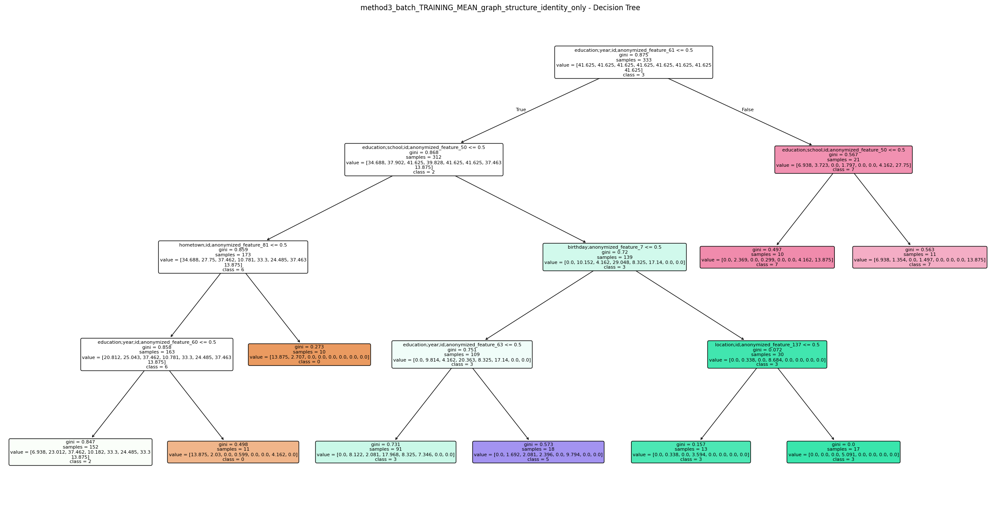


=== Decision tree feature importance ===
education;year;id;anonymized_feature_61      0.279344
education;school;id;anonymized_feature_50    0.240236
hometown;id;anonymized_feature_81            0.178583
education;year;id;anonymized_feature_60      0.165122
birthday;anonymized_feature_7                0.070718
education;year;id;anonymized_feature_63      0.065415
location;id;anonymized_feature_137           0.000582
dtype: float64


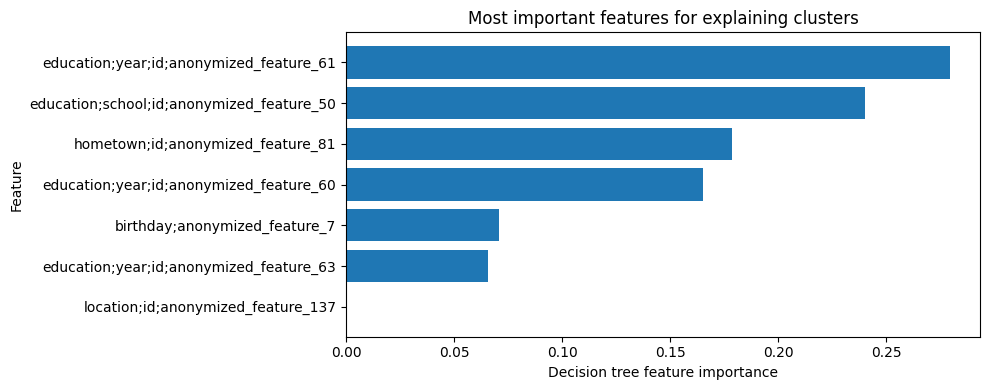


=== Circle proportions by cluster ===
         circle15  circle16  circle11   circle0   circle6   circle4  circleNA  \
cluster                                                                         
0        0.000000  0.000000  0.000000  0.166667  0.000000  0.000000  0.833333   
1        0.130081  0.138211  0.024390  0.040650  0.113821  0.008130  0.471545   
2        0.400000  0.000000  0.050000  0.100000  0.050000  0.000000  0.350000   
3        0.568345  0.014388  0.143885  0.035971  0.007194  0.064748  0.100719   
4        0.133333  0.000000  0.066667  0.000000  0.066667  0.000000  0.666667   
5        0.411765  0.000000  0.000000  0.117647  0.058824  0.000000  0.352941   
6        0.000000  0.200000  0.100000  0.000000  0.100000  0.000000  0.600000   
7        0.666667  0.000000  0.000000  0.000000  0.000000  0.000000  0.333333   

         circleOverlap  
cluster                 
0             0.000000  
1             0.073171  
2             0.050000  
3             0.064748  


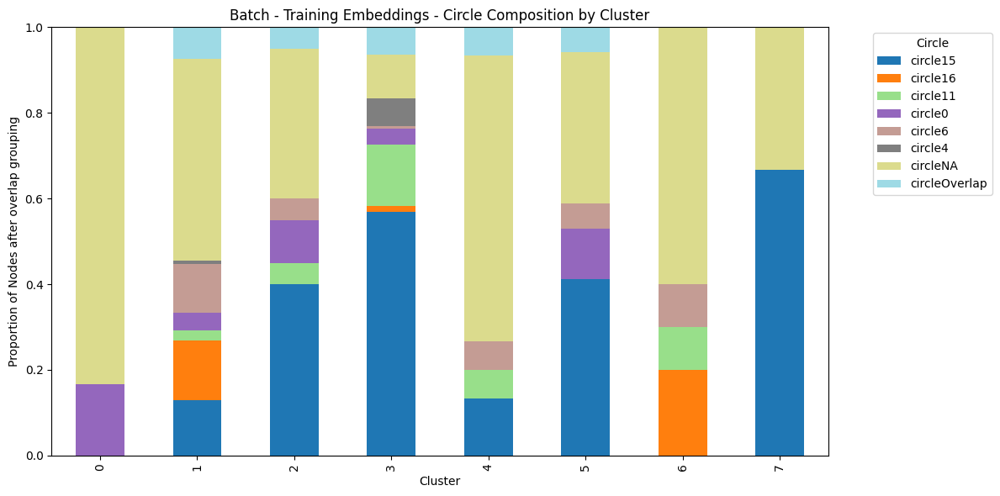

In [42]:
# ============================================================
# TRAINING-TIME MODEL 3C - Batch with structure only
# ============================================================

diagnostics_method3_training_structure, result_method3_training_structure = (
    run_final_dataset_analysis(
        dataset_name=(
            "method3_batch_TRAINING_MEAN_"
            "graph_structure_identity_only"
        ),
        n_clusters=K_CIRCLES_AND_STRUCTURE,
        final_method=final_method,
        random_state=random_state
    )
)


In [43]:
# ============================================================
# FINAL COMPARISON
# Post-training vs training-time embeddings
# ============================================================

comparison_pairs = [
    (
        "Original Graph",
        "all_features",
        result_original_all,
        result_original_training_all
    ),
    (
        "Original Graph",
        "circles_only",
        result_original_circles,
        result_original_training_circles
    ),
    (
        "Original Graph",
        "graph_structure_identity_only",
        result_original_structure,
        result_original_training_structure
    ),
    (
        "One Encoder",
        "all_features",
        result_method2_all,
        result_method2_training_all
    ),
    (
        "One Encoder",
        "circles_only",
        result_method2_circles,
        result_method2_training_circles
    ),
    (
        "One Encoder",
        "graph_structure_identity_only",
        result_method2_structure,
        result_method2_training_structure
    ),
    (
        "Batch",
        "all_features",
        result_method3_all,
        result_method3_training_all
    ),
    (
        "Batch",
        "circles_only",
        result_method3_circles,
        result_method3_training_circles
    ),
    (
        "Batch",
        "graph_structure_identity_only",
        result_method3_structure,
        result_method3_training_structure
    ),
]

comparison_rows = []

for model_name, feature_set, post_result, training_result in comparison_pairs:
    post_metrics = post_result["results"][final_method]["metrics"]
    training_metrics = training_result["results"][final_method]["metrics"]

    comparison_rows.append({
        "model": model_name,
        "feature_set": feature_set,
        "embedding_source": "post_training_reencoded",
        "silhouette": post_metrics["silhouette"],
        "calinski_harabasz": post_metrics["calinski_harabasz"],
        "davies_bouldin": post_metrics["davies_bouldin"],
        "n_clusters": post_metrics["n_clusters"],
        "fit_status": post_metrics["fit_status"],
    })

    comparison_rows.append({
        "model": model_name,
        "feature_set": feature_set,
        "embedding_source": "training_time",
        "silhouette": training_metrics["silhouette"],
        "calinski_harabasz": training_metrics["calinski_harabasz"],
        "davies_bouldin": training_metrics["davies_bouldin"],
        "n_clusters": training_metrics["n_clusters"],
        "fit_status": training_metrics["fit_status"],
    })

training_vs_post_comparison = pd.DataFrame(comparison_rows)

print("\n" + "=" * 90)
print("POST-TRAINING VS TRAINING-TIME EMBEDDING COMPARISON")
print("=" * 90)
print(training_vs_post_comparison)

training_vs_post_comparison.to_csv(
    os.path.join(
        output_folder,
        "training_vs_post_training_clustering_comparison.csv"
    ),
    index=False
)

print(
    "\nSaved comparison table to:",
    os.path.join(
        output_folder,
        "training_vs_post_training_clustering_comparison.csv"
    )
)



POST-TRAINING VS TRAINING-TIME EMBEDDING COMPARISON
             model                    feature_set         embedding_source  \
0   Original Graph                   all_features  post_training_reencoded   
1   Original Graph                   all_features            training_time   
2   Original Graph                   circles_only  post_training_reencoded   
3   Original Graph                   circles_only            training_time   
4   Original Graph  graph_structure_identity_only  post_training_reencoded   
5   Original Graph  graph_structure_identity_only            training_time   
6      One Encoder                   all_features  post_training_reencoded   
7      One Encoder                   all_features            training_time   
8      One Encoder                   circles_only  post_training_reencoded   
9      One Encoder                   circles_only            training_time   
10     One Encoder  graph_structure_identity_only  post_training_reencoded   
11     One 